In [1]:
import pandas as pd
from io import StringIO

# Keeps your pasted data if you rerun this cell
drafts_text = globals().get("drafts_text", {})

def clean_draft(year, text):
    d = pd.read_csv(StringIO(text.strip()), header=1)
    d = d.rename(columns={"Overall": "pick", "-9999": "player_id", "T/O": "OTL/SOL"})
    d["pick"] = pd.to_numeric(d["pick"], errors="coerce")
    d = d.dropna(subset=["pick"])
    d = d.copy()
    for col in ["GP", "G", "A", "PTS", "+/-", "PIM", "W", "L", "OTL/SOL", "SV%", "GAA", "To"]:
        d[col] = pd.to_numeric(d[col], errors="coerce")
    d["GP"] = d["GP"].fillna(0).astype(int)
    d["draft_year"] = year
    d["made_nhl"] = d["GP"] >= 200
    d["NHL player"] = d["made_nhl"].map({True: "Yes", False: "No"})
    d["last season"] = d["To"].apply(
        lambda x: "Present" if x >= 2027 else (str(int(x)) if pd.notna(x) else "-")
    )
    return d

In [2]:
drafts_text[2004] = """
,Round 1,Round 1,,,,,,NHL Scoring Stats,NHL Scoring Stats,NHL Scoring Stats,NHL Scoring Stats,NHL Scoring Stats,NHL Scoring Stats,NHL Goalie Stats,NHL Goalie Stats,NHL Goalie Stats,NHL Goalie Stats,NHL Goalie Stats,NHL Goalie Stats,,Round 1-additional
Overall,Team,Player,Nat.,Pos,Age,To,Amateur Team,GP,G,A,PTS,+/-,PIM,GP,W,L,T/O,SV%,GAA,PS,-9999
1,Washington Capitals,Alex Ovechkin,RU,LW,18,2027,Dynamo Moskva (Russia),1585,930,761,1691,56,857,,,,,,,223.2,ovechal01
2,Pittsburgh Penguins,Evgeni Malkin,RU,C,18,2027,Metallurg Magnitogorsk (Russia),1282,539,879,1418,42,1269,,,,,,,164.5,malkiev01
3,Chicago Blackhawks,Cam Barker,CA,D,18,2013,Medicine Hat Tigers (WHL),310,21,75,96,-29,290,,,,,,,16.3,barkeca01
4,Carolina Hurricanes,Andrew Ladd,CA,LW,18,2022,Calgary Hitmen (WHL),1001,256,294,550,20,615,,,,,,,60.7,laddan01
5,Phoenix Coyotes,Blake Wheeler,US,RW,18,2024,Breck School (High-MN),1172,321,622,943,67,764,,,,,,,101.3,wheelbl01
6,New York Rangers,Al Montoya,US,G,19,2018,Michigan (CCHA),168,0,5,5,0,12,168,67,49,24,.908,2.65,23.7,montoal01
7,Florida Panthers,Rostislav Olesz,CZ,LW,18,2014,HC Vitkovice (Czech),365,57,77,134,-11,118,,,,,,,10.5,oleszro01
8,Columbus Blue Jackets,Alexandre Picard,CA,LW,18,2010,Lewiston MAINEiacs (QMJHL),67,0,2,2,-9,58,,,,,,,-1.0,picaral02
9,Anaheim Ducks,Ladislav Smid,CZ,D,18,2016,Bili Tygri Liberec (Czech),583,12,60,72,-68,472,,,,,,,17.0,smidla01
10,Atlanta Thrashers,Boris Valabik,SK,D,18,2010,Kitchener Rangers (OHL),80,0,7,7,-14,210,,,,,,,0.3,valabbo01
11,Los Angeles Kings,Lauri Tukonen,FI,RW,18,2008,Blues (Finland),5,0,0,0,-2,0,,,,,,,-0.1,tukonla01
12,Minnesota Wild,A.J. Thelen,US,D,18,,Michigan State (CCHA),,,,,,,,,,,,,,thelea.01
13,Buffalo Sabres,Drew Stafford,US,RW,18,2019,North Dakota (WCHA),841,196,232,428,-58,415,,,,,,,44.6,staffdr01
14,Edmonton Oilers,Devan Dubnyk,CA,G,18,2021,Kamloops Blazers (WHL),542,0,8,8,0,46,542,253,206,54,.914,2.61,93.8,dubnyde01
15,Nashville Predators,Alexander Radulov,RU,RW,18,2022,THK Tver (Russia-2),524,144,224,368,62,344,,,,,,,42.3,radulal01
16,New York Islanders,Petteri Nokelainen,FI,C,18,2012,SaiPa (Finland),245,20,21,41,-14,103,,,,,,,1.9,nokelpe01
17,St. Louis Blues,Marek Schwarz,CZ,G,18,2009,HC Sparta Praha (Czech),6,0,0,0,0,0,6,0,2,0,.809,4.32,-0.3,schwama01
18,Montreal Canadiens,Kyle Chipchura,CA,C,18,2016,Prince Albert Raiders (WHL),482,31,73,104,-45,376,,,,,,,4.8,chipcky01
19,New York Rangers,Lauri Korpikoski,FI,LW,18,2017,TPS Jr. (Finland Jr.),609,86,115,201,-49,132,,,,,,,15.7,korpila01
20,New Jersey Devils,Travis Zajac,CA,C,19,2021,Salmon Arm (BCHL),1037,203,349,552,-20,344,,,,,,,54.3,zajactr01
21,Colorado Avalanche,Wojtek Wolski,PL,LW,18,2013,Brampton Battalion (OHL),451,99,168,267,17,113,,,,,,,27.4,wolskwo01
22,San Jose Sharks,Lukas Kaspar,CZ,RW,18,2009,HC Chemopetrol (Czech),16,2,2,4,-2,8,,,,,,,0.3,kaspalu01
23,Ottawa Senators,Andrej Meszaros,SK,D,18,2015,HK Dukla Trencin (Slovakia),645,63,175,238,25,457,,,,,,,44.5,meszaan01
24,Calgary Flames,Kris Chucko,CA,LW,18,2009,Salmon Arm (BCHL),2,0,0,0,0,2,,,,,,,0.0,chuckkr01
25,Edmonton Oilers,Rob Schremp,US,C,18,2011,London Knights (OHL),114,20,34,54,-23,26,,,,,,,4.5,schrero01
26,Vancouver Canucks,Cory Schneider,US,G,18,2022,Phillips Andover Academy (High-MA),410,0,9,9,0,4,410,171,159,58,.918,2.43,74.9,schneco01
27,Washington Capitals,Jeff Schultz,CA,D,18,2016,Calgary Hitmen (WHL),409,11,65,76,78,137,,,,,,,21.4,schulje02
28,Dallas Stars,Mark Fistric,CA,D,18,2015,Vancouver Giants (WHL),325,4,30,34,28,284,,,,,,,11.2,fistrma01
29,Washington Capitals,Mike Green,CA,D,18,2020,Saskatoon Blades (WHL),880,150,351,501,-17,592,,,,,,,87.8,greenmi03
30,Tampa Bay Lightning,Andy Rogers,CA,D,18,,Calgary Hitmen (WHL),,,,,,,,,,,,,,rogeran01
31,Pittsburgh Penguins,Johannes Salmonsson,SE,LW,18,,Djurgardens IF (Sweden),,,,,,,,,,,,,,salmojo01
32,Chicago Blackhawks,Dave Bolland,CA,C,18,2016,London Knights (OHL),433,85,123,208,34,299,,,,,,,21.1,bollada01
33,Washington Capitals,Chris Bourque,US,C,18,2013,Cushing Academy (High-MA),51,2,6,8,-12,18,,,,,,,-0.3,bourqch01
34,Dallas Stars,Johan Fransson,SE,D,19,,Lulea HF (Sweden),,,,,,,,,,,,,,fransjo01
35,Phoenix Coyotes,Logan Stephenson,CA,D,18,,Tri-City Americans (WHL),,,,,,,,,,,,,,stephlo01
36,New York Rangers,Darin Olver,CA,C,19,,Northern Michigan (CCHA),,,,,,,,,,,,,,olverda01
37,Florida Panthers,David Shantz,CA,G,18,,Mississagua IceDogs (OHL),,,,,,,,,,,,,,shantda01
38,Carolina Hurricanes,Justin Peters,CA,G,18,2017,Toronto St. Michael's Majors (OHL),83,0,2,2,0,8,83,25,38,9,.901,3.08,10.6,peterju01
39,Anaheim Ducks,Jordan Smith,CA,D,18,,Soo Greyhounds (OHL),,,,,,,,,,,,,,smithjo01
40,Atlanta Thrashers,Grant Lewis,US,D,19,2009,Dartmouth (ECAC),1,0,0,0,0,0,,,,,,,0.0,lewisgr01
41,Chicago Blackhawks,Bryan Bickell,CA,LW,18,2017,Ottawa 67's (OHL),395,66,70,136,9,192,,,,,,,14.5,bickebr01
42,Minnesota Wild,Roman Voloshenko,BY,LW,18,,Krylja Sovetov Moskva (Russia-2),,,,,,,,,,,,,,volosro01
43,Buffalo Sabres,Michael Funk,CA,D,18,2008,Portland Winter Hawks (WHL),9,0,2,2,-1,0,,,,,,,0.2,funkmi01
44,Edmonton Oilers,Roman Tesliuk,RU,D,18,,Kamloops Blazers (WHL),,,,,,,,,,,,,,tesliro01
45,Chicago Blackhawks,Ryan Garlock,CA,C,18,,Windsor Spitfires (OHL),,,,,,,,,,,,,,garlory01
46,Columbus Blue Jackets,Adam Pineault,US,RW,18,2008,Boston College (H-East),3,0,0,0,-2,0,,,,,,,-0.1,pineaad01
47,New York Islanders,Blake Comeau,CA,RW,18,2022,Kelowna Rockets (WHL),909,141,193,334,-96,573,,,,,,,26.4,comeabl01
48,New York Rangers,Dane Byers,CA,LW,18,2012,Prince Albert Raiders (WHL),14,1,0,1,0,60,,,,,,,0.1,byersda01
49,St. Louis Blues,Carl Soderberg,SE,C,18,2021,Malmo (Sweden),597,110,187,297,-25,210,,,,,,,27.6,soderca01
50,Phoenix Coyotes,Enver Lisin,RU,RW,18,2010,Kristall Saratov (Russia-2),135,24,18,42,-37,64,,,,,,,2.7,lisinen01
51,New York Rangers,Bruce Graham,CA,C,18,,Moncton Wildcats (QMJHL),,,,,,,,,,,,,,grahabr01
52,Dallas Stars,Raymond Sawada,CA,RW,19,2011,Nanaimo (BCHL),11,1,0,1,-1,0,,,,,,,0.0,sawadra01
53,Florida Panthers,David Booth,US,LW,19,2018,Michigan State (CCHA),530,124,112,236,-31,216,,,,,,,25.4,boothda01
54,Chicago Blackhawks,Jakub Sindel,CZ,C,18,,HC Sparta Praha (Czech),,,,,,,,,,,,,,sindeja01
55,Colorado Avalanche,Victor Oreskovich,CA,RW,18,2012,Green Bay Gamblers (USHL),67,2,7,9,-7,41,,,,,,,1.3,oreskvi01
56,Dallas Stars,Nicklas Grossmann,SE,D,19,2017,Sodertalje SK Jr. (Sweden Jr.),592,13,73,86,4,314,,,,,,,22.5,grossni01
57,Edmonton Oilers,Geoff Paukovich,US,LW,18,,USA U-18 Development Team (USDP/NAHL),,,,,,,,,,,,,,paukoge01
58,Ottawa Senators,Kirill Lyamin,RU,D,18,,CSKA Moskva (Russia),,,,,,,,,,,,,,lyamiki01
59,Columbus Blue Jackets,Kyle Wharton,CA,D,18,,Ottawa 67's (OHL),,,,,,,,,,,,,,whartky01
60,New York Rangers,Brandon Dubinsky,US,C,18,2019,Portland Winter Hawks (WHL),823,153,285,438,24,905,,,,,,,43.8,dubinbr01
61,Pittsburgh Penguins,Alex Goligoski,US,D,19,2024,Sioux Falls Stampede (USHL),1078,87,388,475,55,376,,,,,,,88.3,goligal01
62,Washington Capitals,Mikhail Yunkov,RU,C,18,,Krylja Sovetov Moskva (Russia-2),,,,,,,,,,,,,,yunkomi01
63,Boston Bruins,David Krejci,CZ,C,18,2023,HC Kladno Jr. (Czech Jr.),1032,231,555,786,166,359,,,,,,,85.5,krejcda01
64,Boston Bruins,Martins Karsums,LV,RW,18,2009,Moncton Wildcats (QMJHL),24,1,5,6,-8,6,,,,,,,-0.1,karsuma01
65,Tampa Bay Lightning,Mark Tobin,CA,LW,18,,Rimouski Oceanic (QMJHL),,,,,,,,,,,,,,tobinma01
66,Washington Capitals,Sami Lepisto,FI,D,19,2012,Jokerit (Finland),176,6,29,35,23,137,,,,,,,9.5,lepissa01
67,Pittsburgh Penguins,Nick Johnson,CA,RW,18,2014,St. Albert (AJHL),113,14,23,37,-8,52,,,,,,,3.3,johnsni01
68,Chicago Blackhawks,Adam Berti,CA,LW,18,2008,Oshawa Generals (OHL),2,0,0,0,0,0,,,,,,,0.0,bertiad01
69,Carolina Hurricanes,Casey Borer,US,D,19,2010,St. Cloud State (WCHA),16,1,2,3,-4,9,,,,,,,0.3,borerca01
70,Calgary Flames,Brandon Prust,CA,LW,20,2016,London Knights (OHL),486,40,75,115,16,1036,,,,,,,9.0,prustbr01
71,Buffalo Sabres,Andrej Sekera,SK,D,18,2022,HK Dukla Trencin Jr. (Slovakia Jr.),842,51,202,253,12,212,,,,,,,54.7,sekeran01
72,Colorado Avalanche,Denis Parshin,RU,RW,18,,CSKA Moskva (Russia),,,,,,,,,,,,,,parshde01
73,New York Rangers,Zdenek Bahensky,CZ,RW,18,,HC Litvinov Jr. (Czech Jr.),,,,,,,,,,,,,,bahenzd01
74,Anaheim Ducks,Kyle Klubertanz,US,D,18,,Green Bay Gamblers (USHL),,,,,,,,,,,,,,klubeky01
75,Anaheim Ducks,Tim Brent,CA,C,20,2013,Toronto St. Michael's Majors (OHL),207,21,27,48,-21,76,,,,,,,3.3,brentti01
76,Atlanta Thrashers,Scott Lehman,CA,D,18,2009,Toronto St. Michael's Majors (OHL),1,0,0,0,0,0,,,,,,,0.0,lehmasc01
77,Ottawa Senators,Shawn Weller,US,LW,18,,Capital District (EJHL),,,,,,,,,,,,,,wellesh01
78,Minnesota Wild,Peter Olvecky,SK,C,18,2010,HK Dukla Trencin (Slovakia),32,2,5,7,1,12,,,,,,,0.6,olvecpe01
79,Minnesota Wild,Clayton Stoner,CA,D,19,2017,Tri-City Americans (WHL),360,7,41,48,5,459,,,,,,,14.5,stonecl01
80,New York Rangers,Billy Ryan,US,C,18,,Cushing Academy (High-MA),,,,,,,,,,,,,,ryanbi01
81,Nashville Predators,Vaclav Meidl,CZ,C,18,,Plymouth Whalers (OHL),,,,,,,,,,,,,,meidlva01
82,New York Islanders,Sergei Ogorodnikov,RU,C,18,,THK Tver (Russia-2),,,,,,,,,,,,,,ogorose01
83,St. Louis Blues,Viktor Alexandrov,KZ,LW,18,,Metallurg Novokuznetsk (Russia),,,,,,,,,,,,,,alexavi01
84,Montreal Canadiens,Alexei Emelin,RU,D,18,2018,CSK VVS Samara (Russia-2),456,15,66,81,-9,363,,,,,,,19.6,emelial01
85,Pittsburgh Penguins,Brian Gifford,US,C,18,,Moorhead HS (High-MN),,,,,,,,,,,,,,giffobr01
86,Dallas Stars,John Lammers,CA,LW,18,,Lethbridge Hurricanes (WHL),,,,,,,,,,,,,,lammejo01
87,Ottawa Senators,Peter Regin,DK,C,18,2015,Herning (Denmark),243,23,44,67,1,64,,,,,,,5.2,reginpe01
88,Washington Capitals,Clayton Barthel,DE,D,18,,Seattle Thunderbirds (WHL),,,,,,,,,,,,,,barthcl01
89,Ottawa Senators,Jeff Glass,CA,G,18,2018,Kootenay Ice (WHL),15,0,0,0,0,2,15,3,7,3,.898,3.36,1.8,glassje01
90,Toronto Maple Leafs,Justin Pogge,CA,G,18,2009,Prince George Cougars (WHL),7,0,0,0,0,0,7,1,4,1,.844,4.36,-0.2,poggeju01
91,Vancouver Canucks,Alexander Edler,SE,D,18,2023,Jamtlands HF (Sweden-3),1030,104,335,439,-19,733,,,,,,,83.2,edleral01
92,Philadelphia Flyers,Rob Bellamy,US,RW,19,,New England Jr. Coyotes (EJHL),,,,,,,,,,,,,,bellaro01
93,Columbus Blue Jackets,Dan LaCosta,CA,G,18,2009,Owen Sound Attack (OHL),4,0,0,0,0,0,4,2,0,0,.953,1.42,0.9,lacosda01
94,San Jose Sharks,Thomas Greiss,DE,G,18,2023,Kolner EC Jr. (Germany Jr.),368,0,4,4,0,16,368,162,130,37,.911,2.77,59.2,greisth01
95,Los Angeles Kings,Paul Baier,US,D,19,,Deerfield Academy (High-MA),,,,,,,,,,,,,,baierpa01
96,Columbus Blue Jackets,Andrey Plekhanov,RU,D,18,,Neftekhimik Nizhnekamsk 2 (Russia-3),,,,,,,,,,,,,,plekhan01
97,Detroit Red Wings,Johan Franzen,SE,LW,24,2016,Linkoping HC (Sweden),602,187,183,370,93,401,,,,,,,46.8,franzjo01
98,Calgary Flames,Dustin Boyd,CA,C,18,2011,Moose Jaw Warriors (WHL),220,32,31,63,-17,41,,,,,,,5.1,boyddu01
99,Pittsburgh Penguins,Tyler Kennedy,CA,C,18,2016,Soo Greyhounds (OHL),527,89,126,215,6,239,,,,,,,21.7,kennety01
100,Montreal Canadiens,J.T. Wyman,US,RW,18,2013,Blake School (High-MN),44,2,9,11,-2,8,,,,,,,0.5,wymanja01
101,Philadelphia Flyers,R.J. Anderson,US,D,18,,Centennial HS (High-MN),,,,,,,,,,,,,,anderr.01
102,Tampa Bay Lightning,Mike Lundin,US,D,19,2013,Maine (H-East),252,4,32,36,-11,54,,,,,,,9.1,lundimi01
103,Phoenix Coyotes,Roman Tomanek,SI,RW,18,,HK 95 Povazska Bystrica (Slovakia-2),,,,,,,,,,,,,,tomanro01
104,Dallas Stars,Fredrik Naslund,SE,LW,18,,VIK Hockey Ungdom (Sweden-2),,,,,,,,,,,,,,naslufr01
105,Florida Panthers,Evan Schafer,CA,D,18,,Prince Albert Raiders (WHL),,,,,,,,,,,,,,schafev01
106,Atlanta Thrashers,Chad Painchaud,CA,LW,18,,Mississagua IceDogs (OHL),,,,,,,,,,,,,,paincch01
107,Nashville Predators,Nick Fugere,CA,LW,18,,Gatineau Olympiques (QMJHL),,,,,,,,,,,,,,fugerni01
108,Boston Bruins,Ashton Rome,CA,RW,18,,Moose Jaw Warriors (WHL),,,,,,,,,,,,,,romeas01
109,Carolina Hurricanes,Brett Carson,CA,D,18,2013,Calgary Hitmen (WHL),90,2,11,13,8,20,,,,,,,3.8,carsobr01
110,Los Angeles Kings,Ned Lukacevic,ME,LW,18,,Spokane Chiefs (WHL),,,,,,,,,,,,,,lukacne01
111,Minnesota Wild,Ryan Jones,CA,RW,20,2014,Chatham (WOHL),334,54,46,100,-11,181,,,,,,,9.8,jonesry01
112,Edmonton Oilers,Liam Reddox,CA,LW,18,2011,Peterborough Petes (OHL),100,6,18,24,-17,34,,,,,,,0.3,reddoli01
113,Toronto Maple Leafs,Roman Kukumberg,SK,C,24,,HK Dukla Trencin (Slovakia),,,,,,,,,,,,,,kukumro01
114,Minnesota Wild,Patrick Bordeleau,CA,LW,18,2015,Val-d'Or Foreurs (QMJHL),129,8,8,16,-8,185,,,,,,,0.8,bordepa02
115,New York Islanders,Wes O'Neill,CA,D,18,2010,Notre Dame (CCHA),5,0,0,0,-1,6,,,,,,,0.0,oneilwe01
116,St. Louis Blues,Michal Birner,CZ,LW,18,,HC Slavia Praha Jr. (Czech Jr.),,,,,,,,,,,,,,birnemi01
117,Minnesota Wild,Julien Sprunger,CH,RW,18,,HC Fribourg-Gotteron (Swiss),,,,,,,,,,,,,,sprunju01
118,Calgary Flames,Aki Seitsonen,FI,C,18,,Prince Albert Raiders (WHL),,,,,,,,,,,,,,seitsak01
119,Phoenix Coyotes,Kevin Porter,US,C,18,2017,USA U-18 Development Team (USDP/NAHL),249,29,29,58,-27,60,,,,,,,2.9,porteke01
120,Chicago Blackhawks,Mitch Maunu,CA,D,18,,Windsor Spitfires (OHL),,,,,,,,,,,,,,maunumi01
121,Calgary Flames,Kris Hogg,CA,LW,18,,Kamloops Blazers (WHL),,,,,,,,,,,,,,hoggkr01
122,Ottawa Senators,Alexander Nikulin,RU,C,19,2009,CSKA Moskva 2 (Russia-3),3,0,0,0,-3,0,,,,,,,-0.2,nikulal01
123,Chicago Blackhawks,Karel Hromas,CZ,LW,18,,HC Sparta Praha Jr. (Czech Jr.),,,,,,,,,,,,,,hromaka01
124,Philadelphia Flyers,David Laliberte,CA,RW,18,2010,Prince Edward Island Rocket (QMJHL),11,2,1,3,1,6,,,,,,,0.5,lalibda01
125,Vancouver Canucks,Andrew Sarauer,CA,LW,19,,Langley (BCHL),,,,,,,,,,,,,,sarauan01
126,San Jose Sharks,Torrey Mitchell,CA,C,19,2018,Hotchkiss School (High-CT),666,67,85,152,-10,351,,,,,,,10.7,mitchto01
127,New York Rangers,Ryan Callahan,US,RW,19,2019,Guelph Storm (OHL),757,186,200,386,5,428,,,,,,,42.3,callary01
128,Detroit Red Wings,Evan McGrath,CA,C,18,,Kitchener Rangers (OHL),,,,,,,,,,,,,,mcgraev01
129,San Jose Sharks,Jason Churchill,CA,G,18,,Halifax Mooseheads (QMJHL),,,,,,,,,,,,,,churcja02
130,Pittsburgh Penguins,Michal Sersen,SI,D,18,,Rimouski Oceanic (QMJHL),,,,,,,,,,,,,,sersemi01
131,Chicago Blackhawks,Trevor Kell,CA,RW,18,,London Knights (OHL),,,,,,,,,,,,,,kelltr01
132,Washington Capitals,Oscar Hedman,SE,D,18,,MODO Hockey (Sweden),,,,,,,,,,,,,,hedmaos01
133,Columbus Blue Jackets,Petr Pohl,CZ,RW,18,,Gatineau Olympiques (QMJHL),,,,,,,,,,,,,,pohlpe01
134,Boston Bruins,Kris Versteeg,CA,RW,18,2018,Lethbridge Hurricanes (WHL),643,149,209,358,9,374,,,,,,,39.0,verstkr01
135,New York Rangers,Roman Psurny,CZ,LW,18,,HC Ziln Jr. (Czech Jr.),,,,,,,,,,,,,,psurnro01
136,St. Louis Blues,Nikita Nikitin,RU,D,18,2016,Omskie Yastreby (Russia-3),259,17,59,76,-15,85,,,,,,,15.3,nikitni01
137,Carolina Hurricanes,Magnus Akerlund,SE,G,18,,HV71 Jr. (Sweden Jr.),,,,,,,,,,,,,,akerlma01
138,Washington Capitals,Pasi Salonen,FI,LW,18,,HIFK Jr. (Finland Jr.),,,,,,,,,,,,,,salonpa01
139,Nashville Predators,Kyle Moir,CA,G,18,,Swift Current Broncos (WHL),,,,,,,,,,,,,,moirky01
140,Chicago Blackhawks,Jake Dowell,US,C,19,2014,Wisconsin (WCHA),157,11,22,33,4,133,,,,,,,2.1,dowelja01
141,Ottawa Senators,Jim McKenzie,US,RW,20,,Sioux Falls Stampede (USHL),,,,,,,,,,,,,,mckenji03
142,Atlanta Thrashers,Juraj Gracik,SK,RW,18,,HC VTJ Telvis Topolcany (Slovakia-2),,,,,,,,,,,,,,graciju01
143,Los Angeles Kings,Eric Neilson,CA,RW,20,,Rimouski Oceanic (QMJHL),,,,,,,,,,,,,,neilser01
144,Philadelphia Flyers,Chris Zarb,US,D,19,,Tri-City Storm (USHL),,,,,,,,,,,,,,zarbch01
145,Buffalo Sabres,Michal Valent,SI,G,18,,MHC Martin Jr. (Slovakia Jr.),,,,,,,,,,,,,,valenmi01
146,Edmonton Oilers,Bryan Young,CA,D,18,2008,Peterborough Petes (OHL),17,0,0,0,-9,10,,,,,,,-0.4,youngbr02
147,Nashville Predators,Janne Niskala,SE,D,22,2009,Lukko (Finland),6,1,2,3,0,6,,,,,,,0.5,niskaja01
148,New York Islanders,Steve Regier,CA,LW,20,2009,Medicine Hat Tigers (WHL),26,3,1,4,-3,8,,,,,,,0.3,regiest01
149,Philadelphia Flyers,Gino Pisellini,US,RW,18,,Plymouth Whalers (OHL),,,,,,,,,,,,,,piselgi01
150,Montreal Canadiens,Mikhail Grabovski,DE,C,20,2016,Neftekhimik Nishnekamsk (Russia),534,125,171,296,5,312,,,,,,,31.7,grabomi01
151,Detroit Red Wings,Sergei Kolosov,BY,D,18,,Dinamo Minsk (Belarus),,,,,,,,,,,,,,kolosse01
152,Florida Panthers,Bret Nasby,CA,D,18,,Oshawa Generals (OHL),,,,,,,,,,,,,,nasbybr01
153,San Jose Sharks,Steven Zalewski,US,C,18,2012,Northwood School (High-NY),10,0,0,0,-4,0,,,,,,,-0.3,zalewst01
154,Colorado Avalanche,Richard Demen-Willaume,SE,D,18,,Vastra Frolunda HC Jr. (Sweden Jr.),,,,,,,,,,,,,,demenri01
155,New Jersey Devils,Alexander Mikhailishin,RU,D,18,,Spartak Moskva 2 (Russia-3),,,,,,,,,,,,,,mikhaal01
156,Ottawa Senators,Roman Wick,CH,RW,18,2011,Kloten (Swiss),7,0,0,0,-4,0,,,,,,,-0.3,wickro01
157,Toronto Maple Leafs,Dmitri Vorobiev,RU,D,18,,Lada Togliatti (Russia),,,,,,,,,,,,,,vorobdm01
158,Tampa Bay Lightning,Brandon Elliott,CA,LW,20,,Mississagua IceDogs (OHL),,,,,,,,,,,,,,elliobr02
159,Vancouver Canucks,Mike Brown,US,RW,19,2016,Michigan (CCHA),407,19,17,36,-36,778,,,,,,,-1.1,brownmi02
160,Boston Bruins,Ben Walter,CA,C,20,2010,Massachusetts-Lowell (H-East),24,1,0,1,-1,6,,,,,,,-0.1,waltebe01
161,Minnesota Wild,Jean-Claude Sawyer,CA,D,18,,Cape Breton Screaming Eagles (QMJHL),,,,,,,,,,,,,,sawyeje01
162,Detroit Red Wings,Tyler Haskins,US,C,18,,Toronto St. Michael's Majors (OHL),,,,,,,,,,,,,,haskity01
163,Tampa Bay Lightning,Dusty Collins,US,C/LW,19,,Northern Michigan (CCHA),,,,,,,,,,,,,,collidu01
164,Pittsburgh Penguins,Moises Gutierrez,US,RW,18,,Kamloops Blazers (WHL),,,,,,,,,,,,,,gutiemo01
165,Chicago Blackhawks,Scott McCulloch,CA,LW,18,,Grande Prairie (AJHL),,,,,,,,,,,,,,mcculsc01
166,Washington Capitals,Peter Guggisberg,CH,RW,19,,HC Davos (Swiss),,,,,,,,,,,,,,guggipe01
167,Columbus Blue Jackets,Rob Page,US,D,19,,Blake School (High-MN),,,,,,,,,,,,,,pagero01
168,Phoenix Coyotes,Kevin Cormier,CA,RW,18,,Moncton (MJAHL),,,,,,,,,,,,,,cormike01
169,New York Rangers,Jordan Foote,CA,LW,19,,Nanaimo (BCHL),,,,,,,,,,,,,,footejo01
170,Philadelphia Flyers,Ladislav Scurko,SI,C,18,,HK Spisska Nova Ves Jr. (Slovakia Jr.),,,,,,,,,,,,,,scurkla01
171,Philadelphia Flyers,Frederik Cabana,CA,C,18,,Halifax Mooseheads (QMJHL),,,,,,,,,,,,,,cabanfr01
172,Anaheim Ducks,Matt Auffrey,US,RW,18,,USA U-18 Development Team (USDP/NAHL),,,,,,,,,,,,,,auffrma01
173,Calgary Flames,Adam Pardy,CA,D,20,2017,Cape Breton Screaming Eagles (QMJHL),342,4,48,52,7,269,,,,,,,12.2,pardyad01
174,Los Angeles Kings,Scott Parse,US,C,20,2012,Nebraska-Omaha (CCHA),73,14,16,30,19,36,,,,,,,4.3,parsesc01
175,Minnesota Wild,Aaron Boogaard,CA,RW,18,,Tri-City Americans (WHL),,,,,,,,,,,,,,boogaaa01
176,Buffalo Sabres,Patrick Kaleta,US,RW,18,2015,Peterborough Petes (OHL),348,27,27,54,-18,542,,,,,,,2.2,kaletpa01
177,Edmonton Oilers,Max Gordichuk,CA,D,18,,Kamloops Blazers (WHL),,,,,,,,,,,,,,gordima01
178,Nashville Predators,Mike Santorelli,CA,C,18,2016,Vernon (BCHL),406,64,74,138,-47,78,,,,,,,12.4,santomi01
179,New York Islanders,Jaroslav Mrazek,CZ,D,18,,HC Sparta Praha Jr. (Czech Jr.),,,,,,,,,,,,,,mrazeja01
180,St. Louis Blues,Roman Polak,CZ,D,18,2020,HC Vitkovice Jr. (Czech Jr.),806,26,114,140,-8,643,,,,,,,36.9,polakro01
181,Montreal Canadiens,Loic Lacasse,CA,G,18,,Baie-Comeau Drakkar (QMJHL),,,,,,,,,,,,,,lacaslo01
182,Calgary Flames,Fred Wikner,SE,LW,18,,Vastra Frolunda HC Jr. (Sweden Jr.),,,,,,,,,,,,,,wiknefr01
183,Dallas Stars,Trevor Ludwig,US,D,19,,Texas Tornado (NAHL),,,,,,,,,,,,,,ludwitr01
184,Colorado Avalanche,Derek Peltier,US,D,19,2010,Cedar Rapids Roughriders (USHL),14,0,0,0,-4,2,,,,,,,-0.1,peltide01
185,New Jersey Devils,Josh Disher,CA,G,19,,Erie Otters (OHL),,,,,,,,,,,,,,dishejo01
186,Atlanta Thrashers,Dan Turple,CA,G,19,,Oshawa Generals (OHL),,,,,,,,,,,,,,turplda01
187,Toronto Maple Leafs,Robbie Earl,US,LW,19,2011,Wisconsin (WCHA),47,6,1,7,-4,6,,,,,,,0.6,earlro01
188,Tampa Bay Lightning,Jan Zapletal,CZ,D,18,,HC Vsetin Jr. (Czech Jr.),,,,,,,,,,,,,,zapleja01
189,Vancouver Canucks,Julien Ellis,CA,G,18,,Shawinigan Cataractes (QMJHL),,,,,,,,,,,,,,ellisju01
190,Columbus Blue Jackets,Lennart Petrell,FI,C,20,2013,HIFK Jr. (Finland Jr.),95,7,11,18,-14,49,,,,,,,0.7,petrele01
191,Tampa Bay Lightning,Karri Ramo,FI,G,18,2016,Pelicans Jr. (Finland Jr.),159,0,4,4,0,16,159,60,63,18,.906,2.85,22.9,ramoka01
192,Detroit Red Wings,Anton Axelsson,SE,LW,18,,Vastra Frolunda HC Jr. (Sweden Jr.),,,,,,,,,,,,,,axelsan01
193,Nashville Predators,Kevin Schaeffer,US,D,19,,Boston University (H-East),,,,,,,,,,,,,,schaeke01
194,Pittsburgh Penguins,Chris Peluso,US,D,18,,Brainerd HS (High-MN),,,,,,,,,,,,,,pelusch01
195,Minnesota Wild,Jean-Michel Rizk,CA,RW,18,,Saginaw Spirit (OHL),,,,,,,,,,,,,,rizkje01
196,Chicago Blackhawks,Petri Kontiola,FI,C,19,2008,Tappara (Finland),12,0,5,5,5,6,,,,,,,0.4,kontipe01
197,Washington Capitals,Andrew Gordon,CA,RW,18,2013,Notre Dame (SJHL),55,3,4,7,-15,6,,,,,,,-0.4,gordoan01
198,Columbus Blue Jackets,Justin Vienneau,CA,D,18,,Shawinigan Cataractes (QMJHL),,,,,,,,,,,,,,viennju01
199,Phoenix Coyotes,Chad Kolarik,US,C,18,2011,USA U-18 Development Team (USDP/NAHL),6,0,1,1,-2,2,,,,,,,-0.1,kolarch01
200,Calgary Flames,Matt Schneider,CA,C,19,,Tri-City Americans (WHL),,,,,,,,,,,,,,schnema02
201,San Jose Sharks,Mike Vernace,CA,D,18,2011,Brampton Battalion (OHL),22,0,1,1,-7,10,,,,,,,0.0,vernami01
202,Carolina Hurricanes,Ryan Pottruff,CA,D,18,,London Knights (OHL),,,,,,,,,,,,,,pottrry01
203,Anaheim Ducks,Gabriel Bouthillette,CA,G,19,,Gatineau Olympiques (QMJHL),,,,,,,,,,,,,,bouthga01
204,Atlanta Thrashers,Miikka Tuomainen,FI,LW,18,,TuTo Hockey (Finland-2),,,,,,,,,,,,,,tuomami01
205,Los Angeles Kings,Mike Curry,US,RW,19,,Sioux City Musketeers (USHL),,,,,,,,,,,,,,currymi01
206,Minnesota Wild,Anton Khudobin,KZ,G,18,2023,Metallurg Magnitogorsk 2 (Russia-3),260,0,8,8,0,16,260,114,92,33,.916,2.52,44.8,khudoan01
207,Buffalo Sabres,Mark Mancari,CA,RW,19,2012,Ottawa 67's (OHL),42,3,10,13,-3,22,,,,,,,0.7,mancama01
208,Edmonton Oilers,Stephane Goulet,CA,RW,18,,Quebec Remparts (QMJHL),,,,,,,,,,,,,,goulest01
209,Nashville Predators,Stanislav Balan,CZ,C,18,,HC Ziln Jr. (Czech Jr.),,,,,,,,,,,,,,balanst01
210,New York Islanders,Emil Axelsson,SE,D,18,,HC Orebro 90 (Sweden-2),,,,,,,,,,,,,,axelsem01
211,St. Louis Blues,David Fredriksson,SE,RW,18,,HV71 Jr. (Sweden Jr.),,,,,,,,,,,,,,fredrda01
212,Montreal Canadiens,Jon Gleed,CA,D,20,,Cornell (ECAC),,,,,,,,,,,,,,gleedjo01
213,Calgary Flames,James Spratt,US,G,18,,Sioux City Musketeers (USHL),,,,,,,,,,,,,,spratja01
214,Chicago Blackhawks,Troy Brouwer,CA,RW,19,2020,Moose Jaw Warriors (WHL),851,182,181,363,-28,595,,,,,,,36.0,brouwtr01
215,Colorado Avalanche,Ian Keserich,US,G,18,,Cleveland Barons (NAHL),,,,,,,,,,,,,,keseria01
216,New Jersey Devils,Pierre-Luc Letourneau-Leblond,CA,LW,19,2014,Baie-Comeau Drakkar (QMJHL),41,0,3,3,-2,101,,,,,,,-0.1,letoupi01
217,New Jersey Devils,Tyler Eckford,CA,D,19,2011,Surrey (BCHL),7,0,1,1,-1,4,,,,,,,0.1,eckfoty01
218,Dallas Stars,Sergei Kukushkin,BY,C,19,,Yunost Minsk (Belarus),,,,,,,,,,,,,,kukusse01
219,Ottawa Senators,Joe Cooper,CA,RW,19,,Miami (Ohio) (CCHA),,,,,,,,,,,,,,coopejo02
220,Toronto Maple Leafs,Maxim Semenov,KZ,D,20,,Lada Togliatti (Russia),,,,,,,,,,,,,,semenma01
221,Los Angeles Kings,Daniel Taylor,GB,G,18,2018,Guelph Storm (OHL),4,0,0,0,0,0,4,1,2,0,.893,3.63,0.4,tayloda02
222,Pittsburgh Penguins,Jordan Morrison,CA,C,18,,Peterborough Petes (OHL),,,,,,,,,,,,,,morrijo03
223,Chicago Blackhawks,Jared Walker,CA,C,18,,Red Deer Rebels (WHL),,,,,,,,,,,,,,walkeja02
224,Boston Bruins,Matt Hunwick,US,D,19,2019,Michigan (CCHA),535,25,94,119,-19,207,,,,,,,24.3,hunwima01
225,San Jose Sharks,David MacDonald,CA,D,19,,New England Jr. Coyotes (EJHL),,,,,,,,,,,,,,macdoda01
226,Detroit Red Wings,Steven Covington,CA,RW,18,,Calgary Hitmen (WHL),,,,,,,,,,,,,,covinst01
227,New York Islanders,Chris Campoli,CA,D,20,2012,Erie Otters (OHL),440,35,111,146,-42,200,,,,,,,26.2,campoch01
228,Pittsburgh Penguins,David Brown,CA,G,19,,Notre Dame (CCHA),,,,,,,,,,,,,,brownda02
229,Chicago Blackhawks,Eric Hunter,CA,C,18,,Prince George Cougars (WHL),,,,,,,,,,,,,,hunteer01
230,Washington Capitals,Justin Mrazek,CA,G,19,,Estevan (SJHL),,,,,,,,,,,,,,mrazeju01
231,Columbus Blue Jackets,Brian McGuirk,US,LW,19,,Governor's Academy (High-MA),,,,,,,,,,,,,,mcguibr01
232,Philadelphia Flyers,Martin Houle,CA,G,19,2007,Cape Breton Screaming Eagles (QMJHL),1,0,0,0,0,0,1,0,0,0,.667,27.27,-0.1,houlema01
233,Columbus Blue Jackets,Matt Greer,US,LW,18,,White Bear Lake HS (High-MN),,,,,,,,,,,,,,greerma01
234,San Jose Sharks,Derek MacIntyre,US,G,18,,Soo Indians (NAHL),,,,,,,,,,,,,,macinde01
235,Carolina Hurricanes,Jonas Fiedler,CZ,RW,20,,Plymouth Whalers (OHL),,,,,,,,,,,,,,fiedljo01
236,Anaheim Ducks,Matt Christie,CA,C,19,,Miami (Ohio) (CCHA),,,,,,,,,,,,,,chrisma01
237,Atlanta Thrashers,Mitch Carefoot,CA,C,19,,Cornell (ECAC),,,,,,,,,,,,,,carefmi01
238,Los Angeles Kings,Yutaka Fukufuji,JP,G,21,2007,Kokudo (JIHL),4,0,0,0,0,0,4,0,3,0,.837,4.37,-0.1,fukufyu01
239,Colorado Avalanche,Brandon Yip,CA,RW,19,2014,Coquitlam (BCHL),174,29,27,56,-19,130,,,,,,,4.5,yipbr01
240,Phoenix Coyotes,Aaron Gagnon,CA,C,18,2013,Seattle Thunderbirds (WHL),38,3,2,5,-2,2,,,,,,,0.3,gagnoaa01
241,Buffalo Sabres,Mike Card,CA,D,18,2007,Kelowna Rockets (WHL),4,0,0,0,0,0,,,,,,,0.0,cardmi01
242,Edmonton Oilers,Tyler Spurgeon,CA,C,18,,Kelowna Rockets (WHL),,,,,,,,,,,,,,spurgty01
243,Nashville Predators,Denis Kulyash,RU,D,21,,CSKA Moskva (Russia),,,,,,,,,,,,,,kulyade01
244,New York Islanders,Jason Pitton,CA,LW,18,,Soo Greyhounds (OHL),,,,,,,,,,,,,,pittoja01
245,Tampa Bay Lightning,Justin Keller,CA,LW,18,,Kelowna Rockets (WHL),,,,,,,,,,,,,,kelleju01
246,Montreal Canadiens,Greg Stewart,CA,LW,18,2010,Peterborough Petes (OHL),26,0,1,1,-7,48,,,,,,,-0.5,stewagr01
247,New York Rangers,Jonathan Paiement,CA,D,19,,Lewiston MAINEiacs (QMJHL),,,,,,,,,,,,,,paiemjo01
248,Dallas Stars,Lukas Vomela,CZ,D,18,,HC Ceske Budejovice (Czech),,,,,,,,,,,,,,vomellu01
249,Colorado Avalanche,J.D. Corbin,US,LW,19,,Denver (WCHA),,,,,,,,,,,,,,corbij.01
250,New Jersey Devils,Nathan Perkovich,US,RW,18,,Cedar Rapids Roughriders (USHL),,,,,,,,,,,,,,perkona01
251,Ottawa Senators,Matthew McIlvane,US,C,18,,Chicago Steel (USHL),,,,,,,,,,,,,,mcilvma01
252,Toronto Maple Leafs,Jan Steber,CZ,C,18,,Halifax Mooseheads (QMJHL),,,,,,,,,,,,,,stebeja01
253,Philadelphia Flyers,Travis Gawryletz,CA,D,18,,Trail (BCHL),,,,,,,,,,,,,,gawrytr01
254,Vancouver Canucks,David Schulz,CA,D,18,,Swift Current Broncos (WHL),,,,,,,,,,,,,,schulda02
255,Boston Bruins,Anton Hedman,SE,C,18,,Stocksunds IF Jr. (Sweden Jr.),,,,,,,,,,,,,,hedmaan01
256,Chicago Blackhawks,Matthew Ford,US,RW,19,,Sioux Falls Stampede (USHL),,,,,,,,,,,,,,fordma01
257,Detroit Red Wings,Gennady Stolyarov,RU,RW,18,,THK Tver (Russia-2),,,,,,,,,,,,,,stolyge01
258,Nashville Predators,Pekka Rinne,FI,G,21,2021,Karpat (Finland),683,1,14,15,0,56,683,369,213,75,.917,2.43,123.8,rinnepe01
259,Pittsburgh Penguins,Brian Ihnacak,CA,C,19,,Brown (ECAC),,,,,,,,,,,,,,ihnacbr01
260,Chicago Blackhawks,Marko Anttila,FI,RW,19,,LeKi (Finland-4),,,,,,,,,,,,,,anttima01
261,Phoenix Coyotes,Will Engasser,US,LW,18,,Blake School (High-MN),,,,,,,,,,,,,,engaswi01
262,Montreal Canadiens,Mark Streit,CH,D,26,2018,ZSC Lions (Swiss),786,96,338,434,-73,374,,,,,,,70.8,streima01
263,Washington Capitals,Travis Morin,US,C,20,2015,Minnesota State (WCHA),13,0,1,1,3,0,,,,,,,0.0,morintr01
264,Los Angeles Kings,Valtteri Tenkanen,FI,C,19,,JYP (Finland),,,,,,,,,,,,,,tenkava01
265,Phoenix Coyotes,Daniel Winnik,CA,C/LW,19,2018,New Hampshire (H-East),798,82,169,251,52,367,,,,,,,19.0,winnida01
266,New York Rangers,Jakub Petruzalek,CZ,C/RW,19,2009,HC Litvinov Jr. (Czech Jr.),2,0,1,1,1,0,,,,,,,0.1,petruja01
267,Florida Panthers,Spencer Dillon,US,D,19,,Salmon Arm (BCHL),,,,,,,,,,,,,,dillosp01
268,Carolina Hurricanes,Martin Vagner,CZ,D,20,,Gatineau Olympiques (QMJHL),,,,,,,,,,,,,,vagnema01
269,Anaheim Ducks,Janne Pesonen,FI,LW,22,2009,Karpat (Finland),7,0,0,0,-3,0,,,,,,,-0.2,pesonja01
270,Atlanta Thrashers,Matt Siddall,CA,RW,19,,Powell River (BCHL),,,,,,,,,,,,,,siddama01
271,Columbus Blue Jackets,Grant Clitsome,CA,D,19,2015,Nepean (CJHL),205,15,56,71,2,98,,,,,,,13.6,clitsgr01
272,Minnesota Wild,Kyle Wilson,CA,C,19,2012,Colgate (ECAC),39,4,9,13,-3,12,,,,,,,1.0,wilsoky01
273,Buffalo Sabres,Dylan Hunter,CA,LW,19,,London Knights (OHL),,,,,,,,,,,,,,huntedy01
274,Edmonton Oilers,Bjorn Bjurling,SE,G,25,,Djurgardens IF (Sweden),,,,,,,,,,,,,,bjurlbj01
275,Nashville Predators,Craig Switzer,CA,D,19,,Salmon Arm (BCHL),,,,,,,,,,,,,,switzcr01
276,New York Islanders,Sylvain Michaud,CA,G,19,,Drummondville Voltigeurs (QMJHL),,,,,,,,,,,,,,michasy01
277,St. Louis Blues,Jonathan Michel Boutin,CA,RW,19,,Shawinigan Cataractes (QMJHL),,,,,,,,,,,,,,boutijo02
278,Montreal Canadiens,Alex Dulac-Lemelin,CA,D,18,,Baie-Comeau Drakkar (QMJHL),,,,,,,,,,,,,,dulacal01
279,Calgary Flames,Adam Cracknell,CA,RW,19,2019,Kootenay Ice (WHL),210,21,22,43,3,46,,,,,,,3.8,crackad01
280,Dallas Stars,Matt McKnight,CA,F,20,,Camrose (AJHL),,,,,,,,,,,,,,mcknima01
281,Colorado Avalanche,Steve McClellan,US,D,19,,Catholic Memorial School (High-MA),,,,,,,,,,,,,,mcclest01
282,New Jersey Devils,Valeri Klimov,RU,D,18,,Spartak Moskva 2 (Russia-3),,,,,,,,,,,,,,klimova01
283,Florida Panthers,Luke Beaverson,US,D,19,,Green Bay Gamblers (USHL),,,,,,,,,,,,,,beavelu01
284,Ottawa Senators,John Wikner,SE,LW,18,,Vastra Frolunda HC Jr. (Sweden Jr.),,,,,,,,,,,,,,wiknejo01
285,Toronto Maple Leafs,Pierce Norton,US,RW,19,,Thayer Academy (High-MA),,,,,,,,,,,,,,nortopi01
286,Philadelphia Flyers,Triston Grant,CA,LW,20,2010,Vancouver Giants (WHL),11,0,1,1,-2,19,,,,,,,-0.1,granttr01
287,Vancouver Canucks,Jannik Hansen,DK,LW,18,2018,Rodovre (Denmark),626,109,147,256,48,282,,,,,,,27.7,hanseja01
288,San Jose Sharks,Brian Mahoney-Wilson,US,G,18,,Catholic Memorial School (High-MA),,,,,,,,,,,,,,mahonbr01
289,San Jose Sharks,Christian Jensen,US,D,18,,New Jersey (AtJHL),,,,,,,,,,,,,,jensech02
290,Detroit Red Wings,Nils Backstrom,SE,D,18,,Stocksunds IF Jr. (Sweden Jr.),,,,,,,,,,,,,,backsni03
291,Philadelphia Flyers,John Carter,US,C,18,,Brewster (EmJHL),,,,,,,,,,,,,,cartejo02

"""

In [3]:
drafts_text[2005] = """
,Round 1,Round 1,,,,,,NHL Scoring Stats,NHL Scoring Stats,NHL Scoring Stats,NHL Scoring Stats,NHL Scoring Stats,NHL Scoring Stats,NHL Goalie Stats,NHL Goalie Stats,NHL Goalie Stats,NHL Goalie Stats,NHL Goalie Stats,NHL Goalie Stats,,Round 1-additional
Overall,Team,Player,Nat.,Pos,Age,To,Amateur Team,GP,G,A,PTS,+/-,PIM,GP,W,L,T/O,SV%,GAA,PS,-9999
1,Pittsburgh Penguins,Sidney Crosby,CA,C,18,2027,Rimouski Oceanic (QMJHL),1434,658,1113,1771,192,904,,,,,,,209.9,crosbsi01
2,Anaheim Ducks,Bobby Ryan,US,LW,18,2021,Owen Sound Attack (OHL),866,261,308,569,-12,470,,,,,,,65.9,ryanbo01
3,Carolina Hurricanes,Jack Johnson,US,D,18,2025,USA U-18 Development Team (USDP/NAHL),1228,77,265,342,-127,639,,,,,,,61.8,johnsja02
4,Minnesota Wild,Benoit Pouliot,CA,LW,18,2018,Sudbury Wolves (OHL),625,130,133,263,25,371,,,,,,,31.5,poulibe01
5,Montreal Canadiens,Carey Price,CA,G,18,2022,Tri-City Americans (WHL),712,0,13,13,0,51,712,361,261,79,.917,2.51,136.8,priceca01
6,Columbus Blue Jackets,Gilbert Brule,CA,C,18,2014,Vancouver Giants (WHL),299,43,52,95,-39,156,,,,,,,7.7,brulegi01
7,Chicago Blackhawks,Jack Skille,US,RW,18,2017,USA U-18 Development Team (USDP/NAHL),368,43,41,84,-52,118,,,,,,,5.6,skillja01
8,San Jose Sharks,Devin Setoguchi,CA,RW,18,2017,Saskatoon Blades (WHL),516,131,130,261,-11,177,,,,,,,30.0,setogde01
9,Ottawa Senators,Brian Lee,US,D,18,2013,Moorhead HS (High-MN),209,5,31,36,-37,124,,,,,,,5.4,leebr01
10,Vancouver Canucks,Luc Bourdon,CA,D,18,2008,Val-d'Or Foreurs (QMJHL),36,2,0,2,6,24,,,,,,,1.6,bourdlu01
11,Los Angeles Kings,Anze Kopitar,SI,C,18,2026,Sodertalje SK Jr. (Sweden Jr.),1521,452,864,1316,127,358,,,,,,,144.8,kopitan01
12,New York Rangers,Marc Staal,CA,D,18,2024,Sudbury Wolves (OHL),1136,53,181,234,52,537,,,,,,,59.8,staalma01
13,Buffalo Sabres,Marek Zagrapan,SK,C,18,,Chicoutimi Sagueneens (QMJHL),,,,,,,,,,,,,,zagrama01
14,Washington Capitals,Sasha Pokulok,CA,D,19,,Cornell (ECAC),,,,,,,,,,,,,,pokulsa01
15,New York Islanders,Ryan O'Marra,JP,C,18,2012,Erie Otters (OHL),33,1,6,7,-3,17,,,,,,,0.2,omarrry01
16,Atlanta Thrashers,Alex Bourret,CA,RW,18,,Lewiston MAINEiacs (QMJHL),,,,,,,,,,,,,,bourral01
17,Phoenix Coyotes,Martin Hanzal,CZ,C,18,2019,HC Ceske Budejovice Jr. (Czech Jr.),673,127,211,338,-43,574,,,,,,,30.2,hanzama01
18,Nashville Predators,Ryan Parent,CA,D,18,2011,Guelph Storm (OHL),106,1,6,7,-18,36,,,,,,,1.1,parenry01
19,Detroit Red Wings,Jakub Kindl,CZ,D,18,2017,Kitchener Rangers (OHL),331,16,58,74,14,181,,,,,,,17.1,kindlja01
20,Florida Panthers,Kenndal McArdle,CA,LW,18,2012,Moose Jaw Warriors (WHL),42,1,2,3,-11,51,,,,,,,-0.6,mcardke01
21,Toronto Maple Leafs,Tuukka Rask,FI,G,18,2022,Ilves Jr. (Finland Jr.),564,0,17,17,0,26,564,308,165,66,.921,2.28,107.1,rasktu01
22,Boston Bruins,Matt Lashoff,US,D,18,2011,Kitchener Rangers (OHL),74,1,15,16,-15,59,,,,,,,1.8,lashoma01
23,New Jersey Devils,Niclas Bergfors,SE,RW,18,2012,Sodertalje SK Jr. (Sweden Jr.),173,35,48,83,-23,20,,,,,,,8.0,bergfni01
24,St. Louis Blues,T.J. Oshie,US,C,18,2024,Warroad HS (High-MN),1010,302,393,695,87,541,,,,,,,80.3,oshietj01
25,Edmonton Oilers,Andrew Cogliano,CA,C,18,2024,St. Michael's (OPJHL),1294,190,274,464,31,449,,,,,,,42.4,coglian01
26,Calgary Flames,Matt Pelech,CA,RW,18,2014,Sarnia Sting (OHL),13,1,3,4,2,38,,,,,,,0.7,pelecma01
27,Washington Capitals,Joe Finley,US,D,18,2013,Sioux Falls Stampede (USHL),21,0,1,1,-8,32,,,,,,,-0.3,finlejo01
28,Dallas Stars,Matt Niskanen,US,D,18,2020,Virginia HS (High-MN),949,72,284,356,112,489,,,,,,,72.4,niskama01
29,Philadelphia Flyers,Steve Downie,CA,RW,18,2016,Windsor Spitfires (OHL),434,76,120,196,21,1057,,,,,,,21.5,downist01
30,Tampa Bay Lightning,Vladimir Mihalik,SK,D,18,2010,PHK Presov (Slovakia-2),15,0,3,3,-7,8,,,,,,,0.0,mihalvl01
31,Anaheim Ducks,Brendan Mikkelson,CA,D,18,2013,Portland Winter Hawks (WHL),131,1,9,10,-14,59,,,,,,,1.5,mikkebr01
32,Florida Panthers,Tyler Plante,US,G,18,,Brandon Wheat Kings (WHL),,,,,,,,,,,,,,plantty01
33,Dallas Stars,James Neal,CA,LW,18,2022,Plymouth Whalers (OHL),869,296,263,559,7,581,,,,,,,68.7,nealja01
34,Colorado Avalanche,Ryan Stoa,US,C,18,2014,USA U-18 Development Team (USDP/NAHL),40,4,3,7,-8,20,,,,,,,-0.1,stoary01
35,San Jose Sharks,Marc-Edouard Vlasic,CA,D,18,2025,Quebec Remparts (QMJHL),1323,84,295,379,42,472,,,,,,,88.5,vlasima01
36,Edmonton Oilers,Taylor Chorney,CA,D,18,2018,Shattuck-St. Mary's School (High-MN),166,4,18,22,-6,56,,,,,,,4.7,chornta01
37,St. Louis Blues,Scott Jackson,CA,D,18,2010,Seattle Thunderbirds (WHL),1,0,0,0,0,0,,,,,,,0.0,jackssc01
38,New Jersey Devils,Jeff Frazee,US,G,18,2013,USA U-18 Development Team (USDP/NAHL),1,0,0,0,0,0,1,0,0,0,1.000,0.00,0.1,frazeje01
39,Boston Bruins,Petr Kalus,CZ,LW,18,2010,HC Vitkovice Jr. (Czech Jr.),11,4,1,5,0,6,,,,,,,0.7,kaluspe01
40,New York Rangers,Michael Sauer,US,D,18,2012,Portland Winter Hawks (WHL),98,4,14,18,28,96,,,,,,,7.0,sauermi01
41,Atlanta Thrashers,Ondrej Pavelec,CZ,G,18,2018,HC Kladno Jr. (Czech Jr.),398,0,6,6,0,12,398,156,167,48,.907,2.88,60.9,pavelon01
42,Detroit Red Wings,Justin Abdelkader,US,LW,18,2020,Cedar Rapids Roughriders (USHL),739,106,146,252,-56,608,,,,,,,19.9,abdelju01
43,Chicago Blackhawks,Mike Blunden,CA,RW,18,2018,Erie Otters (OHL),127,7,6,13,-6,145,,,,,,,0.3,blundmi01
44,Colorado Avalanche,Paul Stastny,CA,C,19,2023,Denver (WCHA),1145,293,529,822,54,500,,,,,,,85.7,stastpa01
45,Montreal Canadiens,Guillaume Latendresse,CA,LW,18,2013,Drummondville Voltigeurs (QMJHL),341,87,60,147,-15,185,,,,,,,17.5,latengu01
46,New York Islanders,Dustin Kohn,CA,D,18,2010,Calgary Hitmen (WHL),22,0,4,4,-2,4,,,,,,,0.5,kohndu01
47,Colorado Avalanche,Tom Fritsche,US,LW,18,,Ohio State (CCHA),,,,,,,,,,,,,,fritsto01
48,Buffalo Sabres,Philip Gogulla,DE,RW,18,,Kolner Haie (Germany),,,,,,,,,,,,,,gogulph01
49,Atlanta Thrashers,Chad Denny,CA,D,18,,Lewiston MAINEiacs (QMJHL),,,,,,,,,,,,,,dennych01
50,Los Angeles Kings,Dany Roussin,CA,C,20,,Rimouski Oceanic (QMJHL),,,,,,,,,,,,,,roussda01
51,Vancouver Canucks,Mason Raymond,CA,LW,19,2017,Camrose (AJHL),546,115,136,251,-2,156,,,,,,,25.8,raymoma01
52,Colorado Avalanche,Chris Durand,CA,C,18,,Seattle Thunderbirds (WHL),,,,,,,,,,,,,,duranch01
53,Atlanta Thrashers,Andrew Kozek,CA,LW,19,,Surrey (BCHL),,,,,,,,,,,,,,kozekan01
54,Chicago Blackhawks,Dan Bertram,CA,RW,18,,Boston College (H-East),,,,,,,,,,,,,,bertrda01
55,Columbus Blue Jackets,Adam McQuaid,CA,D,18,2019,Sudbury Wolves (OHL),512,16,57,73,62,694,,,,,,,22.6,mcquaad01
56,New York Rangers,Marc-Andre Cliche,CA,C,18,2015,Lewiston MAINEiacs (QMJHL),151,3,11,14,-12,34,,,,,,,-1.4,clichma01
57,Minnesota Wild,Matt Kassian,CA,LW,18,2014,Kamloops Blazers (WHL),76,4,1,5,-4,177,,,,,,,0.2,kassima01
58,Carolina Hurricanes,Nate Hagemo,US,D,18,,Minnesota (WCHA),,,,,,,,,,,,,,hagemna01
59,Phoenix Coyotes,Pier-Olivier Pelletier,CA,G,18,,Drummondville Voltigeurs (QMJHL),,,,,,,,,,,,,,pellepi01
60,Los Angeles Kings,T.J. Fast,CA,D,18,,Camrose (AJHL),,,,,,,,,,,,,,fastt.01
61,Pittsburgh Penguins,Michael Gergen,US,LW,18,,Shattuck-St. Mary's School (High-MN),,,,,,,,,,,,,,gergemi01
62,Pittsburgh Penguins,Kris Letang,CA,D,18,2027,Val-d'Or Foreurs (QMJHL),1249,178,634,812,83,849,,,,,,,135.2,letankr01
63,Anaheim Ducks,Jason Bailey,CA,RW,18,,USA U-18 Development Team (USDP/NAHL),,,,,,,,,,,,,,baileja01
64,Carolina Hurricanes,Joe Barnes,CA,C,19,,Saskatoon Blades (WHL),,,,,,,,,,,,,,barnejo01
65,Minnesota Wild,Kristofer Westblom,CA,G,18,,Kelowna Rockets (WHL),,,,,,,,,,,,,,westbkr01
66,New York Rangers,Brodie Dupont,CA,C,18,2011,Calgary Hitmen (WHL),1,0,0,0,0,0,,,,,,,0.0,duponbr01
67,Columbus Blue Jackets,Kris Russell,CA,D,18,2022,Medicine Hat Tigers (WHL),912,48,206,254,2,271,,,,,,,51.8,russekr01
68,Chicago Blackhawks,Evan Brophey,CA,C,18,2012,Belleville Bulls (OHL),4,0,0,0,0,0,,,,,,,0.0,brophev01
69,Calgary Flames,Gord Baldwin,CA,D,18,,Medicine Hat Tigers (WHL),,,,,,,,,,,,,,baldwgo01
70,Ottawa Senators,Vitali Anikeyenko,RU,D,18,,Lokomotiv Yaroslavl 2 (Russia-3),,,,,,,,,,,,,,anikevi01
71,Dallas Stars,Rich Clune,CA,LW,18,2016,Sarnia Sting (OHL),139,7,15,22,-2,327,,,,,,,1.3,cluneri01
72,Los Angeles Kings,Jonathan Quick,US,G,19,2026,Avon Old Farms School (High-CT),829,0,23,23,0,92,829,410,307,90,.910,2.51,131.0,quickjo01
73,Tampa Bay Lightning,Radek Smolenak,CZ,LW,18,2010,Kingston Frontenacs (OHL),7,0,1,1,1,15,,,,,,,0.1,smolera01
74,Calgary Flames,Dan Ryder,CA,C,18,,Peterborough Petes (OHL),,,,,,,,,,,,,,ryderda01
75,Dallas Stars,Perttu Lindgren,FI,C,18,2010,Ilves Jr. (Finland Jr.),1,0,0,0,0,0,,,,,,,0.0,lindgpe01
76,New York Islanders,Shea Guthrie,CA,W,18,,St. George's School (High-RI),,,,,,,,,,,,,,guthrsh01
77,New York Rangers,Dalyn Flatt,CA,D,18,,Saskatoon Blades (WHL),,,,,,,,,,,,,,flattda01
78,Nashville Predators,Teemu Laakso,FI,D,18,2012,HIFK Jr. (Finland Jr.),17,0,0,0,-3,10,,,,,,,0.0,laakste01
79,Nashville Predators,Cody Franson,CA,D,18,2018,Vancouver Giants (WHL),550,43,169,212,-10,202,,,,,,,38.7,fransco01
80,Detroit Red Wings,Christofer Lofberg,SE,C,18,,Djurgardens IF Jr. (Sweden Jr.),,,,,,,,,,,,,,lofbech01
81,Edmonton Oilers,Danny Syvret,CA,D,20,2011,London Knights (OHL),59,3,4,7,-14,30,,,,,,,1.2,syvreda01
82,Toronto Maple Leafs,Phil Oreskovic,CA,D,18,2009,Brampton Battalion (OHL),10,1,1,2,-2,21,,,,,,,0.3,oreskph01
83,Boston Bruins,Mikko Lehtonen,FI,RW,18,2010,Blues Jr. (Finland Jr.),2,0,0,0,-1,0,,,,,,,-0.1,lehtomi02
84,New Jersey Devils,Mark Fraser,CA,D,18,2015,Kitchener Rangers (OHL),219,4,18,22,7,302,,,,,,,7.7,frasema01
85,St. Louis Blues,Ben Bishop,US,G,18,2020,Texas Tornado (NAHL),413,0,12,12,0,34,413,222,128,36,.921,2.32,76.4,bishobe01
86,Edmonton Oilers,Robby Dee,US,C/W,18,,Breck School (High-MN),,,,,,,,,,,,,,deero01
87,Buffalo Sabres,Marc-Andre Gragnani,CA,D,18,2016,Prince Edward Island Rocket (QMJHL),78,3,15,18,4,36,,,,,,,0.8,gragnma01
88,Colorado Avalanche,T.J. Hensick,US,C,19,2011,Michigan (CCHA),112,12,26,38,-16,18,,,,,,,2.5,hensitj01
89,Tampa Bay Lightning,Chris Lawrence,CA,C,18,,Soo Greyhounds (OHL),,,,,,,,,,,,,,lawrech01
90,Florida Panthers,Dan Collins,US,RW,18,,Plymouth Whalers (OHL),,,,,,,,,,,,,,collida01
91,Philadelphia Flyers,Oskars Bartulis,LV,D,18,2011,Moncton Wildcats (QMJHL),66,1,8,9,-16,32,,,,,,,0.8,bartuos01
92,Tampa Bay Lightning,Marek Bartanus,SK,RW,18,,HC Kosice Jr. (Slovakia Jr.),,,,,,,,,,,,,,bartama01
93,Florida Panthers,Olivier Legault,CA,LW,18,,Lewiston MAINEiacs (QMJHL),,,,,,,,,,,,,,legauol01
94,Carolina Hurricanes,Jakub Vojta,CZ,D,18,,HC Sparta Praha Jr. (Czech Jr.),,,,,,,,,,,,,,vojtaja01
95,Ottawa Senators,Cody Bass,CA,C,18,2017,Mississagua IceDogs (OHL),75,2,3,5,-5,107,,,,,,,-0.3,bassco01
96,Buffalo Sabres,Chris Butler,US,D,18,2019,Sioux City Musketeers (USHL),407,14,72,86,-27,187,,,,,,,18.2,butlech01
97,Edmonton Oilers,Chris VandeVelde,US,C,18,2017,Moorhead HS (High-MN),278,18,30,48,-28,95,,,,,,,1.1,vandech01
98,Ottawa Senators,Ilya Zubov,RU,C,18,2009,Traktor Chelyabinsk (Russia-2),11,0,2,2,-1,0,,,,,,,0.0,zubovil01
99,New Jersey Devils,Patrick Davis,US,RW,18,2010,Kitchener Rangers (OHL),9,1,0,1,-2,0,,,,,,,0.0,davispa01
100,Boston Bruins,Jonathan Sigalet,CA,D,19,2007,Bowling Green (CCHA),1,0,0,0,-2,4,,,,,,,-0.1,sigaljo02
101,Columbus Blue Jackets,Jared Boll,US,RW,19,2018,Lincoln Stars (USHL),579,28,38,66,-52,1298,,,,,,,1.0,bollja01
102,Tampa Bay Lightning,Blair Jones,CA,C,18,2015,Moose Jaw Warriors (WHL),132,7,10,17,-18,65,,,,,,,-0.1,jonesbl01
103,Detroit Red Wings,Mattias Ritola,SE,RW,18,2012,Leksands IF Jr. (Sweden Jr.),43,4,5,9,-7,17,,,,,,,0.4,ritolma01
104,Florida Panthers,Matt Duffy,US,D,19,,New Hampshire (EJHL),,,,,,,,,,,,,,duffyma01
105,Phoenix Coyotes,Keith Yandle,US,D,19,2022,Cushing Academy (High-MA),1109,103,516,619,-103,616,,,,,,,94.5,yandlke01
106,Boston Bruins,Vladimir Sobotka,CZ,C,18,2020,HC Slavia Praha Jr. (Czech Jr.),548,53,118,171,-22,362,,,,,,,11.4,sobotvl01
107,New York Rangers,Tom Pyatt,CA,C,18,2019,Saginaw Spirit (OHL),445,43,58,101,-41,71,,,,,,,4.1,pyattto01
108,Chicago Blackhawks,Niklas Hjalmarsson,SE,D,18,2021,HV71 Jr. (Sweden Jr.),821,25,147,172,106,332,,,,,,,47.5,hjalmni01
109,Washington Capitals,Andrew Thomas,US,D,19,,Denver (WCHA),,,,,,,,,,,,,,thomaan01
110,Minnesota Wild,Kyle Bailey,CA,C,18,,Portland Winter Hawks (WHL),,,,,,,,,,,,,,baileky01
111,Calgary Flames,J.D. Watt,CA,RW,18,,Vancouver Giants (WHL),,,,,,,,,,,,,,wattj.01
112,San Jose Sharks,Alex Stalock,US,G,18,2023,Cedar Rapids Roughriders (USHL),179,0,4,4,0,28,179,70,65,20,.908,2.70,25.8,staloal01
113,Chicago Blackhawks,Nathan Davis,US,C/LW,19,,Miami (Ohio) (CCHA),,,,,,,,,,,,,,davisna01
114,Vancouver Canucks,Alexandre Vincent,CA,G,18,,Chicoutimi Sagueneens (QMJHL),,,,,,,,,,,,,,vinceal01
115,Ottawa Senators,Janne Kolehmainen,FI,LW,19,,SaiPa (Finland),,,,,,,,,,,,,,kolehja01
116,Atlanta Thrashers,Jordan Smotherman,US,LW,19,2009,Quebec Remparts (QMJHL),4,1,1,2,1,0,,,,,,,0.3,lavaljo01
117,Chicago Blackhawks,Denis Istomin,RU,RW,18,,Traktor Chelyabinsk (Russia-2),,,,,,,,,,,,,,istomde01
118,Washington Capitals,Patrick McNeill,CA,D,18,,Saginaw Spirit (OHL),,,,,,,,,,,,,,mcneipa01
119,Philadelphia Flyers,Jeremy Duchesne,US,G,18,2010,Halifax Mooseheads (QMJHL),1,0,0,0,0,0,1,0,0,0,.750,3.59,-0.1,ducheje01
120,Edmonton Oilers,Viacheslav Trukhno,RU,LW,18,,Prince Edward Island Rocket (QMJHL),,,,,,,,,,,,,,trukhvi01
121,Montreal Canadiens,Juraj Mikus,SK,RW,18,,HK 36 Skalica (Slovakia),,,,,,,,,,,,,,mikusju01
122,Minnesota Wild,Morten Madsen,DK,RW,18,,Frolunda HC Jr. (Sweden Jr.),,,,,,,,,,,,,,madsemo01
123,Carolina Hurricanes,Ondrej Otcenas,SK,C,18,,HK Dukla Trencin Jr. (Slovakia Jr.),,,,,,,,,,,,,,otcenon01
124,Colorado Avalanche,Ray Macias,US,D,18,2011,Kamloops Blazers (WHL),8,0,1,1,-1,2,,,,,,,0.2,maciara01
125,Pittsburgh Penguins,Tommi Leinonen,FI,D,18,,Karpat Jr. (Finland Jr.),,,,,,,,,,,,,,leinoto01
126,Pittsburgh Penguins,Tim Crowder,CA,RW,18,,Surrey (BCHL),,,,,,,,,,,,,,crowdti01
127,Anaheim Ducks,Bobby Bolt,CA,LW,18,,Kingston Frontenacs (OHL),,,,,,,,,,,,,,boltbo01
128,Calgary Flames,Kevin Lalande,CA,G,18,,Belleville Bulls (OHL),,,,,,,,,,,,,,lalanke01
129,Minnesota Wild,Anthony Aiello,US,D,19,,Thayer Academy (High-MA),,,,,,,,,,,,,,aiellan01
130,Montreal Canadiens,Mathieu Aubin,CA,C,18,,Lewiston MAINEiacs (QMJHL),,,,,,,,,,,,,,aubinma01
131,Columbus Blue Jackets,Tomas Popperle,CZ,G,20,2007,HC Sparta Praha (Czech),2,0,0,0,0,0,2,0,0,0,.929,1.35,0.1,poppeto01
132,Detroit Red Wings,Darren Helm,CA,C/LW,18,2023,Medicine Hat Tigers (WHL),823,119,147,266,-19,256,,,,,,,22.3,helmda01
133,Tampa Bay Lightning,Stanislav Lascek,SK,RW,19,,Chicoutimi Sagueneens (QMJHL),,,,,,,,,,,,,,lascest01
134,Chicago Blackhawks,Brennan Turner,CA,D,18,,Notre Dame (SJHL),,,,,,,,,,,,,,turnebr02
135,Atlanta Thrashers,Tomas Pospisil,CZ,RW,18,,HC Ocelari Triec Jr. (Czech Jr.),,,,,,,,,,,,,,pospito01
136,Ottawa Senators,Tomas Kudelka,CZ,D,18,,HC Ziln Jr. (Czech Jr.),,,,,,,,,,,,,,kudelto01
137,Detroit Red Wings,Johan Ryno,SE,RW,19,,IFK Kumla (Sweden-3),,,,,,,,,,,,,,rynojo01
138,Vancouver Canucks,Matt Butcher,US,C,18,,Chilliwack (BCHL),,,,,,,,,,,,,,butchma01
139,Los Angeles Kings,Patrik Hersley,SE,D,19,,Malmo Jr. (Sweden Jr.),,,,,,,,,,,,,,herslpa01
140,San Jose Sharks,Taylor Dakers,CA,G,19,,Kootenay Ice (WHL),,,,,,,,,,,,,,dakerta01
141,Anaheim Ducks,Brian Salcido,US,D,20,2009,Colorado College (WCHA),2,0,1,1,2,0,,,,,,,0.3,salcibr01
142,Buffalo Sabres,Nathan Gerbe,US,C,18,2021,USA U-18 Development Team (USDP/NAHL),435,63,88,151,-29,196,,,,,,,13.2,gerbena01
143,Washington Capitals,Daren Machesney,CA,G,18,,Brampton Battalion (OHL),,,,,,,,,,,,,,macheda01
144,New York Islanders,Masi Marjamaki,FI,RW,20,2006,Moose Jaw Warriors (WHL),1,0,0,0,0,0,,,,,,,0.0,marjama01
145,Carolina Hurricanes,Tim Kunes,US,D,18,,New England Jr. Falcons (EJHL),,,,,,,,,,,,,,kunesti01
146,Dallas Stars,Tom Wandell,SE,C,18,2013,Sodertalje SK Jr. (Sweden Jr.),229,20,23,43,-9,52,,,,,,,2.2,wandeto01
147,New York Rangers,Trevor Koverko,CA,D,18,,Owen Sound Attack (OHL),,,,,,,,,,,,,,kovertr01
148,Phoenix Coyotes,Anton Krysanov,RU,C,18,,Lada Togliatti 2 (Russia-3),,,,,,,,,,,,,,krysaan01
149,San Jose Sharks,Derek Joslin,CA,D,18,2013,Ottawa 67's (OHL),116,4,12,16,-14,63,,,,,,,2.7,joslide01
150,Nashville Predators,Cal O'Reilly,CA,C,18,2018,Windsor Spitfires (OHL),145,16,33,49,-11,14,,,,,,,3.6,oreilca01
151,Detroit Red Wings,Jeff May,CA,D,18,,Prince Albert Raiders (WHL),,,,,,,,,,,,,,mayje01
152,Philadelphia Flyers,Josh Beaulieu,CA,RW,18,,London Knights (OHL),,,,,,,,,,,,,,beauljo01
153,Toronto Maple Leafs,Alex Berry,US,RW,19,,Boston (EJHL),,,,,,,,,,,,,,berryal01
154,Boston Bruins,Wacey Rabbit,CA,C,18,,Saskatoon Blades (WHL),,,,,,,,,,,,,,rabbiwa01
155,New Jersey Devils,Mark Fayne,US,D,18,2017,Noble & Greenough School (High-MA),389,17,48,65,-19,131,,,,,,,18.7,faynema01
156,St. Louis Blues,Ryan Reaves,CA,RW,18,2026,Brandon Wheat Kings (WHL),962,66,74,140,-61,1137,,,,,,,5.8,reavery01
157,Edmonton Oilers,Fredrik Pettersson,SE,LW,18,,Frolunda HC Jr. (Sweden Jr.),,,,,,,,,,,,,,pettefr01
158,Calgary Flames,Matt Keetley,CA,G,19,2008,Medicine Hat Tigers (WHL),1,0,0,0,0,0,1,0,0,0,1.000,0.00,0.0,keetlma01
159,Carolina Hurricanes,Risto Korhonen,FI,D,18,,Karpat Jr. (Finland Jr.),,,,,,,,,,,,,,korhori01
160,Dallas Stars,Matt Watkins,CA,RW,18,2012,Vernon (BCHL),1,0,0,0,-1,0,,,,,,,-0.1,watkima01
161,Florida Panthers,Brian Foster,US,G,18,2012,New Hampshire (EJHL),1,0,0,0,0,0,1,0,0,0,1.000,0.00,0.0,fostebr01
162,San Jose Sharks,P.J. Fenton,US,LW,20,,Massachusetts (H-East),,,,,,,,,,,,,,fentop.01
163,Tampa Bay Lightning,Marek Kvapil,CZ,RW,20,,Saginaw Spirit (OHL),,,,,,,,,,,,,,kvapima01
164,Florida Panthers,Roman Derlyuk,RU,D,18,,Spartak St. Petersburg (Russia-2),,,,,,,,,,,,,,derlyro01
165,Tampa Bay Lightning,Kevin Beech,CA,G,18,,Sudbury Wolves (OHL),,,,,,,,,,,,,,beechke01
166,Colorado Avalanche,Jason Lynch,CA,D,18,,Spokane Chiefs (WHL),,,,,,,,,,,,,,lynchja02
167,Chicago Blackhawks,Joe Fallon,US,G,20,,Vermont (ECAC),,,,,,,,,,,,,,fallojo01
168,Colorado Avalanche,Justin Mercier,US,F,18,2010,USA U-18 Development Team (USDP/NAHL),9,1,1,2,2,0,,,,,,,0.3,merciju01
169,St. Louis Blues,Mike Gauthier,CA,D,18,,Prince Albert Raiders (WHL),,,,,,,,,,,,,,gauthmi01
170,New Jersey Devils,Sean Zimmerman,US,D,18,,Spokane Chiefs (WHL),,,,,,,,,,,,,,zimmese01
171,St. Louis Blues,Nick Drazenovic,CA,C,18,2014,Prince George Cougars (WHL),12,0,0,0,-6,6,,,,,,,-0.4,drazeni01
172,Boston Bruins,Lukas Vantuch,CZ,RW,18,,Bili Tygri Liberec Jr. (Czech Jr.),,,,,,,,,,,,,,vantulu01
173,Toronto Maple Leafs,Johan Dahlberg,SE,LW,18,,MODO Hockey Jr. (Sweden Jr.),,,,,,,,,,,,,,dahlbjo01
174,Philadelphia Flyers,John Flatters,CA,D,18,,Red Deer Rebels (WHL),,,,,,,,,,,,,,flattjo01
175,Detroit Red Wings,Juho Mielonen,FI,D,18,,Ilves Jr. (Finland Jr.),,,,,,,,,,,,,,mieloju01
176,Nashville Predators,Ryan Maki,US,RW,20,,Harvard (ECAC),,,,,,,,,,,,,,makiry01
177,Columbus Blue Jackets,Derek Reinhart,CA,D,18,,Regina Pats (WHL),,,,,,,,,,,,,,reinhde01
178,New York Rangers,Greg Beller,CA,W,18,,Lake of the Woods (High-MN),,,,,,,,,,,,,,bellegr01
179,Calgary Flames,Brett Sutter,CA,LW,18,2015,Kootenay Ice (WHL),60,2,8,10,-9,40,,,,,,,0.2,suttebr04
180,New York Islanders,Tyrell Mason,CA,D,19,,Salmon Arm (BCHL),,,,,,,,,,,,,,masonty01
181,Washington Capitals,Tim Kennedy,US,LW,19,2014,Sioux City Musketeers (USHL),162,15,24,39,-17,60,,,,,,,2.1,kenneti01
182,Buffalo Sabres,Adam Dennis,CA,G,20,,London Knights (OHL),,,,,,,,,,,,,,denniad01
183,San Jose Sharks,Will Colbert,CA,D,20,,Ottawa 67's (OHL),,,,,,,,,,,,,,colbewi01
184,Los Angeles Kings,Ryan McGinnis,US,D,18,,Plymouth Whalers (OHL),,,,,,,,,,,,,,mcginry01
185,Vancouver Canucks,Kris Fredheim,CA,D,18,2012,Notre Dame (SJHL),3,0,0,0,-2,2,,,,,,,-0.1,fredhkr01
186,Ottawa Senators,Dmitri Megalinsky,RU,D,20,,Lokomotiv Yaroslavl 2 (Russia-3),,,,,,,,,,,,,,megaldm01
187,Atlanta Thrashers,Andrei Zubarev,RU,D,18,2011,Salavat Yulayev Ufa 2 (Russia-3),4,0,1,1,-4,4,,,,,,,-0.1,zubaran01
188,Chicago Blackhawks,Joe Charlebois,US,D,19,,Sioux City Musketeers (USHL),,,,,,,,,,,,,,charljo01
189,Columbus Blue Jackets,Kirill Starkov,RU,C,18,,Frolunda HC Jr. (Sweden Jr.),,,,,,,,,,,,,,starkki01
190,Montreal Canadiens,Matt D'Agostini,CA,RW,18,2014,Guelph Storm (OHL),324,52,55,107,-32,147,,,,,,,9.9,dagosma01
191,Buffalo Sabres,Vyacheslav Buravchikov,RU,D,18,,Krylia Sovetov Moskva (Russia-2),,,,,,,,,,,,,,buravvy01
192,Carolina Hurricanes,Nicolas Blanchard,CA,LW,18,2013,Chicoutimi Sagueneens (QMJHL),9,0,0,0,-2,20,,,,,,,-0.2,blancni01
193,San Jose Sharks,Tony Lucia,US,LW,18,,Wayzata HS (High-MN),,,,,,,,,,,,,,luciato01
194,Pittsburgh Penguins,Jean-Philippe Paquet,CA,D,18,,Shawinigan Cataractes (QMJHL),,,,,,,,,,,,,,paqueje01
195,Pittsburgh Penguins,Joe Vitale,US,C,20,2016,Sioux Falls Stampede (USHL),234,11,33,44,-24,156,,,,,,,0.9,vitaljo01
196,New York Islanders,Nick Tuzzolino,US,D,19,,Sarnia Sting (OHL),,,,,,,,,,,,,,tuzzoni01
197,Anaheim Ducks,Jean-Philippe Levasseur,CA,G,18,,Rouyn-Noranda Huskies (QMJHL),,,,,,,,,,,,,,levasje02
198,Carolina Hurricanes,Kyle Lawson,US,D,18,,USA U-18 Development Team (USDP/NAHL),,,,,,,,,,,,,,lawsoky01
199,Minnesota Wild,Riley Emmerson,CA,RW,19,,Tri-City Americans (WHL),,,,,,,,,,,,,,emmerri01
200,Montreal Canadiens,Sergei Kostitsyn,BY,LW,18,2013,HK Gomel (Belarus),353,67,109,176,23,188,,,,,,,18.9,kostise01
201,Columbus Blue Jackets,Trevor Hendrikx,CA,D,20,,Peterborough Petes (OHL),,,,,,,,,,,,,,hendrtr01
202,Chicago Blackhawks,David Kuchejda,CZ,RW,18,,HC Ceske Budejovice Jr. (Czech Jr.),,,,,,,,,,,,,,kucheda01
203,Chicago Blackhawks,Adam Hobson,SE,C,18,,Spokane Chiefs (WHL),,,,,,,,,,,,,,hobsoad01
204,Ottawa Senators,Colin Greening,CA,C/LW,19,2016,Upper Canada (CISAA),286,45,57,102,-19,150,,,,,,,8.6,greenco01
205,Vancouver Canucks,Mario Bliznak,SK,C,18,2011,HK Dubmika Jr. (Slovakia Jr.),6,1,0,1,-1,0,,,,,,,0.1,bliznma01
206,Los Angeles Kings,Josh Meyers,US,D,19,,Sioux City Musketeers (USHL),,,,,,,,,,,,,,meyerjo01
207,Atlanta Thrashers,Myles Stoesz,CA,LW,18,,Spokane Chiefs (WHL),,,,,,,,,,,,,,stoesmy01
208,Buffalo Sabres,Matt Generous,US,D,20,,New England Jr. Falcons (EJHL),,,,,,,,,,,,,,generma01
209,Washington Capitals,Viktor Dovgan,RU,D,18,,CSKA Moskva 2 (Russia-3),,,,,,,,,,,,,,dovgavi01
210,New York Islanders,Luciano Aquino,CA,C/LW,20,,Brampton Battalion (OHL),,,,,,,,,,,,,,aquinlu01
211,New York Rangers,Ryan Russell,CA,C,18,2012,Kootenay Ice (WHL),41,2,0,2,-7,2,,,,,,,-0.6,russery01
212,Phoenix Coyotes,Pat Brosnihan,US,RW,19,,Worcester Academy (High-MA),,,,,,,,,,,,,,brosnpa01
213,Nashville Predators,Scott Todd,CA,D,18,,Windsor Spitfires (OHL),,,,,,,,,,,,,,toddsc01
214,Detroit Red Wings,Bretton Stamler,CA,D,18,,Seattle Thunderbirds (WHL),,,,,,,,,,,,,,stamlbr01
215,Philadelphia Flyers,Matt Clackson,CA,LW,20,,Chicago Steel (USHL),,,,,,,,,,,,,,clackma01
216,Toronto Maple Leafs,Anton Stralman,SE,D,19,2023,Skovde IK (Sweden-2),938,63,230,293,46,287,,,,,,,59.3,stralan01
217,Boston Bruins,Brock Bradford,CA,C,18,,Omaha Lancers (USHL),,,,,,,,,,,,,,bradfbr01
218,New Jersey Devils,Alexander Sundstrom,CA,C,18,,IF Bjorkloven (Sweden-2),,,,,,,,,,,,,,sundsal01
219,St. Louis Blues,Nikolai Lemtyugov,RU,RW,19,,CSKA Moskva (Russia),,,,,,,,,,,,,,lemtyni01
220,Edmonton Oilers,Matthew Glasser,CA,LW,18,,Fort McMurray (AJHL),,,,,,,,,,,,,,glassma01
221,Calgary Flames,Myles Rumsey,CA,D,18,,Swift Current Broncos (WHL),,,,,,,,,,,,,,rumsemy01
222,Colorado Avalanche,Kyle Cumiskey,CA,D,18,2015,Kelowna Rockets (WHL),139,9,26,35,-9,48,,,,,,,6.0,cumisky01
223,Dallas Stars,Pat McGann,US,G,18,,Team Illinois (MWEHL),,,,,,,,,,,,,,mcganpa01
224,Florida Panthers,Zach Bearson,US,RW,18,,Waterloo Black Hawks (USHL),,,,,,,,,,,,,,bearsza01
225,Tampa Bay Lightning,John Wessbecker,US,D,19,,Blake School (High-MN),,,,,,,,,,,,,,wessbjo01
226,Los Angeles Kings,John Seymour,CA,LW,18,,Brampton Battalion (OHL),,,,,,,,,,,,,,seymojo01
227,Buffalo Sabres,Andrew Orpik,US,RW,19,,Thayer Academy (High-MA),,,,,,,,,,,,,,orpikan01
228,Toronto Maple Leafs,Chad Rau,US,C,18,2012,Des Moines Buccaneers (USHL),9,2,0,2,-1,0,,,,,,,0.3,rauch01
229,Montreal Canadiens,Philippe Paquet,CA,D,18,,Salisbury School (High-CT),,,,,,,,,,,,,,paqueph01
230,Nashville Predators,Patric Hornqvist,SE,RW,18,2023,Vasby IK (Sweden-3),901,264,279,543,74,466,,,,,,,66.0,hornqpa01
"""

In [4]:
drafts_text[2006] = """
,Round 1,Round 1,,,,,,NHL Scoring Stats,NHL Scoring Stats,NHL Scoring Stats,NHL Scoring Stats,NHL Scoring Stats,NHL Scoring Stats,NHL Goalie Stats,NHL Goalie Stats,NHL Goalie Stats,NHL Goalie Stats,NHL Goalie Stats,NHL Goalie Stats,,Round 1-additional
Overall,Team,Player,Nat.,Pos,Age,To,Amateur Team,GP,G,A,PTS,+/-,PIM,GP,W,L,T/O,SV%,GAA,PS,-9999
1,St. Louis Blues,Erik Johnson,US,D,18,2025,USA U-18 Development Team (USDP/NAHL),1023,95,253,348,-10,555,,,,,,,66.2,johnser01
2,Pittsburgh Penguins,Jordan Staal,CA,C,18,2027,Peterborough Petes (OHL),1409,318,429,747,65,644,,,,,,,74.5,staaljo01
3,Chicago Blackhawks,Jonathan Toews,CA,C,18,2026,North Dakota (WCHA),1149,383,529,912,128,645,,,,,,,106.5,toewsjo01
4,Washington Capitals,Nicklas Backstrom,SE,C,18,2024,Brynas IF (Sweden),1105,271,762,1033,83,504,,,,,,,106.4,backsni02
5,Boston Bruins,Phil Kessel,US,RW,18,2023,Minnesota (WCHA),1286,413,579,992,-155,402,,,,,,,106.7,kesseph01
6,Columbus Blue Jackets,Derick Brassard,CA,C,18,2023,Drummondville Voltigeurs (QMJHL),1013,215,330,545,-28,465,,,,,,,55.6,brassde01
7,New York Islanders,Kyle Okposo,US,RW,18,2024,Des Moines Buccaneers (USHL),1051,242,372,614,-135,554,,,,,,,58.7,okposky01
8,Phoenix Coyotes,Peter Mueller,US,C,18,2013,Everett Silvertips (WHL),297,63,97,160,-35,98,,,,,,,15.5,muellpe01
9,Minnesota Wild,James Sheppard,CA,C,18,2015,Cape Breton Screaming Eagles (QMJHL),394,23,68,91,-38,192,,,,,,,3.5,sheppja01
10,Florida Panthers,Michael Frolik,CZ,LW,18,2021,HC Kladno (Czech),858,159,225,384,19,317,,,,,,,37.5,frolimi01
11,Los Angeles Kings,Jonathan Bernier,CA,G,18,2022,Lewiston MAINEiacs (QMJHL),404,0,8,8,0,14,404,165,163,40,.912,2.78,68.4,bernijo01
12,Atlanta Thrashers,Bryan Little,CA,RW,18,2020,Barrie Colts (OHL),843,217,304,521,-15,293,,,,,,,53.7,littlbr01
13,Toronto Maple Leafs,Jiri Tlusty,CZ,C,18,2016,HC Kladno (Czech),446,89,88,177,-12,126,,,,,,,19.8,tlustji01
14,Vancouver Canucks,Michael Grabner,AT,RW,18,2020,Spokane Chiefs (WHL),640,175,101,276,18,110,,,,,,,35.6,grabnmi01
15,Tampa Bay Lightning,Riku Helenius,FI,G,18,2009,Ilves Jr. (Finland Jr.),1,0,0,0,0,0,1,0,0,0,1.000,0.00,0.0,helenri01
16,San Jose Sharks,Ty Wishart,CA,D,18,2012,Prince George Cougars (WHL),26,1,5,6,5,10,,,,,,,1.6,wishaty01
17,Los Angeles Kings,Trevor Lewis,US,C,19,2025,Des Moines Buccaneers (USHL),1034,104,133,237,-41,243,,,,,,,14.5,lewistr01
18,Colorado Avalanche,Chris Stewart,CA,RW,18,2020,Kingston Frontenacs (OHL),668,160,162,322,-52,750,,,,,,,36.2,stewach02
19,Anaheim Ducks,Mark Mitera,US,D,18,,Michigan (CCHA),,,,,,,,,,,,,,miterma01
20,Montreal Canadiens,David Fischer,US,D,18,,Apple Valley HS (High-MN),,,,,,,,,,,,,,fischda01
21,New York Rangers,Bobby Sanguinetti,US,D,18,2013,Owen Sound Attack (OHL),45,2,4,6,-6,8,,,,,,,0.8,sangubo01
22,Philadelphia Flyers,Claude Giroux,CA,RW,18,2027,Gatineau Olympiques (QMJHL),1360,381,792,1173,41,520,,,,,,,122.2,giroucl01
23,Washington Capitals,Semyon Varlamov,RU,G,18,2027,Lokomotiv Yaroslavl 2 (Russia-3),625,0,8,8,0,24,625,290,233,73,.915,2.65,118.8,varlasi01
24,Buffalo Sabres,Dennis Persson,SE,D,18,,VIK Vasteras HK (Sweden-2),,,,,,,,,,,,,,perssde01
25,St. Louis Blues,Patrik Berglund,SE,C,18,2019,VIK Vasteras HK (Sweden-2),717,170,156,326,5,248,,,,,,,37.4,berglpa01
26,Calgary Flames,Leland Irving,CA,G,18,2013,Everett Silvertips (WHL),13,0,1,1,0,0,13,3,4,4,.902,3.25,1.8,irvinle01
27,Dallas Stars,Ivan Vishnevskiy,RU,D,18,2010,Rouyn-Noranda Huskies (QMJHL),5,0,2,2,-1,2,,,,,,,0.2,vishniv01
28,Ottawa Senators,Nick Foligno,US,LW,18,2027,Sudbury Wolves (OHL),1290,252,361,613,-37,1024,,,,,,,59.0,foligni01
29,Phoenix Coyotes,Chris Summers,US,D,18,2016,USA U-18 Development Team (USDP/NAHL),70,2,7,9,-24,51,,,,,,,0.4,summech01
30,New Jersey Devils,Matthew Corrente,CA,D,18,2011,Saginaw Spirit (OHL),34,0,6,6,-5,68,,,,,,,1.0,correma01
31,St. Louis Blues,Tomas Kana,CZ,C,18,2010,HC Vitkovice (Czech),6,0,2,2,2,2,,,,,,,0.2,kanato01
32,Pittsburgh Penguins,Carl Sneep,US,D,18,2012,Brainerd HS (High-MN),1,0,1,1,1,0,,,,,,,0.2,sneepca01
33,Chicago Blackhawks,Igor Makarov,RU,RW,18,,Krylia Sovetov Moskva (Russia-2),,,,,,,,,,,,,,makarig01
34,Washington Capitals,Michal Neuvirth,CZ,G,18,2019,HC Slavia Praha Jr. (Czech Jr.),257,0,4,4,0,6,257,105,93,26,.910,2.71,39.3,neuvimi01
35,Washington Capitals,Francois Bouchard,CA,RW,18,,Baie-Comeau Drakkar (QMJHL),,,,,,,,,,,,,,bouchfr02
36,San Jose Sharks,Jamie McGinn,CA,LW,18,2019,Ottawa 67's (OHL),617,117,103,220,-83,267,,,,,,,20.1,mcginja01
37,Boston Bruins,Yury Alexandrov,RU,D,18,,Severstal Cherepovets (Russia),,,,,,,,,,,,,,alexayu01
38,Anaheim Ducks,Bryce Swan,CA,C,18,,Halifax Mooseheads (QMJHL),,,,,,,,,,,,,,swanbr01
39,Philadelphia Flyers,Andreas Nodl,AT,RW,19,2013,Sioux Falls Stampede (USHL),183,15,21,36,-9,28,,,,,,,1.4,nodlan01
40,Minnesota Wild,Ondrej Fiala,CZ,C,18,,Everett Silvertips (WHL),,,,,,,,,,,,,,fialaon01
41,Detroit Red Wings,Cory Emmerton,CA,C,18,2014,Kingston Frontenacs (OHL),139,12,9,21,-1,22,,,,,,,1.5,emmerco01
42,Philadelphia Flyers,Mike Ratchuk,US,D,18,,USA U-18 Development Team (USDP/NAHL),,,,,,,,,,,,,,ratchmi01
43,Atlanta Thrashers,Riley Holzapfel,CA,C,18,,Moose Jaw Warriors (WHL),,,,,,,,,,,,,,holzari01
44,Toronto Maple Leafs,Nikolai Kulemin,RU,LW,20,2018,Metallurg Magnitogorsk (Russia),669,121,153,274,15,173,,,,,,,26.5,kulemni01
45,Edmonton Oilers,Jeff Petry,US,D,18,2026,Des Moines Buccaneers (USHL),1048,96,298,394,-143,428,,,,,,,63.2,petryje01
46,Buffalo Sabres,Jhonas Enroth,SE,G,18,2017,Sodertalje SK Jr. (Sweden Jr.),153,0,0,0,0,2,153,50,69,16,.909,2.84,24.0,enrotjh01
47,Detroit Red Wings,Shawn Matthias,CA,C,18,2018,Belleville Bulls (OHL),551,90,84,174,-42,180,,,,,,,16.5,matthsh01
48,Los Angeles Kings,Joe Ryan,US,D,18,,Quebec Remparts (QMJHL),,,,,,,,,,,,,,ryanjo01
49,Montreal Canadiens,Ben Maxwell,CA,C,18,2012,Kootenay Ice (WHL),47,2,6,8,-6,19,,,,,,,0.2,maxwebe01
50,Boston Bruins,Milan Lucic,CA,LW,18,2024,Vancouver Giants (WHL),1177,233,353,586,59,1301,,,,,,,62.2,lucicmi01
51,Colorado Avalanche,Nigel Williams,US,D,18,,USA U-18 Development Team (USDP/NAHL),,,,,,,,,,,,,,willini01
52,Washington Capitals,Keith Seabrook,CA,D,18,,Burnaby (BCHL),,,,,,,,,,,,,,seabrke01
53,Montreal Canadiens,Mathieu Carle,CA,D,18,2010,Acadie-Bathurst Titan (QMJHL),3,0,0,0,1,4,,,,,,,0.1,carlema02
54,New York Rangers,Artem Anisimov,RU,C,18,2021,Lokomotiv Yaroslavl (Russia),771,180,196,376,-17,214,,,,,,,39.5,anisiar01
55,Philadelphia Flyers,Denis Bodrov,RU,D,20,,Lada Togliatti (Russia),,,,,,,,,,,,,,bodrode01
56,Nashville Predators,Blake Geoffrion,US,C,18,2012,USA U-18 Development Team (USDP/NAHL),55,8,5,13,3,34,,,,,,,1.6,geoffbl01
57,Buffalo Sabres,Mike Weber,US,D,18,2016,Windsor Spitfires (OHL),351,9,44,53,-43,437,,,,,,,11.3,webermi01
58,New Jersey Devils,Alexander Vasyunov,RU,LW,18,2011,Lokomotiv Yaroslavl 2 (Russia-3),18,1,4,5,0,0,,,,,,,0.4,vasyual01
59,Colorado Avalanche,Codey Burki,CA,C,18,,Brandon Wheat Kings (WHL),,,,,,,,,,,,,,burkico01
60,New York Islanders,Jesse Joensuu,FI,LW,18,2015,Assat (Finland),129,13,11,24,-25,77,,,,,,,0.9,joensje01
61,Chicago Blackhawks,Simon Danis-Pepin,CA,D,18,,Maine (H-East),,,,,,,,,,,,,,danissi01
62,Detroit Red Wings,Dick Axelsson,SE,W,19,,Huddinge IK (Sweden-3),,,,,,,,,,,,,,axelsdi01
63,Carolina Hurricanes,Jamie McBain,US,D,18,2017,USA U-18 Development Team (USDP/NAHL),348,30,80,110,-17,72,,,,,,,22.3,mcbaija02
64,St. Louis Blues,Jonas Junland,SE,D,18,2010,Linkoping HC (Sweden),4,0,2,2,-3,2,,,,,,,0.1,junlajo01
65,Pittsburgh Penguins,Brian Strait,US,D,18,2017,USA U-18 Development Team (USDP/NAHL),187,6,23,29,-14,91,,,,,,,5.5,straibr01
66,Montreal Canadiens,Ryan White,CA,C,18,2017,Calgary Hitmen (WHL),313,31,30,61,-36,447,,,,,,,3.3,whitery01
67,New Jersey Devils,Kirill Tulupov,RU,D,18,,Neftyanik Leninogorsk (Russia-2),,,,,,,,,,,,,,tulupki01
68,Ottawa Senators,Eric Gryba,CA,D,18,2019,Green Bay Gamblers (USHL),289,7,36,43,15,368,,,,,,,11.8,grybaer01
69,Columbus Blue Jackets,Steve Mason,CA,G,18,2018,London Knights (OHL),476,0,12,12,0,22,476,205,183,64,.911,2.70,77.8,masonst01
70,New York Islanders,Robin Figren,SE,W,18,,Frolunda HC Jr. (Sweden Jr.),,,,,,,,,,,,,,figrero01
71,Boston Bruins,Brad Marchand,CA,LW,18,2027,Moncton Wildcats (QMJHL),1154,452,583,1035,269,1153,,,,,,,133.3,marchbr03
72,Minnesota Wild,Cal Clutterbuck,CA,RW,18,2024,Oshawa Generals (OHL),1064,143,150,293,-19,698,,,,,,,23.6,cluttca01
73,Florida Panthers,Brady Calla,CA,RW,18,,Everett Silvertips (WHL),,,,,,,,,,,,,,callabr01
74,Los Angeles Kings,Jeff Zatkoff,US,G,19,2017,Miami (Ohio) (CCHA),48,0,1,1,0,0,48,18,21,4,.908,2.72,6.5,zatkoje01
75,Edmonton Oilers,Theo Peckham,CA,D,18,2013,Owen Sound Attack (OHL),160,4,13,17,-15,388,,,,,,,4.4,peckhth01
76,Chicago Blackhawks,Tony Lagerstrom,SE,C,18,,Sodertalje SK Jr. (Sweden Jr.),,,,,,,,,,,,,,lagerto01
77,New Jersey Devils,Vladimir Zharkov,RU,RW,18,2012,CSKA Moskva 2 (Russia-3),82,2,12,14,3,10,,,,,,,0.7,zharkvl01
78,Tampa Bay Lightning,Kevin Quick,US,D,18,2009,Salisbury School (High-CT),6,0,1,1,0,0,,,,,,,0.2,quickke01
79,Philadelphia Flyers,Jon Matsumoto,CA,C,19,2012,Bowling Green (CCHA),14,2,0,2,-4,4,,,,,,,0.1,matsujo01
80,Atlanta Thrashers,Michael Forney,US,RW,18,,Thief River Falls HS (High-MN),,,,,,,,,,,,,,fornemi01
81,Colorado Avalanche,Mike Carman,US,C,18,,USA U-18 Development Team (USDP/NAHL),,,,,,,,,,,,,,carmami01
82,Vancouver Canucks,Daniel Rahimi,SE,D,19,,IF Bjorkloven Jr. (Sweden Jr.),,,,,,,,,,,,,,rahimda01
83,Anaheim Ducks,John de Gray,CA,D,18,,Brampton Battalion (OHL),,,,,,,,,,,,,,degrajo01
84,New York Rangers,Ryan Hillier,CA,LW,18,,Halifax Mooseheads (QMJHL),,,,,,,,,,,,,,hilliry01
85,Columbus Blue Jackets,Tom Sestito,US,LW,18,2017,Plymouth Whalers (OHL),154,10,11,21,-21,499,,,,,,,1.0,sestito01
86,Los Angeles Kings,Bud Holloway,CA,LW,18,2016,Seattle Thunderbirds (WHL),1,0,0,0,0,0,,,,,,,0.0,hollobu01
87,Calgary Flames,John Armstrong,CA,C,18,,Plymouth Whalers (OHL),,,,,,,,,,,,,,armstjo01
88,Phoenix Coyotes,Jonas Ahnelov,SE,LW,18,,Frolunda HC Jr. (Sweden Jr.),,,,,,,,,,,,,,ahneljo01
89,Calgary Flames,Aaron Marvin,US,F,18,,Warroad HS (High-MN),,,,,,,,,,,,,,marviaa01
90,Dallas Stars,Aaron Snow,CA,LW,18,,Brampton Battalion (OHL),,,,,,,,,,,,,,snowaa01
91,Ottawa Senators,Kaspars Daugavins,LV,LW,18,2013,HK Riga 2000 (Belarus),91,6,9,15,-10,21,,,,,,,0.0,daugaka01
92,Detroit Red Wings,Daniel Larsson,SE,G,20,,Hammarby IF (Sweden-2),,,,,,,,,,,,,,larssda01
93,Carolina Hurricanes,Harrison Reed,CA,C/RW,18,,Sarnia Sting (OHL),,,,,,,,,,,,,,reedha01
94,St. Louis Blues,Ryan Turek,US,C,18,,Omaha Lancers (USHL),,,,,,,,,,,,,,turekry01
95,Chicago Blackhawks,Ben Shutron,CA,D,18,,Kingston Frontenacs (OHL),,,,,,,,,,,,,,shutrbe01
96,Chicago Blackhawks,Joe Palmer,US,G,18,,USA U-18 Development Team (USDP/NAHL),,,,,,,,,,,,,,palmejo01
97,Washington Capitals,Oskar Osala,FI,LW,18,2010,Mississagua IceDogs (OHL),3,0,0,0,-1,0,,,,,,,-0.1,osalaos01
98,San Jose Sharks,James Delory,CA,D,18,,Oshawa Generals (OHL),,,,,,,,,,,,,,delorja01
99,Toronto Maple Leafs,James Reimer,CA,G,18,2027,Red Deer Rebels (WHL),540,0,3,3,0,20,540,232,191,67,.909,2.88,90.3,reimeja01
100,New York Islanders,Rhett Rakhshani,US,RW,18,2012,USA U-18 Development Team (USDP/NAHL),7,0,0,0,-1,2,,,,,,,-0.2,rakhsrh01
101,Philadelphia Flyers,Joonas Lehtivuori,FI,D,18,,Ilves Jr. (Finland Jr.),,,,,,,,,,,,,,lehtijo01
102,Minnesota Wild,Kyle Medvec,US,D,18,,Apple Valley HS (High-MN),,,,,,,,,,,,,,medveky01
103,Florida Panthers,Michael Caruso,CA,D,18,2013,Guelph Storm (OHL),2,0,0,0,-1,0,,,,,,,-0.1,carusmi01
104,New York Rangers,David Kveton,CZ,RW,18,,Vsetinska hokejova (Czech),,,,,,,,,,,,,,kvetoda01
105,Nashville Predators,Niko Snellman,FI,LW,18,,Ilves Jr. (Finland Jr.),,,,,,,,,,,,,,snellni01
106,St. Louis Blues,Reto Berra,CH,G,19,2018,ZSC Lions (Swiss),76,0,1,1,0,4,76,20,36,4,.905,2.85,8.9,berrare01
107,New Jersey Devils,Tyler Miller,US,D,20,,Penticton (BCHL),,,,,,,,,,,,,,millety01
108,New York Islanders,Jase Weslosky,CA,G,18,,Sherwood Park (AJHL),,,,,,,,,,,,,,wesloja01
109,Philadelphia Flyers,Jakub Kovar,CZ,G,18,,HC Ceske Budejovice Jr. (Czech Jr.),,,,,,,,,,,,,,kovarja01
110,Colorado Avalanche,Kevin Montgomery,US,D,18,,USA U-18 Development Team (USDP/NAHL),,,,,,,,,,,,,,montgke01
111,Toronto Maple Leafs,Korbinian Holzer,DE,D,18,2020,Tolzer Lowen (Germany-2),206,6,21,27,-13,139,,,,,,,6.2,holzeko01
112,Anaheim Ducks,Matt Beleskey,CA,LW,18,2019,Belleville Bulls (OHL),477,76,82,158,-11,440,,,,,,,15.2,belesma01
113,Columbus Blue Jackets,Ben Wright,CA,D,18,,Lethbridge Hurricanes (WHL),,,,,,,,,,,,,,wrighbe01
114,Los Angeles Kings,Niclas Andersen,SE,D,18,,Leksands IF (Sweden),,,,,,,,,,,,,,anderni02
115,New York Islanders,Tomas Marcinko,SK,C,18,,HC Kosice (Slovakia),,,,,,,,,,,,,,marcito01
116,Florida Panthers,Derrick Lapoint,US,D,18,,Eau Claire North HS (High-WI),,,,,,,,,,,,,,lapoide01
117,Buffalo Sabres,Felix Schutz,DE,C,18,,Saint John Sea Dogs (QMJHL),,,,,,,,,,,,,,schutfe01
118,Calgary Flames,Hugo Carpentier,CA,C,18,,Rouyn-Noranda Huskies (QMJHL),,,,,,,,,,,,,,carpehu01
119,New York Islanders,Doug Rogers,US,C,18,,St. Sebastian's School (High-MA),,,,,,,,,,,,,,rogerdo01
120,Dallas Stars,Richard Bachman,US,G,19,2019,Cushing Academy (High-MA),48,0,1,1,0,0,48,20,18,2,.903,2.97,6.1,bachmri01
121,Ottawa Senators,Pierre-Luc Lessard,CA,D,18,,Gatineau Olympiques (QMJHL),,,,,,,,,,,,,,lessapi01
122,Washington Capitals,Luke Lynes,US,C,18,,Brampton Battalion (OHL),,,,,,,,,,,,,,lyneslu01
123,Carolina Hurricanes,Bobby Hughes,CA,C,18,,Kingston Frontenacs (OHL),,,,,,,,,,,,,,hughebo01
124,St. Louis Blues,Andy Sackrison,US,C,18,,St. Louis Park HS (High-MN),,,,,,,,,,,,,,sackran01
125,Pittsburgh Penguins,Chad Johnson,CA,G,20,2019,Alaska-Fairbanks (CCHA),192,0,3,3,0,0,192,80,72,15,.907,2.73,26.4,johnsch02
126,New York Islanders,Shane Sims,US,D,18,2011,Des Moines Buccaneers (USHL),1,0,0,0,0,0,,,,,,,0.0,simssh01
127,Washington Capitals,Maxime Lacroix,CA,LW,19,,Quebec Remparts (QMJHL),,,,,,,,,,,,,,lacroma01
128,Boston Bruins,Andrew Bodnarchuk,CA,D,18,2016,Halifax Mooseheads (QMJHL),42,0,4,4,-9,16,,,,,,,0.2,bodnaan01
129,Columbus Blue Jackets,Robert Nyholm,FI,RW,18,,HIFK Jr. (Finland Jr.),,,,,,,,,,,,,,nyholro01
130,Phoenix Coyotes,Brett Bennett,US,G,18,,USA U-18 Development Team (USDP/NAHL),,,,,,,,,,,,,,bennebr01
131,Phoenix Coyotes,Martin Latal,CZ,RW,18,,HC Kladno (Czech),,,,,,,,,,,,,,latalma01
132,Minnesota Wild,Niko Hovinen,FI,G,18,,Jokerit Jr. (Finland Jr.),,,,,,,,,,,,,,hovinni01
133,Edmonton Oilers,Bryan Pitton,CA,G,18,,Brampton Battalion (OHL),,,,,,,,,,,,,,pittobr01
134,Los Angeles Kings,David Meckler,US,LW,19,,Yale (ECAC),,,,,,,,,,,,,,mecklda01
135,Atlanta Thrashers,Alex Kangas,US,G,19,,Sioux Falls Stampede (USHL),,,,,,,,,,,,,,kangaal01
136,Columbus Blue Jackets,Nick Sucharski,CA,LW,18,,Michigan State (CCHA),,,,,,,,,,,,,,suchani01
137,New York Rangers,Tomas Zaborsky,SK,W,18,,HK Dukla Trencin (Slovakia),,,,,,,,,,,,,,zaborto01
138,Dallas Stars,David McIntyre,CA,C,19,2012,Newmarket (OPJHL),7,1,1,2,-1,2,,,,,,,0.2,mcintda01
139,Montreal Canadiens,Pavel Valentenko,RU,D,18,,Neftekhimik Nishnekamsk (Russia),,,,,,,,,,,,,,valenpa01
140,Edmonton Oilers,Cody Wild,US,D,19,,Providence (H-East),,,,,,,,,,,,,,wildco01
141,New York Islanders,Kim Johansson,SE,W,18,,Malmo Jr. (Sweden Jr.),,,,,,,,,,,,,,johanki01
142,Columbus Blue Jackets,Maxime Frechette,CA,D,18,,Drummondville Voltigeurs (QMJHL),,,,,,,,,,,,,,frechma01
143,San Jose Sharks,Ashton Rome,CA,RW,20,,Kamloops Blazers (WHL),,,,,,,,,,,,,,romeas01
144,Los Angeles Kings,Martin Nolet,CA,D,19,,College Champlain (QJAAAHL),,,,,,,,,,,,,,noletma01
145,Philadelphia Flyers,Jon Rheault,US,RW,20,2013,Providence (H-East),5,0,0,0,0,0,,,,,,,-0.1,rheaujo01
146,Nashville Predators,Mark Dekanich,CA,G,20,2011,Colgate (ECAC),1,0,0,0,0,0,1,0,0,0,.880,3.60,0.1,dekanma01
147,Buffalo Sabres,Alex Biega,CA,D,18,2022,Salisbury School (High-CT),243,4,38,42,-26,122,,,,,,,8.1,biegaal01
148,New Jersey Devils,Olivier Magnan,CA,D,20,2011,Rouyn-Noranda Huskies (QMJHL),18,0,0,0,-4,4,,,,,,,0.2,magnaol01
149,Calgary Flames,Juuso Puustinen,FI,RW,18,,KalPa Jr. (Finland Jr.),,,,,,,,,,,,,,puustju01
150,Dallas Stars,Max Warn,FI,LW,18,,HIFK Jr. (Finland Jr.),,,,,,,,,,,,,,warnma01
151,Ottawa Senators,Ryan Daniels,CA,G,18,,Saginaw Spirit (OHL),,,,,,,,,,,,,,daniery01
152,Phoenix Coyotes,Jordan Bendfeld,CA,D,18,,Medicine Hat Tigers (WHL),,,,,,,,,,,,,,bendfjo01
153,Carolina Hurricanes,Stefan Chaput,CA,C,18,,Lewiston MAINEiacs (QMJHL),,,,,,,,,,,,,,chapust01
154,St. Louis Blues,Matthew McCollem,US,LW,18,,Belmont Hill School (High-MA),,,,,,,,,,,,,,mccolma01
155,Florida Panthers,Peter Aston,CA,D,20,,Windsor Spitfires (OHL),,,,,,,,,,,,,,astonpe01
156,Chicago Blackhawks,Jan-Mikael Juutilainen,FI,C,18,,Jokerit Jr. (Finland Jr.),,,,,,,,,,,,,,juutija01
157,Washington Capitals,Brent Gwidt,US,C,18,,Lakeland HS (High-WI),,,,,,,,,,,,,,gwidtbr01
158,Boston Bruins,Levi Nelson,CA,C,18,,Swift Current Broncos (WHL),,,,,,,,,,,,,,nelsole01
159,Columbus Blue Jackets,Jesse Dudas,CA,D,18,,Prince George Cougars (WHL),,,,,,,,,,,,,,dudasje01
160,New York Islanders,Andrew MacDonald,CA,D,20,2019,Moncton Wildcats (QMJHL),586,28,133,161,-11,276,,,,,,,33.9,macdoan01
161,Toronto Maple Leafs,Viktor Stalberg,SE,LW,20,2017,Frolunda HC Jr. (Sweden Jr.),488,82,86,168,-6,245,,,,,,,17.0,stalbvi01
162,Minnesota Wild,Julian Walker,CH,W,20,,EHC Basel (Swiss),,,,,,,,,,,,,,walkeju01
163,Vancouver Canucks,Sergei Shirokov,RU,RW,20,2011,CSKA Moskva (Russia),8,1,0,1,-3,2,,,,,,,-0.1,shirose01
164,Los Angeles Kings,Constantin Braun,DE,D,18,,Eisbaren Berlin (Germany),,,,,,,,,,,,,,braunco01
165,Atlanta Thrashers,Jonas Enlund,FI,C,18,,HIFK Jr. (Finland Jr.),,,,,,,,,,,,,,enlunjo01
166,Toronto Maple Leafs,Tyler Ruegsegger,US,C,18,,Shattuck-St. Mary's School (High-MN),,,,,,,,,,,,,,ruegsty01
167,Vancouver Canucks,Juraj Simek,SK,LW,18,,Kloten (Swiss),,,,,,,,,,,,,,simekju01
168,Tampa Bay Lightning,Dane Crowley,CA,D,19,,Swift Current Broncos (WHL),,,,,,,,,,,,,,crowlda01
169,Chicago Blackhawks,Chris Auger,CA,C,18,,Wellington (OPJHL),,,,,,,,,,,,,,augerch01
170,Edmonton Oilers,Alexander Bumagin,RU,W,19,,Lada Togliatti (Russia),,,,,,,,,,,,,,bumagal01
171,New York Islanders,Brian Day,US,RW,18,,Governor's Academy (High-MA),,,,,,,,,,,,,,daybr01
172,Anaheim Ducks,Petteri Wirtanen,FI,C,20,2008,HPK (Finland),3,1,0,1,1,2,,,,,,,0.2,wirtape01
173,New York Islanders,Stefan Ridderwall,SE,G,18,,Djurgardens IF Jr. (Sweden Jr.),,,,,,,,,,,,,,riddest01
174,New York Rangers,Eric Hunter,CA,C,20,,Prince George Cougars (WHL),,,,,,,,,,,,,,hunteer01
175,Philadelphia Flyers,Michael Dupont,CH,G,18,,Baie-Comeau Drakkar (QMJHL),,,,,,,,,,,,,,duponmi02
176,Nashville Predators,Ryan Flynn,US,RW,18,,USA U-18 Development Team (USDP/NAHL),,,,,,,,,,,,,,flynnry01
177,Washington Capitals,Mathieu Perreault,CA,C,18,2022,Acadie-Bathurst Titan (QMJHL),708,143,209,352,17,322,,,,,,,37.8,perrema01
178,New Jersey Devils,Tony Romano,US,C,18,,New York (AtJHL),,,,,,,,,,,,,,romanto01
179,Calgary Flames,Jordan Fulton,US,C,19,,Breck School (High-MN),,,,,,,,,,,,,,fultojo01
180,Toronto Maple Leafs,Leo Komarov,EE,C,19,2022,Assat (Finland),491,63,107,170,20,207,,,,,,,14.1,komarle01
181,Ottawa Senators,Kevin Koopman,CA,D,18,,Beaver Valley (KIJHL),,,,,,,,,,,,,,koopmke01
182,Detroit Red Wings,Jan Mursak,SI,LW,18,2013,HC Ceske Budejovice Jr. (Czech Jr.),46,2,2,4,-1,8,,,,,,,0.0,mursaja01
183,Carolina Hurricanes,Nick Dodge,CA,RW,20,,Clarkson (ECAC),,,,,,,,,,,,,,dodgeni01
184,St. Louis Blues,Alexander Hellstrom,SE,D,19,,IF Bjorkloven (Sweden-2),,,,,,,,,,,,,,hellsal01
185,Pittsburgh Penguins,Timo Seppanen,FI,D,19,,HIFK (Finland),,,,,,,,,,,,,,seppati01
186,Chicago Blackhawks,Peter Leblanc,CA,C,18,2014,Hamilton (OPJHL),1,0,0,0,0,0,,,,,,,0.0,leblape01
187,Calgary Flames,Devin Didiomete,CA,LW,18,,Sudbury Wolves (OHL),,,,,,,,,,,,,,didiode01
188,Phoenix Coyotes,Chris Frank,US,D,20,,Western Michigan (CCHA),,,,,,,,,,,,,,frankch01
189,Columbus Blue Jackets,Derek Dorsett,CA,RW,19,2018,Medicine Hat Tigers (WHL),515,51,76,127,-49,1314,,,,,,,7.4,dorsede01
190,New York Islanders,Troy Mattila,US,LW,18,,Springfield Jr. Blues (NAHL),,,,,,,,,,,,,,mattitr01
191,Detroit Red Wings,Nick Oslund,US,RW,18,,Burnsville HS (High-MN),,,,,,,,,,,,,,oslunni01
192,Minnesota Wild,Chris Hickey,US,C,18,,Cretin-Derham Hall (High-MN),,,,,,,,,,,,,,hickech01
193,Florida Panthers,Marc Cheverie,CA,G,19,,Nanaimo (BCHL),,,,,,,,,,,,,,chevema01
194,Columbus Blue Jackets,Matt Marquardt,CA,LW,19,,Moncton Wildcats (QMJHL),,,,,,,,,,,,,,marquma02
195,Atlanta Thrashers,Jesse Martin,CA,C,18,,Spruce Grove (AJHL),,,,,,,,,,,,,,martije01
196,Phoenix Coyotes,Benn Ferriero,US,C,19,2014,Boston College (H-East),98,14,9,23,12,25,,,,,,,2.6,ferribe01
197,Vancouver Canucks,Evan Fuller,CA,RW,18,,Prince George Cougars (WHL),,,,,,,,,,,,,,fulleev01
198,Tampa Bay Lightning,Denis Kazionov,RU,LW,18,,HK MVD (Russia),,,,,,,,,,,,,,kaziode01
199,Montreal Canadiens,Cameron Cepek,US,D,18,,Portland Winter Hawks (WHL),,,,,,,,,,,,,,cepekca01
200,Atlanta Thrashers,Arturs Kulda,LV,D,18,2012,CSKA Moskva 2 (Russia-3),15,0,2,2,3,8,,,,,,,0.6,kuldaar01
201,Colorado Avalanche,Billy Sauer,US,G,18,,Michigan (CCHA),,,,,,,,,,,,,,sauerbi01
202,San Jose Sharks,John McCarthy,US,LW,20,2016,Boston University (H-East),88,3,3,6,-24,22,,,,,,,-1.5,mccarjo01
203,San Jose Sharks,Jay Barriball,US,LW,19,,Sioux Falls Stampede (USHL),,,,,,,,,,,,,,barrija01
204,New York Rangers,Lukas Zeliska,SK,C,18,,HC Ocelari Triec Jr. (Czech Jr.),,,,,,,,,,,,,,zelislu01
205,Philadelphia Flyers,Andrei Popov,RU,RW,18,,Traktor Chelyabinsk (Russia-2),,,,,,,,,,,,,,popovan01
206,Nashville Predators,Viktor Sjodin,SE,W,18,,VIK Hockey Ungdom Jr. (Sweden Jr.),,,,,,,,,,,,,,sjodivi01
207,Buffalo Sabres,Benjamin Breault,CA,C,18,,Baie-Comeau Drakkar (QMJHL),,,,,,,,,,,,,,breaube01
208,New Jersey Devils,Kyell Henegan,CA,D,18,,Shawinigan Cataractes (QMJHL),,,,,,,,,,,,,,henegky01
209,Calgary Flames,Per Jonsson,SE,D,18,,Farjestad BK Jr. (Sweden Jr.),,,,,,,,,,,,,,jonsspe01
210,Atlanta Thrashers,Will O'Neill,US,D,18,2018,Tabor Academy (High-MA),1,0,0,0,0,0,,,,,,,0.0,oneilwi01
211,Ottawa Senators,Erik Condra,US,RW,20,2019,Notre Dame (CCHA),372,40,59,99,16,176,,,,,,,8.1,condrer01
212,Detroit Red Wings,Logan Pyett,CA,D,18,,Regina Pats (WHL),,,,,,,,,,,,,,pyettlo01
213,Carolina Hurricanes,Justin Krueger,DE,D,19,,Penticton (BCHL),,,,,,,,,,,,,,kruegju01
"""

In [5]:
drafts_text[2007] = """
,Round 1,Round 1,,,,,,NHL Scoring Stats,NHL Scoring Stats,NHL Scoring Stats,NHL Scoring Stats,NHL Scoring Stats,NHL Scoring Stats,NHL Goalie Stats,NHL Goalie Stats,NHL Goalie Stats,NHL Goalie Stats,NHL Goalie Stats,NHL Goalie Stats,,Round 1-additional
Overall,Team,Player,Nat.,Pos,Age,To,Amateur Team,GP,G,A,PTS,+/-,PIM,GP,W,L,T/O,SV%,GAA,PS,-9999
1,Chicago Blackhawks,Patrick Kane,US,RW,18,2027,London Knights (OHL),1383,509,900,1409,-16,484,,,,,,,155.8,kanepa01
2,Philadelphia Flyers,James van Riemsdyk,US,LW,18,2026,USA U-18 Development Team (USDP/NAHL),1154,342,354,696,-87,431,,,,,,,76.8,vanrija01
3,Phoenix Coyotes,Kyle Turris,CA,C,18,2022,Burnaby (BCHL),776,168,257,425,-7,343,,,,,,,43.1,turriky01
4,Los Angeles Kings,Thomas Hickey,CA,D,18,2022,Seattle Thunderbirds (WHL),456,22,95,117,37,190,,,,,,,25.2,hicketh01
5,Washington Capitals,Karl Alzner,CA,D,18,2020,Calgary Hitmen (WHL),686,20,110,130,54,219,,,,,,,34.4,alzneka01
6,Edmonton Oilers,Sam Gagner,CA,C,18,2024,London Knights (OHL),1043,197,332,529,-139,450,,,,,,,46.9,gagnesa01
7,Columbus Blue Jackets,Jakub Voracek,CZ,RW,18,2023,Halifax Mooseheads (QMJHL),1058,223,583,806,-36,525,,,,,,,78.4,voracja01
8,Boston Bruins,Zach Hamill,CA,C,18,2012,Everett Silvertips (WHL),20,0,4,4,5,4,,,,,,,0.2,hamilza01
9,San Jose Sharks,Logan Couture,CA,C,18,2024,Ottawa 67's (OHL),933,323,378,701,0,255,,,,,,,82.2,coutulo01
10,Florida Panthers,Keaton Ellerby,CA,D,18,2015,Kamloops Blazers (WHL),212,4,23,27,-13,88,,,,,,,6.5,ellerke01
11,Carolina Hurricanes,Brandon Sutter,US,C/RW,18,2021,Red Deer Rebels (WHL),770,152,137,289,-21,149,,,,,,,27.5,suttebr03
12,Montreal Canadiens,Ryan McDonagh,US,D,18,2027,Cretin-Derham Hall (High-MN),1071,86,357,443,309,389,,,,,,,100.6,mcdonry01
13,St. Louis Blues,Lars Eller,DK,C,18,2027,Frolunda HC Jr. (Sweden Jr.),1198,194,252,446,-19,649,,,,,,,36.9,ellerla01
14,Colorado Avalanche,Kevin Shattenkirk,US,D,18,2024,USA U-18 Development Team (USDP/NAHL),952,103,381,484,-29,544,,,,,,,83.2,shattke01
15,Edmonton Oilers,Alex Plante,CA,D,18,2012,Calgary Hitmen (WHL),10,0,2,2,-1,15,,,,,,,0.3,plantal01
16,Minnesota Wild,Colton Gillies,CA,LW,18,2013,Saskatoon Blades (WHL),154,6,12,18,-12,72,,,,,,,0.1,gillico01
17,New York Rangers,Alexei Cherepanov,RU,RW,18,,Avangard Omsk (Russia),,,,,,,,,,,,,,chereal01
18,St. Louis Blues,Ian Cole,US,D,18,2027,USA U-18 Development Team (USDP/NAHL),1004,38,195,233,168,875,,,,,,,56.0,coleia01
19,Anaheim Ducks,Logan MacMillan,CA,C,18,,Halifax Mooseheads (QMJHL),,,,,,,,,,,,,,macmilo01
20,Pittsburgh Penguins,Angelo Esposito,CA,C,18,,Quebec Remparts (QMJHL),,,,,,,,,,,,,,esposan01
21,Edmonton Oilers,Riley Nash,CA,C,18,2024,Salmon Arm (BCHL),628,63,113,176,-11,144,,,,,,,13.4,nashri02
22,Montreal Canadiens,Max Pacioretty,US,LW,18,2025,Sioux City Musketeers (USHL),939,335,346,681,53,509,,,,,,,86.7,pacioma01
23,Nashville Predators,Jonathon Blum,US,D,18,2015,Vancouver Giants (WHL),110,7,17,24,-11,22,,,,,,,4.7,blumjo02
24,Calgary Flames,Mikael Backlund,SE,C,18,2027,VIK Vasteras HK (Sweden-2),1160,234,377,611,72,509,,,,,,,58.7,backlmi01
25,Vancouver Canucks,Patrick White,US,C,18,,Tri-City Storm (USHL),,,,,,,,,,,,,,whitepa01
26,St. Louis Blues,David Perron,CA,LW,19,2027,Lewiston MAINEiacs (QMJHL),1240,332,480,812,-11,877,,,,,,,87.4,perroda01
27,Detroit Red Wings,Brendan Smith,CA,D,18,2026,St. Michael's (OPJHL),741,39,107,146,-16,798,,,,,,,30.6,smithbr05
28,San Jose Sharks,Nicholas Petrecki,US,D,18,2013,Omaha Lancers (USHL),1,0,0,0,0,0,,,,,,,0.0,petreni01
29,Ottawa Senators,Jim O'Brien,US,C,18,2018,Minnesota (WCHA),77,8,5,13,-4,16,,,,,,,0.8,obrieji01
30,Phoenix Coyotes,Nick Ross,CA,D,18,,Regina Pats (WHL),,,,,,,,,,,,,,rossni01
31,Buffalo Sabres,T.J. Brennan,US,D,18,2016,St. John's Fog Devils (QMJHL),53,5,8,13,-22,29,,,,,,,1.2,brenntj01
32,Phoenix Coyotes,Brett Maclean,CA,LW,18,2012,Oshawa Generals (OHL),18,2,3,5,1,4,,,,,,,0.5,maclebr02
33,Vancouver Canucks,Taylor Ellington,CA,D,18,,Everett Silvertips (WHL),,,,,,,,,,,,,,ellinta01
34,Washington Capitals,Josh Godfrey,CA,D,19,,Soo Greyhounds (OHL),,,,,,,,,,,,,,godfrjo01
35,Boston Bruins,Tommy Cross,US,D,18,2016,Westminster School (High-CT),3,0,1,1,-1,0,,,,,,,0.1,crossto01
36,Phoenix Coyotes,Joel Gistedt,SE,G,19,,Frolunda HC (Sweden),,,,,,,,,,,,,,gistejo01
37,Columbus Blue Jackets,Stefan Legein,CA,RW,18,,Mississagua IceDogs (OHL),,,,,,,,,,,,,,legeist01
38,Chicago Blackhawks,Bill Sweatt,US,LW,18,2013,Colorado College (WCHA),3,0,0,0,-1,0,,,,,,,-0.1,sweatbi01
39,St. Louis Blues,Simon Hjalmarsson,SE,RW,18,,Frolunda HC Jr. (Sweden Jr.),,,,,,,,,,,,,,hjalmsi01
40,Florida Panthers,Michal Repik,CZ,RW,18,2012,Vancouver Giants (WHL),72,9,11,20,-7,36,,,,,,,1.7,repikmi01
41,Philadelphia Flyers,Kevin Marshall,CA,D,18,2012,Lewiston MAINEiacs (QMJHL),10,0,0,0,-1,8,,,,,,,0.0,marshke01
42,Anaheim Ducks,Eric Tangradi,US,C,18,2019,Belleville Bulls (OHL),150,5,11,16,-22,86,,,,,,,-1.0,tangrer01
43,Montreal Canadiens,P.K. Subban,CA,D,18,2022,Belleville Bulls (OHL),834,115,352,467,5,905,,,,,,,86.8,subbapk01
44,St. Louis Blues,Aaron Palushaj,US,RW,18,2014,Des Moines Buccaneers (USHL),68,3,11,14,-1,18,,,,,,,0.9,palusaa01
45,Colorado Avalanche,Colby Cohen,US,D,18,2011,Lincoln Stars (USHL),3,0,0,0,-1,4,,,,,,,0.0,cohenco01
46,Washington Capitals,Theo Ruth,US,D,18,,USA U-18 Development Team (USDP/NAHL),,,,,,,,,,,,,,ruthth01
47,Tampa Bay Lightning,Dana Tyrell,CA,C/RW,18,2015,Prince George Cougars (WHL),135,7,17,24,-14,26,,,,,,,0.2,tyrelda01
48,New York Rangers,Antoine Lafleur,CA,G,18,,Prince Edward Island Rocket (QMJHL),,,,,,,,,,,,,,laflean01
49,Colorado Avalanche,Trevor Cann,CA,G,18,,Peterborough Petes (OHL),,,,,,,,,,,,,,canntr01
50,Dallas Stars,Nico Sacchetti,US,C,18,,Virginia HS (High-MN),,,,,,,,,,,,,,sacchni01
51,Pittsburgh Penguins,Keven Veilleux,CA,C,18,,Victoriaville Tigres (QMJHL),,,,,,,,,,,,,,veillke01
52,Los Angeles Kings,Oscar Moller,SE,C,18,2011,Chilliwack Bruins (WHL),87,12,14,26,-10,22,,,,,,,2.2,molleos01
53,Columbus Blue Jackets,Will Weber,US,D,18,,Gaylord HS (High-MI),,,,,,,,,,,,,,weberwi01
54,Nashville Predators,Jeremy Smith,US,G,18,2017,Plymouth Whalers (OHL),10,0,0,0,0,0,10,1,6,1,.888,3.54,0.8,smithje02
55,Colorado Avalanche,T.J. Galiardi,CA,LW,19,2015,Dartmouth (ECAC),321,44,61,105,-32,136,,,,,,,7.4,galiatj01
56,Chicago Blackhawks,Akim Aliu,NG,RW,18,2013,Sudbury Wolves (OHL),7,2,1,3,1,26,,,,,,,0.5,aliuak01
57,New Jersey Devils,Mike Hoeffel,US,LW,18,,USA U-18 Development Team (USDP/NAHL),,,,,,,,,,,,,,hoeffmi01
58,Nashville Predators,Nick Spaling,CA,C,18,2016,Kitchener Rangers (OHL),437,52,72,124,-26,120,,,,,,,8.3,spalini01
59,Buffalo Sabres,Drew Schiestel,CA,D,18,,Mississagua IceDogs (OHL),,,,,,,,,,,,,,schiedr01
60,Ottawa Senators,Ruslan Bashkirov,RU,LW,18,,Quebec Remparts (QMJHL),,,,,,,,,,,,,,bashkru01
61,Los Angeles Kings,Wayne Simmonds,CA,RW,19,2023,Owen Sound Attack (OHL),1037,263,263,526,-92,1313,,,,,,,56.8,simmowa01
62,New York Islanders,Mark Katic,CA,D,18,2011,Sarnia Sting (OHL),11,0,1,1,-9,4,,,,,,,-0.4,katicma01
63,Anaheim Ducks,Maxime Macenauer,CA,C,18,2012,Rouyn-Noranda Huskies (QMJHL),29,1,3,4,-4,18,,,,,,,-0.1,macenma01
64,Dallas Stars,Sergei Korostin,RU,RW,18,,Dynamo Moskva (Russia),,,,,,,,,,,,,,korosse01
65,Montreal Canadiens,Olivier Fortier,CA,C,18,,Rimouski Oceanic (QMJHL),,,,,,,,,,,,,,fortiol01
66,Philadelphia Flyers,Garrett Klotz,CA,LW,18,,Saskatoon Blades (WHL),,,,,,,,,,,,,,klotzga01
67,Atlanta Thrashers,Spencer Machacek,CA,RW,18,2012,Vancouver Giants (WHL),25,2,7,9,6,7,,,,,,,1.2,machasp01
68,Columbus Blue Jackets,Jake Hansen,US,W,18,,Sioux Falls Stampede (USHL),,,,,,,,,,,,,,hanseja02
69,Chicago Blackhawks,Maxime Tanguay,CA,C,18,,Rimouski Oceanic (QMJHL),,,,,,,,,,,,,,tanguma01
70,Calgary Flames,John Negrin,CA,D,18,2009,Kootenay Ice (WHL),3,0,1,1,-2,2,,,,,,,0.0,negrijo01
71,Florida Panthers,Evgenii Dadonov,RU,RW,18,2026,Traktor Chelyabinsk (Russia),641,164,198,362,-32,102,,,,,,,35.1,dadonev01
72,Carolina Hurricanes,Drayson Bowman,US,C/LW,18,2015,Spokane Chiefs (WHL),179,15,18,33,-8,53,,,,,,,1.9,bowmadr01
73,Montreal Canadiens,Yannick Weber,CH,D,18,2021,Kitchener Rangers (OHL),499,28,66,94,-28,195,,,,,,,19.1,weberya01
74,Toronto Maple Leafs,Dale Mitchell,CA,RW,18,,Oshawa Generals (OHL),,,,,,,,,,,,,,mitchda01
75,Tampa Bay Lightning,Luca Cunti,CH,C,18,,GCK Lions Jr. (Sweden Jr.),,,,,,,,,,,,,,cuntilu01
76,New York Islanders,Jason Gregoire,CA,LW,18,,Lincoln Stars (USHL),,,,,,,,,,,,,,gregoja01
77,Tampa Bay Lightning,Alex Killorn,CA,C,18,2027,Deerfield Academy (High-MA),1045,252,325,577,88,611,,,,,,,57.3,killoal01
78,Pittsburgh Penguins,Robert Bortuzzo,CA,D,18,2025,Kitchener Rangers (OHL),577,20,56,76,37,533,,,,,,,20.7,borturo01
79,New Jersey Devils,Nick Palmieri,US,RW,18,2012,Erie Otters (OHL),87,13,12,25,-1,20,,,,,,,2.8,palmini01
80,Pittsburgh Penguins,Casey Pierro-Zabotel,CA,C,18,,Merritt (BCHL),,,,,,,,,,,,,,pierrca01
81,Nashville Predators,Ryan Thang,US,LW,20,2012,Notre Dame (CCHA),1,0,0,0,0,0,,,,,,,0.0,thangry01
82,Los Angeles Kings,Bryan Cameron,CA,RW,18,,Belleville Bulls (OHL),,,,,,,,,,,,,,camerbr01
83,San Jose Sharks,Timo Pielmeier,DE,G,18,2011,Kolner EC Jr. (Germany Jr.),1,0,0,0,0,0,1,0,0,0,.583,7.50,-0.4,pielmti01
84,Washington Capitals,Phil Desimone,US,C,20,,Sioux City Musketeers (USHL),,,,,,,,,,,,,,desimph01
85,St. Louis Blues,Brett Sonne,CA,C/LW,18,,Calgary Hitmen (WHL),,,,,,,,,,,,,,sonnebr01
86,Chicago Blackhawks,Josh Unice,US,G,18,,USA National Jr. Team (NAHL),,,,,,,,,,,,,,unicejo01
87,New Jersey Devils,Corbin McPherson,US,D,19,,Cowichan Valley (BCHL),,,,,,,,,,,,,,mcpheco01
88,Detroit Red Wings,Joakim Andersson,SE,C,18,2016,Frolunda HC Jr. (Sweden Jr.),205,15,21,36,-11,48,,,,,,,1.6,anderjo03
89,Buffalo Sabres,Corey Tropp,US,RW,18,2017,Sioux Falls Stampede (USHL),149,6,21,27,-12,133,,,,,,,0.9,troppco01
90,Ottawa Senators,Louie Caporusso,CA,C/LW,18,,St. Michael's (OPJHL),,,,,,,,,,,,,,caporlo01
91,San Jose Sharks,Tyson Sexsmith,CA,G,18,,Vancouver Giants (WHL),,,,,,,,,,,,,,sexsmty01
92,Anaheim Ducks,Justin Vaive,US,LW,18,,USA U-18 Development Team (USDP/NAHL),,,,,,,,,,,,,,vaiveju01
93,Anaheim Ducks,Steven Kampfer,US,D,18,2021,Michigan (CCHA),231,15,24,39,-1,110,,,,,,,9.4,kampfst01
94,Columbus Blue Jackets,Maksim Mayorov,RU,LW,18,2012,Neftyanik Leninogorsk (Russia-2),22,2,1,3,-4,2,,,,,,,0.1,mayorma01
95,Los Angeles Kings,Alec Martinez,US,D,20,2025,Miami (Ohio) (CCHA),862,88,201,289,73,250,,,,,,,67.7,martial01
96,St. Louis Blues,Cade Fairchild,US,D,18,2012,USA U-18 Development Team (USDP/NAHL),5,0,1,1,-1,0,,,,,,,0.1,faircca01
97,Edmonton Oilers,Linus Omark,SE,LW,20,2014,Lulea HF (Sweden),79,8,24,32,-27,40,,,,,,,1.5,omarkli01
98,Anaheim Ducks,Sebastian Stefaniszin,DE,G,20,,Eisbaren Berlin (Germany),,,,,,,,,,,,,,stefase01
99,Toronto Maple Leafs,Matt Frattin,CA,RW,19,2015,Fort Saskatchewan (AJHL),135,17,18,35,-3,44,,,,,,,2.9,frattma01
100,St. Louis Blues,Travis Erstad,US,C/RW,18,,Lincoln Stars (USHL),,,,,,,,,,,,,,erstatr01
101,Florida Panthers,Matt Rust,US,C,18,,USA U-18 Development Team (USDP/NAHL),,,,,,,,,,,,,,rustma01
102,Carolina Hurricanes,Justin McCrae,CA,C,18,,Saskatoon Blades (WHL),,,,,,,,,,,,,,mccraju01
103,Phoenix Coyotes,Vladimir Ruzicka,CZ,C,18,,HC Slavia Praha Jr. (Czech Jr.),,,,,,,,,,,,,,ruzicvl02
104,Toronto Maple Leafs,Ben Winnett,CA,LW,18,,Salmon Arm (BCHL),,,,,,,,,,,,,,winnebe01
105,Colorado Avalanche,Brad Malone,CA,C/LW,18,2023,Sioux Falls Stampede (USHL),217,14,18,32,-35,206,,,,,,,0.9,malonbr01
106,New York Islanders,Maxim Gratchev,RU,LW,18,,Rimouski Oceanic (QMJHL),,,,,,,,,,,,,,gratcma01
107,Tampa Bay Lightning,Mitch Fadden,CA,C,19,,Lethbridge Hurricanes (WHL),,,,,,,,,,,,,,faddemi01
108,Washington Capitals,Brett Bruneteau,US,C,18,,Omaha Lancers (USHL),,,,,,,,,,,,,,brunebr01
109,Los Angeles Kings,Dwight King,CA,LW,18,2017,Lethbridge Hurricanes (WHL),365,53,56,109,3,98,,,,,,,10.8,kingdw01
110,Minnesota Wild,Justin Falk,CA,D,18,2019,Spokane Chiefs (WHL),279,3,30,33,-63,219,,,,,,,4.8,falkju01
111,Pittsburgh Penguins,Luca Caputi,CA,LW,18,2011,Mississagua IceDogs (OHL),35,3,6,9,-4,20,,,,,,,0.3,caputlu01
112,Dallas Stars,Colton Sceviour,CA,C/RW,18,2022,Portland Winter Hawks (WHL),535,66,90,156,-14,136,,,,,,,11.8,scevico01
113,Colorado Avalanche,Kent Patterson,US,G,18,,Cedar Rapids Roughriders (USHL),,,,,,,,,,,,,,patteke01
114,Nashville Predators,Ben Ryan,US,C,18,,Des Moines Buccaneers (USHL),,,,,,,,,,,,,,ryanbe01
115,Atlanta Thrashers,Niclas Lucenius,FI,C,18,,Tappara (Finland),,,,,,,,,,,,,,lucenni01
116,Calgary Flames,Keith Aulie,CA,D,18,2015,Brandon Wheat Kings (WHL),167,4,10,14,-13,196,,,,,,,3.1,aulieke01
117,New Jersey Devils,Matt Halischuk,CA,RW,19,2016,Kitchener Rangers (OHL),280,33,42,75,13,57,,,,,,,7.7,halisma01
118,Pittsburgh Penguins,Alex Grant,CA,D,18,2016,Saint John Sea Dogs (QMJHL),7,2,0,2,1,9,,,,,,,0.6,grantal01
119,Nashville Predators,Mark Santorelli,CA,C,19,,Chilliwack Bruins (WHL),,,,,,,,,,,,,,santoma01
120,Ottawa Senators,Ben Blood,US,D,18,,Shattuck-St. Mary's School (High-MN),,,,,,,,,,,,,,bloodbe01
121,Anaheim Ducks,Mattias Modig,SE,G,20,,Lulea HF (Sweden),,,,,,,,,,,,,,modigma01
122,Philadelphia Flyers,Mario Kempe,SE,C,18,2019,St. John's Fog Devils (QMJHL),70,6,7,13,4,22,,,,,,,1.1,kempema01
123,Phoenix Coyotes,Maxim Goncharov,RU,D,18,,CSKA Moskva (Russia),,,,,,,,,,,,,,gonchma01
124,Los Angeles Kings,Linden Rowat,CA,G,18,,Regina Pats (WHL),,,,,,,,,,,,,,rowatli01
125,Washington Capitals,Brett Leffler,CA,RW,18,,Regina Pats (WHL),,,,,,,,,,,,,,lefflbr01
126,Chicago Blackhawks,Joe Lavin,US,D,18,,USA National Jr. Team (USDP/NAHL),,,,,,,,,,,,,,lavinjo01
127,Edmonton Oilers,Milan Kytnar,SK,C,18,2012,HC Topolcany (Slovakia-2),1,0,0,0,0,0,,,,,,,0.0,kytnami01
128,Dallas Stars,Austin Smith,US,RW,18,,The Gunnery (High-CT),,,,,,,,,,,,,,smithau01
129,Dallas Stars,Jamie Benn,CA,LW,18,2027,Victoria (BCHL),1266,416,581,997,91,951,,,,,,,117.3,bennja01
130,Boston Bruins,Denis Reul,DE,D,18,,Jungadler Mannheim Jr. (Germany Jr.),,,,,,,,,,,,,,reulde01
131,Florida Panthers,John Lee,US,D,18,,Waterloo Black Hawks (USHL),,,,,,,,,,,,,,leejo01
132,Carolina Hurricanes,Chris Terry,CA,LW,18,2017,Plymouth Whalers (OHL),152,22,16,38,-21,34,,,,,,,3.5,terrych01
133,Montreal Canadiens,Joe Stejskal,US,D,19,,Grand Rapids HS (High-MN),,,,,,,,,,,,,,stejsjo01
134,Toronto Maple Leafs,Juraj Mikus,SK,D,18,,HK Dukla Trencin (Slovakia),,,,,,,,,,,,,,mikusju02
135,Colorado Avalanche,Paul Carey,US,C,18,2020,Salisbury School (High-CT),100,8,8,16,-12,20,,,,,,,0.6,careypa01
136,Dallas Stars,Ondrej Roman,CZ,C,18,,Spokane Chiefs (WHL),,,,,,,,,,,,,,romanon01
137,Los Angeles Kings,Joshua Turnbull,US,C,19,,Waterloo Black Hawks (USHL),,,,,,,,,,,,,,turnbjo01
138,New York Rangers,Max Campbell,CA,C,18,,Strathroy (WOHL),,,,,,,,,,,,,,campbma01
139,Buffalo Sabres,Brad Eidsness,CA,G,18,,Okotoks (AJHL),,,,,,,,,,,,,,eidsnbr01
140,Minnesota Wild,Cody Almond,CA,C,18,2012,Kelowna Rockets (WHL),25,2,0,2,-8,26,,,,,,,-0.2,almonco01
141,Pittsburgh Penguins,Jake Muzzin,CA,D,18,2023,Soo Greyhounds (OHL),683,69,225,294,62,399,,,,,,,60.1,muzzija01
142,Montreal Canadiens,Andrew Conboy,US,LW,19,,Omaha Lancers (USHL),,,,,,,,,,,,,,conboan01
143,Calgary Flames,Mickey Renaud,CA,C,18,,Windsor Spitfires (OHL),,,,,,,,,,,,,,renaumi01
144,Nashville Predators,Andreas Thuresson,SE,C,19,2011,Malmo (Sweden-2),25,1,2,3,-6,6,,,,,,,-0.2,thurean01
145,Vancouver Canucks,Charles-Antoine Messier,CA,C,18,,Baie-Comeau Drakkar (QMJHL),,,,,,,,,,,,,,messich01
146,Vancouver Canucks,Ilja Kablukov,RU,C,19,,CSKA Moskva 2 (Russia-3),,,,,,,,,,,,,,kabluil01
147,Buffalo Sabres,Jean-Simon Allard,CA,C,18,,St. John's Fog Devils (QMJHL),,,,,,,,,,,,,,allarje01
148,Detroit Red Wings,Randy Cameron,CA,C,18,,Moncton Wildcats (QMJHL),,,,,,,,,,,,,,camerra01
149,Dallas Stars,Michael Neal,CA,LW,18,,Belleville Bulls (OHL),,,,,,,,,,,,,,nealmi01
150,Tampa Bay Lightning,Matt Marshall,US,C/RW,19,,Noble & Greenough School (High-MA),,,,,,,,,,,,,,marshma01
151,Anaheim Ducks,Brett Morrison,CA,C,20,,Prince Edward Island Rocket (QMJHL),,,,,,,,,,,,,,morribr02
152,Philadelphia Flyers,Jon Kalinski,CA,LW,20,2010,Minnesota State (WCHA),22,1,4,5,-4,0,,,,,,,0.2,kalinjo01
153,Phoenix Coyotes,Scott Darling,US,G,18,2019,Capital District (EJHL),126,0,0,0,0,2,126,54,42,18,.908,2.72,18.5,darlisc01
154,Washington Capitals,Dan Dunn,CA,G,19,,Wellington (OPJHL),,,,,,,,,,,,,,dunnda02
155,Colorado Avalanche,Jens Hellgren,SE,D,18,,Frolunda HC Jr. (Sweden Jr.),,,,,,,,,,,,,,hellgje01
156,Chicago Blackhawks,Richard Greenop,CA,C,18,,Windsor Spitfires (OHL),,,,,,,,,,,,,,greenri02
157,Edmonton Oilers,William Quist,SE,LW,18,,Tingsryds AIF Jr. (Sweden Jr.),,,,,,,,,,,,,,quistwi01
158,Columbus Blue Jackets,Allen York,CA,G,18,2012,Camrose (AJHL),11,0,0,0,0,0,11,3,2,0,.920,2.30,1.4,yorkal01
159,Boston Bruins,Alain Goulet,CA,D,18,,Aurora (OPJHL),,,,,,,,,,,,,,gouleal01
160,St. Louis Blues,Anthony Peluso,CA,RW,18,2019,Erie Otters (OHL),148,4,10,14,-4,220,,,,,,,0.4,pelusan01
161,Philadelphia Flyers,Patrick Maroon,US,LW,19,2025,St. Louis Bandits (NAHL),848,126,197,323,6,1087,,,,,,,29.5,maroopa01
162,Carolina Hurricanes,Brett Bellemore,CA,D,19,2015,Plymouth Whalers (OHL),121,4,16,20,-2,79,,,,,,,5.6,bellebr01
163,Montreal Canadiens,Nichlas Torp,SE,D,18,,HV71 Jr. (Sweden Jr.),,,,,,,,,,,,,,torpni01
164,Toronto Maple Leafs,Chris Didomenico,CA,C,18,2018,Saint John Sea Dogs (QMJHL),27,6,4,10,-4,14,,,,,,,1.0,didomch01
165,San Jose Sharks,Patrik Zackrisson,SE,RW,20,,Rogle BK (Sweden-2),,,,,,,,,,,,,,zackrpa01
166,New York Islanders,Blake Kessel,US,D,18,,Waterloo Black Hawks (USHL),,,,,,,,,,,,,,kessebl01
167,Tampa Bay Lightning,Johan Harju,SE,LW,21,2011,Lulea HF (Sweden),10,1,2,3,-2,2,,,,,,,0.2,harjujo01
168,New York Rangers,Carl Hagelin,SE,LW,19,2022,Sodertalje SK Jr. (Sweden Jr.),713,110,186,296,119,293,,,,,,,31.0,hagelca01
169,Boston Bruins,Radim Ostrcil,CZ,D,18,,Vsetinska hokejova (Czech),,,,,,,,,,,,,,ostrcra01
170,Minnesota Wild,Harri Ilvonen,FI,D,18,,Tappara Jr. (Finland Jr.),,,,,,,,,,,,,,ilvonha01
171,Pittsburgh Penguins,Dustin Jeffrey,CA,C,19,2016,Soo Greyhounds (OHL),131,18,15,33,4,12,,,,,,,3.2,jeffrdu01
172,Dallas Stars,Luke Gazdic,CA,LW,18,2017,Erie Otters (OHL),147,5,3,8,-20,206,,,,,,,-0.8,gazdilu01
173,San Jose Sharks,Nick Bonino,US,C,19,2024,Avon Old Farms School (High-CT),868,159,199,358,30,251,,,,,,,33.7,boninni01
174,Nashville Predators,Robert Dietrich,DE,D,21,,DEG Metro Stars (DEL),,,,,,,,,,,,,,dietrro01
175,Atlanta Thrashers,John Albert,US,C,18,2014,USA U-18 Development Team (USDP/NAHL),9,1,0,1,-3,0,,,,,,,0.0,alberjo01
176,Vancouver Canucks,Taylor Matson,US,C,18,,Des Moines Buccaneers (USHL),,,,,,,,,,,,,,matsota01
177,New Jersey Devils,Vili Sopanen,FI,RW,19,,Pelicans (Finland),,,,,,,,,,,,,,sopanvi01
178,Detroit Red Wings,Zack Torquato,CA,C,18,,Erie Otters (OHL),,,,,,,,,,,,,,torquza01
179,Buffalo Sabres,Paul Byron,CA,C,18,2022,Gatineau Olympiques (QMJHL),521,98,110,208,31,139,,,,,,,22.3,byronpa01
180,Washington Capitals,Justin Taylor,CA,C,18,,London Knights (OHL),,,,,,,,,,,,,,tayloju01
181,Florida Panthers,Corey Syvret,CA,D,18,,Guelph Storm (OHL),,,,,,,,,,,,,,syvreco01
182,Philadelphia Flyers,Brad Phillips,US,G,18,,USA U-18 Development Team (USDP/NAHL),,,,,,,,,,,,,,phillbr01
183,Tampa Bay Lightning,Torrie Jung,CA,G,18,,Kelowna Rockets (WHL),,,,,,,,,,,,,,jungto01
184,Los Angeles Kings,Josh Kidd,CA,D,18,,Erie Otters (OHL),,,,,,,,,,,,,,kiddjo01
185,Washington Capitals,Nick Larson,US,C,18,,Omaha Lancers (USHL),,,,,,,,,,,,,,larsoni01
186,Calgary Flames,C.J. Severyn,US,LW,18,,USA U-18 Development Team (USDP/NAHL),,,,,,,,,,,,,,severc.01
187,Buffalo Sabres,Nick Eno,US,G,18,,Green Mountain (EJHL),,,,,,,,,,,,,,enoni01
188,Los Angeles Kings,Matt Fillier,CA,C,18,,St. John's Fog Devils (QMJHL),,,,,,,,,,,,,,fillima02
189,Boston Bruins,Jordan Knackstedt,CA,RW,18,,Moose Jaw Warriors (WHL),,,,,,,,,,,,,,knackjo01
190,St. Louis Blues,Trevor Nill,US,C,18,,Compuware (T1EHL 18U),,,,,,,,,,,,,,nilltr01
191,Florida Panthers,Ryan Watson,CA,LW,19,,Cambridge (MWJHL),,,,,,,,,,,,,,watsory01
192,Montreal Canadiens,Scott Kishel,US,D,18,,Virginia HS (High-MN),,,,,,,,,,,,,,kishesc01
193,New York Rangers,David Skokan,SK,C,18,,Rimouski Oceanic (QMJHL),,,,,,,,,,,,,,skokada01
194,Toronto Maple Leafs,Carl Gunnarsson,SE,D,20,2021,Linkoping HC (Sweden),629,30,108,138,55,179,,,,,,,34.3,gunnaca01
195,Colorado Avalanche,Johan Alcen,SE,RW,19,,Brynas IF (Sweden),,,,,,,,,,,,,,alcenjo01
196,New York Islanders,Simon Lacroix,CA,D,18,,Shawinigan Cataractes (QMJHL),,,,,,,,,,,,,,lacrosi01
197,Tampa Bay Lightning,Michael Ward,CA,D,18,,Lewiston MAINEiacs (QMJHL),,,,,,,,,,,,,,wardmi01
198,New York Rangers,Danny Hobbs,CA,C/RW,18,,Ohio Junior Blue Jackets (USHL),,,,,,,,,,,,,,hobbsda01
199,Washington Capitals,Andrew Glass,US,LW,18,,Noble & Greenough School (High-MA),,,,,,,,,,,,,,glassan01
200,Minnesota Wild,Carson McMillan,CA,RW,19,2014,Calgary Hitmen (WHL),16,2,3,5,2,11,,,,,,,0.6,mcmilca01
201,San Jose Sharks,Justin Braun,US,D,20,2023,Massachusetts (H-East),842,34,165,199,23,317,,,,,,,44.3,braunju01
202,Florida Panthers,Sergei Gayduchenko,RU,G,18,,Lokomotiv Yaroslavl 2 (Russia-3),,,,,,,,,,,,,,gayduse01
203,San Jose Sharks,Frazer McLaren,CA,LW,19,2014,Portland Winter Hawks (WHL),102,4,7,11,3,264,,,,,,,0.9,mclarfr01
204,Nashville Predators,Atte Engren,FI,G,19,,Lukko Jr. (Finland Jr.),,,,,,,,,,,,,,engreat01
205,Atlanta Thrashers,Paul Postma,CA,D,18,2018,Swift Current Broncos (WHL),205,10,25,35,-5,51,,,,,,,6.5,postmpa01
206,Vancouver Canucks,Dan Gendur,CA,RW,20,,Everett Silvertips (WHL),,,,,,,,,,,,,,genduda01
207,New Jersey Devils,Ryan Molle,CA,D,18,,Swift Current Broncos (WHL),,,,,,,,,,,,,,mollery01
208,Detroit Red Wings,Bryan Rufenach,CA,D,18,,Lindsay (OPJHL),,,,,,,,,,,,,,rufenbr01
209,Buffalo Sabres,Drew Mackenzie,US,D,18,,Taft School (High-CT),,,,,,,,,,,,,,mackedr01
210,Tampa Bay Lightning,Justin Courtnall,CA,LW,18,,Burnaby (BCHL),,,,,,,,,,,,,,courtju01
211,Columbus Blue Jackets,Trent Vogelhuber,US,RW,,,St. Louis Bandits (NAHL),,,,,,,,,,,,,,vogeltr01
"""

In [6]:
drafts_text[2008] = """
,Round 1,Round 1,,,,,,NHL Scoring Stats,NHL Scoring Stats,NHL Scoring Stats,NHL Scoring Stats,NHL Scoring Stats,NHL Scoring Stats,NHL Goalie Stats,NHL Goalie Stats,NHL Goalie Stats,NHL Goalie Stats,NHL Goalie Stats,NHL Goalie Stats,,Round 1-additional
Overall,Team,Player,Nat.,Pos,Age,To,Amateur Team,GP,G,A,PTS,+/-,PIM,GP,W,L,T/O,SV%,GAA,PS,-9999
1,Tampa Bay Lightning,Steven Stamkos,CA,C,18,2027,Sarnia Sting (OHL),1260,632,640,1272,-12,739,,,,,,,158.0,stamkst01
2,Los Angeles Kings,Drew Doughty,CA,D,18,2027,Guelph Storm (OHL),1291,166,550,716,80,841,,,,,,,146.7,doughdr01
3,Atlanta Thrashers,Zach Bogosian,US,D,18,2027,Peterborough Petes (OHL),984,66,183,249,-69,847,,,,,,,47.9,bogosza01
4,St. Louis Blues,Alex Pietrangelo,CA,D,18,2025,Niagara IceDogs (OHL),1087,148,489,637,123,355,,,,,,,121.4,pietral01
5,Toronto Maple Leafs,Luke Schenn,CA,D,18,2027,Kelowna Rockets (WHL),1132,45,169,214,-58,918,,,,,,,43.1,schenlu01
6,Columbus Blue Jackets,Nikita Filatov,RU,LW,18,2012,CSKA Moskva 2 (Russia-3),53,6,8,14,7,20,,,,,,,1.5,filatni01
7,Nashville Predators,Colin Wilson,US,C,18,2020,Boston University (H-East),632,113,173,286,32,138,,,,,,,30.2,wilsoco01
8,Phoenix Coyotes,Mikkel Boedker,DK,RW,18,2020,Kitchener Rangers (OHL),709,118,209,327,-71,116,,,,,,,28.2,boedkmi01
9,New York Islanders,Josh Bailey,CA,C,18,2023,Windsor Spitfires (OHL),1057,184,396,580,-48,241,,,,,,,51.5,bailejo01
10,Vancouver Canucks,Cody Hodgson,CA,C,18,2016,Brampton Battalion (OHL),328,64,78,142,-54,68,,,,,,,13.7,hodgsco01
11,Chicago Blackhawks,Kyle Beach,CA,C,18,,Everett Silvertips (WHL),,,,,,,,,,,,,,beachky01
12,Buffalo Sabres,Tyler Myers,US,D,18,2027,Kelowna Rockets (WHL),1153,100,307,407,-13,919,,,,,,,78.3,myersty01
13,Los Angeles Kings,Colten Teubert,CA,D,18,2012,Regina Pats (WHL),24,0,1,1,-5,25,,,,,,,0.1,teubeco01
14,Carolina Hurricanes,Zach Boychuk,CA,C,18,2015,Lethbridge Hurricanes (WHL),127,12,18,30,-3,16,,,,,,,2.5,boychza01
15,Ottawa Senators,Erik Karlsson,SE,D,18,2027,Frolunda HC Jr. (Sweden Jr.),1173,218,734,952,-117,510,,,,,,,144.7,karlser01
16,Boston Bruins,Joe Colborne,CA,C,18,2017,Camrose (AJHL),295,42,72,114,-38,144,,,,,,,9.1,colbojo01
17,Anaheim Ducks,Jake Gardiner,US,D,18,2021,Minnetonka HS (High-MN),645,49,228,277,-16,226,,,,,,,45.6,gardija01
18,Nashville Predators,Chet Pickard,CA,G,18,,Tri-City Americans (WHL),,,,,,,,,,,,,,pickach01
19,Philadelphia Flyers,Luca Sbisa,IT,D,18,2021,Lethbridge Hurricanes (WHL),549,20,93,113,-18,385,,,,,,,23.5,sbisalu01
20,New York Rangers,Michael Del Zotto,CA,D,18,2022,Oshawa Generals (OHL),736,63,199,262,-30,284,,,,,,,51.5,delzomi01
21,Washington Capitals,Anton Gustafsson,SE,C,18,,Frolunda HC Jr. (Sweden Jr.),,,,,,,,,,,,,,gustaan01
22,Edmonton Oilers,Jordan Eberle,CA,C,18,2027,Regina Pats (WHL),1154,338,455,793,-63,301,,,,,,,85.5,eberljo01
23,Minnesota Wild,Tyler Cuma,CA,D,18,2012,Ottawa 67's (OHL),1,0,0,0,0,2,,,,,,,0.0,cumaty01
24,New Jersey Devils,Mattias Tedenby,SE,LW,18,2014,HV71 (Sweden),120,10,20,30,-20,42,,,,,,,1.9,tedenma01
25,Calgary Flames,Greg Nemisz,CA,C,18,2012,Windsor Spitfires (OHL),15,0,1,1,0,0,,,,,,,0.0,nemisgr01
26,Buffalo Sabres,Tyler Ennis,CA,C,18,2022,Medicine Hat Tigers (WHL),700,144,202,346,-84,224,,,,,,,33.4,ennisty01
27,Washington Capitals,John Carlson,US,D,18,2027,Indiana Ice (USHL),1172,175,618,793,113,398,,,,,,,132.8,carlsjo01
28,Phoenix Coyotes,Viktor Tikhonov,LV,RW,20,2016,Severstal Cherepovets (Russia),111,11,11,22,-13,40,,,,,,,0.8,tikhovi01
29,Atlanta Thrashers,Daultan Leveille,CA,C,18,,St. Catharines (GHL),,,,,,,,,,,,,,leveida01
30,Detroit Red Wings,Thomas McCollum,US,G,18,2015,Guelph Storm (OHL),3,0,0,0,0,0,3,1,0,0,.879,2.98,0.1,mccolth01
31,Florida Panthers,Jacob Markstrom,SE,G,18,2027,Brynas IF Jr. (Sweden Jr.),584,0,23,23,0,55,584,267,232,65,.906,2.73,92.8,marksja02
32,Los Angeles Kings,Slava Voynov,RU,D,18,2015,Traktor Chelyabinsk (Russia),190,18,63,81,23,72,,,,,,,19.6,voynovi01
33,St. Louis Blues,Philip McRae,US,C,18,2011,London Knights (OHL),15,1,2,3,-10,2,,,,,,,-0.2,mcraeph01
34,St. Louis Blues,Jake Allen,CA,G,18,2027,St. John's Fog Devils (QMJHL),505,0,7,7,0,14,505,230,204,45,.907,2.76,80.5,allenja01
35,Anaheim Ducks,Nicolas Deschamps,CA,C,18,2014,Chicoutimi Sagueneens (QMJHL),3,0,0,0,-1,0,,,,,,,-0.1,deschni01
36,New York Islanders,Corey Trivino,CA,C,18,,Stouffville (OPJHL),,,,,,,,,,,,,,trivico01
37,Columbus Blue Jackets,Cody Goloubef,CA,D,18,2020,Wisconsin (WCHA),160,3,22,25,-7,76,,,,,,,5.0,golouco01
38,Nashville Predators,Roman Josi,CH,D,18,2027,SC Bern (Swiss),1044,204,590,794,47,441,,,,,,,134.1,josiro01
39,Anaheim Ducks,Eric O'Dell,CA,C,18,2015,Sudbury Wolves (OHL),41,3,5,8,-2,29,,,,,,,0.5,odeller01
40,New York Islanders,Aaron Ness,US,D,18,2021,Roseau HS (High-MN),72,1,6,7,-7,22,,,,,,,1.4,nessaa01
41,Vancouver Canucks,Yann Sauve,CA,D,18,2014,Saint John Sea Dogs (QMJHL),8,0,0,0,-4,0,,,,,,,-0.2,sauveya01
42,Ottawa Senators,Patrick Wiercioch,CA,D,18,2017,Omaha Lancers (USHL),268,16,58,74,-5,138,,,,,,,14.1,wiercpa01
43,Anaheim Ducks,Justin Schultz,CA,D,18,2024,Westside (BCHL),745,71,253,324,-57,198,,,,,,,50.6,schulju01
44,Buffalo Sabres,Luke Adam,CA,C,18,2015,St. John's Fog Devils (QMJHL),90,15,11,26,-11,36,,,,,,,2.4,adamlu01
45,Carolina Hurricanes,Zac Dalpe,CA,RW,18,2023,Penticton (BCHL),168,16,16,32,-37,38,,,,,,,1.5,dalpeza01
46,Florida Panthers,Colby Robak,CA,D,18,2015,Brandon Wheat Kings (WHL),47,0,4,4,-2,25,,,,,,,1.1,robakco01
47,Boston Bruins,Max Sauve,FR,C,18,2012,Val-d'Or Foreurs (QMJHL),1,0,0,0,0,0,,,,,,,0.0,sauvema01
48,Calgary Flames,Mitch Wahl,US,C,18,,Spokane Chiefs (WHL),,,,,,,,,,,,,,wahlmi01
49,Phoenix Coyotes,Jared Staal,CA,RW,18,2013,Sudbury Wolves (OHL),2,0,0,0,-2,2,,,,,,,-0.1,staalja01
50,Colorado Avalanche,Cameron Gaunce,CA,D,18,2020,Mississauga St. Michael's Majors (OHL),37,3,6,9,4,47,,,,,,,1.8,gauncca01
51,New York Rangers,Derek Stepan,US,C,18,2023,Shattuck-St. Mary's School (High-MN),890,182,333,515,98,216,,,,,,,57.0,stepade01
52,New Jersey Devils,Brandon Burlon,CA,D,18,,St. Michael's (OPJHL),,,,,,,,,,,,,,burlobr01
53,New York Islanders,Travis Hamonic,CA,D,18,2026,Moose Jaw Warriors (WHL),926,53,191,244,-37,803,,,,,,,48.9,hamontr01
54,New Jersey Devils,Patrice Cormier,CA,C,18,2016,Rimouski Oceanic (QMJHL),52,1,4,5,-5,18,,,,,,,-0.2,cormipa01
55,Minnesota Wild,Marco Scandella,CA,D,18,2024,Val-d'Or Foreurs (QMJHL),784,51,119,170,11,294,,,,,,,41.6,scandma01
56,Montreal Canadiens,Danny Kristo,US,RW,18,,USA U-18 Development Team (USDP/NAHL),,,,,,,,,,,,,,kristda01
57,Washington Capitals,Eric Mestery,CA,D,18,,Tri-City Americans (WHL),,,,,,,,,,,,,,mesteer01
58,Washington Capitals,Dmitry Kugryshev,RU,RW,18,,CSKA Moskva 2 (Russia-3),,,,,,,,,,,,,,kugrydm01
59,Dallas Stars,Tyler Beskorowany,CA,G,18,,Owen Sound Attack (OHL),,,,,,,,,,,,,,beskoty01
60,Toronto Maple Leafs,Jimmy Hayes,US,RW,18,2018,Lincoln Stars (USHL),334,54,55,109,-29,149,,,,,,,10.5,hayesji01
61,Colorado Avalanche,Peter Delmas,CA,G,18,,Lewiston MAINEiacs (QMJHL),,,,,,,,,,,,,,delmape01
62,San Jose Sharks,Justin Daniels,US,C,19,,Kent School (High-CT),,,,,,,,,,,,,,danieju01
63,Los Angeles Kings,Robert Czarnik,US,C,18,,USA U-18 Development Team (USDP/NAHL),,,,,,,,,,,,,,czarnro01
64,Atlanta Thrashers,Danick Paquette,CA,RW,18,,Lewiston MAINEiacs (QMJHL),,,,,,,,,,,,,,paqueda01
65,St. Louis Blues,Jori Lehtera,FI,C,20,2019,Tappara (Finland),307,34,77,111,12,167,,,,,,,9.7,lehtejo01
66,New York Islanders,David Toews,CA,C,18,,Shattuck-St. Mary's School (High-MN),,,,,,,,,,,,,,toewsda01
67,Philadelphia Flyers,Marc-Andre Bourdon,CA,D,18,2012,Rouyn-Noranda Huskies (QMJHL),45,4,3,7,4,52,,,,,,,2.0,bourdma01
68,Chicago Blackhawks,Shawn Lalonde,CA,D,18,2013,Belleville Bulls (OHL),1,0,0,0,1,0,,,,,,,0.1,lalonsh01
69,Phoenix Coyotes,Michael Stone,CA,D,18,2023,Calgary Hitmen (WHL),552,41,104,145,-47,309,,,,,,,27.9,stonemi01
70,St. Louis Blues,James Livingston,CA,RW,18,,Soo Greyhounds (OHL),,,,,,,,,,,,,,livinja01
71,Anaheim Ducks,Josh Brittain,CA,LW,18,,Kingston Frontenacs (OHL),,,,,,,,,,,,,,brittjo01
72,New York Islanders,Jyri Niemi,FI,D,18,,Saskatoon Blades (WHL),,,,,,,,,,,,,,niemijy01
73,New York Islanders,Kirill Petrov,RU,RW,18,,Ak Bars Kazan (Russia),,,,,,,,,,,,,,petroki01
74,Los Angeles Kings,Andrew Campbell,CA,D,20,2016,Soo Greyhounds (OHL),42,0,2,2,-13,12,,,,,,,0.2,campban01
75,New York Rangers,Evgeny Grachev,RU,C,18,2012,Lokomotiv Yaroslavl 2 (Russia-3),34,1,3,4,-7,2,,,,,,,-0.2,grachev01
76,Phoenix Coyotes,Mathieu Brodeur,CA,D,18,,Cape Breton Screaming Eagles (QMJHL),,,,,,,,,,,,,,brodema02
77,Boston Bruins,Michael Hutchinson,CA,G,18,2024,Barrie Colts (OHL),154,0,2,2,0,0,154,57,62,18,.903,2.94,19.4,hutchmi01
78,Calgary Flames,Lance Bouma,CA,C,18,2018,Vancouver Giants (WHL),357,30,46,76,-7,210,,,,,,,4.6,boumala01
79,Ottawa Senators,Zack Smith,CA,C,20,2020,Swift Current Broncos (WHL),662,98,106,204,-46,722,,,,,,,15.0,smithza01
80,Florida Panthers,Adam Comrie,CA,D,18,,Saginaw Spirit (OHL),,,,,,,,,,,,,,comriad01
81,Buffalo Sabres,Corey Fienhage,US,D,18,,Eastview HS (High-MN),,,,,,,,,,,,,,fienhco01
82,New Jersey Devils,Adam Henrique,CA,C,18,2026,Windsor Spitfires (OHL),1058,278,294,572,-23,322,,,,,,,62.9,henriad01
83,Anaheim Ducks,Marco Cousineau,CA,G,18,,Baie-Comeau Drakkar (QMJHL),,,,,,,,,,,,,,cousima02
84,Philadelphia Flyers,Jacob Deserres,CA,G,18,,Seattle Thunderbirds (WHL),,,,,,,,,,,,,,deserja01
85,Anaheim Ducks,Brandon McMillan,CA,LW,18,2015,Kelowna Rockets (WHL),171,14,22,36,-35,60,,,,,,,0.7,mcmilbr01
86,Montreal Canadiens,Steve Quailer,US,LW,19,,Sioux City Musketeers (USHL),,,,,,,,,,,,,,quailst01
87,St. Louis Blues,Ian Schultz,CA,RW,18,,Calgary Hitmen (WHL),,,,,,,,,,,,,,schulia01
88,Los Angeles Kings,Geordie Wudrick,CA,LW,18,,Swift Current Broncos (WHL),,,,,,,,,,,,,,wudrige01
89,Dallas Stars,Scott Winkler,NO,C,18,,Russell Stover (MWEHL),,,,,,,,,,,,,,winklsc01
90,New York Rangers,Tomas Kundratek,CZ,D,18,2013,HC Ocelari Trinec (Czech),30,1,6,7,-5,10,,,,,,,0.7,kundrto01
91,Detroit Red Wings,Max Nicastro,US,D,18,,Chicago Steel (USHL),,,,,,,,,,,,,,nicasma01
92,San Jose Sharks,Samuel Groulx,CA,D,18,,Quebec Remparts (QMJHL),,,,,,,,,,,,,,groulsa01
93,Washington Capitals,Braden Holtby,CA,G,18,2022,Saskatoon Blades (WHL),513,0,12,12,0,27,513,299,143,50,.915,2.59,91.4,holtbbr01
94,Atlanta Thrashers,Vinny Saponari,US,RW,18,,USA U-18 Development Team (USDP/NAHL),,,,,,,,,,,,,,saponvi01
95,St. Louis Blues,David Warsofsky,US,D,18,2018,USA U-18 Development Team (USDP/NAHL),55,2,9,11,-6,8,,,,,,,1.7,warsoda01
96,New York Islanders,Matt Donovan,US,D,18,2019,Cedar Rapids Roughriders (USHL),69,2,18,20,-8,28,,,,,,,3.0,donovma01
97,Boston Bruins,Jamie Arniel,CA,C,18,2011,Sarnia Sting (OHL),1,0,0,0,-1,0,,,,,,,-0.1,arnieja01
98,Toronto Maple Leafs,Mikhail Stefanovich,BY,Centr,18,,Quebec Remparts (QMJHL),,,,,,,,,,,,,,stefami01
99,Phoenix Coyotes,Colin Long,US,C,19,,Kelowna Rockets (WHL),,,,,,,,,,,,,,longco01
100,Florida Panthers,A.J. Jenks,US,LW,18,,Plymouth Whalers (OHL),,,,,,,,,,,,,,jenksa.01
101,Buffalo Sabres,Justin Jokinen,US,RW,18,,Cloquet HS (High-MN),,,,,,,,,,,,,,jokinju02
102,New York Islanders,David Ullstrom,SE,C,19,2013,HV71 Jr. (Sweden Jr.),49,6,7,13,-4,12,,,,,,,1.2,ullstda01
103,Edmonton Oilers,Johan Motin,SE,D,18,2010,Farjestad BK (Sweden),1,0,0,0,-1,0,,,,,,,-0.1,motinjo01
104,Buffalo Sabres,Jordon Southorn,CA,D,18,,Prince Edward Island Rocket (QMJHL),,,,,,,,,,,,,,southjo01
105,Carolina Hurricanes,Michal Jordan,CZ,D,18,2016,Plymouth Whalers (OHL),79,3,4,7,-14,18,,,,,,,2.1,jordami01
106,San Jose Sharks,Harri Sateri,FI,G,18,2022,Tappara Jr. (Finland Jr.),15,0,0,0,0,0,15,6,6,1,.895,3.41,1.7,saterha01
107,Columbus Blue Jackets,Steven Delisle,CA,D,18,,Gatineau Olympiques (QMJHL),,,,,,,,,,,,,,delisst01
108,Calgary Flames,Nicholas Larson,US,LW,18,,Waterloo Black Hawks (USHL),,,,,,,,,,,,,,larsoni02
109,Ottawa Senators,Andre Petersson,SE,RW,18,2012,HV71 Jr. (Sweden Jr.),1,0,0,0,0,0,,,,,,,0.0,peteran02
110,Colorado Avalanche,Kelsey Tessier,CA,C,18,,Quebec Remparts (QMJHL),,,,,,,,,,,,,,tessike01
111,New York Rangers,Dale Weise,CA,RW,20,2020,Swift Current Broncos (WHL),513,55,70,125,6,355,,,,,,,11.3,weiseda01
112,New Jersey Devils,Matt Delahey,CA,D,18,,Regina Pats (WHL),,,,,,,,,,,,,,delahma01
113,Anaheim Ducks,Ryan Hegarty,US,D,18,,USA U-18 Development Team (USDP/NAHL),,,,,,,,,,,,,,hegarry01
114,Calgary Flames,T.J. Brodie,CA,D,18,2025,Saginaw Spirit (OHL),962,58,300,358,66,312,,,,,,,67.7,broditj01
115,Minnesota Wild,Sean Lorenz,CA,D,18,,USA U-18 Development Team (USDP/NAHL),,,,,,,,,,,,,,lorense01
116,Montreal Canadiens,Jason Missiaen,CA,G,18,,Peterborough Petes (OHL),,,,,,,,,,,,,,missija01
117,Tampa Bay Lightning,James Wright,CA,C,18,2014,Vancouver Giants (WHL),146,4,8,12,-19,64,,,,,,,-1.7,wrighja02
118,Columbus Blue Jackets,Drew Olson,US,F,18,,Brainerd HS (High-MN),,,,,,,,,,,,,,olsondr01
119,Ottawa Senators,Derek Grant,CA,C,18,2023,Langley (BCHL),427,57,75,132,-42,163,,,,,,,9.3,grantde01
120,Pittsburgh Penguins,Nathan Moon,CA,C,18,,Kingston Frontenacs (OHL),,,,,,,,,,,,,,moonna01
121,Detroit Red Wings,Gustav Nyquist,SE,RW,19,2026,Malmo Jr. (Sweden Jr.),914,210,333,543,-38,220,,,,,,,53.8,nyquigu01
122,Tampa Bay Lightning,Dustin Tokarski,CA,G,18,2025,Spokane Chiefs (WHL),86,0,3,3,0,2,86,27,36,12,.902,3.08,12.1,tokardu01
123,Los Angeles Kings,Andrei Loktionov,RU,C,18,2014,Lokomotiv Yaroslavl 2 (Russia-3),155,22,26,48,-6,22,,,,,,,5.0,loktian01
124,Atlanta Thrashers,Nicklas Lasu,SE,LW,18,,Frolunda HC Jr. (Sweden Jr.),,,,,,,,,,,,,,lasuni01
125,St. Louis Blues,Kristofer Berglund,SE,D,20,,IF Bjorkloven (Sweden-2),,,,,,,,,,,,,,berglkr01
126,New York Islanders,Kevin Poulin,CA,G,18,2015,Victoriaville Tigres (QMJHL),50,0,1,1,0,0,50,18,25,3,.899,3.07,6.1,poulike01
127,Columbus Blue Jackets,Matt Calvert,CA,LW,18,2021,Brandon Wheat Kings (WHL),566,95,108,203,-23,376,,,,,,,17.9,calvema01
128,Toronto Maple Leafs,Greg Pateryn,US,D,18,2022,Ohio Junior Blue Jackets (USHL),290,5,39,44,-13,178,,,,,,,10.0,patergr01
129,Toronto Maple Leafs,Joel Champagne,CA,C,18,,Chicoutimi Sagueneens (QMJHL),,,,,,,,,,,,,,champjo01
130,Toronto Maple Leafs,Jerome Flaake,DE,LW,18,,Kolner Haie (Germany),,,,,,,,,,,,,,flaakje01
131,Vancouver Canucks,Prab Rai,CA,C,18,,Seattle Thunderbirds (WHL),,,,,,,,,,,,,,raipr01
132,Chicago Blackhawks,Teigan Zahn,CA,D,18,,Saskatoon Blades (WHL),,,,,,,,,,,,,,zahnte01
133,Edmonton Oilers,Philippe Cornet,CA,LW,18,2012,Rimouski Oceanic (QMJHL),2,0,1,1,0,0,,,,,,,0.1,corneph01
134,Buffalo Sabres,Jacob Lagace,CA,LW,18,,Chicoutimi Sagueneens (QMJHL),,,,,,,,,,,,,,lagacja01
135,Columbus Blue Jackets,Tomas Kubalik,CZ,RW,18,2012,HC Plzen (Czech),12,1,3,4,-6,6,,,,,,,0.0,kubalto01
136,Nashville Predators,Taylor Stefishen,CA,LW,18,,Langley (BCHL),,,,,,,,,,,,,,stefita01
137,Columbus Blue Jackets,Brent Regner,CA,D,19,2016,Vancouver Giants (WHL),7,0,0,0,-2,4,,,,,,,-0.1,regnebr01
138,Montreal Canadiens,Maxim Trunev,RU,RW,18,,Severstal Cherepovets 2 (Russia-3),,,,,,,,,,,,,,trunema01
139,Ottawa Senators,Mark Borowiecki,CA,D,19,2023,Smiths Falls (CJHL),458,15,41,56,-22,848,,,,,,,12.1,borowma01
140,Colorado Avalanche,Mark Olver,CA,C,20,2013,Northern Michigan (CCHA),74,10,12,22,-7,39,,,,,,,1.9,olverma01
141,New York Rangers,Chris Doyle,CA,C,18,,Prince Edward Island Rocket (QMJHL),,,,,,,,,,,,,,doylech01
142,New Jersey Devils,Kory Nagy,CA,LW,18,,Oshawa Generals (OHL),,,,,,,,,,,,,,nagyko01
143,Anaheim Ducks,Stefan Warg,SE,D,18,,VIK Hockey Ungdom Jr. (Sweden Jr.),,,,,,,,,,,,,,wargst01
144,Washington Capitals,Joel Broda,CA,C,18,,Moose Jaw Warriors (WHL),,,,,,,,,,,,,,brodajo01
145,Minnesota Wild,Eero Elo,FI,LW,18,,Lukko Jr. (Finland Jr.),,,,,,,,,,,,,,eloee01
146,San Jose Sharks,Julien Demers,CA,D,18,,Ottawa 67's (OHL),,,,,,,,,,,,,,demerju01
147,Tampa Bay Lightning,Kyle DeCoste,CA,RW,18,,Brampton Battalion (OHL),,,,,,,,,,,,,,decosky01
148,New York Islanders,Matt Martin,CA,LW,19,2025,Sarnia Sting (OHL),987,81,97,178,-40,1168,,,,,,,9.3,martima02
149,Dallas Stars,Philip Larsen,DK,D,18,2017,Frolunda HC (Sweden),151,9,28,37,-9,46,,,,,,,7.1,larseph01
150,Pittsburgh Penguins,Alexander Pechurski,RU,G,18,2010,Metallurg Magnitogorsk 2 (Russia-3),1,0,0,0,0,0,1,0,0,0,.923,1.69,0.1,pechual01
151,Detroit Red Wings,Julien Cayer,CA,C,19,,Northwood School (High-NY),,,,,,,,,,,,,,cayerju01
152,Tampa Bay Lightning,Mark Barberio,CA,D,18,2020,Moncton Wildcats (QMJHL),272,14,42,56,2,115,,,,,,,11.7,barbema01
153,Los Angeles Kings,Justin Azevedo,CA,C,20,,Kitchener Rangers (OHL),,,,,,,,,,,,,,azeveju01
154,Atlanta Thrashers,Chris Carrozzi,CA,G,18,,Mississauga St. Michael's Majors (OHL),,,,,,,,,,,,,,carroch01
155,St. Louis Blues,Anthony Nigro,CA,C,18,,Guelph Storm (OHL),,,,,,,,,,,,,,nigroan01
156,New York Islanders,Jared Spurgeon,CA,D,18,2027,Spokane Chiefs (WHL),1022,124,319,443,133,178,,,,,,,94.4,spurgja01
157,Columbus Blue Jackets,Cam Atkinson,US,RW,19,2025,Avon Old Farms School (High-CT),809,253,236,489,-11,194,,,,,,,56.7,atkinca01
158,Toronto Maple Leafs,Grant Rollheiser,CA,G,19,,Trail (BCHL),,,,,,,,,,,,,,rollhgr01
159,Phoenix Coyotes,Brett Hextall,US,C,20,,Penticton (BCHL),,,,,,,,,,,,,,hextabr03
160,Tampa Bay Lightning,Luke Witkowski,US,D,18,2022,Ohio Junior Blue Jackets (USHL),132,2,11,13,-11,162,,,,,,,1.9,witkolu01
161,Vancouver Canucks,Mats Froshaug,NO,C,20,,Linkoping HC Jr. (Sweden Jr.),,,,,,,,,,,,,,froshma01
162,Chicago Blackhawks,Jonathan Carlsson,SE,D,20,,Brynas IF (Sweden),,,,,,,,,,,,,,carlsjo02
163,Edmonton Oilers,Teemu Hartikainen,FI,C,18,2013,KalPa Jr. (Finland Jr.),52,6,7,13,-10,16,,,,,,,0.6,hartite01
164,Buffalo Sabres,Nick Crawford,CA,D,18,,Saginaw Spirit (OHL),,,,,,,,,,,,,,crawfni01
165,Carolina Hurricanes,Mike Murphy,CA,G,19,2012,Belleville Bulls (OHL),2,0,0,0,0,0,2,0,1,0,1.000,0.00,0.1,murphmi02
166,Nashville Predators,Jeff Foss,US,D,19,,RPI (ECAC),,,,,,,,,,,,,,fossje01
167,Colorado Avalanche,Joel Chouinard,CA,D,18,,Victoriaville Tigres (QMJHL),,,,,,,,,,,,,,chouijo01
168,Calgary Flames,Ryley Grantham,CA,C,20,,Moose Jaw Warriors (WHL),,,,,,,,,,,,,,grantry01
169,Chicago Blackhawks,Ben Smith,US,RW,20,2017,Boston College (H-East),237,29,25,54,-3,8,,,,,,,4.1,smithbe01
170,Colorado Avalanche,Jonas Holos,NO,D,21,2011,Sparta Sarpsborg (Norway),39,0,6,6,-3,10,,,,,,,0.9,holosjo01
171,New York Rangers,Mitch Gaulton,CA,D,18,,Erie Otters (OHL),,,,,,,,,,,,,,gaultmi01
172,New Jersey Devils,David Wohlberg,US,C,18,,USA U-18 Development Team (USDP/NAHL),,,,,,,,,,,,,,wohlbda01
173,Boston Bruins,Nick Tremblay,CA,C,20,,Smiths Falls (CJHL),,,,,,,,,,,,,,trembni02
174,Washington Capitals,Greg Burke,US,LW,18,,New Hampshire (EJHL),,,,,,,,,,,,,,burkegr01
175,New York Islanders,Justin Dibenedetto,CA,C,20,2011,Sarnia Sting (OHL),8,0,1,1,-2,2,,,,,,,-0.1,dibenju01
176,Dallas Stars,Matthew Tassone,CA,C,18,,Swift Current Broncos (WHL),,,,,,,,,,,,,,tassoma01
177,San Jose Sharks,Tommy Wingels,US,C,20,2018,Miami (Ohio) (CCHA),448,62,81,143,-39,254,,,,,,,11.6,wingeto01
178,Philadelphia Flyers,Zac Rinaldo,CA,C,18,2021,Mississauga St. Michael's Majors (OHL),374,18,24,42,-43,758,,,,,,,-0.4,rinalza01
179,Chicago Blackhawks,Braden Birch,CA,D,18,,Oakville (OPJHL),,,,,,,,,,,,,,birchbr01
180,Pittsburgh Penguins,Patrick Killeen,CA,G,18,,Brampton Battalion (OHL),,,,,,,,,,,,,,killepa01
181,Detroit Red Wings,Stephen Johnston,CA,LW,18,,Belleville Bulls (OHL),,,,,,,,,,,,,,johnsst02
182,Tampa Bay Lightning,Matias Sointu,FI,RW,18,,Ilves Jr. (Finland Jr.),,,,,,,,,,,,,,sointma01
183,Los Angeles Kings,Garrett Roe,US,LW,20,,St. Cloud State (WCHA),,,,,,,,,,,,,,roega01
184,Atlanta Thrashers,Zach Redmond,US,D,20,2018,Ferris State (CCHA),133,9,29,38,12,50,,,,,,,8.3,redmoza01
185,St. Louis Blues,Paul Karpowich,CA,G,19,,Wellington (OPJHL),,,,,,,,,,,,,,karpopa01
186,San Jose Sharks,Jason Demers,CA,D,20,2023,Victoriaville Tigres (QMJHL),700,45,169,214,30,407,,,,,,,46.2,demerja01
187,Columbus Blue Jackets,Sean Collins,CA,C,19,2016,Waywayseecappo (MJHL),21,0,3,3,-2,10,,,,,,,-0.1,collise02
188,Toronto Maple Leafs,Andrew MacWilliam,CA,D,18,2015,Camrose (AJHL),12,0,2,2,-6,12,,,,,,,-0.1,macwian01
189,Phoenix Coyotes,Tim Billingsley,CA,D,18,,Mississauga St. Michael's Majors (OHL),,,,,,,,,,,,,,billiti01
190,Florida Panthers,Matt Bartkowski,US,D,20,2021,Lincoln Stars (USHL),256,8,40,48,-12,157,,,,,,,10.0,bartkma01
191,Vancouver Canucks,Morgan Clark,CA,G,18,,Red Deer Rebels (WHL),,,,,,,,,,,,,,clarkmo01
192,Chicago Blackhawks,Joe Gleason,US,D,18,,Edina HS (High-MN),,,,,,,,,,,,,,gleasjo01
193,Edmonton Oilers,Jordan Bendfeld,CA,D,20,,Medicine Hat Tigers (WHL),,,,,,,,,,,,,,bendfjo01
194,San Jose Sharks,Drew Daniels,US,RW,19,,Kent School (High-CT),,,,,,,,,,,,,,daniedr01
195,Carolina Hurricanes,Samuel Morneau,CA,LW,18,,Baie-Comeau Drakkar (QMJHL),,,,,,,,,,,,,,mornesa01
196,Philadelphia Flyers,Joacim Eriksson,SE,G,18,2014,Brynas IF Jr. (Sweden Jr.),1,0,0,0,,0,1,,,,.806,9.99,-0.2,eriksjo01
197,Boston Bruins,Mark Goggin,US,C,18,,Choate-Rosemary Hall (High-CT),,,,,,,,,,,,,,goggima01
198,Calgary Flames,Alexander Deilert,SE,D,19,,Djurgardens IF Jr. (Sweden Jr.),,,,,,,,,,,,,,deileal01
199,Ottawa Senators,Emil Sandin,SE,LW,20,,Brynas IF (Sweden),,,,,,,,,,,,,,sandiem01
200,Colorado Avalanche,Nathan Condon,US,C,18,,Wausau West HS (High-WI),,,,,,,,,,,,,,condona01
201,Nashville Predators,Jani Lajunen,FI,C,18,,Blues Jr. (Finland Jr.),,,,,,,,,,,,,,lajunja01
202,New Jersey Devils,Harry Young,CA,D,18,,Windsor Spitfires (OHL),,,,,,,,,,,,,,youngha01
203,Tampa Bay Lightning,David Carle,US,D,18,,Shattuck-St. Mary's School (High-MN),,,,,,,,,,,,,,carleda01
204,Washington Capitals,Stefan Della Rovere,CA,LW,18,2011,Barrie Colts (OHL),7,0,0,0,0,11,,,,,,,-0.1,dellast01
205,New Jersey Devils,Jean-Sebastien Berube,CA,LW,18,,Rouyn-Noranda Huskies (QMJHL),,,,,,,,,,,,,,berubje01
206,Montreal Canadiens,Patrick Johnson,US,LW,19,,Wisconsin (WCHA),,,,,,,,,,,,,,johnspa01
207,Nashville Predators,Anders Lindback,SE,G,20,2016,Almtuna IS (Sweden-2),130,0,4,4,0,6,130,45,58,8,.904,2.87,16.6,lindban01
208,Anaheim Ducks,Nick Pryor,US,D,18,,USA U-18 Development Team (USDP/NAHL),,,,,,,,,,,,,,pryorni01
209,Dallas Stars,Mike Bergin,CA,D,20,,Smiths Falls (CJHL),,,,,,,,,,,,,,bergimi01
210,Pittsburgh Penguins,Nick D'Agostino,CA,D,18,,St. Michael's (OPJHL),,,,,,,,,,,,,,dagosni01
211,Detroit Red Wings,Jesper Samuelsson,SE,C,20,,HC Vita Hasten (Sweden-3),,,,,,,,,,,,,,samueje01
"""

In [7]:
drafts_text[2009] = """
,Round 1,Round 1,,,,,,NHL Scoring Stats,NHL Scoring Stats,NHL Scoring Stats,NHL Scoring Stats,NHL Scoring Stats,NHL Scoring Stats,NHL Goalie Stats,NHL Goalie Stats,NHL Goalie Stats,NHL Goalie Stats,NHL Goalie Stats,NHL Goalie Stats,,Round 1-additional
Overall,Team,Player,Nat.,Pos,Age,To,Amateur Team,GP,G,A,PTS,+/-,PIM,GP,W,L,T/O,SV%,GAA,PS,-9999
1,New York Islanders,John Tavares,CA,C,18,2027,London Knights (OHL),1273,527,665,1192,-54,553,,,,,,,136.4,tavarjo01
2,Tampa Bay Lightning,Victor Hedman,SE,D,18,2027,MODO Hockey (Sweden),1176,175,641,816,195,784,,,,,,,138.6,hedmavi01
3,Colorado Avalanche,Matt Duchene,CA,C,18,2026,Brampton Battalion (OHL),1195,387,549,936,-67,306,,,,,,,98.8,duchema01
4,Atlanta Thrashers,Evander Kane,CA,LW,18,2026,Vancouver Giants (WHL),1001,339,309,648,-70,1278,,,,,,,71.6,kaneev01
5,Los Angeles Kings,Brayden Schenn,CA,C,18,2027,Brandon Wheat Kings (WHL),1116,300,433,733,-73,673,,,,,,,73.2,schenbr01
6,Phoenix Coyotes,Oliver Ekman-Larsson,SE,D,18,2027,Leksands IF (Sweden-2),1153,156,384,540,-113,768,,,,,,,94.9,ekmanol01
7,Toronto Maple Leafs,Nazem Kadri,CA,C,18,2027,London Knights (OHL),1076,325,446,771,-79,792,,,,,,,79.4,kadrina01
8,Dallas Stars,Scott Glennie,CA,RW,18,2012,Brandon Wheat Kings (WHL),1,0,0,0,0,2,,,,,,,0.0,glennsc01
9,Ottawa Senators,Jared Cowen,CA,D,18,2016,Spokane Chiefs (WHL),249,15,31,46,-7,174,,,,,,,9.3,cowenja01
10,Edmonton Oilers,Magnus Paajarvi,SE,LW,18,2019,Timra IK (Sweden),467,62,62,124,-54,78,,,,,,,8.2,paajama01
11,Nashville Predators,Ryan Ellis,CA,D,18,2022,Windsor Spitfires (OHL),566,76,199,275,116,189,,,,,,,59.1,ellisry01
12,New York Islanders,Calvin de Haan,CA,D,18,2025,Oshawa Generals (OHL),679,24,125,149,-6,249,,,,,,,30.0,dehaaca01
13,Buffalo Sabres,Zack Kassian,CA,RW,18,2023,Peterborough Petes (OHL),661,92,111,203,-55,913,,,,,,,15.9,kassiza01
14,Florida Panthers,Dmitry Kulikov,RU,D,18,2027,Drummondville Voltigeurs (QMJHL),1051,50,199,249,-32,653,,,,,,,50.2,kulikdm01
15,Anaheim Ducks,Peter Holland,CA,C,18,2018,Guelph Storm (OHL),266,36,49,85,-38,112,,,,,,,6.5,hollape01
16,Minnesota Wild,Nick Leddy,US,D,18,2026,Eden Priarie HS (High-MN),1074,76,347,423,-45,209,,,,,,,69.5,leddyni01
17,St. Louis Blues,David Rundblad,SE,D,18,2016,Skelleftea AIK (Sweden),113,4,21,25,-6,30,,,,,,,4.2,rundbda01
18,Montreal Canadiens,Louis Leblanc,CA,C,18,2014,Omaha Lancers (USHL),50,5,5,10,4,32,,,,,,,1.1,leblalo01
19,New York Rangers,Chris Kreider,US,C,18,2027,Phillips Andover Academy (High-MA),972,350,289,639,122,613,,,,,,,78.9,kreidch01
20,New Jersey Devils,Jacob Josefson,SE,C,18,2018,Djurgardens IF (Sweden),315,20,44,64,-21,84,,,,,,,3.5,josefja01
21,Columbus Blue Jackets,John Moore,US,D,18,2022,Chicago Steel (USHL),544,38,80,118,-35,227,,,,,,,26.6,moorejo01
22,Vancouver Canucks,Jordan Schroeder,US,C,18,2018,Minnesota (WCHA),165,18,24,42,5,14,,,,,,,4.2,schrojo01
23,Calgary Flames,Tim Erixon,US,D,18,2015,Skelleftea AIK (Sweden),93,2,12,14,-3,38,,,,,,,3.1,erixoti01
24,Washington Capitals,Marcus Johansson,SE,C/W,18,2026,Farjestad BK (Sweden),1058,200,366,566,-54,166,,,,,,,51.4,johanma03
25,Boston Bruins,Jordan Caron,CA,RW,18,2016,Rimouski Oceanic (QMJHL),157,12,16,28,-9,78,,,,,,,1.1,caronjo01
26,Anaheim Ducks,Kyle Palmieri,US,RW,18,2027,USA U-18 Development Team (USDP/NAHL),939,279,270,549,-27,451,,,,,,,63.6,palmiky01
27,Carolina Hurricanes,Philippe Paradis,CA,C,18,,Shawinigan Cataractes (QMJHL),,,,,,,,,,,,,,paradph01
28,Chicago Blackhawks,Dylan Olsen,US,D,18,2016,Camrose (AJHL),124,5,17,22,-16,36,,,,,,,3.6,olsendy01
29,Tampa Bay Lightning,Carter Ashton,CA,RW,18,2015,Lethbridge Hurricanes (WHL),54,0,3,3,-12,32,,,,,,,-0.9,ashtoca01
30,Pittsburgh Penguins,Simon Despres,CA,D,18,2017,Saint John Sea Dogs (QMJHL),193,6,37,43,31,150,,,,,,,11.4,desprsi01
31,New York Islanders,Mikko Koskinen,FI,G,21,2022,Blues (Finland),168,0,4,4,0,6,168,85,60,13,.906,3.01,26.6,koskimi01
32,Detroit Red Wings,Landon Ferraro,CA,C,18,2018,Red Deer Rebels (WHL),77,7,5,12,-9,29,,,,,,,0.4,ferrala01
33,Colorado Avalanche,Ryan O'Reilly,CA,C,18,2027,Erie Otters (OHL),1247,335,578,913,-20,226,,,,,,,90.7,oreilry01
34,Atlanta Thrashers,Carl Klingberg,SE,LW,18,2015,Frolunda HC Jr. (Sweden Jr.),12,1,0,1,0,4,,,,,,,0.1,klingca01
35,Los Angeles Kings,Kyle Clifford,CA,LW,18,2023,Barrie Colts (OHL),753,66,78,144,-22,905,,,,,,,10.5,cliffky01
36,Phoenix Coyotes,Chris Brown,US,C,18,2016,USA U-18 Development Team (USDP/NAHL),23,2,1,3,1,21,,,,,,,0.3,brownch01
37,Anaheim Ducks,Mat Clark,US,D,18,2015,Brampton Battalion (OHL),9,0,1,1,0,6,,,,,,,0.2,clarkma01
38,Dallas Stars,Alex Chiasson,CA,RW,18,2023,Des Moines Buccaneers (USHL),651,120,113,233,-44,359,,,,,,,21.0,chiasal01
39,Ottawa Senators,Jakob Silfverberg,SE,LW,18,2024,Brynas IF Jr. (Sweden Jr.),820,168,205,373,5,264,,,,,,,37.1,silfvja01
40,Edmonton Oilers,Anton Lander,SE,C,18,2017,Timra IK (Sweden),215,10,25,35,-41,56,,,,,,,-0.6,landean01
41,Nashville Predators,Zach Budish,US,RW,18,,Edina HS (High-MN),,,,,,,,,,,,,,budisza01
42,Nashville Predators,Charles-Olivier Roussel,CA,D,18,,Shawinigan Cataractes (QMJHL),,,,,,,,,,,,,,roussch01
43,San Jose Sharks,William Wrenn,US,D,18,,USA U-18 Development Team (USDP/NAHL),,,,,,,,,,,,,,wrennwi01
44,Florida Panthers,Drew Shore,US,C,18,2021,USA U-18 Development Team (USDP/NAHL),98,9,17,26,-20,30,,,,,,,1.1,shoredr01
45,Atlanta Thrashers,Jeremy Morin,US,LW,18,2015,USA U-18 Development Team (USDP/NAHL),82,10,12,22,8,69,,,,,,,2.4,morinje01
46,Ottawa Senators,Robin Lehner,SE,G,18,2022,Frolunda HC Jr. (Sweden Jr.),364,0,6,6,0,36,364,152,141,49,.917,2.71,70.5,lehnero01
47,New York Rangers,Ethan Werek,CA,C,18,,Kingston Frontenacs (OHL),,,,,,,,,,,,,,wereket01
48,St. Louis Blues,Brett Ponich,CA,D,18,,Portland Winter Hawks (WHL),,,,,,,,,,,,,,ponicbr01
49,Colorado Avalanche,Stefan Elliott,CA,D,18,2019,Saskatoon Blades (WHL),87,8,17,25,-5,16,,,,,,,4.8,elliost01
50,Toronto Maple Leafs,Kenny Ryan,US,RW,18,,USA U-18 Development Team (USDP/NAHL),,,,,,,,,,,,,,ryanke01
51,Carolina Hurricanes,Brian Dumoulin,US,D,18,2027,New Hampshire (EJHL),801,31,165,196,92,212,,,,,,,43.3,dumoubr01
52,Tampa Bay Lightning,Richard Panik,SK,RW,18,2022,HC Ocelari Trinec (Czech),521,88,107,195,8,274,,,,,,,19.4,panikri01
53,Vancouver Canucks,Anton Rodin,SE,RW,18,2017,Brynas IF Jr. (Sweden Jr.),3,0,1,1,1,0,,,,,,,0.1,rodinan01
54,New Jersey Devils,Eric Gelinas,CA,D,18,2017,Lewiston MAINEiacs (QMJHL),189,14,41,55,-16,92,,,,,,,11.4,geliner01
55,Washington Capitals,Dmitry Orlov,RU,D,18,2027,Metallurg Novokuznetsk (Russia),964,81,289,370,95,407,,,,,,,69.9,orlovdm01
56,Columbus Blue Jackets,Kevin Lynch,US,C,18,,USA U-18 Development Team (USDP/NAHL),,,,,,,,,,,,,,lynchke01
57,San Jose Sharks,Taylor Doherty,CA,D,18,,Kingston Frontenacs (OHL),,,,,,,,,,,,,,doherta01
58,Toronto Maple Leafs,Jesse Blacker,CA,D,18,2015,Windsor Spitfires (OHL),1,0,0,0,-2,0,,,,,,,-0.2,blackje01
59,Chicago Blackhawks,Brandon Pirri,CA,C,18,2021,Georgetown (OJHL),276,72,49,121,5,91,,,,,,,15.3,pirribr01
60,Detroit Red Wings,Tomas Tatar,SK,C,18,2025,HKM Zvolen (Slovakia),927,227,269,496,43,316,,,,,,,56.2,tatarto01
61,Pittsburgh Penguins,Philip Samuelsson,SE,D,18,2016,Chicago Steel (USHL),13,0,0,0,-4,2,,,,,,,-0.1,samueph01
62,New York Islanders,Anders Nilsson,SE,G,19,2020,Lulea HF Jr. (Sweden Jr.),161,0,3,3,0,6,161,59,74,15,.907,3.06,25.2,nilssan01
63,Pittsburgh Penguins,Ben Hanowski,US,W,18,2014,Little Falls HS (High-MN),16,1,2,3,-2,2,,,,,,,0.1,hanowbe01
64,Colorado Avalanche,Tyson Barrie,CA,D,18,2025,Kelowna Rockets (WHL),822,110,398,508,-82,263,,,,,,,73.1,barrity01
65,Montreal Canadiens,Joonas Nattinen,FI,C,18,2014,Blues Jr. (Finland Jr.),1,0,0,0,0,0,,,,,,,0.0,nattijo01
66,Buffalo Sabres,Brayden McNabb,CA,D,18,2027,Kootenay Ice (WHL),900,38,161,199,175,573,,,,,,,54.7,mcnabbr01
67,Florida Panthers,Josh Birkholz,US,RW,18,,Fargo Force (USHL),,,,,,,,,,,,,,birkhjo01
68,Toronto Maple Leafs,Jamie Devane,CA,LW,18,2014,Plymouth Whalers (OHL),2,0,0,0,-1,0,,,,,,,-0.1,devanja01
69,Dallas Stars,Reilly Smith,CA,RW,18,2026,St. Michael's (OJHL),988,242,337,579,128,238,,,,,,,63.8,smithre01
70,Nashville Predators,Taylor Beck,CA,RW,18,2017,Guelph Storm (OHL),92,11,12,23,-9,32,,,,,,,1.6,beckta01
71,Edmonton Oilers,Troy Hesketh,US,D,18,,Minnetonka HS (High-MN),,,,,,,,,,,,,,hesketr01
72,Nashville Predators,Michael Latta,CA,C,18,2016,Guelph Storm (OHL),113,4,13,17,4,130,,,,,,,1.0,lattami01
73,New Jersey Devils,Alexander Urbom,SE,D,18,2014,Djurgardens IF (Sweden),34,3,1,4,-1,28,,,,,,,1.4,urbomal01
74,Calgary Flames,Ryan Howse,CA,LW,18,,Chilliwack Bruins (WHL),,,,,,,,,,,,,,howsery01
75,Detroit Red Wings,Andrej Nestrasil,CZ,RW,18,2017,Victoriaville Tigres (QMJHL),128,17,31,48,0,18,,,,,,,5.1,nestran01
76,Anaheim Ducks,Igor Bobkov,RU,G,18,,Metallurg Magnitogorsk 2 (Russia-3),,,,,,,,,,,,,,bobkoig01
77,Minnesota Wild,Matt Hackett,CA,G,19,2015,Plymouth Whalers (OHL),26,0,0,0,0,0,26,4,17,2,.906,3.11,3.6,hackema01
78,St. Louis Blues,Sergei Andronov,RU,RW,20,,Lada Togliatti (Russia),,,,,,,,,,,,,,androse01
79,Montreal Canadiens,Mac Bennett,US,D,18,,Hotchkiss School (High-CT),,,,,,,,,,,,,,bennema02
80,New York Rangers,Ryan Bourque,US,C,18,2015,USA U-18 Development Team (USDP/NAHL),1,0,0,0,-1,0,,,,,,,-0.1,bourqry01
81,Philadelphia Flyers,Adam Morrison,CA,G,18,,Saskatoon Blades (WHL),,,,,,,,,,,,,,morriad01
82,Edmonton Oilers,Cameron Abney,CA,RW,18,,Everett Silvertips (WHL),,,,,,,,,,,,,,abneyca01
83,Vancouver Canucks,Kevin Connauton,CA,D,19,2022,Western Michigan (CCHA),360,28,52,80,5,188,,,,,,,18.2,connake01
84,Los Angeles Kings,Nicolas Deslauriers,CA,D,18,2027,Rouyn-Noranda Huskies (QMJHL),718,55,54,109,-106,813,,,,,,,2.0,deslani01
85,Washington Capitals,Cody Eakin,CA,C,18,2022,Swift Current Broncos (WHL),701,110,146,256,-25,278,,,,,,,20.5,eakinco01
86,Boston Bruins,Ryan Button,CA,D,18,,Prince Albert Raiders (WHL),,,,,,,,,,,,,,buttory01
87,Philadelphia Flyers,Simon Bertilsson,SE,D,18,,Brynas IF (Sweden),,,,,,,,,,,,,,bertisi01
88,Carolina Hurricanes,Mattias Lindstrom,SE,LW,18,,Skelleftea AIK Jr. (Sweden Jr.),,,,,,,,,,,,,,lindsma01
89,Chicago Blackhawks,Dan Delisle,US,C/LW,18,,Totino Grace HS (High-MN),,,,,,,,,,,,,,delisda01
90,Detroit Red Wings,Gleason Fournier,CA,D,18,,Rimouski Oceanic (QMJHL),,,,,,,,,,,,,,fourngl01
91,Phoenix Coyotes,Mike Lee,US,G,18,,Fargo Force (USHL),,,,,,,,,,,,,,leemi01
92,New York Islanders,Casey Cizikas,CA,C,18,2027,Mississauga St. Michael's Majors (OHL),992,125,157,282,2,459,,,,,,,22.1,cizikca01
93,Tampa Bay Lightning,Alex Hutchings,CA,LW,18,,Barrie Colts (OHL),,,,,,,,,,,,,,hutchal01
94,Columbus Blue Jackets,David Savard,CA,D,18,2025,Moncton Wildcats (QMJHL),870,54,188,242,-29,467,,,,,,,46.3,savarda01
95,Los Angeles Kings,Jean-Francois Berube,CA,G,18,2022,Montreal Juniors (QMJHL),40,0,1,1,0,0,40,12,12,4,.898,3.51,4.5,berubje02
96,Los Angeles Kings,Linden Vey,CA,RW,18,2017,Medicine Hat Tigers (WHL),138,14,30,44,-19,24,,,,,,,2.7,veyli01
97,Phoenix Coyotes,Jordan Szwarz,CA,RW,18,2020,Saginaw Spirit (OHL),50,4,3,7,-12,25,,,,,,,-0.1,szwarjo01
98,Nashville Predators,Craig Smith,US,C,20,2025,Waterloo Black Hawks (USHL),987,220,232,452,88,395,,,,,,,52.5,smithcr01
99,Edmonton Oilers,Kyle Bigos,US,D,20,,Vernon (BCHL),,,,,,,,,,,,,,bigosky01
100,Ottawa Senators,Chris Wideman,US,D,19,2023,Miami (Ohio) (CCHA),291,20,58,78,-27,252,,,,,,,11.9,widemch01
101,Edmonton Oilers,Toni Rajala,FI,LW,18,,Ilves Jr. (Finland Jr.),,,,,,,,,,,,,,rajalto01
102,Nashville Predators,Mattias Ekholm,SE,D,19,2027,Mora IK (Sweden-2),978,94,312,406,237,474,,,,,,,88.6,ekholma01
103,Minnesota Wild,Kris Foucault,CA,LW,18,2012,Calgary Hitmen (WHL),1,0,0,0,0,0,,,,,,,0.0,foucakr01
104,Buffalo Sabres,Marcus Foligno,US,LW,18,2027,Sudbury Wolves (OHL),935,148,188,336,39,950,,,,,,,31.4,foligma01
105,Phoenix Coyotes,Justin Weller,CA,D,18,,Red Deer Rebels (WHL),,,,,,,,,,,,,,welleju01
106,Anaheim Ducks,Sami Vatanen,FI,D,18,2021,JYP Jr. (Finland Jr.),473,47,153,200,-5,212,,,,,,,37.8,vatansa01
107,Florida Panthers,Garrett Wilson,CA,LW,18,2027,Owen Sound Attack (OHL),89,2,6,8,-6,47,,,,,,,-0.5,wilsoga01
108,St. Louis Blues,Tyler Shattock,CA,RW,19,,Kamloops Blazers (WHL),,,,,,,,,,,,,,shattty01
109,Montreal Canadiens,Alexander Avtsin,RU,RW,18,,Dynamo Moskva 2 (Russia-3),,,,,,,,,,,,,,avtsial01
110,Nashville Predators,Nick Oliver,US,C/LW,18,,Roseau HS (High-MN),,,,,,,,,,,,,,oliveni01
111,Calgary Flames,Henrik Bjorklund,SE,RW,18,,Farjestad BK (Sweden),,,,,,,,,,,,,,bjorkhe01
112,Boston Bruins,Lane MacDermid,US,LW,20,2014,Windsor Spitfires (OHL),21,2,2,4,0,36,,,,,,,0.6,macdela01
113,Vancouver Canucks,Jeremy Price,CA,D,18,,Nepean (CJHL),,,,,,,,,,,,,,priceje01
114,New Jersey Devils,Seth Helgeson,US,D,18,2017,Sioux City Musketeers (USHL),50,1,3,4,1,50,,,,,,,1.8,helgese01
115,Washington Capitals,Patrick Wey,US,D,18,2014,Waterloo Black Hawks (USHL),9,0,3,3,0,5,,,,,,,0.5,weypa01
116,Minnesota Wild,Alex Fallstrom,SE,RW,19,,Shattuck-St. Mary's School (High-MN),,,,,,,,,,,,,,fallsal01
117,Atlanta Thrashers,Eddie Pasquale,CA,G,18,2019,Saginaw Spirit (OHL),3,0,0,0,0,0,3,2,1,0,.882,3.96,0.3,pasqued01
119,Chicago Blackhawks,Byron Froese,CA,C,18,2024,Everett Silvertips (WHL),141,7,13,20,-15,57,,,,,,,-0.2,froesby01
120,Atlanta Thrashers,Ben Chiarot,CA,D,18,2027,Guelph Storm (OHL),819,50,136,186,-69,619,,,,,,,33.2,chiarbe01
121,Pittsburgh Penguins,Nick Petersen,CA,RW,20,,Shawinigan Cataractes (QMJHL),,,,,,,,,,,,,,peterni01
122,New York Islanders,Anton Klementyev,RU,D,19,2010,Lokomotiv Yaroslavl 2 (Russia-3),1,0,0,0,0,0,,,,,,,0.0,klemean01
123,Pittsburgh Penguins,Alex Velischek,CA,D,18,,Delbarton School (High-NJ),,,,,,,,,,,,,,velisal01
124,Colorado Avalanche,Kieran Millan,CA,G,20,,Boston University (H-East),,,,,,,,,,,,,,millaki01
125,Atlanta Thrashers,Cody Sol,CA,D,18,,Saginaw Spirit (OHL),,,,,,,,,,,,,,solco01
126,Los Angeles Kings,David Kolomatis,US,D,20,,Owen Sound Attack (OHL),,,,,,,,,,,,,,kolomda01
127,New York Rangers,Roman Horak,CZ,C,18,2014,HC Mountfield (Czech),84,6,13,19,-3,16,,,,,,,1.3,horakro01
128,Toronto Maple Leafs,Eric Knodel,US,D,19,,Philadelphia (USMAAA),,,,,,,,,,,,,,knodeer01
129,Dallas Stars,Tomas Vincour,CZ,C,18,2015,Edmonton Oil Kings (WHL),95,7,10,17,-9,12,,,,,,,0.7,vincoto01
130,Ottawa Senators,Mike Hoffman,CA,C/LW,19,2024,Drummondville Voltigeurs (QMJHL),745,228,259,487,-72,267,,,,,,,52.8,hoffmmi02
131,Carolina Hurricanes,Matt Kennedy,CA,RW,20,,Guelph Storm (OHL),,,,,,,,,,,,,,kennema01
132,Nashville Predators,Gabriel Bourque,CA,LW,18,2020,Baie-Comeau Drakkar (QMJHL),413,40,63,103,-18,75,,,,,,,7.1,bourqga01
133,Edmonton Oilers,Olivier Roy,CA,G,18,,Cape Breton Screaming Eagles (QMJHL),,,,,,,,,,,,,,royol01
134,Buffalo Sabres,Mark Adams,US,D,18,,Malden Catholic HS (High-MA),,,,,,,,,,,,,,adamsma01
135,Florida Panthers,Corban Knight,CA,C,19,2019,Okotoks (AJHL),52,4,8,12,-3,4,,,,,,,0.8,knighco01
136,Anaheim Ducks,Radoslav Illo,SK,C,19,,Tri-City Storm (USHL),,,,,,,,,,,,,,illora01
137,Columbus Blue Jackets,Thomas Larkin,GB,D,18,,Phillps-Exeter Academy (High-NH),,,,,,,,,,,,,,larkith01
138,Florida Panthers,Wade Megan,US,C,19,2019,South Kent Prep (High-CT),15,1,1,2,-3,2,,,,,,,0.0,meganwa01
139,Montreal Canadiens,Gabriel Dumont,CA,C,18,2020,Drummondville Voltigeurs (QMJHL),90,4,5,9,0,48,,,,,,,0.0,dumonga01
140,New York Rangers,Scott Stajcer,CA,G,18,,Owen Sound Attack (OHL),,,,,,,,,,,,,,stajcsc01
141,Calgary Flames,Spencer Bennett,CA,LW,18,,Surrey (BCHL),,,,,,,,,,,,,,bennesp01
142,Philadelphia Flyers,Nic Riopel,CA,G,20,,Moncton Wildcats (QMJHL),,,,,,,,,,,,,,riopeni01
143,Vancouver Canucks,Peter Andersson,SE,D,18,,Frolunda HC Jr. (Sweden Jr.),,,,,,,,,,,,,,anderpe04
144,New Jersey Devils,Derek Rodwell,CA,LW,19,,Okotoks (AJHL),,,,,,,,,,,,,,rodwede01
145,Washington Capitals,Brett Flemming,CA,D,18,,Mississauga St. Michael's Majors (OHL),,,,,,,,,,,,,,flemmbr01
146,Ottawa Senators,Jeff Costello,US,LW,18,,Cedar Rapids Roughriders (USHL),,,,,,,,,,,,,,costeje01
147,San Jose Sharks,Phil Varone,CA,C,18,2019,London Knights (OHL),97,8,9,17,-20,26,,,,,,,0.4,varonph01
148,Tampa Bay Lightning,Michael Zador,CA,G,18,,Oshawa Generals (OHL),,,,,,,,,,,,,,zadormi01
149,Chicago Blackhawks,Marcus Kruger,SE,C,19,2019,Djurgardens IF Jr. (Sweden Jr.),520,38,85,123,5,234,,,,,,,5.8,krugema01
150,Detroit Red Wings,Nick Jensen,US,D,18,2027,Green Bay Gamblers (USHL),697,27,147,174,33,166,,,,,,,35.7,jenseni02
151,Pittsburgh Penguins,Andy Bathgate,CA,C,18,,Belleville Bulls (OHL),,,,,,,,,,,,,,bathgan02
152,New York Islanders,Anders Lee,US,C,19,2027,Edina HS (High-MN),937,311,244,555,22,546,,,,,,,66.6,leean01
153,Philadelphia Flyers,Dave Labrecque,CA,C,19,,Shawinigan Cataractes (QMJHL),,,,,,,,,,,,,,labreda01
154,Colorado Avalanche,Brandon Maxwell,US,G,18,,USA National Jr. Team (USDP/NAHL),,,,,,,,,,,,,,maxwebr03
155,Atlanta Thrashers,Jimmy Bubnick,CA,C,18,,Kamloops Blazers (WHL),,,,,,,,,,,,,,bubniji01
156,Los Angeles Kings,Michael Pelech,CA,C/LW,19,,Mississauga St. Michael's Majors (OHL),,,,,,,,,,,,,,pelecmi01
157,Phoenix Coyotes,Evan Bloodoff,CA,LW,18,,Kelowna Rockets (WHL),,,,,,,,,,,,,,bloodev01
158,Toronto Maple Leafs,Jerry D'Amigo,US,RW,18,2015,USA U-18 Development Team (USDP/NAHL),31,1,2,3,-5,2,,,,,,,-0.2,damigje01
159,Dallas Stars,Curtis McKenzie,CA,LW,18,2018,Penticton (BCHL),99,10,13,23,-1,131,,,,,,,1.7,mckencu01
160,Ottawa Senators,Corey Cowick,CA,LW,20,,Ottawa 67's (OHL),,,,,,,,,,,,,,cowicco01
161,Minnesota Wild,Darcy Kuemper,CA,G,19,2027,Red Deer Rebels (WHL),497,0,8,8,0,54,497,232,163,69,.912,2.58,88.1,kuempda01
162,Tampa Bay Lightning,Jaroslav Janus,SK,G,19,,Erie Otters (OHL),,,,,,,,,,,,,,janusja01
163,Minnesota Wild,Jere Sallinen,FI,RW,18,,Blues Jr. (Finland Jr.),,,,,,,,,,,,,,sallije01
164,Buffalo Sabres,Connor Knapp,US,G,19,2014,Miami (Ohio) (CCHA),2,0,1,1,,0,2,0,0,1,.875,3.14,0.0,knappco01
165,Florida Panthers,Scott Timmins,CA,C,20,2013,Windsor Spitfires (OHL),24,1,0,1,-10,12,,,,,,,-0.6,timmisc01
166,Anaheim Ducks,Scott Valentine,CA,D,18,,Oshawa Generals (OHL),,,,,,,,,,,,,,valensc01
167,Columbus Blue Jackets,Anton Blomqvist,SE,D,19,,Malmo Jr. (Sweden Jr.),,,,,,,,,,,,,,blomqan01
168,St. Louis Blues,David Shields,US,D,18,,Erie Otters (OHL),,,,,,,,,,,,,,shielda01
169,Montreal Canadiens,Dustin Walsh,CA,C,18,,Kingston (OJHL),,,,,,,,,,,,,,walshdu01
170,New York Rangers,Dan Maggio,CA,D,18,,Sudbury Wolves (OHL),,,,,,,,,,,,,,maggida01
171,Calgary Flames,Joni Ortio,FI,G,18,2016,TPS Jr. (Finland Jr.),37,0,2,2,0,2,37,15,15,5,.901,2.66,4.0,ortiojo01
172,Philadelphia Flyers,Eric Wellwood,CA,LW,19,2013,Windsor Spitfires (OHL),31,5,5,10,13,4,,,,,,,1.6,wellwer01
173,Vancouver Canucks,Joe Cannata,US,G,19,,Merrimack (H-East),,,,,,,,,,,,,,cannajo01
174,New Jersey Devils,Ashton Bernard,CA,LW,19,,Shawinigan Cataractes (QMJHL),,,,,,,,,,,,,,bernaas01
175,Washington Capitals,Garrett Mitchell,CA,RW,18,2017,Regina Pats (WHL),1,0,0,0,0,0,,,,,,,0.0,mitchga01
176,Boston Bruins,Tyler Randell,CA,RW,18,2016,Kitchener Rangers (OHL),27,6,0,6,-2,47,,,,,,,0.9,randety01
177,Chicago Blackhawks,David Pacan,CA,C,18,,Cumberland (CJHL),,,,,,,,,,,,,,pacanda01
178,Carolina Hurricanes,Rasmus Rissanen,FI,D,18,2015,KalPa Jr. (Finland Jr.),6,0,0,0,-5,4,,,,,,,-0.2,rissara01
179,Los Angeles Kings,Brandon Kozun,US,RW,19,2015,Calgary Hitmen (WHL),20,2,2,4,-3,6,,,,,,,0.3,kozunbr01
180,Detroit Red Wings,Mitch Callahan,US,RW,18,2017,Kelowna Rockets (WHL),5,0,0,0,0,0,,,,,,,-0.1,callami01
181,Pittsburgh Penguins,Viktor Ekbom,SE,D,20,,IK Oskarshamn (Sweden-2),,,,,,,,,,,,,,ekbomvi01
182,Minnesota Wild,Erik Haula,FI,LW,18,2027,Shattuck-St. Mary's School (High-MN),853,169,211,380,32,459,,,,,,,37.3,haulaer01
183,Tampa Bay Lightning,Kirill Gotovets,BY,D,18,,Shattuck-St. Mary's School (High-MN),,,,,,,,,,,,,,gotovki01
184,Colorado Avalanche,Gus Young,US,D,18,,Noble & Greenough School (High-MA),,,,,,,,,,,,,,younggu01
185,Atlanta Thrashers,Levko Koper,CA,LW,18,,Spokane Chiefs (WHL),,,,,,,,,,,,,,koperle01
186,Los Angeles Kings,Jordan Nolan,CA,C,20,2019,Soo Greyhounds (OHL),375,24,28,52,-24,347,,,,,,,2.4,nolanjo01
187,Vancouver Canucks,Steven Anthony,CA,LW,18,,Saint John Sea Dogs (QMJHL),,,,,,,,,,,,,,anthost01
188,Toronto Maple Leafs,Barron Smith,US,D,18,,Peterborough Petes (OHL),,,,,,,,,,,,,,smithba02
189,San Jose Sharks,Marek Viedensky,SK,C,19,,Prince George Cougars (WHL),,,,,,,,,,,,,,viedema01
190,Ottawa Senators,Brad Peltz,US,LW,19,,Avon Old Farms School (High-CT),,,,,,,,,,,,,,peltzbr01
191,Ottawa Senators,Michael Sdao,US,D,20,,Lincoln Stars (USHL),,,,,,,,,,,,,,sdaomi01
192,Nashville Predators,Cam Reid,CA,C,18,,Westside (BCHL),,,,,,,,,,,,,,reidca01
193,Minnesota Wild,Anthony Hamburg,US,C,18,,Dallas (T1EHL 18U),,,,,,,,,,,,,,hambuan01
194,Buffalo Sabres,Maxime Legault,CA,RW,20,,Shawinigan Cataractes (QMJHL),,,,,,,,,,,,,,legauma01
195,Chicago Blackhawks,Paul Phillips,US,D,18,,Cedar Rapids Roughriders (USHL),,,,,,,,,,,,,,phillpa01
196,Philadelphia Flyers,Oliver Lauridsen,DK,D,20,2015,St. Cloud State (WCHA),16,2,1,3,-1,44,,,,,,,0.8,lauriol01
197,Columbus Blue Jackets,Kyle Neuber,CA,RW,20,,Mississauga St. Michael's Majors (OHL),,,,,,,,,,,,,,neubeky01
198,Los Angeles Kings,Nic Dowd,US,C,19,2027,Wenatchee Wild (NAHL),672,89,111,200,14,391,,,,,,,15.3,dowdni01
199,Montreal Canadiens,Michael Cichy,US,C,19,,Indiana Ice (USHL),,,,,,,,,,,,,,cichymi01
200,New York Rangers,Mikhail Pashnin,RU,D,20,,Mechel Chelyabinsk (Russia-2),,,,,,,,,,,,,,pashnmi01
201,Calgary Flames,Gaelan Patterson,CA,C,19,,Saskatoon Blades (WHL),,,,,,,,,,,,,,pattega01
202,St. Louis Blues,Max Tardy,US,C,18,,Duluth East HS (High-MN),,,,,,,,,,,,,,tardyma01
203,Atlanta Thrashers,Jordan Samuels-Thomas,US,LW,19,,Waterloo Black Hawks (USHL),,,,,,,,,,,,,,samuejo01
204,New Jersey Devils,Curtis Gedig,CA,D,18,,Cowichan Valley (BCHL),,,,,,,,,,,,,,gedigcu01
205,Washington Capitals,Benjamin Casavant,CA,LW,18,,Prince Edward Island Rocket (QMJHL),,,,,,,,,,,,,,casavbe01
206,Boston Bruins,Ben Sexton,CA,C,18,2018,Nepean (CJHL),2,0,0,0,-1,0,,,,,,,-0.1,sextobe01
207,San Jose Sharks,Dominik Bielke,DE,D,18,,Eisbaren Berlin (Germany),,,,,,,,,,,,,,bielkdo01
208,Carolina Hurricanes,Tommi Kivisto,FI,D,18,,Red Deer Rebels (WHL),,,,,,,,,,,,,,kivisto01
209,Chicago Blackhawks,David Gilbert,CA,C,18,,Quebec Remparts (QMJHL),,,,,,,,,,,,,,gilbeda01
210,Detroit Red Wings,Adam Almqvist,SE,D,18,2014,HV71 Jr. (Sweden Jr.),2,1,0,1,-1,0,,,,,,,0.2,almqvad01
211,Montreal Canadiens,Petteri Simila,FI,G,19,,Karpat Jr. (Finland Jr.),,,,,,,,,,,,,,similpe01
"""

In [8]:
drafts_text[2010] = """
,Round 1,Round 1,,,,,,NHL Scoring Stats,NHL Scoring Stats,NHL Scoring Stats,NHL Scoring Stats,NHL Scoring Stats,NHL Scoring Stats,NHL Goalie Stats,NHL Goalie Stats,NHL Goalie Stats,NHL Goalie Stats,NHL Goalie Stats,NHL Goalie Stats,,Round 1-additional
Overall,Team,Player,Nat.,Pos,Age,To,Amateur Team,GP,G,A,PTS,+/-,PIM,GP,W,L,T/O,SV%,GAA,PS,-9999
1,Edmonton Oilers,Taylor Hall,CA,LW,18,2027,Windsor Spitfires (OHL),997,305,487,792,-35,534,,,,,,,88.6,hallta02
2,Boston Bruins,Tyler Seguin,CA,C,18,2027,Plymouth Whalers (OHL),1030,370,462,832,95,317,,,,,,,101.4,seguity01
3,Florida Panthers,Erik Gudbranson,CA,D,18,2027,Kingston Frontenacs (OHL),854,35,106,141,-127,871,,,,,,,24.7,gudbrer01
4,Columbus Blue Jackets,Ryan Johansen,CA,C,18,2024,Portland Winterhawks (WHL),905,202,376,578,-11,546,,,,,,,56.8,johanry01
5,New York Islanders,Nino Niederreiter,CH,RW,18,2027,Portland Winterhawks (WHL),1038,248,251,499,73,454,,,,,,,55.8,niedeni01
6,Tampa Bay Lightning,Brett Connolly,CA,RW,18,2022,Prince George Cougars (WHL),536,101,94,195,9,241,,,,,,,19.7,connobr01
7,Carolina Hurricanes,Jeff Skinner,CA,C,18,2026,Kitchener Rangers (OHL),1110,379,333,712,-137,491,,,,,,,81.9,skinnje01
8,Atlanta Thrashers,Alexander Burmistrov,RU,C,18,2018,Barrie Colts (OHL),348,37,64,101,-31,139,,,,,,,5.3,burmial01
9,Minnesota Wild,Mikael Granlund,FI,C,18,2027,HIFK (Finland),972,201,459,660,-41,295,,,,,,,58.5,granlmi01
10,New York Rangers,Dylan McIlrath,CA,D,18,2027,Moose Jaw Warriors (WHL),109,3,6,9,-9,175,,,,,,,1.9,mcilrdy01
11,Dallas Stars,Jack Campbell,US,G,18,2024,USA U-18 Development Team (USDP/USHL),176,0,3,3,0,2,176,93,52,18,.909,2.76,29.1,campbja01
12,Anaheim Ducks,Cam Fowler,CA,D,18,2027,Windsor Spitfires (OHL),1138,109,418,527,-125,289,,,,,,,85.2,fowleca01
13,Phoenix Coyotes,Brandon Gormley,CA,D,18,2016,Moncton Wildcats (QMJHL),58,2,3,5,-6,20,,,,,,,1.3,gormlbr01
14,St. Louis Blues,Jaden Schwartz,CA,C,18,2027,Tri-City Storm (USHL),875,237,325,562,25,249,,,,,,,60.6,schwaja01
15,Los Angeles Kings,Derek Forbort,US,D,18,2026,USA U-18 Development Team (USDP/USHL),552,19,87,106,23,346,,,,,,,28.0,forbode01
16,St. Louis Blues,Vladimir Tarasenko,RU,RW,18,2026,Sibir Novosibirks (Russia),906,327,382,709,50,213,,,,,,,85.9,tarasvl01
17,Colorado Avalanche,Joey Hishon,CA,C,18,2015,Owen Sound Attack (OHL),13,1,1,2,-1,0,,,,,,,0.1,hishojo01
18,Nashville Predators,Austin Watson,US,LW,18,2025,Peterborough Petes (OHL),528,63,58,121,-2,722,,,,,,,9.3,watsoau01
19,Florida Panthers,Nick Bjugstad,US,C,18,2026,Blaine HS (High-MN),821,163,176,339,-26,377,,,,,,,31.8,bjugsni01
20,Pittsburgh Penguins,Beau Bennett,US,RW,18,2018,Penticton (BCHL),200,24,40,64,-2,52,,,,,,,5.8,bennebe01
21,Detroit Red Wings,Riley Sheahan,CA,C,18,2023,Notre Dame (CCHA),637,74,120,194,-54,97,,,,,,,13.0,sheahri01
22,Montreal Canadiens,Jarred Tinordi,US,D,18,2024,USA U-18 Development Team (USDP/USHL),205,4,26,30,-63,234,,,,,,,2.8,tinorja01
23,Buffalo Sabres,Mark Pysyk,CA,D,18,2022,Edmonton Oil Kings (WHL),521,28,76,104,-18,162,,,,,,,23.5,pysykma01
24,Chicago Blackhawks,Kevin Hayes,US,RW,18,2026,Noble & Greenough School (High-MA),805,185,261,446,-38,233,,,,,,,43.6,hayeske01
25,Florida Panthers,Quinton Howden,CA,C,18,2017,Moose Jaw Warriors (WHL),97,10,7,17,-11,30,,,,,,,0.8,howdequ01
26,Washington Capitals,Evgeny Kuznetsov,RU,C,18,2024,Traktor Chelyabinsk (Russia),743,173,402,575,38,394,,,,,,,57.6,kuzneev01
27,Phoenix Coyotes,Mark Visentin,CA,G,18,2014,Niagara IceDogs (OHL),1,0,0,0,,0,1,0,1,0,.906,3.06,0.2,visenma01
28,San Jose Sharks,Charlie Coyle,US,C/RW,18,2027,South Shore (EJHL),1044,210,342,552,49,375,,,,,,,52.6,coylech01
29,Anaheim Ducks,Emerson Etem,US,RW,18,2017,Medicine Hat Tigers (WHL),173,22,24,46,-7,30,,,,,,,3.7,etemem01
30,New York Islanders,Brock Nelson,US,C,18,2027,Warroad HS (High-MN),1015,338,323,661,33,362,,,,,,,75.6,nelsobr01
31,Edmonton Oilers,Tyler Pitlick,US,C,18,2027,Minnesota State (WCHA),461,58,53,111,-11,128,,,,,,,8.7,pitlity01
32,Boston Bruins,Jared Knight,US,C,18,,London Knights (OHL),,,,,,,,,,,,,,knighja01
33,Florida Panthers,John McFarland,CA,LW,18,2016,Sudbury Wolves (OHL),3,0,0,0,-1,0,,,,,,,-0.1,mcfarjo01
34,Columbus Blue Jackets,Dalton Smith,CA,LW,18,2020,Ottawa 67's (OHL),1,0,0,0,1,2,,,,,,,0.0,smithda03
35,Chicago Blackhawks,Ludvig Rensfeldt,SE,LW,18,,Brynas IF Jr. (Sweden Jr.),,,,,,,,,,,,,,rensflu01
36,Florida Panthers,Alex Petrovic,CA,D,18,2026,Red Deer Rebels (WHL),323,7,53,60,-11,411,,,,,,,11.8,petroal01
37,Carolina Hurricanes,Justin Faulk,US,D,18,2027,USA U-18 Development Team (USDP/USHL),1072,148,356,504,-70,530,,,,,,,89.8,faulkju01
38,New Jersey Devils,Jon Merrill,US,D,18,2025,USA U-18 Development Team (USDP/USHL),682,24,91,115,-13,321,,,,,,,26.8,merrijo01
39,Minnesota Wild,Brett Bulmer,CA,RW,18,2016,Kelowna Rockets (WHL),17,0,3,3,-2,15,,,,,,,0.0,bulmebr01
40,New York Rangers,Christian Thomas,CA,RW,18,2016,Oshawa Generals (OHL),27,1,2,3,-2,9,,,,,,,0.0,thomach01
41,Dallas Stars,Patrik Nemeth,SE,D,18,2023,AIK (Sweden-2),504,10,60,70,3,240,,,,,,,17.7,nemetpa01
42,Anaheim Ducks,Devante Smith-Pelly,CA,RW,18,2019,Mississauga St. Michael's Majors (OHL),395,44,57,101,-41,137,,,,,,,6.2,smithde06
43,Toronto Maple Leafs,Brad Ross,CA,LW,18,,Portland Winterhawks (WHL),,,,,,,,,,,,,,rossbr01
44,St. Louis Blues,Sebastian Wannstrom,SE,RW,19,,Brynas IF Jr. (Sweden Jr.),,,,,,,,,,,,,,wannsse01
45,Boston Bruins,Ryan Spooner,CA,C,18,2019,Peterborough Petes (OHL),325,48,119,167,-21,63,,,,,,,15.5,spoonry01
46,Edmonton Oilers,Martin Marincin,SK,D,18,2020,HK Orange 20 (Slovakia),227,5,29,34,-13,110,,,,,,,7.3,marinma01
47,Los Angeles Kings,Tyler Toffoli,CA,C,18,2027,Ottawa 67's (OHL),984,313,320,633,50,256,,,,,,,75.9,toffoty01
48,Edmonton Oilers,Curtis Hamilton,US,LW,18,2015,Saskatoon Blades (WHL),1,0,0,0,0,5,,,,,,,0.0,hamilcu01
49,Colorado Avalanche,Calvin Pickard,CA,G,18,2027,Seattle Thunderbirds (WHL),193,0,4,4,0,6,193,75,78,14,.900,2.96,25.9,pickaca01
50,Florida Panthers,Connor Brickley,US,C,18,2019,Des Moines Buccaneers (USHL),81,6,15,21,-2,42,,,,,,,1.3,brickco01
51,Detroit Red Wings,Calle Jarnkrok,SE,C,18,2026,Brynas IF (Sweden),774,143,173,316,56,163,,,,,,,30.7,jarnkca01
52,Phoenix Coyotes,Phil Lane,US,RW,18,,Brampton Battalion (OHL),,,,,,,,,,,,,,laneph01
53,Carolina Hurricanes,Mark Alt,US,D,18,2021,Cretin-Derham Hall (High-MN),20,0,0,0,-2,4,,,,,,,0.1,altma01
54,Chicago Blackhawks,Justin Holl,US,D,18,2027,Minnetonka HS (High-MN),408,16,83,99,65,194,,,,,,,21.4,hollju01
55,Columbus Blue Jackets,Petr Straka,CZ,RW,18,2015,Rimouski Oceanic (QMJHL),3,0,2,2,1,0,,,,,,,0.2,strakpe01
56,Minnesota Wild,Johan Larsson,SE,LW,18,2022,Brynas IF Jr. (Sweden Jr.),488,53,79,132,-58,246,,,,,,,7.1,larssjo02
57,Phoenix Coyotes,Oscar Lindberg,SE,C,18,2019,Skelleftea AIK (Sweden),252,39,40,79,7,117,,,,,,,7.9,lindbos02
58,Chicago Blackhawks,Kent Simpson,CA,G,18,2014,Everett Silvertips (WHL),1,0,0,0,,0,1,,,,.714,6.00,-0.1,simpske01
59,Minnesota Wild,Jason Zucker,US,LW,18,2027,USA U-18 Development Team (USDP/USHL),837,242,227,469,-6,419,,,,,,,51.3,zuckeja01
60,Chicago Blackhawks,Stephen Johns,US,D,18,2020,USA U-18 Development Team (USDP/USHL),167,15,18,33,-6,93,,,,,,,7.2,johnsst03
61,Edmonton Oilers,Ryan Martindale,CA,C,18,,Ottawa 67's (OHL),,,,,,,,,,,,,,martiry01
62,Toronto Maple Leafs,Greg McKegg,CA,C,18,2022,Erie Otters (OHL),233,21,18,39,-24,65,,,,,,,1.5,mckeggr01
63,Tampa Bay Lightning,Brock Beukeboom,US,D,18,,Soo Greyhounds (OHL),,,,,,,,,,,,,,beukebr01
64,Calgary Flames,Max Reinhart,CA,C,18,2015,Kootenay Ice (WHL),23,1,4,5,-5,6,,,,,,,0.0,reinhma01
65,New York Islanders,Kirill Kabanov,RU,LW,18,,Moncton Wildcats (QMJHL),,,,,,,,,,,,,,kabanki01
66,Tampa Bay Lightning,Radko Gudas,CZ,D,20,2027,Everett Silvertips (WHL),895,42,169,211,87,1132,,,,,,,44.9,gudasra01
67,Carolina Hurricanes,Danny Biega,CA,D,18,2015,Harvard (ECAC),10,0,2,2,-5,0,,,,,,,0.1,biegada01
68,Buffalo Sabres,Jerome Gauthier-Leduc,CA,D,18,,Rouyn-Noranda Huskies (QMJHL),,,,,,,,,,,,,,gauthje02
69,Florida Panthers,Joe Basaraba,CA,RW,18,,Shattuck-St. Mary's School (High-MN),,,,,,,,,,,,,,basarjo01
70,Los Angeles Kings,Jordan Weal,CA,C,18,2020,Regina Pats (WHL),218,32,37,69,-20,56,,,,,,,5.0,wealjo01
71,Colorado Avalanche,Michael Bournival,CA,LW,18,2018,Shawinigan Cataractes (QMJHL),113,12,10,22,-6,24,,,,,,,1.9,bournmi01
72,Tampa Bay Lightning,Adam Janosik,SK,D,18,,Gatineau Olympiques (QMJHL),,,,,,,,,,,,,,janosad01
73,Calgary Flames,Joey Leach,CA,D,18,,Kootenay Ice (WHL),,,,,,,,,,,,,,leachjo01
74,St. Louis Blues,Max Gardiner,US,C,18,,Minnetonka HS (High-MN),,,,,,,,,,,,,,gardima01
75,Buffalo Sabres,Kevin Sundher,CA,C,18,,Chilliwack Bruins (WHL),,,,,,,,,,,,,,sundhke01
76,Ottawa Senators,Jakub Culek,CZ,LW,18,,Rimouski Oceanic (QMJHL),,,,,,,,,,,,,,culekja01
77,Dallas Stars,Alexander Guptill,CA,LW,18,,Orangeville (OJHL),,,,,,,,,,,,,,guptial01
78,Nashville Predators,Taylor Aronson,US,D,18,,Portland Winterhawks (WHL),,,,,,,,,,,,,,aronsta01
79,Toronto Maple Leafs,Sondre Olden,NO,C,18,,MODO Hockey Jr. (Sweden Jr.),,,,,,,,,,,,,,oldenso01
80,Pittsburgh Penguins,Bryan Rust,US,RW,18,2027,USA U-18 Development Team (USDP/USHL),717,235,272,507,31,235,,,,,,,54.0,rustbr01
81,Detroit Red Wings,Louis-Marc Aubry,CA,C,18,,Montreal Juniors (QMJHL),,,,,,,,,,,,,,aubrylo01
82,New York Islanders,Jason Clark,US,C/LW,18,,Shattuck-St. Mary's School (High-MN),,,,,,,,,,,,,,clarkja01
83,Buffalo Sabres,Matt MacKenzie,CA,D,18,,Calgary Hitmen (WHL),,,,,,,,,,,,,,mackema01
84,New Jersey Devils,Scott Wedgewood,CA,G,18,2027,Plymouth Whalers (OHL),203,0,1,1,0,4,203,94,62,31,.909,2.70,36.0,wedgesc01
85,Carolina Hurricanes,Austin Levi,US,D,18,,Plymouth Whalers (OHL),,,,,,,,,,,,,,leviau01
86,Washington Capitals,Stanislav Galiev,RU,RW,18,2016,Saint John Sea Dogs (QMJHL),26,1,3,4,3,4,,,,,,,0.3,galiest01
87,Atlanta Thrashers,Julian Melchiori,CA,D,18,2017,Newmarket (OJHL),30,0,2,2,0,8,,,,,,,0.4,melchju01
88,San Jose Sharks,Max Gaede,US,RW,18,,Woodbury HS (High-MN),,,,,,,,,,,,,,gaedema01
89,Philadelphia Flyers,Michael Chaput,CA,C,18,2021,Lewiston MAINEiacs (QMJHL),182,6,16,22,-34,88,,,,,,,-1.3,chapumi01
90,Chicago Blackhawks,Joakim Nordstrom,SE,C,18,2021,AIK Jr. (Sweden Jr.),444,32,43,75,-34,77,,,,,,,1.9,nordsjo02
91,Edmonton Oilers,Jeremie Blain,CA,D,18,,Acadie-Bathurst Titan (QMJHL),,,,,,,,,,,,,,blainje01
92,Florida Panthers,Sam Brittain,CA,G,18,,Canmore (AJHL),,,,,,,,,,,,,,brittsa01
93,Florida Panthers,Ben Gallacher,CA,D,18,,Camrose (AJHL),,,,,,,,,,,,,,gallabe01
94,Columbus Blue Jackets,Brandon Archibald,US,D,18,,Soo Greyhounds (OHL),,,,,,,,,,,,,,archibr01
95,Colorado Avalanche,Stephen Silas,CA,D,18,,Belleville Bulls (OHL),,,,,,,,,,,,,,silasst01
96,Tampa Bay Lightning,Geoffrey Schemitsch,CA,D,18,,Owen Sound Attack (OHL),,,,,,,,,,,,,,schemge01
97,Boston Bruins,Craig Cunningham,CA,LW,20,2016,Vancouver Giants (WHL),63,3,5,8,-8,6,,,,,,,-0.1,cunnicr01
98,Buffalo Sabres,Steven Shipley,CA,C,18,,Owen Sound Attack (OHL),,,,,,,,,,,,,,shiplst01
99,Florida Panthers,Joonas Donskoi,FI,RW,18,2022,Karpat (Finland),474,80,128,208,25,116,,,,,,,19.5,donskjo01
100,New York Rangers,Andrew Yogan,US,C/LW,18,,Erie Otters (OHL),,,,,,,,,,,,,,yoganan01
101,Atlanta Thrashers,Ivan Telegin,RU,LW,18,,Saginaw Spirit (OHL),,,,,,,,,,,,,,telegiv01
102,Columbus Blue Jackets,Mathieu Corbeil,CA,G,18,,Halifax Mooseheads (QMJHL),,,,,,,,,,,,,,corbema01
103,Calgary Flames,John Ramage,CA,D,19,2016,Wisconsin (WCHA),2,0,0,0,-3,0,,,,,,,-0.2,ramagjo01
104,St. Louis Blues,Jani Hakanpaa,FI,D,18,2025,Kiekko-Vantaa Jr. (Finland Jr.),290,15,30,45,33,173,,,,,,,14.1,hakanja01
105,Carolina Hurricanes,Justin Shugg,CA,LW,18,2015,Windsor Spitfires (OHL),3,0,0,0,0,2,,,,,,,0.0,shuggju01
106,Ottawa Senators,Marcus Sorensen,SE,RW,18,2021,Sodertalje SK Jr. (Sweden Jr.),226,31,33,64,-13,74,,,,,,,4.6,sorenma01
107,Colorado Avalanche,Sami Aittokallio,FI,G,18,2014,Ilves Jr. (Finland Jr.),2,0,0,0,0,0,2,0,1,0,.884,3.36,0.1,aittosa01
108,Calgary Flames,Bill Arnold,US,C,18,2014,USA U-18 Development Team (USDP/USHL),1,0,0,0,-1,0,,,,,,,-0.1,arnolbi01
109,Dallas Stars,Alex Theriau,CA,D,18,,Everett Silvertips (WHL),,,,,,,,,,,,,,therial01
110,Pittsburgh Penguins,Tom Kuhnhackl,DE,C,18,2020,Landshut (Germany-2),232,18,36,54,2,60,,,,,,,3.3,kuhnhto01
111,Detroit Red Wings,Teemu Pulkkinen,FI,LW,18,2017,Jokerit Jr. (Finland Jr.),83,13,9,22,5,32,,,,,,,2.7,pulkkte01
112,Washington Capitals,Philipp Grubauer,DE,G,18,2027,Windsor Spitfires (OHL),411,0,8,8,0,10,411,184,153,38,.908,2.66,64.4,grubaph01
113,Montreal Canadiens,Mark MacMillan,CA,F,18,,Alberni Valley (BCHL),,,,,,,,,,,,,,macmima01
114,New Jersey Devils,Joe Faust,US,D,18,,Bloomington Jefferson HS (High-MN),,,,,,,,,,,,,,faustjo01
115,Vancouver Canucks,Patrick McNally,US,D,18,,Milton Academy (High-MA),,,,,,,,,,,,,,mcnalpa01
116,Toronto Maple Leafs,Petter Granberg,SE,D,18,2017,Skelleftea AIK Jr. (Sweden Jr.),45,0,2,2,2,29,,,,,,,1.0,granbpe01
117,Montreal Canadiens,Morgan Ellis,CA,D,18,2016,Cape Breton Screaming Eagles (QMJHL),3,0,0,0,0,2,,,,,,,0.0,ellismo01
118,Tampa Bay Lightning,Jimmy Mullin,US,RW,18,,Shattuck-St. Mary's School (High-MN),,,,,,,,,,,,,,mulliji01
119,Philadelphia Flyers,Tye McGinn,CA,LW,20,2016,Gatineau Olympiques (QMJHL),89,9,8,17,-1,44,,,,,,,1.4,mcginty01
120,Chicago Blackhawks,Rob Flick,CA,C,19,,Mississauga St. Michael's Majors (OHL),,,,,,,,,,,,,,flickro01
121,Edmonton Oilers,Tyler Bunz,CA,G,18,2015,Medicine Hat Tigers (WHL),1,0,0,0,0,0,1,0,0,0,.750,9.00,-0.2,bunzty01
122,Anaheim Ducks,Chris Wagner,US,C,19,2025,South Shore (EJHL),401,39,27,66,-32,218,,,,,,,2.5,wagnech01
123,Florida Panthers,Zach Hyman,CA,C,18,2027,Hamilton (OJHL),717,262,234,496,133,386,,,,,,,56.6,hymanza01
124,Columbus Blue Jackets,Austin Madaisky,CA,D,18,,Kamloops Blazers (WHL),,,,,,,,,,,,,,madaiau01
125,New York Islanders,Tony Dehart,US,D,20,,Oshawa Generals (OHL),,,,,,,,,,,,,,deharto01
126,Nashville Predators,Patrick Cehlin,SE,RW,19,,Djurgardens IF (Sweden),,,,,,,,,,,,,,cehlipa01
127,San Jose Sharks,Cody Ferriero,US,C,18,,Governor's Academy (High-MA),,,,,,,,,,,,,,ferrico01
128,Atlanta Thrashers,Fredrik Pettersson-Wentzel,SE,G,19,,Almtuna IS (Sweden-2),,,,,,,,,,,,,,pettefr02
129,San Jose Sharks,Freddie Hamilton,CA,C,18,2018,Niagara IceDogs (OHL),75,4,2,6,-9,12,,,,,,,-0.4,hamilfr01
130,New York Rangers,Jason Wilson,CA,LW,20,,Owen Sound Attack (OHL),,,,,,,,,,,,,,wilsoja01
131,Dallas Stars,John Klingberg,SE,D,18,2026,Frolunda HC Jr. (Sweden Jr.),700,92,351,443,-53,287,,,,,,,68.8,klingjo01
132,Anaheim Ducks,Tim Heed,SE,D,19,2020,Sodertalje SK (Sweden),105,6,23,29,-1,20,,,,,,,5.1,heedti01
133,Calgary Flames,Micheal Ferland,CA,LW,18,2020,Brandon Wheat Kings (WHL),335,60,74,134,0,200,,,,,,,13.3,ferlami01
134,St. Louis Blues,Cody Beach,CA,RW,18,,Calgary Hitmen (WHL),,,,,,,,,,,,,,beachco01
135,Boston Bruins,Justin Florek,US,LW,20,2014,Northern Michigan (CCHA),4,1,1,2,1,0,,,,,,,0.3,floreju01
136,San Jose Sharks,Isaac MacLeod,CA,D,18,,Penticton (BCHL),,,,,,,,,,,,,,macleis01
137,Colorado Avalanche,Troy Rutkowski,CA,D,18,,Portland Winterhawks (WHL),,,,,,,,,,,,,,rutkotr01
138,Phoenix Coyotes,Louis Domingue,CA,G,18,2025,Quebec Remparts (QMJHL),144,0,2,2,0,6,144,61,60,10,.906,3.01,20.9,dominlo01
139,Colorado Avalanche,Luke Walker,US,RW,20,,Portland Winterhawks (WHL),,,,,,,,,,,,,,walkelu01
140,Pittsburgh Penguins,Kenny Agostino,US,LW,18,2021,Delbarton School (High-NJ),86,8,22,30,-8,40,,,,,,,1.9,agostke01
141,Detroit Red Wings,Petr Mrazek,CZ,G,18,2026,Ottawa 67's (OHL),438,0,5,5,0,32,438,183,181,40,.905,2.87,66.4,mrazepe01
142,Washington Capitals,Caleb Herbert,US,C,18,,Bloomington Jefferson HS (High-MN),,,,,,,,,,,,,,herbeca01
143,Buffalo Sabres,Gregg Sutch,CA,RW,18,,Mississauga St. Michael's Majors (OHL),,,,,,,,,,,,,,sutchgr01
144,Toronto Maple Leafs,Sam Carrick,CA,C,18,2027,Brampton Battalion (OHL),399,43,47,90,-36,443,,,,,,,4.7,carrisa01
145,Vancouver Canucks,Adam Polasek,CZ,D,19,,Prince Edward Island Rocket (QMJHL),,,,,,,,,,,,,,polasad01
146,Toronto Maple Leafs,Daniel Brodin,SE,LW,20,,Djurgardens IF (Sweden),,,,,,,,,,,,,,brodida01
147,Montreal Canadiens,Brendan Gallagher,CA,RW,18,2027,Vancouver Giants (WHL),924,246,243,489,23,600,,,,,,,56.0,gallabr01
148,Los Angeles Kings,Kevin Gravel,US,D,18,2026,Sioux City Musketeers (USHL),139,1,14,15,-9,16,,,,,,,3.8,graveke01
149,Philadelphia Flyers,Michael Parks,US,RW,18,,Cedar Rapids Roughriders (USHL),,,,,,,,,,,,,,parksmi01
150,Atlanta Thrashers,Yasin Cisse,CA,RW,18,,Des Moines Buccaneers (USHL),,,,,,,,,,,,,,cisseya01
151,Chicago Blackhawks,Mirko Hoefflin,DE,C,18,,Heilbronner Falken (Germany-2),,,,,,,,,,,,,,hoeffmi02
152,Pittsburgh Penguins,Joe Rogalski,US,D,18,,Sarnia Sting (OHL),,,,,,,,,,,,,,rogaljo01
153,Florida Panthers,Corey Durocher,CA,LW,18,,Kingston Frontenacs (OHL),,,,,,,,,,,,,,durocco01
154,Columbus Blue Jackets,Dalton Prout,CA,D,20,2020,Barrie Colts (OHL),264,7,31,38,-13,321,,,,,,,7.9,proutda01
155,Atlanta Thrashers,Kendall McFaull,CA,D,18,,Moose Jaw Warriors (WHL),,,,,,,,,,,,,,mcfauke01
156,Tampa Bay Lightning,Brendan O'Donnell,CA,C,18,,Winnipeg South (MJHL),,,,,,,,,,,,,,odonnbr01
157,New York Rangers,Jesper Fast,SE,RW,18,2024,HV71 Jr. (Sweden Jr.),703,91,157,248,41,166,,,,,,,19.8,fastje01
158,Los Angeles Kings,Maxim Kitsyn,RU,LW,18,,Metallurg Novokuznetsk (Russia),,,,,,,,,,,,,,kitsyma01
159,Minnesota Wild,Johan Gustafsson,SE,G,18,,Farjestad BK (Sweden),,,,,,,,,,,,,,gustajo02
160,Atlanta Thrashers,Tanner Lane,US,C,18,,Detroit Lakes HS (High-MN),,,,,,,,,,,,,,laneta01
161,Anaheim Ducks,Andreas Dahlstrom,SE,C,19,,AIK (Sweden-2),,,,,,,,,,,,,,dahlsan01
162,Edmonton Oilers,Brandon Davidson,CA,D,19,2021,Regina Pats (WHL),180,9,14,23,-24,82,,,,,,,4.7,davidbr01
163,San Jose Sharks,Konrad Abeltshauser,DE,D,18,,Halifax Mooseheads (QMJHL),,,,,,,,,,,,,,abeltko01
164,St. Louis Blues,Stephen Macaulay,CA,LW,18,,Saint John Sea Dogs (QMJHL),,,,,,,,,,,,,,macaust01
165,Boston Bruins,Zane Gothberg,US,G,18,2017,Thief River Falls HS (High-MN),8,0,0,0,0,0,8,0,4,1,.858,3.97,-0.1,mcintza01
166,Edmonton Oilers,Drew Czerwonka,CA,LW,18,,Kootenay Ice (WHL),,,,,,,,,,,,,,czerwdr01
167,Carolina Hurricanes,Tyler Stahl,CA,D,18,,Chilliwack Bruins (WHL),,,,,,,,,,,,,,stahlty01
168,Nashville Predators,Anthony Bitetto,US,D,20,2021,Indiana Ice (USHL),197,3,28,31,-15,142,,,,,,,5.0,bitetan01
169,Atlanta Thrashers,Sebastian Owuya,SE,D,18,,Timra IK Jr. (Sweden Jr.),,,,,,,,,,,,,,owuyase01
170,Pittsburgh Penguins,Reid McNeill,CA,D,18,,London Knights (OHL),,,,,,,,,,,,,,mcneire01
171,Detroit Red Wings,Brooks Macek,CA,C,18,,Tri-City Americans (WHL),,,,,,,,,,,,,,macekbr01
172,Vancouver Canucks,Alex Friesen,CA,C,19,2016,Niagara IceDogs (OHL),1,0,0,0,-2,0,,,,,,,-0.1,friesal01
173,Buffalo Sabres,Cedrick Henley,CA,LW,18,,Val-d'Or Foreurs (QMJHL),,,,,,,,,,,,,,henlece01
174,New Jersey Devils,Maxime Clermont,CA,G,18,,Gatineau Olympiques (QMJHL),,,,,,,,,,,,,,clermma01
175,Vancouver Canucks,Jonathan Iilahti,FI,G,18,,Blues Jr. (Finland Jr.),,,,,,,,,,,,,,iilahjo01
176,Washington Capitals,Samuel Carrier,CA,D,18,,Lewiston MAINEiacs (QMJHL),,,,,,,,,,,,,,carrisa02
177,Anaheim Ducks,Kevin Lind,US,D,18,,Chicago Steel (USHL),,,,,,,,,,,,,,lindke01
178,Ottawa Senators,Mark Stone,CA,RW,18,2027,Brandon Wheat Kings (WHL),781,268,456,724,175,247,,,,,,,84.8,stonema01
179,Philadelphia Flyers,Nick Luukko,US,D,18,,The Gunnery (High-CT),,,,,,,,,,,,,,luukkni01
180,Chicago Blackhawks,Nick Mattson,US,D,18,,Indiana Ice (USHL),,,,,,,,,,,,,,mattsni01
181,Edmonton Oilers,Kristians Pelss,LV,LW,18,,Dinamo Juniors Riga (Belarus),,,,,,,,,,,,,,pelsskr01
182,Toronto Maple Leafs,Josh Nicholls,CA,RW,18,,Saskatoon Blades (WHL),,,,,,,,,,,,,,nichojo01
183,Florida Panthers,R.J. Boyd,US,D,19,,Cushing Academy (High-MA),,,,,,,,,,,,,,boydr.01
184,Columbus Blue Jackets,Martin Ouellette,CA,G,18,,Kimball Union Academy (High-NH),,,,,,,,,,,,,,ouellma02
185,New York Islanders,Cody Rosen,CA,G,19,,Clarkson (ECAC),,,,,,,,,,,,,,rosenco01
186,Tampa Bay Lightning,Teigan Zahn,CA,D,20,,Saskatoon Blades (WHL),,,,,,,,,,,,,,zahnte01
187,Carolina Hurricanes,Frederik Andersen,DK,G,20,2026,Frederikshavn (Denmark),552,0,17,17,0,30,552,324,149,58,.913,2.59,97.5,anderfr01
188,San Jose Sharks,Lee Moffie,US,D,20,,Michigan (CCHA),,,,,,,,,,,,,,moffile01
189,Minnesota Wild,Dylen McKinlay,CA,RW,18,,Chilliwack Bruins (WHL),,,,,,,,,,,,,,mckindy01
190,New York Rangers,Randy McNaught,CA,RW,20,,Saskatoon Blades (WHL),,,,,,,,,,,,,,mcnaura01
191,Chicago Blackhawks,Mac Carruth,US,G,18,,Portland Winterhawks (WHL),,,,,,,,,,,,,,carruma01
192,Anaheim Ducks,Brett Perlini,CA,C,20,,Michigan State (CCHA),,,,,,,,,,,,,,perlibr02
193,Calgary Flames,Patrick Holland,CA,RW,18,2014,Tri-City Americans (WHL),5,0,0,0,0,0,,,,,,,-0.1,hollapa01
194,Nashville Predators,David Elsner,DE,LW,18,,Landshut (Germany-2),,,,,,,,,,,,,,elsneda01
195,Boston Bruins,Maxim Chudinov,RU,D,20,,Severstal Cherepovets (Russia),,,,,,,,,,,,,,chudima01
196,Ottawa Senators,Bryce Aneloski,US,D,20,,Cedar Rapids Roughriders (USHL),,,,,,,,,,,,,,anelobr01
197,Colorado Avalanche,Luke Moffatt,US,C,18,,USA U-18 Development Team (USDP/USHL),,,,,,,,,,,,,,moffalu01
198,Nashville Predators,Joonas Rask,FI,C,20,2013,Ilves (Finland),2,0,1,1,-1,0,,,,,,,0.0,raskjo01
199,Atlanta Thrashers,Peter Stoykewych,CA,D,18,,Winnipeg South (MJHL),,,,,,,,,,,,,,stoykpe01
200,San Jose Sharks,Chris Crane,US,RW,18,,Green Bay Gamblers (USHL),,,,,,,,,,,,,,cranech01
201,Detroit Red Wings,Ben Marshall,US,D,18,,Mahtomedi HS (High-MN),,,,,,,,,,,,,,marshbe02
202,Edmonton Oilers,Kellen Jones,CA,F,20,,Vernon (BCHL),,,,,,,,,,,,,,joneske02
203,Buffalo Sabres,Christian Isackson,US,RW,18,,St. Thomas Academy (High-MN),,,,,,,,,,,,,,isackch01
204,New Jersey Devils,Mauro Jorg,CH,LW,20,,HC Lugano (Swiss),,,,,,,,,,,,,,jorgma01
205,Vancouver Canucks,Sawyer Hannay,CA,D,18,,Halifax Mooseheads (QMJHL),,,,,,,,,,,,,,hannasa01
206,Philadelphia Flyers,Ricard Blidstrand,SE,D,18,,AIK Jr. (Sweden Jr.),,,,,,,,,,,,,,blidsri01
207,Montreal Canadiens,John Westin,SE,LW,18,,MODO Hockey Jr. (Sweden Jr.),,,,,,,,,,,,,,westijo01
208,Buffalo Sabres,Riley Boychuk,CA,LW,19,,Portland Winterhawks (WHL),,,,,,,,,,,,,,boychri01
209,Philadelphia Flyers,Brendan Ranford,CA,LW,18,2015,Kamloops Blazers (WHL),1,0,0,0,0,0,,,,,,,0.0,ranfobr01
210,Boston Bruins,Zach Trotman,US,D,20,2020,Lake Superior State (CCHA),91,3,10,13,1,30,,,,,,,3.1,trotmza01
"""

In [9]:
drafts_text[2011] = """
,Round 1,Round 1,,,,,,NHL Scoring Stats,NHL Scoring Stats,NHL Scoring Stats,NHL Scoring Stats,NHL Scoring Stats,NHL Scoring Stats,NHL Goalie Stats,NHL Goalie Stats,NHL Goalie Stats,NHL Goalie Stats,NHL Goalie Stats,NHL Goalie Stats,,Round 1-additional
Overall,Team,Player,Nat.,Pos,Age,To,Amateur Team,GP,G,A,PTS,+/-,PIM,GP,W,L,T/O,SV%,GAA,PS,-9999
1,Edmonton Oilers,Ryan Nugent-Hopkins,CA,C,18,2027,Red Deer Rebels (WHL),1036,294,517,811,-28,357,,,,,,,80.4,nugenry01
2,Colorado Avalanche,Gabriel Landeskog,SE,LW,18,2027,Kitchener Rangers (OHL),812,267,348,615,105,650,,,,,,,70.9,landega01
3,Florida Panthers,Jonathan Huberdeau,CA,C,18,2026,Saint John Sea Dogs (QMJHL),962,263,544,807,-8,501,,,,,,,81.9,huberjo01
4,New Jersey Devils,Adam Larsson,SE,D,18,2027,Skelleftea AIK (Sweden),1026,59,209,268,49,581,,,,,,,63.5,larssad01
5,New York Islanders,Ryan Strome,CA,C,18,2027,Niagara IceDogs (OHL),930,177,330,507,-25,654,,,,,,,44.4,stromry01
6,Ottawa Senators,Mika Zibanejad,SE,C,18,2027,Djurgardens IF (Sweden),1025,351,478,829,-1,273,,,,,,,89.3,zibanmi01
7,Winnipeg Jets,Mark Scheifele,CA,C,18,2027,Barrie Colts (OHL),975,374,545,919,78,466,,,,,,,102.8,scheima01
8,Philadelphia Flyers,Sean Couturier,US,C,18,2027,Drummondville Voltigeurs (QMJHL),967,219,364,583,64,383,,,,,,,57.5,coutuse01
9,Boston Bruins,Dougie Hamilton,CA,D,18,2027,Niagara IceDogs (OHL),926,164,382,546,75,574,,,,,,,99.8,hamildo01
10,Minnesota Wild,Jonas Brodin,SE,D,18,2027,Farjestad BK (Sweden),930,62,220,282,124,286,,,,,,,65.9,brodijo01
11,Colorado Avalanche,Duncan Siemens,CA,D,18,2018,Saskatoon Blades (WHL),20,1,1,2,-7,25,,,,,,,0.0,siemedu01
12,Carolina Hurricanes,Ryan Murphy,CA,D,18,2019,Kitchener Rangers (OHL),175,8,35,43,-27,54,,,,,,,7.7,murphry01
13,Calgary Flames,Sven Baertschi,CH,LW,18,2022,Portland Winterhawks (WHL),292,66,72,138,-34,78,,,,,,,14.8,baertsv01
14,Dallas Stars,Jamie Oleksiak,CA,D,18,2027,Northeastern (H-East),772,47,119,166,-5,531,,,,,,,35.1,oleksja01
15,New York Rangers,J.T. Miller,US,C,18,2027,USA U-18 Development Team (USDP/USHL),953,281,491,772,30,544,,,,,,,79.5,millejt01
16,Buffalo Sabres,Joel Armia,FI,RW,18,2027,Assat (Finland),666,118,119,237,-12,228,,,,,,,19.7,armiajo01
17,Montreal Canadiens,Nathan Beaulieu,CA,D,18,2023,Saint John Sea Dogs (QMJHL),471,12,86,98,-14,340,,,,,,,19.5,beaulna01
18,Chicago Blackhawks,Mark McNeill,CA,C,18,2017,Prince Albert Raiders (WHL),2,0,0,0,-1,0,,,,,,,-0.1,mcneima01
19,Edmonton Oilers,Oscar Klefbom,SE,D,18,2020,Farjestad BK (Sweden),378,34,122,156,-64,74,,,,,,,24.2,klefbos01
20,Phoenix Coyotes,Connor Murphy,US,D,18,2027,USA U-18 Development Team (USDP/USHL),839,48,130,178,-69,581,,,,,,,36.5,murphco02
21,Ottawa Senators,Stefan Noesen,US,RW,18,2027,Plymouth Whalers (OHL),487,84,94,178,3,274,,,,,,,17.7,noesest01
22,Toronto Maple Leafs,Tyler Biggs,US,RW,18,,USA U-18 Development Team (USDP/USHL),,,,,,,,,,,,,,biggsty01
23,Pittsburgh Penguins,Joseph Morrow,CA,D,18,2019,Portland Winterhawks (WHL),162,9,23,32,-12,62,,,,,,,5.7,morrojo02
24,Ottawa Senators,Matt Puempel,CA,LW,18,2019,Peterborough Petes (OHL),87,11,5,16,-10,30,,,,,,,1.1,puempma01
25,Toronto Maple Leafs,Stuart Percy,CA,D,18,2016,Mississauga St. Michael's Majors (OHL),12,0,3,3,-6,2,,,,,,,0.1,percyst01
26,Chicago Blackhawks,Phillip Danault,CA,LW,18,2027,Victoriaville Tigres (QMJHL),800,132,285,417,85,349,,,,,,,36.8,danauph01
27,Tampa Bay Lightning,Vladislav Namestnikov,RU,C,18,2027,London Knights (OHL),852,145,206,351,31,438,,,,,,,31.9,namesvl01
28,Minnesota Wild,Zack Phillips,CA,C,18,,Saint John Sea Dogs (QMJHL),,,,,,,,,,,,,,phillza01
29,Vancouver Canucks,Nicklas Jensen,DK,LW,18,2017,Oshawa Generals (OHL),31,3,3,6,-5,10,,,,,,,0.2,jenseni01
30,Anaheim Ducks,Rickard Rakell,SE,RW,18,2027,Plymouth Whalers (OHL),876,264,311,575,-42,184,,,,,,,60.8,rakelri01
31,Edmonton Oilers,David Musil,CA,D,18,2015,Vancouver Giants (WHL),4,0,2,2,-2,2,,,,,,,0.2,musilda01
32,St. Louis Blues,Ty Rattie,CA,RW,18,2019,Portland Winterhawks (WHL),99,13,17,30,-4,12,,,,,,,2.6,rattity01
33,Florida Panthers,Rocco Grimaldi,US,C,18,2022,USA U-18 Development Team (USDP/USHL),203,30,37,67,-1,34,,,,,,,6.1,grimaro01
34,New York Islanders,Scott Mayfield,US,D,18,2027,Youngstown Phantoms (USHL),620,30,110,140,18,552,,,,,,,31.9,mayfisc01
35,Detroit Red Wings,Tomas Jurco,SK,RW,18,2021,Saint John Sea Dogs (QMJHL),221,22,31,53,-10,64,,,,,,,4.0,jurcoto01
36,Chicago Blackhawks,Adam Clendening,US,D,18,2019,Boston University (H-East),90,4,20,24,11,49,,,,,,,5.2,clendad01
37,Columbus Blue Jackets,Boone Jenner,CA,C,18,2027,Oshawa Generals (OHL),820,217,210,427,-62,462,,,,,,,41.2,jennebo01
38,Nashville Predators,Magnus Hellberg,SE,G,20,2024,Almtuna IS (Sweden-2),26,0,0,0,0,0,26,8,8,1,.890,3.08,2.3,hellbma01
39,Anaheim Ducks,John Gibson,US,G,18,2027,USA U-18 Development Team (USDP/USHL),573,0,8,8,0,76,573,237,244,68,.909,2.88,101.9,gibsojo02
40,Boston Bruins,Alexander Khokhlachev,RU,C,18,2016,Windsor Spitfires (OHL),9,0,0,0,-4,2,,,,,,,-0.3,khokhal01
41,St. Louis Blues,Dmitrij Jaskin,RU,RW,18,2022,HC Slavia Praha (Czech),315,27,43,70,6,92,,,,,,,4.7,jaskidm01
42,Carolina Hurricanes,Victor Rask,SE,C,18,2022,Leksands IF (Sweden-2),506,89,134,223,-22,86,,,,,,,21.5,raskvi01
43,Chicago Blackhawks,Brandon Saad,US,LW,18,2026,Saginaw Spirit (OHL),984,269,269,538,36,182,,,,,,,58.9,saadbr01
44,Dallas Stars,Brett Ritchie,CA,RW,18,2023,Sarnia Sting (OHL),391,50,35,85,-13,255,,,,,,,6.6,ritchbr01
45,Calgary Flames,Markus Granlund,FI,C,18,2020,HIFK Jr. (Finland Jr.),335,58,43,101,-40,86,,,,,,,8.1,granlma01
46,St. Louis Blues,Joel Edmundson,CA,D,18,2027,Moose Jaw Warriors (WHL),698,38,117,155,64,517,,,,,,,38.2,edmunjo01
47,San Jose Sharks,Matthew Nieto,US,LW,18,2025,Boston University (H-East),705,87,119,206,-64,129,,,,,,,12.9,nietoma01
48,Detroit Red Wings,Xavier Ouellet,FR,D,18,2021,Montreal Juniors (QMJHL),178,5,23,28,-3,82,,,,,,,6.5,ouellxa01
49,Los Angeles Kings,Christopher Gibson,FI,G,18,2021,Chicoutimi Sagueneens (QMJHL),16,0,0,0,0,0,16,4,5,3,.901,3.33,1.9,gibsoch01
50,New York Islanders,Johan Sundstrom,SE,C,18,2014,Frolunda HC (Sweden),11,0,1,1,0,6,,,,,,,0.0,sundsjo01
51,Phoenix Coyotes,Alexander Ruuttu,US,C,18,,Jokerit Jr. (Finland Jr.),,,,,,,,,,,,,,ruuttal01
52,Nashville Predators,Miikka Salomaki,FI,RW,18,2020,Karpat (Finland),167,12,15,27,-2,76,,,,,,,1.0,salommi01
53,Anaheim Ducks,William Karlsson,SE,C,18,2027,VIK Hockey Ungdom Jr. (Sweden Jr.),767,186,273,459,128,114,,,,,,,48.6,karlswi01
54,Pittsburgh Penguins,Scott Harrington,CA,D,18,2023,London Knights (OHL),255,11,38,49,-17,87,,,,,,,8.8,harrisc01
55,Detroit Red Wings,Ryan Sproul,CA,D,18,2018,Soo Greyhounds (OHL),44,2,10,12,-14,12,,,,,,,1.2,sproury01
56,Phoenix Coyotes,Lucas Lessio,CA,LW,18,2016,Oshawa Generals (OHL),41,3,4,7,-11,12,,,,,,,-0.1,lessilu01
57,Calgary Flames,Tyler Wotherspoon,CA,D,18,2017,Portland Winterhawks (WHL),30,0,5,5,-8,4,,,,,,,0.3,wothety01
58,Tampa Bay Lightning,Nikita Kucherov,RU,LW,18,2027,Krasnaya Armiya Moskva (Russia Jr.),892,405,737,1142,205,442,,,,,,,135.1,kucheni01
59,Florida Panthers,Rasmus Bengtsson,SE,D,18,,Rogle BK (Sweden-2),,,,,,,,,,,,,,bengtra01
60,Minnesota Wild,Mario Lucia,US,LW,18,,Wayzata HS (High-MN),,,,,,,,,,,,,,luciama01
61,Ottawa Senators,Shane Prince,US,C,18,2018,Ottawa 67's (OHL),128,12,26,38,-6,39,,,,,,,2.7,princsh01
62,Edmonton Oilers,Samu Perhonen,FI,G,18,,JYP Jr. (Finland Jr.),,,,,,,,,,,,,,perhosa01
63,New York Islanders,Andrey Pedan,LT,D,18,2016,Guelph Storm (OHL),13,0,0,0,-3,18,,,,,,,-0.1,pedanan01
64,Florida Panthers,Vincent Trocheck,US,C,18,2027,Saginaw Spirit (OHL),882,242,397,639,-3,604,,,,,,,62.4,trochvi01
65,Anaheim Ducks,Joseph Cramarossa,CA,C,18,2023,Mississauga St. Michael's Majors (OHL),68,5,8,13,-1,81,,,,,,,0.9,cramajo01
66,Columbus Blue Jackets,T.J. Tynan,US,C,19,2026,Notre Dame (CCHA),31,0,2,2,-2,6,,,,,,,-0.3,tynant.01
67,Winnipeg Jets,Adam Lowry,US,LW,18,2027,Swift Current Broncos (WHL),859,128,171,299,46,459,,,,,,,23.8,lowryad01
68,Philadelphia Flyers,Nick Cousins,CA,C,18,2027,Soo Greyhounds (OHL),738,87,133,220,-16,487,,,,,,,16.7,cousini01
69,New Jersey Devils,forfeited pick,,,,,(),,,,,,,,,,,,,,forfe01
70,Chicago Blackhawks,Michael Paliotta,US,D,18,2016,USA U-18 Development Team (USDP/USHL),2,0,1,1,0,4,,,,,,,0.1,paliomi01
71,Vancouver Canucks,David Honzik,CZ,G,18,,Victoriaville Tigres (QMJHL),,,,,,,,,,,,,,honzida01
72,New York Rangers,Steven Fogarty,US,C,18,2023,Edina HS (High-MN),31,1,2,3,-2,12,,,,,,,-0.1,fogarst01
73,Carolina Hurricanes,Keegan Lowe,US,D,18,2018,Edmonton Oil Kings (WHL),4,0,0,0,-3,10,,,,,,,-0.2,loweke02
74,Edmonton Oilers,Travis Ewanyk,CA,LW,18,,Edmonton Oil Kings (WHL),,,,,,,,,,,,,,ewanytr01
75,New Jersey Devils,Blake Coleman,US,C,19,2027,Indiana Ice (USHL),708,174,156,330,51,532,,,,,,,35.3,colembl01
76,Florida Panthers,Logan Shaw,CA,RW,19,2022,Cape Breton Screaming Eagles (QMJHL),232,16,23,39,-13,37,,,,,,,1.5,shawlo01
77,Buffalo Sabres,Daniel Catenacci,CA,C,18,2018,Soo Greyhounds (OHL),12,0,0,0,-3,0,,,,,,,-0.3,catenda01
78,Winnipeg Jets,Brennan Serville,CA,D,18,,Stouffville (OJHL),,,,,,,,,,,,,,servibr01
79,Chicago Blackhawks,Klas Dahlbeck,SE,D,20,2018,Linkoping HC (Sweden),170,6,17,23,-31,87,,,,,,,3.6,dahlbkl01
80,Los Angeles Kings,Andy Andreoff,CA,LW,20,2023,Oshawa Generals (OHL),188,14,13,27,-19,225,,,,,,,1.1,andrean01
81,Boston Bruins,Anthony Camara,CA,LW,18,,Saginaw Spirit (OHL),,,,,,,,,,,,,,camaran01
82,Los Angeles Kings,Nick Shore,US,C,18,2020,Denver (WCHA),299,18,41,59,-14,98,,,,,,,2.2,shoreni01
83,Anaheim Ducks,Andy Welinski,US,D,18,2021,Green Bay Gamblers (USHL),46,1,5,6,-2,8,,,,,,,1.5,welinan01
84,Phoenix Coyotes,Harrison Ruopp,CA,D,18,,Prince Albert Raiders (WHL),,,,,,,,,,,,,,ruoppha01
85,Detroit Red Wings,Alan Quine,CA,C,18,2020,Peterborough Petes (OHL),106,10,18,28,-5,22,,,,,,,1.7,quineal01
86,Toronto Maple Leafs,Josh Leivo,CA,LW,18,2023,Sudbury Wolves (OHL),265,42,51,93,6,93,,,,,,,8.7,leivojo01
87,Florida Panthers,Jonathan Racine,CA,D,18,2014,Shawinigan Cataractes (QMJHL),1,0,0,0,-1,2,,,,,,,-0.1,racinjo01
88,St. Louis Blues,Jordan Binnington,CA,G,18,2027,Owen Sound Attack (OHL),381,0,9,9,0,67,381,187,139,43,.903,2.85,61.0,binnijo01
89,San Jose Sharks,Justin Sefton,CA,D,18,,Sudbury Wolves (OHL),,,,,,,,,,,,,,seftoju01
90,Vancouver Canucks,Alexandre Grenier,CA,RW,20,2017,Quebec Remparts (QMJHL),9,0,0,0,-5,2,,,,,,,-0.3,grenial01
91,Florida Panthers,Kyle Rau,US,C,18,2022,Eden Priarie HS (High-MN),61,2,5,7,-8,15,,,,,,,-0.3,rauky01
92,Edmonton Oilers,Dillon Simpson,CA,D,18,2017,North Dakota (WCHA),3,0,0,0,0,2,,,,,,,0.0,simpsdi01
93,Colorado Avalanche,Joachim Nermark,SE,C,18,,Linkoping HC Jr. (Sweden Jr.),,,,,,,,,,,,,,nermajo01
94,Nashville Predators,Josh Shalla,CA,LW,19,,Saginaw Spirit (OHL),,,,,,,,,,,,,,shalljo01
95,New York Islanders,Robbie Russo,US,D,18,2017,USA U-18 Development Team (USDP/USHL),19,0,0,0,2,2,,,,,,,0.5,russoro01
96,Ottawa Senators,Jean-Gabriel Pageau,CA,C,18,2027,Gatineau Olympiques (QMJHL),885,177,231,408,14,266,,,,,,,38.8,pageaje01
97,Montreal Canadiens,Josiah Didier,US,D,18,,Cedar Rapids Roughriders (USHL),,,,,,,,,,,,,,didiejo01
98,Columbus Blue Jackets,Mike Reilly,US,D,18,2027,Shattuck-St. Mary's School (High-MN),468,19,116,135,1,192,,,,,,,22.9,reillmi01
99,New Jersey Devils,Reid Boucher,US,RW,18,2019,USA U-18 Development Team (USDP/USHL),133,20,22,42,-33,18,,,,,,,3.5,bouchre01
100,Toronto Maple Leafs,Tom Nilsson,SE,D,18,,Mora IK Jr. (Sweden Jr.),,,,,,,,,,,,,,nilssto01
101,Vancouver Canucks,Joseph Labate,US,C,18,2026,Academy of Holy Angels (High-MN),20,0,1,1,-2,31,,,,,,,-0.2,labatjo01
102,St. Louis Blues,Yannick Veilleux,CA,LW,18,,Shawinigan Cataractes (QMJHL),,,,,,,,,,,,,,veillya01
103,Carolina Hurricanes,Gregory Hofmann,CH,C,18,2022,HC Ambri-Piotta (Swiss),24,2,5,7,6,8,,,,,,,0.6,hofmagr01
104,Calgary Flames,John Gaudreau,US,LW,18,2024,Dubuque Fighting Saints (USHL),763,243,500,743,25,176,,,,,,,78.3,gaudrjo01
105,Dallas Stars,Emil Molin,SE,RW,18,,Brynas IF Jr. (Sweden Jr.),,,,,,,,,,,,,,molinem01
106,New York Rangers,Michael St. Croix,CA,C,18,,Edmonton Oil Kings (WHL),,,,,,,,,,,,,,st.crmi01
107,Buffalo Sabres,Colin Jacobs,US,C,18,,Seattle Thunderbirds (WHL),,,,,,,,,,,,,,jacobco01
108,Montreal Canadiens,Olivier Archambault,CA,LW,18,,Val-d'Or Foreurs (QMJHL),,,,,,,,,,,,,,archaol01
109,Chicago Blackhawks,Maxim Shalunov,RU,RW,18,,Belye Medvedi Chelyabinsk (Russia Jr.),,,,,,,,,,,,,,shaluma01
110,Los Angeles Kings,Michael Mersch,US,LW,18,2016,Wisconsin (WCHA),17,1,2,3,1,0,,,,,,,0.2,merscmi01
111,Phoenix Coyotes,Kale Kessy,CA,LW,18,,Medicine Hat Tigers (WHL),,,,,,,,,,,,,,kessyka01
112,Nashville Predators,Garrett Noonan,US,D,20,,Boston University (H-East),,,,,,,,,,,,,,noonaga01
113,Montreal Canadiens,Magnus Nygren,SE,D,21,,Farjestad BK (Sweden),,,,,,,,,,,,,,nygrema01
114,Edmonton Oilers,Tobias Rieder,DE,C,18,2021,Kitchener Rangers (OHL),478,64,81,145,-89,52,,,,,,,8.3,riedeto01
115,Detroit Red Wings,Marek Tvrdon,SK,RW,18,,Vancouver Giants (WHL),,,,,,,,,,,,,,tvrdoma01
116,Philadelphia Flyers,Colin Suellentrop,US,D,18,,Oshawa Generals (OHL),,,,,,,,,,,,,,suellco01
117,Washington Capitals,Steffen Soberg,NO,G,18,,Manglerud (Norway),,,,,,,,,,,,,,soberst01
118,Philadelphia Flyers,Marcel Noebels,DE,LW,19,,Seattle Thunderbirds (WHL),,,,,,,,,,,,,,noebema01
119,Winnipeg Jets,Zachary Yuen,CA,D,18,,Tri-City Americans (WHL),,,,,,,,,,,,,,yuenza01
120,Vancouver Canucks,Ludwig Blomstrand,SE,LW,18,,Djurgardens IF Jr. (Sweden Jr.),,,,,,,,,,,,,,blomslu01
121,Boston Bruins,Brian Ferlin,US,RW,19,2015,Indiana Ice (USHL),7,0,1,1,0,0,,,,,,,0.0,ferlibr01
122,Edmonton Oilers,Martin Gernat,SK,D,18,,HC Kosice Jr. (Slovakia Jr.),,,,,,,,,,,,,,gernama01
123,Colorado Avalanche,Garrett Meurs,CA,C,18,,Plymouth Whalers (OHL),,,,,,,,,,,,,,meursga01
124,Florida Panthers,Yaroslav Kosov,RU,C,18,,Stalnye Lisy Magnitogorsk (Russia Jr.),,,,,,,,,,,,,,kosovya01
125,New York Islanders,John Persson,SE,LW,19,2014,Red Deer Rebels (WHL),10,1,0,1,-4,6,,,,,,,-0.1,perssjo01
126,Ottawa Senators,Fredrik Claesson,SE,D,18,2022,Djurgardens IF (Sweden),170,7,21,28,-7,62,,,,,,,5.9,claesfr01
127,New York Islanders,Brenden Kichton,CA,D,19,,Spokane Chiefs (WHL),,,,,,,,,,,,,,kichtbr01
128,Columbus Blue Jackets,Seth Ambroz,US,RW,18,,Omaha Lancers (USHL),,,,,,,,,,,,,,ambrose01
129,New Jersey Devils,Blake Pietila,US,LW,18,2019,USA U-18 Development Team (USDP/USHL),38,1,3,4,-12,12,,,,,,,-0.6,pietibl01
130,Toronto Maple Leafs,Tony Cameranesi,US,C,18,,Wayzata HS (High-MN),,,,,,,,,,,,,,camerto01
131,Minnesota Wild,Nick Seeler,US,D,18,2027,Eden Priarie HS (High-MN),468,15,61,76,17,345,,,,,,,18.9,seeleni01
132,St. Louis Blues,Niklas Lundstrom,SE,G,18,,AIK Jr. (Sweden Jr.),,,,,,,,,,,,,,lundsni01
133,San Jose Sharks,Sean Kuraly,US,C,18,2027,Indiana Ice (USHL),649,70,105,175,-47,386,,,,,,,8.2,kuralse01
134,New York Rangers,Shane McColgan,US,RW,18,,Kelowna Rockets (WHL),,,,,,,,,,,,,,mccolsh01
135,Dallas Stars,Troy Vance,US,D,18,,Victoriaville Tigres (QMJHL),,,,,,,,,,,,,,vancetr01
136,New York Rangers,Samuel Noreau,CA,D,18,,Baie-Comeau Drakkar (QMJHL),,,,,,,,,,,,,,noreasa01
137,Buffalo Sabres,Alex Lepkowski,US,D,18,,Barrie Colts (OHL),,,,,,,,,,,,,,lepkoal01
138,Montreal Canadiens,Darren Dietz,CA,D,18,2016,Saskatoon Blades (WHL),13,1,4,5,-1,13,,,,,,,0.8,dietzda01
139,Chicago Blackhawks,Andrew Shaw,CA,C,20,2021,Owen Sound Attack (OHL),544,116,131,247,24,573,,,,,,,26.5,shawan01
140,Los Angeles Kings,Joel Lowry,US,LW,19,,Victoria (BCHL),,,,,,,,,,,,,,lowryjo01
141,Phoenix Coyotes,Darian Dziurzynski,CA,LW,20,,Saskatoon Blades (WHL),,,,,,,,,,,,,,dziurda02
142,Nashville Predators,Simon Karlsson,SE,D,18,,Malmo Jr. (Sweden Jr.),,,,,,,,,,,,,,karlssi01
143,Anaheim Ducks,Max Friberg,SE,LW,18,2016,Skovde IK (Sweden-3),6,0,0,0,-1,2,,,,,,,-0.1,fribema01
144,Pittsburgh Penguins,Dominik Uher,CZ,C,18,2015,Spokane Chiefs (WHL),2,0,0,0,-1,0,,,,,,,-0.1,uherdo01
145,Detroit Red Wings,Philippe Hudon,CA,C/RW,18,,Choate-Rosemary Hall (High-CT),,,,,,,,,,,,,,hudonph01
146,Detroit Red Wings,Mattias Backman,SE,D,18,,Linkoping HC Jr. (Sweden Jr.),,,,,,,,,,,,,,backmma01
147,Washington Capitals,Patrick Koudys,CA,D,18,,RPI (ECAC),,,,,,,,,,,,,,koudypa01
148,Tampa Bay Lightning,Nikita Nesterov,RU,D,18,2021,Belye Medvedi Chelyabinsk (Russia Jr.),170,9,28,37,-10,101,,,,,,,7.1,nesteni01
149,Winnipeg Jets,Austen Brassard,CA,RW,18,,Belleville Bulls (OHL),,,,,,,,,,,,,,brassau01
150,Vancouver Canucks,Frank Corrado,CA,D,18,2018,Sudbury Wolves (OHL),76,3,5,8,-24,40,,,,,,,0.5,corrafr01
151,Boston Bruins,Rob O'Gara,US,D,18,2018,Milton Academy (High-MA),33,0,3,3,-6,6,,,,,,,0.4,ogararo01
152,Toronto Maple Leafs,David Broll,CA,LW,18,2014,Soo Greyhounds (OHL),5,0,1,1,1,5,,,,,,,0.1,brollda01
153,Colorado Avalanche,Gabriel Beaupre,CA,D,18,,Val-d'Or Foreurs (QMJHL),,,,,,,,,,,,,,beaupga01
154,Florida Panthers,Eddie Wittchow,US,D,18,,Burnsville HS (High-MN),,,,,,,,,,,,,,wittced01
155,Phoenix Coyotes,Andrew Fritsch,CA,RW,18,,Owen Sound Attack (OHL),,,,,,,,,,,,,,fritsan01
156,Ottawa Senators,Darren Kramer,CA,C,19,,Spokane Chiefs (WHL),,,,,,,,,,,,,,krameda01
157,Winnipeg Jets,Jason Kasdorf,CA,G,19,2016,Portage (MJHL),1,0,0,0,0,0,1,0,1,0,.867,4.00,0.0,kasdoja01
158,Columbus Blue Jackets,Lukas Sedlak,CZ,C,18,2023,HC Ceske Budejovice Jr. (Czech Jr.),192,18,17,35,6,68,,,,,,,2.7,sedlalu01
159,New Jersey Devils,Reece Scarlett,CA,D,18,,Swift Current Broncos (WHL),,,,,,,,,,,,,,scarlre01
160,Anaheim Ducks,Josh Manson,CA,D,19,2027,Salmon Arm (BCHL),718,45,160,205,93,693,,,,,,,46.3,mansojo01
161,Minnesota Wild,Steve Michalek,US,G,18,,Loomis-Chaffee (High-CT),,,,,,,,,,,,,,michast01
162,St. Louis Blues,Ryan Tesink,CA,C,18,,Saint John Sea Dogs (QMJHL),,,,,,,,,,,,,,tesinry01
163,Carolina Hurricanes,Matt Mahalak,US,G,18,,Plymouth Whalers (OHL),,,,,,,,,,,,,,mahalma01
164,Calgary Flames,Laurent Brossoit,CA,G,18,2026,Edmonton Oil Kings (WHL),141,0,1,1,0,2,141,64,47,13,.910,2.66,22.0,brossla01
165,Dallas Stars,Matej Stransky,CZ,RW,18,,Saskatoon Blades (WHL),,,,,,,,,,,,,,stranma01
166,San Jose Sharks,Daniil Sobchenko,UA,C,20,,Lokomotiv Yaroslavl (Russia),,,,,,,,,,,,,,sobchda01
167,Buffalo Sabres,Nathan Lieuwen,CA,G,20,2014,Kootenay Ice (WHL),7,0,0,0,,0,7,1,4,0,.906,2.97,1.0,lieuwna01
168,Montreal Canadiens,Daniel Pribyl,CZ,C,18,,HC Sparta Praha Jr. (Czech Jr.),,,,,,,,,,,,,,pribyda01
169,Chicago Blackhawks,Sam Jardine,CA,D,18,,Camrose (AJHL),,,,,,,,,,,,,,jardisa01
170,Nashville Predators,Chase Balisy,US,C,19,2018,Western Michigan (CCHA),8,0,0,0,-2,0,,,,,,,-0.2,balisch01
171,Ottawa Senators,Max McCormick,US,LW,19,2024,Sioux City Musketeers (USHL),94,8,5,13,-14,97,,,,,,,0.4,mccorma01
172,New York Rangers,Peter Ceresnak,SK,D,18,,HK Dukla Trencin Jr. (Slovakia Jr.),,,,,,,,,,,,,,cerespe01
173,Toronto Maple Leafs,Dennis Robertson,CA,D,20,,Brown (ECAC),,,,,,,,,,,,,,roberde01
174,Pittsburgh Penguins,Josh Archibald,CA,W,18,2023,Brainerd HS (High-MN),305,45,38,83,0,143,,,,,,,7.5,archijo01
175,Detroit Red Wings,Richard Nedomlel,CZ,D,18,,Swift Current Broncos (WHL),,,,,,,,,,,,,,nedomri01
176,Philadelphia Flyers,Petr Placek,CZ,RW,18,,Hotchkiss School (High-CT),,,,,,,,,,,,,,placepe01
177,Washington Capitals,Travis Boyd,US,C,18,2025,USA U-18 Development Team (USDP/USHL),299,47,71,118,-27,74,,,,,,,8.3,boydtr01
178,Tampa Bay Lightning,Adam Wilcox,US,G,18,2018,Green Bay Gamblers (USHL),1,0,0,0,0,0,1,0,1,0,1.000,0.00,0.2,wilcoad01
179,San Jose Sharks,Dylan Demelo,CA,D,18,2027,Mississauga St. Michael's Majors (OHL),732,24,162,186,118,359,,,,,,,44.1,demeldy01
180,Vancouver Canucks,Pathrik Westerholm,SE,C,19,,Malmo (Sweden-2),,,,,,,,,,,,,,westepa01
181,Boston Bruins,Lars Volden,NO,G,19,,Blues Jr. (Finland Jr.),,,,,,,,,,,,,,voldela01
182,Edmonton Oilers,Frans Tuohimaa,FI,G,20,,Jokerit Jr. (Finland Jr.),,,,,,,,,,,,,,tuohifr01
183,Colorado Avalanche,Dillon Donnelly,US,D,18,,Shawinigan Cataractes (QMJHL),,,,,,,,,,,,,,donnedi01
184,Florida Panthers,Iiro Pakarinen,FI,RW,20,2018,KalPa (Finland),134,10,13,23,-11,18,,,,,,,1.0,pakarii01
185,New York Islanders,Mitchell Theoret,CA,C,18,,Niagara IceDogs (OHL),,,,,,,,,,,,,,theormi01
186,Ottawa Senators,Jordan Fransoo,CA,D,18,,Brandon Wheat Kings (WHL),,,,,,,,,,,,,,fransjo02
187,Winnipeg Jets,Aaron Harstad,US,D,19,,Green Bay Gamblers (USHL),,,,,,,,,,,,,,harstaa01
188,Columbus Blue Jackets,Anton Forsberg,SE,G,18,2027,MODO Hockey Jr. (Sweden Jr.),232,0,2,2,0,10,232,90,97,20,.905,2.95,37.7,forsban01
189,New Jersey Devils,Patrick Daly,US,D,19,,Benilde-St. Margaret's School (High-MN),,,,,,,,,,,,,,dalypa01
190,Toronto Maple Leafs,Garret Sparks,US,G,18,2022,Guelph Storm (OHL),40,0,0,0,0,0,40,15,18,2,.899,3.05,4.7,sparkga01
191,Minnesota Wild,Tyler Graovac,CA,C,18,2021,Ottawa 67's (OHL),84,12,3,15,-2,20,,,,,,,1.5,graovty01
192,St. Louis Blues,Teemu Eronen,FI,D,20,,Jokerit (Finland),,,,,,,,,,,,,,eronete01
193,Carolina Hurricanes,Brody Sutter,CA,C,19,2016,Lethbridge Hurricanes (WHL),12,0,0,0,-6,0,,,,,,,-0.4,suttebr05
194,San Jose Sharks,Colin Blackwell,US,C,18,2027,St. John's Prep (High-MA),380,45,62,107,-13,115,,,,,,,7.5,blackco01
195,Dallas Stars,Jyrki Jokipakka,FI,D,20,2017,Ilves (Finland),150,3,25,28,-2,34,,,,,,,4.8,jokipjy01
196,Phoenix Coyotes,Zac Larraza,US,LW,18,,USA U-18 Development Team (USDP/USHL),,,,,,,,,,,,,,larraza01
197,Buffalo Sabres,Brad Navin,US,C,19,,Waupaca HS (High-WI),,,,,,,,,,,,,,navinbr01
198,Montreal Canadiens,Colin Sullivan,US,D,18,,Avon Old Farms School (High-CT),,,,,,,,,,,,,,sullico01
199,Chicago Blackhawks,Alex Broadhurst,US,C,18,2018,Green Bay Gamblers (USHL),2,0,0,0,0,2,,,,,,,0.0,broadal01
200,Los Angeles Kings,Michael Schumacher,SE,LW,18,,Frolunda HC Jr. (Sweden Jr.),,,,,,,,,,,,,,schummi01
201,Tampa Bay Lightning,Matthew Peca,CA,C,18,2022,Pembroke (CHL T1),83,6,15,21,-15,6,,,,,,,0.6,pecama01
202,Nashville Predators,Brent Andrews,CA,LW,18,,Halifax Mooseheads (QMJHL),,,,,,,,,,,,,,andrebr01
203,Toronto Maple Leafs,Max Everson,US,D,18,,Edina HS (High-MN),,,,,,,,,,,,,,eversma01
204,Ottawa Senators,Ryan Dzingel,US,C,19,2022,Lincoln Stars (USHL),404,87,101,188,-22,191,,,,,,,18.0,dzingry01
205,Detroit Red Wings,Alexei Marchenko,RU,D,19,2017,CSKA Moskva (Russia),121,4,17,21,5,26,,,,,,,5.6,marchal01
206,Philadelphia Flyers,Derek Mathers,CA,RW,18,,Peterborough Petes (OHL),,,,,,,,,,,,,,mathede01
207,Washington Capitals,Garrett Haar,US,D,18,,Fargo Force (USHL),,,,,,,,,,,,,,haarga01
208,Tampa Bay Lightning,Ondrej Palat,CZ,LW,20,2027,Drummondville Voltigeurs (QMJHL),919,184,340,524,126,270,,,,,,,54.8,palaton01
209,Pittsburgh Penguins,Scott Wilson,CA,C/LW,19,2020,Georgetown (OJHL),193,20,31,51,-27,58,,,,,,,3.0,wilsosc01
210,Vancouver Canucks,Henrik Tommernes,SE,D,21,,Frolunda HC (Sweden),,,,,,,,,,,,,,tommehe01
211,Chicago Blackhawks,Johan Mattsson,SE,G,19,,Sodertalje SK Jr. (Sweden Jr.),,,,,,,,,,,,,,mattsjo01
"""

In [10]:
drafts_text[2012] = """
,Round 1,Round 1,,,,,,NHL Scoring Stats,NHL Scoring Stats,NHL Scoring Stats,NHL Scoring Stats,NHL Scoring Stats,NHL Scoring Stats,NHL Goalie Stats,NHL Goalie Stats,NHL Goalie Stats,NHL Goalie Stats,NHL Goalie Stats,NHL Goalie Stats,,Round 1-additional
Overall,Team,Player,Nat.,Pos,Age,To,Amateur Team,GP,G,A,PTS,+/-,PIM,GP,W,L,T/O,SV%,GAA,PS,-9999
1,Edmonton Oilers,Nail Yakupov,RU,RW,18,2018,Sarnia Sting (OHL),350,62,74,136,-89,142,,,,,,,11.0,yakupna01
2,Columbus Blue Jackets,Ryan Murray,CA,D,18,2023,Everett Silvertips (WHL),445,15,116,131,9,118,,,,,,,24.3,murrary01
3,Montreal Canadiens,Alex Galchenyuk,US,C,18,2023,Sarnia Sting (OHL),654,146,208,354,-85,257,,,,,,,35.9,galchal01
4,New York Islanders,Griffin Reinhart,CA,D,18,2016,Edmonton Oil Kings (WHL),37,0,2,2,-5,26,,,,,,,0.5,reinhgr01
5,Toronto Maple Leafs,Morgan Rielly,CA,D,18,2027,Moose Jaw Warriors (WHL),967,98,462,560,-43,287,,,,,,,78.4,riellmo01
6,Anaheim Ducks,Hampus Lindholm,SE,D,18,2027,Rogle BK Jr. (Sweden Jr.),844,79,264,343,160,503,,,,,,,74.8,lindhha01
7,Minnesota Wild,Mathew Dumba,CA,D,18,2026,Red Deer Rebels (WHL),748,85,176,261,1,558,,,,,,,49.4,dumbama01
8,Pittsburgh Penguins,Derrick Pouliot,CA,D,18,2024,Portland Winterhawks (WHL),226,8,46,54,-31,91,,,,,,,8.4,poulide01
9,Winnipeg Jets,Jacob Trouba,US,D,18,2027,USA U-18 Development Team (USDP/USHL),921,86,281,367,43,714,,,,,,,66.7,troubja01
10,Tampa Bay Lightning,Slater Koekkoek,CA,D,18,2022,Peterborough Petes (OHL),186,8,26,34,1,104,,,,,,,6.1,koekksl01
11,Washington Capitals,Filip Forsberg,SE,C,18,2027,Leksands IF (Sweden-2),876,363,410,773,15,385,,,,,,,92.0,forsbfi01
12,Buffalo Sabres,Mikhail Grigorenko,RU,C,18,2021,Quebec Remparts (QMJHL),249,26,50,76,-28,36,,,,,,,5.1,grigomi01
13,Dallas Stars,Radek Faksa,CZ,C,18,2027,Kitchener Rangers (OHL),776,96,137,233,-11,411,,,,,,,15.7,faksara01
14,Buffalo Sabres,Zemgus Girgensons,LV,C,18,2027,Dubuque Fighting Saints (USHL),855,101,115,216,-71,272,,,,,,,12.3,girgeze01
15,Ottawa Senators,Cody Ceci,CA,D,18,2027,Ottawa 67's (OHL),960,53,192,245,-8,210,,,,,,,45.5,cecico01
16,Washington Capitals,Tom Wilson,CA,RW,18,2027,Plymouth Whalers (OHL),919,211,251,462,49,1663,,,,,,,45.8,wilsoto01
17,San Jose Sharks,Tomas Hertl,CZ,C,18,2027,HC Slavia Praha (Czech),888,281,334,615,-92,317,,,,,,,63.8,hertlto01
18,Chicago Blackhawks,Teuvo Teravainen,FI,LW,18,2027,Jokerit (Finland),838,186,372,558,53,148,,,,,,,56.1,teravte01
19,Tampa Bay Lightning,Andrey Vasilevskiy,RU,G,18,2027,Tolpar Ufa (Russia Jr.),607,0,24,24,0,53,607,375,181,40,.916,2.50,121.1,vasilan02
20,Philadelphia Flyers,Scott Laughton,CA,C,18,2027,Oshawa Generals (OHL),758,123,171,294,-48,441,,,,,,,22.9,laughsc01
21,Calgary Flames,Mark Jankowski,CA,C,18,2027,Stanstead (High-QC),493,86,67,153,16,144,,,,,,,14.7,jankoma01
22,Pittsburgh Penguins,Olli Maatta,FI,D,18,2027,London Knights (OHL),815,45,168,213,79,186,,,,,,,47.5,maattol01
23,Florida Panthers,Michael Matheson,CA,D,18,2027,Dubuque Fighting Saints (USHL),713,82,224,306,-22,400,,,,,,,51.4,mathemi01
24,Boston Bruins,Malcolm Subban,CA,G,18,2024,Belleville Bulls (OHL),87,0,0,0,0,6,87,36,34,9,.898,3.10,10.7,subbama01
25,St. Louis Blues,Jordan Schmaltz,US,D,18,2019,Green Bay Gamblers (USHL),42,0,5,5,-7,12,,,,,,,0.5,schmajo01
26,Vancouver Canucks,Brendan Gaunce,CA,C,18,2026,Belleville Bulls (OHL),214,15,20,35,-18,83,,,,,,,0.8,gauncbr01
27,Phoenix Coyotes,Henrik Samuelsson,US,C/RW,18,2015,Edmonton Oil Kings (WHL),3,0,0,0,-2,2,,,,,,,-0.1,samuehe01
28,New York Rangers,Brady Skjei,US,D,18,2027,USA U-18 Development Team (USDP/USHL),787,81,229,310,-17,416,,,,,,,56.4,skjeibr01
29,New Jersey Devils,Stefan Matteau,US,LW,18,2022,USA U-18 Development Team (USDP/USHL),92,6,5,11,-18,41,,,,,,,-0.2,mattest02
30,Los Angeles Kings,Tanner Pearson,CA,LW,20,2026,Barrie Colts (OHL),778,157,170,327,10,265,,,,,,,33.5,pearsta01
31,Columbus Blue Jackets,Oscar Dansk,SE,G,18,2021,Brynas IF Jr. (Sweden Jr.),6,0,0,0,0,0,6,4,1,0,.906,3.10,0.8,danskos01
32,Edmonton Oilers,Mitchell Moroz,CA,LW,18,,Edmonton Oil Kings (WHL),,,,,,,,,,,,,,morozmi01
33,Montreal Canadiens,Sebastian Collberg,SE,RW,18,,Frolunda HC (Sweden),,,,,,,,,,,,,,collbse01
34,New York Islanders,Ville Pokka,FI,D,18,,Karpat (Finland),,,,,,,,,,,,,,pokkavi01
35,Toronto Maple Leafs,Matt Finn,CA,D,18,,Guelph Storm (OHL),,,,,,,,,,,,,,finnma01
36,Anaheim Ducks,Nicolas Kerdiles,US,LW,18,2018,USA U-18 Development Team (USDP/USHL),3,0,0,0,1,0,,,,,,,0.0,kerdini01
37,Nashville Predators,Pontus Aberg,SE,LW,18,2020,Djurgardens IF (Sweden),132,17,27,44,-7,34,,,,,,,3.3,abergpo01
38,Carolina Hurricanes,Phillip Di Giuseppe,CA,LW,18,2025,Michigan (CCHA),302,28,53,81,-16,127,,,,,,,4.8,digiuph01
39,Winnipeg Jets,Lukas Sutter,US,C,18,,Saskatoon Blades (WHL),,,,,,,,,,,,,,suttelu01
40,Tampa Bay Lightning,Dylan Blujus,US,D,18,,Brampton Battalion (OHL),,,,,,,,,,,,,,blujudy01
41,Colorado Avalanche,Mitchell Heard,CA,C,20,,Plymouth Whalers (OHL),,,,,,,,,,,,,,heardmi01
42,Calgary Flames,Patrick Sieloff,US,D,18,2018,USA U-18 Development Team (USDP/USHL),2,2,0,2,-1,2,,,,,,,0.4,sielopa01
43,Dallas Stars,Ludwig Bystrom,SE,D,18,,MODO Hockey Jr. (Sweden Jr.),,,,,,,,,,,,,,bystrlu01
44,Buffalo Sabres,Jake McCabe,US,D,18,2027,Wisconsin (WCHA),739,40,163,203,11,458,,,,,,,42.1,mccabja01
45,Philadelphia Flyers,Anthony Stolarz,US,G,18,2027,Corpus Christi Ice Rays (NAHL),174,0,8,8,0,6,174,79,50,15,.914,2.66,33.3,stolaan01
46,Minnesota Wild,Raphael Bussieres,CA,LW,18,,Baie-Comeau Drakkar (QMJHL),,,,,,,,,,,,,,bussira01
47,Carolina Hurricanes,Brock McGinn,CA,LW,18,2025,Guelph Storm (OHL),534,80,78,158,-41,120,,,,,,,11.2,mcginbr01
48,Chicago Blackhawks,Dillon Fournier,CA,D,18,,Rouyn-Noranda Huskies (QMJHL),,,,,,,,,,,,,,fourndi01
49,Detroit Red Wings,Martin Frk,CZ,RW,18,2022,Halifax Mooseheads (QMJHL),124,20,21,41,-32,24,,,,,,,3.0,frkma01
50,Nashville Predators,Colton Sissons,CA,C,18,2027,Kelowna Rockets (WHL),772,103,134,237,8,273,,,,,,,16.7,sissoco01
51,Montreal Canadiens,Dalton Thrower,CA,D,18,,Saskatoon Blades (WHL),,,,,,,,,,,,,,throwda01
52,Pittsburgh Penguins,Teddy Blueger,LV,C,18,2027,Shattuck-St. Mary's School (High-MN),469,60,113,173,7,190,,,,,,,12.2,bluegte01
53,Tampa Bay Lightning,Brian Hart,US,RW,18,,Phillps-Exeter Academy (High-NH),,,,,,,,,,,,,,hartbr01
54,Dallas Stars,Mike Winther,CA,C,18,,Prince Albert Raiders (WHL),,,,,,,,,,,,,,winthmi01
55,San Jose Sharks,Chris Tierney,CA,C,18,2024,London Knights (OHL),649,80,168,248,-70,135,,,,,,,16.8,tiernch01
56,St. Louis Blues,Sam Kurker,US,RW,18,,St. John's Prep (High-MA),,,,,,,,,,,,,,kurkesa01
57,Vancouver Canucks,Alexandre Mallet,CA,LW,20,,Rimouski Oceanic (QMJHL),,,,,,,,,,,,,,malleal01
58,Phoenix Coyotes,Jordan Martinook,CA,LW,20,2027,Vancouver Giants (WHL),812,109,160,269,-18,366,,,,,,,19.5,martijo01
59,New York Rangers,Cristoval Nieves,US,C,18,2020,Kent School (High-CT),76,5,14,19,3,24,,,,,,,1.4,nievecr01
60,New Jersey Devils,Damon Severson,CA,D,18,2027,Kelowna Rockets (WHL),865,83,270,353,-104,537,,,,,,,56.6,severda01
61,Dallas Stars,Devin Shore,CA,C,18,2025,Whitby (OJHL),498,52,92,144,-61,79,,,,,,,8.4,shorede01
62,Columbus Blue Jackets,Joonas Korpisalo,FI,G,18,2026,Jokerit Jr. (Finland Jr.),334,0,3,3,0,8,334,140,126,38,.900,3.06,48.3,korpijo01
63,Edmonton Oilers,Jujhar Khaira,CA,LW,18,2024,Prince George (BCHL),337,33,47,80,-55,229,,,,,,,2.9,khairju01
64,Montreal Canadiens,Tim Bozon,US,LW,18,,Kamloops Blazers (WHL),,,,,,,,,,,,,,bozonti01
65,New York Islanders,Adam Pelech,CA,D,18,2027,Erie Otters (OHL),656,31,149,180,80,302,,,,,,,42.3,pelecad01
66,Nashville Predators,Jimmy Vesey,US,LW,19,2025,South Shore (EJHL),626,101,93,194,-58,144,,,,,,,13.9,veseyji02
67,St. Louis Blues,Mackenzie MacEachern,US,LW,18,2026,Brother Rice HS (High-MI),131,12,12,24,3,67,,,,,,,1.9,maceama01
68,Minnesota Wild,John Draeger,US,D,18,,Shattuck-St. Mary's School (High-MN),,,,,,,,,,,,,,draegjo01
69,Carolina Hurricanes,Daniel Altshuller,CA,G,18,,Oshawa Generals (OHL),,,,,,,,,,,,,,altshda01
70,Winnipeg Jets,Scott Kosmachuk,CA,RW,18,2016,Guelph Storm (OHL),8,0,3,3,1,2,,,,,,,0.2,kosmasc01
71,Tampa Bay Lightning,Tanner Richard,CA,C,19,2017,Guelph Storm (OHL),3,0,0,0,-2,2,,,,,,,-0.1,richata01
72,Colorado Avalanche,Troy Bourke,CA,LW,18,,Prince George Cougars (WHL),,,,,,,,,,,,,,bourktr01
73,Buffalo Sabres,Justin Kea,CA,C,18,,Saginaw Spirit (OHL),,,,,,,,,,,,,,keaju01
74,Dallas Stars,Esa Lindell,FI,D,18,2027,Jokerit Jr. (Finland Jr.),775,60,189,249,172,180,,,,,,,63.5,lindees01
75,Calgary Flames,Jon Gillies,US,G,18,2023,Indiana Ice (USHL),35,0,1,1,0,2,35,8,16,3,.891,3.39,3.5,gillijo01
76,Ottawa Senators,Chris Driedger,CA,G,18,2024,Calgary Hitmen (WHL),67,0,2,2,0,4,67,31,24,5,.917,2.45,12.1,driedch01
77,Washington Capitals,Chandler Stephenson,CA,C/LW,18,2027,Regina Pats (WHL),667,120,262,382,11,180,,,,,,,31.4,stephch02
78,Philadelphia Flyers,Shayne Gostisbehere,US,D,19,2027,Union (ECAC),759,119,352,471,-53,281,,,,,,,70.8,gostish01
79,Chicago Blackhawks,Chris Calnan,US,RW,18,,Noble & Greenough School (High-MA),,,,,,,,,,,,,,calnach01
80,Detroit Red Wings,Jake Paterson,CA,G,18,,Saginaw Spirit (OHL),,,,,,,,,,,,,,paterja01
81,Pittsburgh Penguins,Oskar Sundqvist,SE,C,18,2026,Skelleftea AIK Jr. (Sweden Jr.),545,67,114,181,-40,231,,,,,,,11.7,sundqos01
82,Ottawa Senators,Jarrod Maidens,CA,C/LW,18,,Owen Sound Attack (OHL),,,,,,,,,,,,,,maideja01
83,Pittsburgh Penguins,Matt Murray,CA,G,18,2026,Soo Greyhounds (OHL),279,0,5,5,0,10,279,147,89,25,.910,2.79,47.2,murrama02
84,Florida Panthers,Steven Hodges,CA,C,18,,Victoria Royals (WHL),,,,,,,,,,,,,,hodgest01
85,Boston Bruins,Matthew Grzelcyk,US,D,18,2027,USA U-18 Development Team (USDP/USHL),597,26,161,187,121,285,,,,,,,42.3,grzelma01
86,St. Louis Blues,Colton Parayko,CA,D,19,2027,Fort McMurray (AJHL),813,81,236,317,58,225,,,,,,,62.6,parayco01
87,Anaheim Ducks,Frederik Andersen,DK,G,22,2026,Frolunda HC (Sweden),552,0,17,17,0,30,552,324,149,58,.913,2.59,97.5,anderfr01
88,Phoenix Coyotes,James Melindy,CA,D,18,,Moncton Wildcats (QMJHL),,,,,,,,,,,,,,melinja01
89,Nashville Predators,Brendan Leipsic,CA,LW,18,2020,Portland Winterhawks (WHL),187,16,43,59,-16,53,,,,,,,3.5,leipsbr01
90,New Jersey Devils,Ben Johnson,US,C/LW,18,,Windsor Spitfires (OHL),,,,,,,,,,,,,,johnsbe02
91,Edmonton Oilers,Daniil Zharkov,RU,LW,18,,Belleville Bulls (OHL),,,,,,,,,,,,,,zharkda01
92,Pittsburgh Penguins,Matia Marcantuoni,CA,C/RW,18,,Kitchener Rangers (OHL),,,,,,,,,,,,,,marcama01
93,Edmonton Oilers,Erik Gustafsson,SE,D,20,2027,Djurgardens IF (Sweden),528,48,195,243,-19,167,,,,,,,36.8,gustaer02
94,Montreal Canadiens,Brady Vail,US,C,18,,Windsor Spitfires (OHL),,,,,,,,,,,,,,vailbr01
95,Columbus Blue Jackets,Josh Anderson,CA,RW,18,2027,London Knights (OHL),702,166,116,282,-34,655,,,,,,,26.5,anderjo05
96,New Jersey Devils,Ben Thomson,CA,LW,19,2017,Kitchener Rangers (OHL),3,0,0,0,-4,4,,,,,,,-0.2,thomsbe01
97,Anaheim Ducks,Kevin Roy,CA,C,19,2019,Lincoln Stars (USHL),28,6,1,7,2,6,,,,,,,0.8,royke01
98,Minnesota Wild,Adam Gilmour,US,C,18,,Noble & Greenough School (High-MA),,,,,,,,,,,,,,gilmoad01
99,Carolina Hurricanes,Erik Karlsson,SE,C/LW,18,,Frolunda HC Jr. (Sweden Jr.),,,,,,,,,,,,,,karlser02
100,Washington Capitals,Thomas Di Pauli,US,C,18,2020,USA U-18 Development Team (USDP/USHL),2,0,0,0,-3,10,,,,,,,-0.1,dipauth01
101,Tampa Bay Lightning,Cedric Paquette,CA,C,19,2022,Blainville-Boisbriand Armada (QMJHL),448,51,44,95,-20,391,,,,,,,5.4,paquece01
102,Phoenix Coyotes,Rhett Holland,CA,D,18,,Okotoks (AJHL),,,,,,,,,,,,,,hollarh01
103,New York Islanders,Loic Leduc,CA,D,18,,Cape Breton Screaming Eagles (QMJHL),,,,,,,,,,,,,,leduclo01
104,Dallas Stars,Gemel Smith,CA,C,18,2022,Owen Sound Attack (OHL),91,12,13,25,1,58,,,,,,,2.5,smithge02
105,Calgary Flames,Brett Kulak,CA,D,18,2027,Vancouver Giants (WHL),677,29,112,141,5,278,,,,,,,26.1,kulakbr01
106,Ottawa Senators,Timothy Boyle,US,D,19,,Noble & Greenough School (High-MA),,,,,,,,,,,,,,boyleti01
107,Washington Capitals,Austin Wuthrich,US,RW,19,,Notre Dame (CCHA),,,,,,,,,,,,,,wuthrau01
108,Anaheim Ducks,Andrew O'Brien,CA,D,19,,Chicoutimi Sagueneens (QMJHL),,,,,,,,,,,,,,obriean01
109,San Jose Sharks,Christophe Lalancette,CA,RW,18,,Acadie-Bathurst Titan (QMJHL),,,,,,,,,,,,,,lalanch01
110,Detroit Red Wings,Andreas Athanasiou,CA,C/LW,18,2025,London Knights (OHL),495,128,118,246,-112,189,,,,,,,23.6,athanan01
111,Philadelphia Flyers,Fredric Larsson,SE,D,18,,Brynas IF Jr. (Sweden Jr.),,,,,,,,,,,,,,larssfr01
112,Nashville Predators,Zach Stepan,US,C,18,,Shattuck-St. Mary's School (High-MN),,,,,,,,,,,,,,stepaza01
113,Pittsburgh Penguins,Sean Maguire,CA,G,19,,Powell River (BCHL),,,,,,,,,,,,,,maguise01
114,Florida Panthers,Alexander Delnov,RU,LW,18,,Atlanty Mytishchi (Russia Jr.),,,,,,,,,,,,,,delnoal01
115,Carolina Hurricanes,Trevor Carrick,CA,D,18,2020,Mississauga St. Michael's Majors (OHL),7,0,0,0,-2,12,,,,,,,-0.1,carritr01
116,St. Louis Blues,Nicholas Walters,CA,D,18,,Everett Silvertips (WHL),,,,,,,,,,,,,,walteni01
117,Philadelphia Flyers,Taylor Leier,CA,LW,18,2018,Portland Winterhawks (WHL),55,2,5,7,-8,10,,,,,,,-0.3,leierta01
118,Nashville Predators,Mikko Vainonen,FI,D,18,,HIFK Jr. (Finland Jr.),,,,,,,,,,,,,,vainomi01
119,New York Rangers,Calle Andersson,SE,D,18,,Farjestad BK Jr. (Sweden Jr.),,,,,,,,,,,,,,anderca01
120,Carolina Hurricanes,Jaccob Slavin,US,D,18,2027,Chicago Steel (USHL),799,56,255,311,182,98,,,,,,,72.2,slavija01
121,Los Angeles Kings,Nikolai Prokhorkin,RU,LW,18,2020,Krasnaya Armiya Moskva (Russia Jr.),43,4,10,14,-6,6,,,,,,,0.9,prokhni01
122,Montreal Canadiens,Charles Hudon,CA,LW,18,2023,Chicoutimi Sagueneens (QMJHL),134,14,27,41,-29,58,,,,,,,2.0,hudonch01
123,Edmonton Oilers,Joey Laleggia,CA,D,20,,Denver (WCHA),,,,,,,,,,,,,,lalegjo01
124,Calgary Flames,Ryan Culkin,CA,D,18,,Quebec Remparts (QMJHL),,,,,,,,,,,,,,culkiry01
125,New York Islanders,Doyle Somerby,US,D,18,,Kimball Union Academy (High-NH),,,,,,,,,,,,,,somerdo01
126,Toronto Maple Leafs,Dominic Toninato,US,C,18,2027,Duluth East HS (High-MN),200,13,23,36,9,85,,,,,,,2.2,tonindo01
127,Anaheim Ducks,Brian Cooper,US,D,18,,Fargo Force (USHL),,,,,,,,,,,,,,coopebr01
128,Minnesota Wild,Daniel Gunnarsson,SE,D,20,,Lulea HF (Sweden),,,,,,,,,,,,,,gunnada01
129,Carolina Hurricanes,Brendan Woods,CA,LW,20,2016,Wisconsin (WCHA),7,0,0,0,-1,7,,,,,,,-0.1,woodsbr01
130,Winnipeg Jets,Connor Hellebuyck,US,G,19,2027,Odessa Jackalopes (NAHL),627,0,10,10,0,12,627,347,208,55,.916,2.58,125.4,helleco01
131,Boston Bruins,Seth Griffith,CA,C,19,2022,London Knights (OHL),80,8,11,19,-5,24,,,,,,,1.4,griffse01
132,Colorado Avalanche,Michael Clarke,CA,C,18,,Windsor Spitfires (OHL),,,,,,,,,,,,,,clarkmi01
133,Buffalo Sabres,Logan Nelson,US,C,19,,Victoria Royals (WHL),,,,,,,,,,,,,,nelsolo01
134,Dallas Stars,Branden Troock,CA,RW,18,,Seattle Thunderbirds (WHL),,,,,,,,,,,,,,troocbr01
135,New Jersey Devils,Graham Black,CA,C,19,,Swift Current Broncos (WHL),,,,,,,,,,,,,,blackgr01
136,Ottawa Senators,Robert Baillargeon,US,C,18,,Indiana Ice (USHL),,,,,,,,,,,,,,baillro01
137,Washington Capitals,Connor Carrick,US,D,18,2023,USA U-18 Development Team (USDP/USHL),242,13,37,50,-19,157,,,,,,,9.2,carrico01
138,San Jose Sharks,Daniel O'Regan,DE,C,18,2022,St. Sebastian's School (High-MA),30,1,5,6,-5,2,,,,,,,0.1,oregada01
139,Chicago Blackhawks,Garret Ross,US,LW,20,,Saginaw Spirit (OHL),,,,,,,,,,,,,,rossga01
140,Detroit Red Wings,Michael McKee,CA,D,19,,Lincoln Stars (USHL),,,,,,,,,,,,,,mckeemi02
141,Philadelphia Flyers,Reece Willcox,CA,D,18,,Merritt (BCHL),,,,,,,,,,,,,,willcre01
142,New York Rangers,Thomas Spelling,DK,RW,19,,Herning (Denmark),,,,,,,,,,,,,,spellth01
143,Pittsburgh Penguins,Clark Seymour,CA,D,19,,Peterborough Petes (OHL),,,,,,,,,,,,,,seymocl01
144,Dallas Stars,Henri Kiviaho,FI,G,18,,KalPa Jr. (Finland Jr.),,,,,,,,,,,,,,kiviahe01
145,Boston Bruins,Cody Payne,GB,RW,18,,Plymouth Whalers (OHL),,,,,,,,,,,,,,payneco01
146,St. Louis Blues,Francois Tremblay,CA,G,18,,Val-d'Or Foreurs (QMJHL),,,,,,,,,,,,,,trembfr01
147,Vancouver Canucks,Ben Hutton,CA,D,19,2026,Nepean (CCHL),575,30,109,139,-61,210,,,,,,,25.6,huttobe01
148,Phoenix Coyotes,Niklas Tikkinen,FI,D,18,,Blues Jr. (Finland Jr.),,,,,,,,,,,,,,tikkini01
149,Chicago Blackhawks,Travis Brown,CA,D,18,,Moose Jaw Warriors (WHL),,,,,,,,,,,,,,browntr01
150,New Jersey Devils,Alexander Kerfoot,CA,C,18,2027,Coquitlam (BCHL),653,107,204,311,-14,225,,,,,,,24.6,kerfoal01
151,Los Angeles Kings,Colin Miller,CA,D,19,2026,Soo Greyhounds (OHL),590,43,140,183,-2,368,,,,,,,33.7,milleco02
152,Columbus Blue Jackets,Daniel Zaar,SE,RW,18,,Rogle BK Jr. (Sweden Jr.),,,,,,,,,,,,,,zaarda01
153,Edmonton Oilers,John McCarron,US,RW,20,,Cornell (ECAC),,,,,,,,,,,,,,mccarjo02
154,Montreal Canadiens,Erik Nystrom,SE,LW,18,,MODO Hockey Jr. (Sweden Jr.),,,,,,,,,,,,,,nystrer02
155,New York Islanders,Jesse Graham,CA,D,18,,Niagara IceDogs (OHL),,,,,,,,,,,,,,grahaje01
156,Toronto Maple Leafs,Connor Brown,CA,RW,18,2027,Erie Otters (OHL),682,127,177,304,-7,132,,,,,,,25.9,brownco02
157,Toronto Maple Leafs,Ryan Rupert,CA,C,18,,London Knights (OHL),,,,,,,,,,,,,,ruperry01
158,Minnesota Wild,Christoph Bertschy,CH,C,18,2018,SC Bern (Swiss),9,0,1,1,1,8,,,,,,,0.0,bertsch02
159,Carolina Hurricanes,Collin Olson,US,G,18,,USA U-18 Development Team (USDP/USHL),,,,,,,,,,,,,,olsonco01
160,Winnipeg Jets,Ryan Olsen,CA,C,18,,Saskatoon Blades (WHL),,,,,,,,,,,,,,olsenry01
161,Tampa Bay Lightning,Jake Dotchin,CA,D,18,2019,Owen Sound Attack (OHL),103,3,20,23,23,112,,,,,,,5.8,dotchja01
162,Colorado Avalanche,Joseph Blandisi,CA,C/RW,18,2020,Owen Sound Attack (OHL),101,10,21,31,-26,78,,,,,,,1.8,blandjo01
163,Buffalo Sabres,Linus Ullmark,SE,G,19,2027,MODO Hockey Jr. (Sweden Jr.),348,1,6,7,0,14,348,198,100,34,.915,2.54,67.7,ullmali01
164,Nashville Predators,Simon Fernholm,SE,D,18,,Huddinge IK Jr. (Sweden Jr.),,,,,,,,,,,,,,fernhsi01
165,Calgary Flames,Coda Gordon,CA,LW,18,,Swift Current Broncos (WHL),,,,,,,,,,,,,,gordoco01
166,Ottawa Senators,Francois Brassard,CA,G,18,,Quebec Remparts (QMJHL),,,,,,,,,,,,,,brassfr01
167,Washington Capitals,Riley Barber,US,RW,18,2022,USA U-18 Development Team (USDP/USHL),16,0,0,0,-3,4,,,,,,,-0.3,barberi01
168,San Jose Sharks,Clifford Watson,US,D,18,,Sioux City Musketeers (USHL),,,,,,,,,,,,,,watsocl01
169,Chicago Blackhawks,Vincent Hinostroza,US,C,18,2026,Waterloo Black Hawks (USHL),477,65,114,179,-25,144,,,,,,,14.7,hinosvi01
170,Detroit Red Wings,James De Haas,CA,D,18,,Toronto (OJHL),,,,,,,,,,,,,,dehaaja01
171,Los Angeles Kings,Tomas Hyka,CZ,RW,19,2019,Gatineau Olympiques (QMJHL),27,2,5,7,0,2,,,,,,,0.4,hykato01
172,Nashville Predators,Max Gortz,SE,RW,19,,Farjestad BK Jr. (Sweden Jr.),,,,,,,,,,,,,,gortzma01
173,Pittsburgh Penguins,Anton Zlobin,RU,RW,19,,Shawinigan Cataractes (QMJHL),,,,,,,,,,,,,,zlobian01
174,Florida Panthers,Francis Beauvillier,CA,C/LW,18,,Rimouski Oceanic (QMJHL),,,,,,,,,,,,,,beauvfr01
175,Boston Bruins,Matthew Benning,CA,D,18,2026,Spruce Grove (AJHL),465,17,85,102,-21,239,,,,,,,18.6,bennima01
176,St. Louis Blues,Petteri Lindbohm,FI,D,18,2022,Jokerit Jr. (Finland Jr.),49,2,2,4,-9,42,,,,,,,0.5,lindbpe02
177,Vancouver Canucks,Wesley Myron,CA,LW,20,,Victoria (BCHL),,,,,,,,,,,,,,myronwe01
178,Phoenix Coyotes,Hunter Fejes,US,LW,18,,Shattuck-St. Mary's School (High-MN),,,,,,,,,,,,,,fejeshu01
179,Nashville Predators,Marek Mazanec,CZ,G,21,2017,HC Plzen 1929 (Czech),31,0,1,1,0,0,31,8,13,4,.895,2.98,3.0,mazanma01
180,New Jersey Devils,Artur Gavrus,BY,C/LW,18,,Owen Sound Attack (OHL),,,,,,,,,,,,,,gavruar01
181,Los Angeles Kings,Paul Ladue,US,D,20,2022,Lincoln Stars (USHL),70,5,13,18,-2,22,,,,,,,3.7,laduepa01
182,Columbus Blue Jackets,Gianluca Curcuruto,CA,D,18,,Soo Greyhounds (OHL),,,,,,,,,,,,,,curcugi01
183,Dallas Stars,Dmitry Sinitsyn,RU,D,18,,Massachusetts-Lowell (H-East),,,,,,,,,,,,,,sinitdm01
184,Phoenix Coyotes,Marek Langhamer,CZ,G,18,2018,HC Pardubice Jr. (Czech Jr.),2,0,0,0,0,0,2,0,0,0,.944,1.35,0.2,langhma01
185,New York Islanders,Jake Bischoff,US,D,18,2020,Grand Rapids HS (High-MN),4,0,0,0,-2,4,,,,,,,-0.1,bischja01
186,Calgary Flames,Matthew Deblouw,US,C,18,,Muskegon Lumberjacks (USHL),,,,,,,,,,,,,,debloma01
187,Anaheim Ducks,Kenton Helgesen,CA,D,18,,Calgary Hitmen (WHL),,,,,,,,,,,,,,helgeke01
188,Minnesota Wild,Louis Nanne,US,LW,18,,Edina HS (High-MN),,,,,,,,,,,,,,nannelo02
189,Carolina Hurricanes,Brendan Collier,US,LW,18,,Malden Catholic HS (High-MA),,,,,,,,,,,,,,collibr01
190,Winnipeg Jets,Jamie Phillips,CA,G,19,,Toronto (OJHL),,,,,,,,,,,,,,phillja01
191,Chicago Blackhawks,Brandon Whitney,CA,G,18,,Victoriaville Tigres (QMJHL),,,,,,,,,,,,,,whitnbr01
192,Colorado Avalanche,Colin Smith,CA,C,19,2015,Kamloops Blazers (WHL),1,0,0,0,0,0,,,,,,,0.0,smithco01
193,Buffalo Sabres,Brady Austin,CA,D,19,2017,Belleville Bulls (OHL),5,0,0,0,0,4,,,,,,,0.1,austibr01
194,Florida Panthers,Jonatan Nielsen,SE,D,19,,Linkoping HC Jr. (Sweden Jr.),,,,,,,,,,,,,,nielsjo01
195,Washington Capitals,Christian Djoos,SE,D,18,2021,Brynas IF Jr. (Sweden Jr.),155,7,31,38,12,28,,,,,,,7.3,djoosch01
196,Ottawa Senators,Mikael Wikstrand,SE,D,18,,Mora IK (Sweden-2),,,,,,,,,,,,,,wikstmi01
197,Washington Capitals,Jaynen Rissling,CA,D,18,,Calgary Hitmen (WHL),,,,,,,,,,,,,,risslja01
198,San Jose Sharks,Joakim Ryan,US,D,19,2021,Cornell (ECAC),145,4,20,24,1,33,,,,,,,5.6,ryanjo02
199,Chicago Blackhawks,Matt Tomkins,CA,G,18,2024,Sherwood Park (AJHL),6,0,0,0,0,0,6,3,2,1,.892,3.33,0.9,tomkima01
200,Detroit Red Wings,Rasmus Bodin,SE,LW,18,,Ostersunds IK (Sweden-3),,,,,,,,,,,,,,bodinra01
201,Philadelphia Flyers,Valeri Vasiliev,RU,D,18,,MHK Spartak Moskva (Russia Jr.),,,,,,,,,,,,,,vasilva01
202,Tampa Bay Lightning,Nikita Gusev,RU,LW,20,2021,Krasnaya Armiya Moskva (Russia Jr.),97,17,37,54,-27,14,,,,,,,4.1,gusevni01
203,Washington Capitals,Sergey Kostenko,RU,G,19,,Kuznetskie Medvedi (Russia Jr.),,,,,,,,,,,,,,kostese01
204,Buffalo Sabres,Judd Peterson,US,C/RW,18,,Duluth Marshall HS (High-MN),,,,,,,,,,,,,,peterju02
205,Boston Bruins,Colton Hargrove,US,LW,20,,Fargo Force (USHL),,,,,,,,,,,,,,hargrco01
206,St. Louis Blues,Tyrel Seaman,CA,C,18,,Brandon Wheat Kings (WHL),,,,,,,,,,,,,,seamaty01
207,Vancouver Canucks,Matthew Beattie,US,LW,19,,Phillps-Exeter Academy (High-NH),,,,,,,,,,,,,,beattma01
208,Phoenix Coyotes,Justin Hache,CA,D,18,,Shawinigan Cataractes (QMJHL),,,,,,,,,,,,,,hacheju01
209,Toronto Maple Leafs,Viktor Loov,SE,D,19,2016,Sodertalje SK (Sweden-2),4,0,2,2,4,0,,,,,,,0.6,loovvi01
210,Anaheim Ducks,Jaycob Megna,US,D,19,2026,Nebraska-Omaha (WCHA),197,4,23,27,-24,77,,,,,,,6.2,megnaja02
211,Los Angeles Kings,Nick Ebert,US,D,18,,Windsor Spitfires (OHL),,,,,,,,,,,,,,ebertni01

"""

In [11]:
drafts_text[2013] = """
,Round 1,Round 1,,,,,,NHL Scoring Stats,NHL Scoring Stats,NHL Scoring Stats,NHL Scoring Stats,NHL Scoring Stats,NHL Scoring Stats,NHL Goalie Stats,NHL Goalie Stats,NHL Goalie Stats,NHL Goalie Stats,NHL Goalie Stats,NHL Goalie Stats,,Round 1-additional
Overall,Team,Player,Nat.,Pos,Age,To,Amateur Team,GP,G,A,PTS,+/-,PIM,GP,W,L,T/O,SV%,GAA,PS,-9999
1,Colorado Avalanche,Nathan MacKinnon,CA,C,18,2027,Halifax Mooseheads (QMJHL),964,429,737,1166,236,440,,,,,,,135.8,mackina01
2,Florida Panthers,Aleksander Barkov,FI,C,18,2027,Tappara (Finland),806,286,496,782,124,164,,,,,,,87.3,barkoal01
3,Tampa Bay Lightning,Jonathan Drouin,CA,LW,18,2026,Halifax Mooseheads (QMJHL),671,111,287,398,-75,238,,,,,,,31.3,drouijo01
4,Nashville Predators,Seth Jones,US,D,18,2027,Portland Winterhawks (WHL),926,108,383,491,-138,328,,,,,,,77.8,jonesse01
5,Carolina Hurricanes,Elias Lindholm,SE,C,18,2027,Brynas IF (Sweden),984,257,407,664,10,259,,,,,,,65.8,lindhel01
6,Calgary Flames,Sean Monahan,CA,C,18,2027,Ottawa 67's (OHL),908,277,358,635,-40,217,,,,,,,66.1,monahse01
7,Edmonton Oilers,Darnell Nurse,CA,D,18,2027,Soo Greyhounds (OHL),812,89,237,326,63,736,,,,,,,62.1,nurseda01
8,Buffalo Sabres,Rasmus Ristolainen,FI,D,18,2027,TPS (Finland),824,58,261,319,-170,399,,,,,,,51.2,ristora01
9,Vancouver Canucks,Bo Horvat,CA,C,18,2027,London Knights (OHL),895,307,325,632,-67,305,,,,,,,67.0,horvabo01
10,Dallas Stars,Valeri Nichushkin,RU,RW,18,2027,Traktor Chelyabinsk (Russia),639,155,208,363,106,112,,,,,,,37.7,nichuva01
11,Philadelphia Flyers,Samuel Morin,CA,D,18,2021,Rimouski Oceanic (QMJHL),29,1,0,1,-10,45,,,,,,,-0.3,morinsa01
12,Phoenix Coyotes,Max Domi,CA,C/LW,18,2026,London Knights (OHL),815,150,336,486,-33,801,,,,,,,43.1,domima01
13,Winnipeg Jets,Josh Morrissey,CA,D,18,2027,Prince Albert Raiders (WHL),743,94,337,431,85,353,,,,,,,73.5,morrijo04
14,Columbus Blue Jackets,Alexander Wennberg,SE,C,18,2027,Djurgardens IF (Sweden-2),878,119,309,428,-71,187,,,,,,,28.8,wennbal01
15,New York Islanders,Ryan Pulock,CA,D,18,2027,Brandon Wheat Kings (WHL),649,56,186,242,68,125,,,,,,,51.0,pulocry01
16,Buffalo Sabres,Nikita Zadorov,RU,D,18,2027,London Knights (OHL),818,53,141,194,61,1045,,,,,,,42.7,zadorni01
17,Ottawa Senators,Curtis Lazar,CA,C/RW,18,2026,Edmonton Oil Kings (WHL),617,51,80,131,-33,179,,,,,,,6.2,lazarcu01
18,San Jose Sharks,Mirco Mueller,CH,D,18,2020,Everett Silvertips (WHL),185,5,23,28,-25,61,,,,,,,5.4,muellmi01
19,Columbus Blue Jackets,Kerby Rychel,US,LW,18,2019,Windsor Spitfires (OHL),43,3,11,14,5,19,,,,,,,1.4,rycheke01
20,Detroit Red Wings,Anthony Mantha,CA,RW,18,2027,Val-d'Or Foreurs (QMJHL),602,182,191,373,-4,327,,,,,,,41.1,manthan01
21,Toronto Maple Leafs,Frederik Gauthier,CA,C,18,2022,Rimouski Oceanic (QMJHL),178,13,18,31,-9,47,,,,,,,1.2,gauthfr01
22,Calgary Flames,Emile Poirier,CA,LW,18,2016,Gatineau Olympiques (QMJHL),8,0,1,1,0,2,,,,,,,0.0,poiriem01
23,Washington Capitals,Andre Burakovsky,AT,LW,18,2027,Malmo (Sweden-2),779,164,256,420,0,185,,,,,,,41.1,burakan01
24,Vancouver Canucks,Hunter Shinkaruk,CA,C/LW,18,2017,Medicine Hat Tigers (WHL),15,2,2,4,-7,4,,,,,,,0.0,shinkhu01
25,Montreal Canadiens,Michael McCarron,US,RW,18,2027,USA U-18 Development Team (USDP/USHL),396,37,48,85,-36,529,,,,,,,3.2,mccarmi01
26,Anaheim Ducks,Shea Theodore,CA,D,18,2027,Seattle Thunderbirds (WHL),649,90,317,407,116,203,,,,,,,71.7,theodsh01
27,Columbus Blue Jackets,Marko Daňo,AT,C,18,2020,HC Slovan Bratislava (KHL),141,19,26,45,1,49,,,,,,,4.5,danoma01
28,Calgary Flames,Morgan Klimchuk,CA,LW,18,2018,Regina Pats (WHL),1,0,0,0,0,0,,,,,,,0.0,klimcmo01
29,Dallas Stars,Jason Dickinson,CA,C,18,2027,Guelph Storm (OHL),571,76,99,175,-35,212,,,,,,,12.2,dickija01
30,Chicago Blackhawks,Ryan Hartman,US,RW,18,2027,Plymouth Whalers (OHL),740,163,188,351,45,706,,,,,,,34.8,hartmry01
31,Florida Panthers,Ian McCoshen,US,D,18,2019,Waterloo Black Hawks (USHL),60,4,3,7,-12,33,,,,,,,1.1,mccosia01
32,Colorado Avalanche,Chris Bigras,CA,D,18,2018,Owen Sound Attack (OHL),46,1,3,4,-4,18,,,,,,,0.8,bigrach01
33,Tampa Bay Lightning,Adam Erne,US,LW,18,2026,Quebec Remparts (QMJHL),424,47,52,99,-58,199,,,,,,,4.5,ernead01
34,Montreal Canadiens,Jacob de La Rose,SE,LW,18,2021,Leksands IF (Sweden-2),242,13,25,38,-29,84,,,,,,,-0.2,delarja01
35,Buffalo Sabres,J.T. Compher,US,LW,18,2027,USA U-18 Development Team (USDP/USHL),665,130,176,306,-30,237,,,,,,,23.6,comphj.01
36,Montreal Canadiens,Zachary Fucale,CA,G,18,2022,Halifax Mooseheads (QMJHL),4,0,0,0,,0,4,1,1,1,.924,1.75,0.5,fucalza01
37,Los Angeles Kings,Valentin Zykov,RU,LW,18,2020,Baie-Comeau Drakkar (QMJHL),55,7,10,17,-2,10,,,,,,,1.4,zykovva01
38,Buffalo Sabres,Connor Hurley,US,C,18,,Edina HS (High-MN),,,,,,,,,,,,,,hurleco01
39,Phoenix Coyotes,Laurent Dauphin,CA,C,18,2023,Chicoutimi Sagueneens (QMJHL),94,8,9,17,-18,53,,,,,,,0.1,dauphla01
40,Dallas Stars,Remi Elie,CA,LW,18,2022,London Knights (OHL),107,7,15,22,5,28,,,,,,,1.4,eliere01
41,Philadelphia Flyers,Robert Hagg,SE,D,18,2025,MODO Hockey Jr. (Sweden Jr.),345,16,47,63,-5,208,,,,,,,13.0,haggro01
42,New Jersey Devils,Steven Santini,US,D,18,2026,USA U-18 Development Team (USDP/USHL),136,5,19,24,-7,59,,,,,,,5.3,santist01
43,Winnipeg Jets,Nic Petan,CA,C,18,2024,Portland Winterhawks (WHL),170,7,28,35,-26,46,,,,,,,0.3,petanni01
44,Pittsburgh Penguins,Tristan Jarry,CA,G,18,2027,Edmonton Oil Kings (WHL),333,1,12,13,0,22,333,174,107,36,.907,2.80,55.8,jarrytr01
45,Anaheim Ducks,Nick Sorensen,DK,RW,18,2017,Quebec Remparts (QMJHL),5,0,1,1,-1,2,,,,,,,0.0,sorenni01
46,Minnesota Wild,Gustav Olofsson,SE,D,18,2024,Green Bay Gamblers (USHL),63,0,11,11,-4,18,,,,,,,1.5,olofsgu01
47,St. Louis Blues,Thomas Vannelli,US,D,18,,Minnetonka HS (High-MN),,,,,,,,,,,,,,vanneth01
48,Detroit Red Wings,Zach Nastasiuk,CA,RW,18,,Owen Sound Attack (OHL),,,,,,,,,,,,,,nastaza01
49,San Jose Sharks,Gabryel Boudreau,CA,LW,18,,Baie-Comeau Drakkar (QMJHL),,,,,,,,,,,,,,boudrga01
50,Columbus Blue Jackets,Dillon Heatherington,CA,D,18,2023,Swift Current Broncos (WHL),23,0,2,2,3,33,,,,,,,0.8,heathdi01
51,Chicago Blackhawks,Carl Dahlstrom,SE,D,18,2022,Linkoping HC Jr. (Sweden Jr.),67,0,12,12,5,14,,,,,,,2.2,dahlsca01
52,Buffalo Sabres,Justin Bailey,US,RW,18,2024,Kitchener Rangers (OHL),141,10,13,23,-26,24,,,,,,,0.4,baileju01
53,Washington Capitals,Madison Bowey,CA,D,18,2022,Kelowna Rockets (WHL),158,5,35,40,-22,104,,,,,,,5.5,boweyma01
54,Dallas Stars,Philippe Desrosiers,CA,G,18,,Rimouski Oceanic (QMJHL),,,,,,,,,,,,,,desroph01
55,Montreal Canadiens,Artturi Lehkonen,FI,LW,18,2027,KalPa (Finland),674,177,176,353,100,208,,,,,,,37.5,lehkoar01
56,Edmonton Oilers,Marc-Olivier Roy,CA,C,18,,Blainville-Boisbriand Armada (QMJHL),,,,,,,,,,,,,,royma03
57,St. Louis Blues,William Carrier,CA,LW,18,2027,Cape Breton Screaming Eagles (QMJHL),541,69,75,144,23,248,,,,,,,12.6,carriwi01
58,Detroit Red Wings,Tyler Bertuzzi,CA,LW,18,2027,Guelph Storm (OHL),581,170,201,371,-97,353,,,,,,,35.1,bertuty01
59,Winnipeg Jets,Eric Comrie,CA,G,18,2026,Tri-City Americans (WHL),102,0,2,2,0,2,102,45,47,4,.896,3.11,15.1,comrier01
60,Boston Bruins,Linus Arnesson,SE,D,18,,Djurgardens IF (Sweden-2),,,,,,,,,,,,,,arnesli01
61,Washington Capitals,Zachary Sanford,US,LW,18,2024,Islanders Hockey Club (EJHL),334,49,55,104,-8,144,,,,,,,8.4,sanfoza01
62,Phoenix Coyotes,Pavel Laplante,CA,C,18,,Prince Edward Island Rocket (QMJHL),,,,,,,,,,,,,,laplapa01
63,Colorado Avalanche,Spencer Martin,CA,G,18,2027,Mississauga Steelheads (OHL),73,0,0,0,0,0,73,25,33,8,.881,3.62,6.9,martisp01
64,Nashville Predators,Jonathan Diaby,CA,D,18,,Victoriaville Tigres (QMJHL),,,,,,,,,,,,,,diabyjo01
65,New York Rangers,Adam Tambellini,CA,C,18,,Surrey (BCHL),,,,,,,,,,,,,,tambead01
66,Carolina Hurricanes,Brett Pesce,US,D,18,2027,New Hampshire (H-East),750,44,183,227,89,270,,,,,,,54.4,pescebr01
67,Calgary Flames,Keegan Kanzig,CA,D,18,,Victoria Royals (WHL),,,,,,,,,,,,,,kanzike01
68,Dallas Stars,Niklas Hansson,SE,D,18,,Rogle BK Jr. (Sweden Jr.),,,,,,,,,,,,,,hanssni01
69,Buffalo Sabres,Nicholas Baptiste,CA,RW,18,2018,Sudbury Wolves (OHL),47,7,3,10,-3,20,,,,,,,1.1,baptini01
70,New York Islanders,Eamon McAdam,US,G,18,,Waterloo Black Hawks (USHL),,,,,,,,,,,,,,mcadaea01
71,Montreal Canadiens,Connor Crisp,CA,LW,19,,Erie Otters (OHL),,,,,,,,,,,,,,crispco01
72,Philadelphia Flyers,Tyrell Goulbourne,CA,LW,19,2019,Kelowna Rockets (WHL),11,0,0,0,-2,2,,,,,,,-0.2,goulbty01
73,New Jersey Devils,Ryan Kujawinski,CA,C,18,,Kingston Frontenacs (OHL),,,,,,,,,,,,,,kujawry01
74,Chicago Blackhawks,John Hayden,US,C,18,2026,USA U-18 Development Team (USDP/USHL),272,18,21,39,-31,323,,,,,,,0.4,haydejo01
75,New York Rangers,Pavel Buchnevich,RU,LW,18,2027,Almaz Cherepovets (Russia Jr.),687,205,308,513,52,279,,,,,,,53.3,buchnpa01
76,New York Islanders,Taylor Cammarata,US,C/LW,18,,Waterloo Black Hawks (USHL),,,,,,,,,,,,,,cammata01
77,Pittsburgh Penguins,Jake Guentzel,US,C,18,2027,Sioux City Musketeers (USHL),694,314,359,673,107,319,,,,,,,78.7,guentja01
78,Ottawa Senators,Marcus Hogberg,SE,G,18,2026,Linkoping HC Jr. (Sweden Jr.),58,0,0,0,0,0,58,11,23,12,.890,3.42,6.0,hogbema01
79,Detroit Red Wings,Mattias Janmark,SE,C,20,2026,AIK (Sweden),680,83,138,221,-24,227,,,,,,,14.3,janmama02
80,New York Rangers,Anthony Duclair,CA,LW,18,2027,Quebec Remparts (QMJHL),683,168,178,346,20,231,,,,,,,37.5,duclaan01
81,Minnesota Wild,Kurtis Gabriel,CA,RW,20,2022,Owen Sound Attack (OHL),51,2,3,5,2,153,,,,,,,0.3,gabriku01
82,Toronto Maple Leafs,Carter Verhaeghe,CA,C,18,2027,Niagara IceDogs (OHL),502,180,189,369,41,255,,,,,,,41.5,verhaca01
83,Edmonton Oilers,Bogdan Yakimov,RU,C,18,2015,Reaktor Nizhnekamsk (Russia Jr.),1,0,0,0,-1,0,,,,,,,-0.1,yakimbo01
84,Winnipeg Jets,Jimmy Lodge,US,C,18,,Saginaw Spirit (OHL),,,,,,,,,,,,,,lodgeji01
85,Vancouver Canucks,Cole Cassels,US,C,18,,Oshawa Generals (OHL),,,,,,,,,,,,,,casseco01
86,Montreal Canadiens,Sven Andrighetto,CH,RW,20,2019,Rouyn-Noranda Huskies (QMJHL),216,31,52,83,-3,42,,,,,,,7.6,andrisv01
87,Anaheim Ducks,Keaton Thompson,US,D,18,,USA U-18 Development Team (USDP/USHL),,,,,,,,,,,,,,thompke02
88,Edmonton Oilers,Anton Slepyshev,RU,LW,19,2018,Salavat Yulaev Ufa (Russia),102,10,13,23,-4,14,,,,,,,1.5,slepyan01
89,Columbus Blue Jackets,Oliver Bjorkstrand,DK,RW,18,2027,Portland Winterhawks (WHL),718,189,234,423,-51,141,,,,,,,41.8,bjorkol01
90,Boston Bruins,Peter Cehlarik,SK,LW,18,2020,Lulea HF Jr. (Sweden Jr.),40,5,6,11,4,10,,,,,,,1.0,cehlape01
91,Winnipeg Jets,J.C. Lipon,CA,RW,20,2016,Kamloops Blazers (WHL),9,0,1,1,0,5,,,,,,,0.0,liponj.01
92,Florida Panthers,Evan Cowley,CA,G,18,,Wichita Falls Wildcats (NAHL),,,,,,,,,,,,,,cowleev01
93,Colorado Avalanche,Mason Geertsen,CA,D,18,2026,Vancouver Giants (WHL),30,0,0,0,-7,89,,,,,,,-0.3,geertma01
94,Edmonton Oilers,Jackson Houck,CA,RW,18,,Vancouver Giants (WHL),,,,,,,,,,,,,,houckja01
95,Nashville Predators,Felix Girard,CA,C,19,,Baie-Comeau Drakkar (QMJHL),,,,,,,,,,,,,,girarfe01
96,Edmonton Oilers,Kyle Platzer,CA,C,18,,London Knights (OHL),,,,,,,,,,,,,,platzky01
97,Florida Panthers,Michael Downing,US,D,18,,Dubuque Fighting Saints (USHL),,,,,,,,,,,,,,downimi01
98,Florida Panthers,Matt Buckles,CA,C,18,,St. Michael's (OJHL),,,,,,,,,,,,,,bucklma01
99,Nashville Predators,Juuse Saros,FI,G,18,2027,HPK Jr. (Finland Jr.),477,0,8,8,0,10,477,233,175,50,.912,2.75,92.8,sarosju01
100,New Jersey Devils,Miles Wood,US,LW,18,2026,Noble & Greenough School (High-MA),567,99,97,196,-83,576,,,,,,,15.3,woodmi01
101,Dallas Stars,Nicholas Paul,CA,LW,18,2027,Brampton Battalion (OHL),553,106,114,220,-39,222,,,,,,,16.7,paulni01
102,Ottawa Senators,Tobias Lindberg,SE,RW,18,2016,Djurgardens IF Jr. (Sweden Jr.),6,0,2,2,0,4,,,,,,,0.1,lindbto01
103,Los Angeles Kings,Justin Auger,CA,RW,19,2018,Guelph Storm (OHL),2,0,0,0,-1,0,,,,,,,-0.1,augerju01
104,Winnipeg Jets,Andrew Copp,US,C,19,2027,Michigan (CCHA),793,125,221,346,71,177,,,,,,,30.6,coppan01
105,Columbus Blue Jackets,Nick Moutrey,CA,C/LW,18,,Saginaw Spirit (OHL),,,,,,,,,,,,,,moutrni01
106,New York Islanders,Stephon Williams,US,G,20,,Minnesota State (WCHA),,,,,,,,,,,,,,willist01
107,Minnesota Wild,Dylan Labbe,CA,D,18,,Shawinigan Cataractes (QMJHL),,,,,,,,,,,,,,labbedy01
108,Ottawa Senators,Ben Harpur,CA,D,18,2023,Guelph Storm (OHL),198,2,19,21,-42,143,,,,,,,2.3,harpube01
109,Detroit Red Wings,David Pope,CA,LW,18,,West Kelowna (BCHL),,,,,,,,,,,,,,popeda01
110,New York Rangers,Ryan Graves,CA,D,18,2026,Prince Edward Island Rocket (QMJHL),455,33,86,119,76,223,,,,,,,27.5,gravery01
111,Chicago Blackhawks,Robin Norell,SE,D,18,,Djurgardens IF Jr. (Sweden Jr.),,,,,,,,,,,,,,norelro01
112,St. Louis Blues,Zach Pochiro,US,LW,19,,Prince George Cougars (WHL),,,,,,,,,,,,,,pochiza01
113,Edmonton Oilers,Aidan Muir,CA,W,18,,Victory Honda (T1EHL 18U),,,,,,,,,,,,,,muirai01
114,Winnipeg Jets,Jan Kostalek,CZ,D,18,,Rimouski Oceanic (QMJHL),,,,,,,,,,,,,,kostaja02
115,Vancouver Canucks,Jordan Subban,CA,D,18,,Belleville Bulls (OHL),,,,,,,,,,,,,,subbajo01
116,Montreal Canadiens,Martin Reway,CZ,LW,18,,Gatineau Olympiques (QMJHL),,,,,,,,,,,,,,rewayma01
117,San Jose Sharks,Fredrik Bergvik,SE,G,18,,Frolunda HC Jr. (Sweden Jr.),,,,,,,,,,,,,,bergvfr01
118,Los Angeles Kings,Hudson Fasching,US,RW,18,2025,USA U-18 Development Team (USDP/USHL),175,17,23,40,-7,30,,,,,,,2.3,faschhu01
119,Pittsburgh Penguins,Ryan Segalla,US,D,18,,Salisbury School (High-CT),,,,,,,,,,,,,,segalry01
120,Boston Bruins,Ryan Fitzgerald,US,C,18,,Valley (EJHL),,,,,,,,,,,,,,fitzgry01
121,Chicago Blackhawks,Tyler Motte,US,C,18,2025,USA U-18 Development Team (USDP/USHL),455,53,46,99,-38,116,,,,,,,5.0,mottety01
122,Florida Panthers,Christopher Clapperton,CA,LW,19,,Blainville-Boisbriand Armada (QMJHL),,,,,,,,,,,,,,clappch01
123,Colorado Avalanche,Will Butcher,US,D,18,2022,USA U-18 Development Team (USDP/USHL),275,16,98,114,-37,34,,,,,,,16.8,butchwi01
124,Tampa Bay Lightning,Kristers Gudlevskis,LV,G,21,2017,HK Riga (Russia Jr.),3,0,0,0,0,0,3,1,0,1,.959,1.37,0.8,gudlekr01
125,Nashville Predators,Saku Maenalanen,FI,RW,19,2023,Karpat Jr. (Finland Jr.),98,8,10,18,0,36,,,,,,,1.1,maenasa01
126,Carolina Hurricanes,Brent Pedersen,CA,LW,18,,Kitchener Rangers (OHL),,,,,,,,,,,,,,pederbr01
127,Winnipeg Jets,Tucker Poolman,US,D,20,2023,Omaha Lancers (USHL),163,6,17,23,2,38,,,,,,,5.7,poolmtu01
128,Edmonton Oilers,Evan Campbell,CA,LW,20,,Langley (BCHL),,,,,,,,,,,,,,campbev01
129,Buffalo Sabres,Calvin Petersen,US,G,18,2024,Waterloo Black Hawks (USHL),106,0,1,1,0,2,106,46,44,10,.903,2.96,16.3,peterca01
130,Buffalo Sabres,Gustav Possler,SE,RW,18,,MODO Hockey Jr. (Sweden Jr.),,,,,,,,,,,,,,posslgu01
131,Dallas Stars,Cole Ully,CA,LW,18,,Kamloops Blazers (WHL),,,,,,,,,,,,,,ullyco01
132,Philadelphia Flyers,Terrance Amorosa,CA,D,18,,Holderness School (High-NH),,,,,,,,,,,,,,amorote01
133,Phoenix Coyotes,Connor Clifton,US,D,18,2027,USA U-18 Development Team (USDP/USHL),441,17,67,84,47,347,,,,,,,19.8,cliftco01
134,Chicago Blackhawks,Luke Johnson,US,C,18,2021,Lincoln Stars (USHL),32,1,1,2,-16,13,,,,,,,-0.9,johnslu01
135,Calgary Flames,Eric Roy,CA,D,18,,Brandon Wheat Kings (WHL),,,,,,,,,,,,,,royer03
136,New York Islanders,Victor CrusRydberg,SE,C,18,,Linkoping HC Jr. (Sweden Jr.),,,,,,,,,,,,,,crusrvi01
137,Minnesota Wild,Carson Soucy,CA,D,19,2027,Spruce Grove (AJHL),448,32,68,100,49,286,,,,,,,23.5,soucyca01
138,Ottawa Senators,Vincent Dunn,CA,C,18,,Val-d'Or Foreurs (QMJHL),,,,,,,,,,,,,,dunnvi01
139,Detroit Red Wings,Mitchell Wheaton,CA,D,18,,Kelowna Rockets (WHL),,,,,,,,,,,,,,wheatmi01
140,Nashville Predators,Teemu Kivihalme,US,D,18,,Burnsville HS (High-MN),,,,,,,,,,,,,,kivihte01
141,San Jose Sharks,Michael Brodzinski,US,D,18,,Muskegon Lumberjacks (USHL),,,,,,,,,,,,,,brodzmi01
142,Toronto Maple Leafs,Fabrice Herzog,CH,RW,18,,Zug Jr. (Swiss Jr.),,,,,,,,,,,,,,herzofa01
143,Buffalo Sabres,Anthony Florentino,US,D,18,,Selects Academy 18U AAA (18U AAA),,,,,,,,,,,,,,florean01
144,Washington Capitals,Blake Heinrich,US,D,18,,Sioux City Musketeers (USHL),,,,,,,,,,,,,,heinrbl01
145,Vancouver Canucks,Anton Cederholm,SE,D,18,,Rogle BK Jr. (Sweden Jr.),,,,,,,,,,,,,,cederan01
146,Los Angeles Kings,Patrik Bartosak,CZ,G,20,,Red Deer Rebels (WHL),,,,,,,,,,,,,,bartopa01
147,Anaheim Ducks,Grant Besse,US,RW,19,,Benilde-St. Margaret's School (High-MN),,,,,,,,,,,,,,bessegr01
148,Los Angeles Kings,Jonny Brodzinski,US,C,20,2027,St. Cloud State (WCHA),266,33,39,72,12,56,,,,,,,6.4,brodzjo01
149,Dallas Stars,Matej Paulovic,SK,LW,18,,Farjestad BK Jr. (Sweden Jr.),,,,,,,,,,,,,,pauloma01
150,Boston Bruins,Wiley Sherman,US,D,18,,Hotchkiss School (High-CT),,,,,,,,,,,,,,shermwi01
151,San Jose Sharks,Gage Ausmus,US,D,18,,USA U-18 Development Team (USDP/USHL),,,,,,,,,,,,,,ausmuga01
152,Florida Panthers,Joshua Brown,CA,D,19,2025,Oshawa Generals (OHL),300,11,24,35,-28,307,,,,,,,6.3,brownjo01
153,Colorado Avalanche,Ben Storm,US,D,19,,Muskegon Lumberjacks (USHL),,,,,,,,,,,,,,stormbe01
154,Tampa Bay Lightning,Henri Ikonen,FI,LW,19,,Kingston Frontenacs (OHL),,,,,,,,,,,,,,ikonehe01
155,Nashville Predators,Emil Pettersson,SE,C,19,,Timra IK Jr. (Sweden Jr.),,,,,,,,,,,,,,petteem01
156,Carolina Hurricanes,Tyler Ganly,CA,D,18,,Soo Greyhounds (OHL),,,,,,,,,,,,,,ganlyty01
157,Calgary Flames,Tim Harrison,US,RW,19,,Dexter Southfield School (High-MA),,,,,,,,,,,,,,harriti01
158,Edmonton Oilers,Ben Betker,CA,D,18,,Everett Silvertips (WHL),,,,,,,,,,,,,,betkebe01
159,Buffalo Sabres,Sean Malone,US,C,18,2021,USA U-18 Development Team (USDP/USHL),2,0,1,1,-1,2,,,,,,,0.0,malonse01
160,New Jersey Devils,Myles Bell,CA,RW,20,,Kelowna Rockets (WHL),,,,,,,,,,,,,,bellmy01
161,Ottawa Senators,Chris Leblanc,US,RW,20,,South Shore (EJHL),,,,,,,,,,,,,,leblach01
162,Philadelphia Flyers,Merrick Madsen,US,G,18,,Proctor Academy (High-NH),,,,,,,,,,,,,,madseme01
163,Phoenix Coyotes,Brendan Burke,US,G,18,,Portland Winterhawks (WHL),,,,,,,,,,,,,,burkebr01
164,Pittsburgh Penguins,Dane Birks,CA,D,18,,Merritt (BCHL),,,,,,,,,,,,,,birksda01
165,Columbus Blue Jackets,Markus Soberg,NO,RW,18,,Frolunda HC Jr. (Sweden Jr.),,,,,,,,,,,,,,soberma01
166,New York Islanders,Alan Quine,CA,C,20,2020,Belleville Bulls (OHL),106,10,18,28,-5,22,,,,,,,1.7,quineal01
167,Minnesota Wild,Avery Peterson,US,C,18,,Grand Rapids HS (High-MN),,,,,,,,,,,,,,peterav01
168,Ottawa Senators,Quentin Shore,US,C,19,,Denver (WCHA),,,,,,,,,,,,,,shorequ01
169,Detroit Red Wings,Marc McNulty,CA,D,18,,Prince George Cougars (WHL),,,,,,,,,,,,,,mcnulma01
170,New York Rangers,Mackenzie Skapski,CA,G,19,2015,Kootenay Ice (WHL),2,0,0,0,0,0,2,2,0,0,.978,0.50,0.6,skapsma01
171,Nashville Predators,Tommy Veilleux,CA,LW,18,,Victoriaville Tigres (QMJHL),,,,,,,,,,,,,,veillto01
172,Toronto Maple Leafs,Antoine Bibeau,CA,G,19,2020,Prince Edward Island Rocket (QMJHL),4,0,0,0,0,0,4,2,1,0,.907,2.54,0.5,bibeaan01
173,St. Louis Blues,Santeri Saari,FI,D,18,,Jokerit Jr. (Finland Jr.),,,,,,,,,,,,,,saarisa01
174,Washington Capitals,Brian Pinho,US,C,18,2021,St. John's Prep (High-MA),2,0,0,0,-2,0,,,,,,,-0.1,pinhobr01
175,Vancouver Canucks,Mike Williamson,CA,D,20,,Spruce Grove (AJHL),,,,,,,,,,,,,,willimi01
176,Montreal Canadiens,Jeremy Gregoire,CA,C,18,,Baie-Comeau Drakkar (QMJHL),,,,,,,,,,,,,,gregoje01
177,Anaheim Ducks,Miro Aaltonen,FI,C,20,,Blues (Finland),,,,,,,,,,,,,,aaltomi01
178,Los Angeles Kings,Zachary Leslie,CA,D,19,,Guelph Storm (OHL),,,,,,,,,,,,,,lesliza01
179,Pittsburgh Penguins,Blaine Byron,CA,C,18,,Smiths Falls (CCHL),,,,,,,,,,,,,,byronbl01
180,Boston Bruins,Anton Blidh,SE,LW,18,2026,Frolunda HC Jr. (Sweden Jr.),89,4,9,13,-13,43,,,,,,,-0.1,blidhan01
181,Chicago Blackhawks,Anthony Louis,US,C,18,,USA U-18 Development Team (USDP/USHL),,,,,,,,,,,,,,louisan01
182,Dallas Stars,Aleksi Makela,FI,D,18,,Ilves Jr. (Finland Jr.),,,,,,,,,,,,,,makelal01
183,Colorado Avalanche,Wilhelm Westlund,SE,D,18,,Farjestad BK Jr. (Sweden Jr.),,,,,,,,,,,,,,westlwi01
184,Tampa Bay Lightning,Saku Salminen,FI,C,18,,Kiekko-Vantaa (Finland-2),,,,,,,,,,,,,,salmisa01
185,Nashville Predators,Wade Murphy,CA,RW,19,,Penticton (BCHL),,,,,,,,,,,,,,murphwa01
186,Tampa Bay Lightning,Joel Vermin,CH,RW,21,2017,SC Bern (Swiss),24,0,4,4,3,4,,,,,,,0.2,vermijo01
187,Calgary Flames,Rushan Rafikov,RU,D,18,,Loko Yaroslavl (Russia Jr.),,,,,,,,,,,,,,rafikru01
188,Edmonton Oilers,Gregory Chase,CA,C/RW,18,,Calgary Hitmen (WHL),,,,,,,,,,,,,,chasegr01
189,Buffalo Sabres,Eric Locke,US,C,19,,Saginaw Spirit (OHL),,,,,,,,,,,,,,lockeer01
190,Winnipeg Jets,Brenden Kichton,CA,D,21,,Spokane Chiefs (WHL),,,,,,,,,,,,,,kichtbr01
191,Los Angeles Kings,Dominik Kubalik,CZ,LW,18,2024,Sudbury Wolves (OHL),357,93,83,176,-62,93,,,,,,,16.6,kubaldo01
192,Philadelphia Flyers,David Drake,US,D,18,,Des Moines Buccaneers (USHL),,,,,,,,,,,,,,drakeda02
193,Phoenix Coyotes,Jedd Soleway,CA,C,19,,Penticton (BCHL),,,,,,,,,,,,,,solewje01
194,Winnipeg Jets,Marcus Karlstrom,SE,D,18,,AIK Jr. (Sweden Jr.),,,,,,,,,,,,,,karlsma02
195,Columbus Blue Jackets,Peter Quenneville,CA,C/RW,19,,Dubuque Fighting Saints (USHL),,,,,,,,,,,,,,quennpe01
196,New York Islanders,Kyle Burroughs,CA,D,18,2025,Regina Pats (WHL),201,5,17,22,-45,216,,,,,,,3.2,burroky01
197,Minnesota Wild,Nolan De Jong,CA,D,18,,Victoria (BCHL),,,,,,,,,,,,,,dejonno01
198,Calgary Flames,John Gilmour,CA,D,20,2020,Providence (H-East),37,2,3,5,-16,18,,,,,,,0.2,gilmojo01
199,Detroit Red Wings,Hampus Melen,SE,RW,18,,Tingsryds AIF Jr. (Sweden Jr.),,,,,,,,,,,,,,melenha01
200,Minnesota Wild,Alexandre Belanger,CA,G,18,,Rouyn-Noranda Huskies (QMJHL),,,,,,,,,,,,,,belanal02
201,San Jose Sharks,Jacob Jackson,US,C,18,,Tartan HS (High-MN),,,,,,,,,,,,,,jacksja02
202,Toronto Maple Leafs,Andreas Johnson,SE,LW,18,2023,Frolunda HC Jr. (Sweden Jr.),259,48,68,116,9,94,,,,,,,10.4,johnsan01
203,Nashville Predators,Janne Juvonen,FI,G,18,,Pelicans Jr. (Finland Jr.),,,,,,,,,,,,,,juvonja01
204,Washington Capitals,Tyler Lewington,CA,D,18,2022,Medicine Hat Tigers (WHL),12,1,2,3,4,40,,,,,,,0.8,lewinty01
205,Vancouver Canucks,Miles Liberati,US,D,18,,London Knights (OHL),,,,,,,,,,,,,,libermi01
206,Florida Panthers,MacKenzie Weegar,CA,D,19,2027,Halifax Mooseheads (QMJHL),643,65,218,283,80,496,,,,,,,52.6,weegama01
207,San Jose Sharks,Emil Galimov,RU,LW,21,,Lokomotiv Yaroslavl (Russia),,,,,,,,,,,,,,galimem01
208,New Jersey Devils,Anthony Brodeur,US,G,18,,Shattuck-St. Mary's School (High-MN),,,,,,,,,,,,,,brodean01
209,Pittsburgh Penguins,Troy Josephs,CA,C,19,,St. Michael's (OJHL),,,,,,,,,,,,,,joseptr01
210,Boston Bruins,Mitchell Dempsey,CA,LW,18,,Soo Greyhounds (OHL),,,,,,,,,,,,,,dempsmi01
211,Chicago Blackhawks,Robin Press,SE,D,18,,Sodertalje SK (Sweden-2),,,,,,,,,,,,,,pressro01
"""

In [12]:
drafts_text[2014] = """
,Round 1,Round 1,,,,,,NHL Scoring Stats,NHL Scoring Stats,NHL Scoring Stats,NHL Scoring Stats,NHL Scoring Stats,NHL Scoring Stats,NHL Goalie Stats,NHL Goalie Stats,NHL Goalie Stats,NHL Goalie Stats,NHL Goalie Stats,NHL Goalie Stats,,Round 1-additional
Overall,Team,Player,Nat.,Pos,Age,To,Amateur Team,GP,G,A,PTS,+/-,PIM,GP,W,L,T/O,SV%,GAA,PS,-9999
1,Florida Panthers,Aaron Ekblad,CA,D,18,2027,Barrie Colts (OHL),816,122,288,410,86,570,,,,,,,77.5,ekblaaa01
2,Buffalo Sabres,Sam Reinhart,CA,C,18,2027,Kootenay Ice (WHL),853,330,362,692,-68,183,,,,,,,76.0,reinhsa01
3,Edmonton Oilers,Leon Draisaitl,DE,C,18,2027,Prince Albert Raiders (WHL),869,446,633,1079,113,366,,,,,,,127.7,draisle01
4,Calgary Flames,Samuel Bennett,CA,C,18,2027,Kingston Frontenacs (OHL),781,191,209,400,-28,763,,,,,,,38.1,bennesa01
5,New York Islanders,Michael Dal Colle,CA,LW,18,2022,Oshawa Generals (OHL),112,8,13,21,-3,18,,,,,,,0.8,dalcomi01
6,Vancouver Canucks,Jake Virtanen,CA,RW,18,2021,Calgary Hitmen (WHL),317,55,45,100,-29,219,,,,,,,8.8,virtaja01
7,Carolina Hurricanes,Haydn Fleury,CA,D,18,2027,Red Deer Rebels (WHL),354,12,37,49,-50,103,,,,,,,8.3,fleurha01
8,Toronto Maple Leafs,William Nylander,CA,C/RW,18,2027,MODO Hockey (Sweden),766,302,410,712,20,204,,,,,,,78.4,nylanwi01
9,Winnipeg Jets,Nikolaj Ehlers,DK,LW,18,2027,Halifax Mooseheads (QMJHL),771,255,348,603,117,236,,,,,,,70.0,ehlerni01
10,Anaheim Ducks,Nicholas Ritchie,CA,LW,18,2023,Peterborough Petes (OHL),481,84,102,186,-29,483,,,,,,,16.5,ritchni01
11,Nashville Predators,Kevin Fiala,CH,LW,18,2026,HV71 Jr. (Sweden Jr.),707,229,299,528,2,403,,,,,,,56.0,fialake01
12,Arizona Coyotes,Brendan Perlini,GB,LW,18,2022,Niagara IceDogs (OHL),262,50,31,81,-43,92,,,,,,,7.0,perlibr01
13,Washington Capitals,Jakub Vrana,CZ,L/RW,18,2025,Linkoping HC (Sweden),406,119,104,223,21,113,,,,,,,26.0,vranaja01
14,Dallas Stars,Julius Honka,FI,D,18,2019,Swift Current Broncos (WHL),87,2,11,13,-7,28,,,,,,,2.4,honkaju01
15,Detroit Red Wings,Dylan Larkin,US,C,18,2027,USA U-18 Development Team (USDP/USHL),818,278,371,649,-97,503,,,,,,,65.7,larkidy01
16,Columbus Blue Jackets,Sonny Milano,US,LW,18,2026,USA U-18 Development Team (USDP/USHL),344,66,79,145,-30,78,,,,,,,13.4,milanso01
17,Philadelphia Flyers,Travis Sanheim,CA,D,18,2027,Calgary Hitmen (WHL),675,66,189,255,-48,291,,,,,,,43.8,sanhetr01
18,Minnesota Wild,Alex Tuch,US,RW,18,2027,USA U-18 Development Team (USDP/USHL),627,210,250,460,86,267,,,,,,,51.2,tuchal01
19,Tampa Bay Lightning,Anthony Deangelo,US,D,18,2027,Sarnia Sting (OHL),496,58,210,268,-45,386,,,,,,,39.3,deangan01
20,Chicago Blackhawks,Nick Schmaltz,US,C,18,2027,Green Bay Gamblers (USHL),684,182,329,511,-14,156,,,,,,,48.9,schmani01
21,St. Louis Blues,Robert Fabbri,CA,C,18,2026,Guelph Storm (OHL),463,108,113,221,-99,219,,,,,,,19.5,fabbrro01
22,Pittsburgh Penguins,Kasperi Kapanen,FI,RW,18,2027,KalPa (Finland),582,102,144,246,-11,144,,,,,,,19.8,kapanka01
23,Colorado Avalanche,Conner Bleackley,CA,C,18,,Red Deer Rebels (WHL),,,,,,,,,,,,,,bleacco01
24,Vancouver Canucks,Jared McCann,CA,C,18,2027,Soo Greyhounds (OHL),731,207,239,446,14,231,,,,,,,48.0,mccanja01
25,Boston Bruins,David Pastrnak,CZ,RW,18,2027,Sodertalje SK (Sweden-2),848,428,524,952,151,420,,,,,,,120.1,pastrda01
26,Montreal Canadiens,Nikita Scherbak,RU,RW,18,2019,Saskatoon Blades (WHL),37,6,2,8,-8,10,,,,,,,0.5,scherni01
27,San Jose Sharks,Nikolay Goldobin,RU,RW,18,2020,Sarnia Sting (OHL),125,19,27,46,-23,24,,,,,,,3.4,goldoni01
28,New York Islanders,Joshua Ho-Sang,CA,C/RW,18,2019,Windsor Spitfires (OHL),53,7,17,24,-4,20,,,,,,,1.7,hosanjo01
29,Los Angeles Kings,Adrian Kempe,SE,LW,18,2027,MODO Hockey (Sweden),723,233,249,482,39,435,,,,,,,54.0,kempead01
30,New Jersey Devils,John Quenneville,CA,C,18,2020,Brandon Wheat Kings (WHL),42,2,3,5,-4,6,,,,,,,-0.1,quennjo02
31,Buffalo Sabres,Brendan Lemieux,US,LW,18,2024,Barrie Colts (OHL),307,36,38,74,-10,548,,,,,,,5.5,lemiebr01
32,Florida Panthers,Jayce Hawryluk,CA,C,18,2021,Brandon Wheat Kings (WHL),98,12,15,27,-14,41,,,,,,,1.9,hawryja01
33,St. Louis Blues,Ivan Barbashev,RU,C/LW,18,2027,Moncton Wildcats (QMJHL),682,151,211,362,82,206,,,,,,,37.0,barbaiv01
34,Calgary Flames,Mason McDonald,CA,G,18,,Charlottetown Islanders (QMJHL),,,,,,,,,,,,,,mcdonma01
35,Tampa Bay Lightning,Dominik Masin,CZ,D,18,,HC Slavia Praha Jr. (Czech Jr.),,,,,,,,,,,,,,masindo01
36,Vancouver Canucks,Thatcher Demko,US,G,18,2026,Boston College (H-East),262,0,6,6,0,6,262,134,99,21,.909,2.81,48.4,demkoth01
37,Carolina Hurricanes,Alex Nedeljkovic,US,G,18,2027,Plymouth Whalers (OHL),225,1,6,7,0,19,225,95,76,32,.902,2.98,37.0,nedelal01
38,Anaheim Ducks,Marcus Pettersson,SE,D,18,2027,Skelleftea AIK Jr. (Sweden Jr.),618,21,161,182,68,382,,,,,,,36.7,pettema01
39,Washington Capitals,Vitek Vanecek,CZ,G,18,2026,Bili Tygri Liberec Jr. (Czech Jr.),210,0,6,6,0,2,210,101,69,24,.900,2.84,30.3,vanecvi01
40,Ottawa Senators,Andreas Englund,SE,D,18,2027,Djurgardens IF (Sweden-2),209,2,18,20,-24,192,,,,,,,3.5,engluan01
41,New Jersey Devils,Joshua Jacobs,US,D,18,2020,Indiana Ice (USHL),3,0,0,0,0,2,,,,,,,0.1,jacobjo01
42,Nashville Predators,Vladislav Kamenev,RU,LW,18,2020,Stalnye Lisy Magnitogorsk (Russia Jr.),66,3,10,13,-7,20,,,,,,,0.3,kamenvl01
43,Arizona Coyotes,Ryan MacInnis,US,C,18,2022,Kitchener Rangers (OHL),27,0,1,1,-2,0,,,,,,,-0.3,macinry01
44,Buffalo Sabres,Eric Cornel,CA,C,18,,Peterborough Petes (OHL),,,,,,,,,,,,,,corneer01
45,Dallas Stars,Brett Pollock,CA,LW,18,,Edmonton Oil Kings (WHL),,,,,,,,,,,,,,pollobr01
46,San Jose Sharks,Julius Bergman,SE,D,18,,Frolunda HC Jr. (Sweden Jr.),,,,,,,,,,,,,,bergmju01
47,Columbus Blue Jackets,Ryan Collins,US,D,18,,USA U-18 Development Team (USDP/USHL),,,,,,,,,,,,,,colliry01
48,Philadelphia Flyers,Nicolas Aube-Kubel,CA,RW,18,2026,Val-d'Or Foreurs (QMJHL),310,32,50,82,11,208,,,,,,,6.2,aubekni01
49,Buffalo Sabres,Vaclav Karabacek,CZ,RW,18,,Gatineau Olympiques (QMJHL),,,,,,,,,,,,,,karabva01
50,Los Angeles Kings,Roland McKeown,CA,D,18,2023,Kingston Frontenacs (OHL),16,0,3,3,4,27,,,,,,,0.9,mckeoro01
51,Nashville Predators,Jack Dougherty,US,D,18,,USA U-18 Development Team (USDP/USHL),,,,,,,,,,,,,,doughja01
52,St. Louis Blues,Maxim Letunov,RU,C,18,2020,Youngstown Phantoms (USHL),3,1,0,1,0,0,,,,,,,0.2,letunma01
53,San Jose Sharks,Noah Rod,CH,RW,18,,Geneve-Servette Jr. (Swiss Jr.),,,,,,,,,,,,,,rodno01
54,Calgary Flames,Hunter Smith,CA,RW,19,,Oshawa Generals (OHL),,,,,,,,,,,,,,smithhu01
55,Anaheim Ducks,Brandon Montour,CA,D,20,2027,Waterloo Black Hawks (USHL),678,98,237,335,2,523,,,,,,,56.7,montobr01
56,Boston Bruins,Ryan Donato,US,C,18,2027,Dexter Southfield School (High-MA),579,125,136,261,-66,234,,,,,,,24.6,donatry01
57,Tampa Bay Lightning,Johnathan McLeod,US,D,18,,USA U-18 Development Team (USDP/USHL),,,,,,,,,,,,,,maclejo02
58,Arizona Coyotes,Christian Dvorak,US,LW,18,2027,London Knights (OHL),629,125,180,305,-51,151,,,,,,,26.0,dvorach01
59,New York Rangers,Brandon Halverson,US,G,18,2026,Soo Greyhounds (OHL),4,0,0,0,0,0,4,0,2,0,.804,4.71,-0.2,halvebr01
60,Los Angeles Kings,Alex Lintuniemi,FI,D,18,,Ottawa 67's (OHL),,,,,,,,,,,,,,lintual01
61,Buffalo Sabres,Jonas Johansson,SE,G,18,2027,Brynas IF Jr. (Sweden Jr.),108,0,1,1,0,0,108,44,37,14,.888,3.32,13.1,johanjo03
62,Nashville Predators,Justin Kirkland,CA,LW,18,2026,Kelowna Rockets (WHL),50,3,7,10,4,13,,,,,,,0.8,kirklju01
63,Detroit Red Wings,Dominic Turgeon,CA,C,18,2019,Portland Winterhawks (WHL),9,0,0,0,-5,2,,,,,,,-0.3,turgedo01
64,Calgary Flames,Brandon Hickey,CA,D,18,,Spruce Grove (AJHL),,,,,,,,,,,,,,hickebr01
65,Florida Panthers,Juho Lammikko,FI,RW,18,2026,Assat Jr. (Finland Jr.),183,11,17,28,-25,34,,,,,,,-0.3,lammiju01
66,Vancouver Canucks,Nikita Tryamkin,RU,D,20,2017,Avtomobilist Yekaterinburg (Russia),79,3,8,11,-10,74,,,,,,,2.6,tryamni01
67,Carolina Hurricanes,Warren Foegele,CA,LW,18,2027,St. Andrew's College (High-ON),594,118,112,230,41,219,,,,,,,22.3,foegewa01
68,Toronto Maple Leafs,Rinat Valiev,RU,D,19,2018,Kootenay Ice (WHL),12,0,0,0,0,2,,,,,,,0.2,valieri01
69,Winnipeg Jets,Jack Glover,US,D,18,,USA U-18 Development Team (USDP/USHL),,,,,,,,,,,,,,gloveja01
70,Ottawa Senators,Miles Gendron,US,D,18,,Rivers School (High-MA),,,,,,,,,,,,,,gendrmi01
71,New Jersey Devils,Connor Chatham,US,RW,18,,Plymouth Whalers (OHL),,,,,,,,,,,,,,chathco01
72,San Jose Sharks,Alex Schoenborn,US,RW,18,,Portland Winterhawks (WHL),,,,,,,,,,,,,,schoeal01
73,Montreal Canadiens,Brett Lernout,CA,D,18,2018,Swift Current Broncos (WHL),21,0,1,1,-6,6,,,,,,,0.1,lernobr01
74,Buffalo Sabres,Brycen Martin,CA,D,18,,Swift Current Broncos (WHL),,,,,,,,,,,,,,martibr01
75,Dallas Stars,Alexander Peters,CA,D,18,,Plymouth Whalers (OHL),,,,,,,,,,,,,,peteral01
76,Columbus Blue Jackets,Elvis Merzlikins,LV,G,20,2026,HC Lugano (Swiss),274,0,7,7,0,24,274,108,111,38,.900,3.22,44.2,merzlel01
77,Columbus Blue Jackets,Blake Siebenaler,US,D,18,,Niagara IceDogs (OHL),,,,,,,,,,,,,,siebebl01
78,New York Islanders,Ilya Sorokin,RU,G,19,2027,Metallurg Novokuznetsk (Russia),318,1,6,7,0,6,318,160,117,38,.915,2.59,66.9,sorokil01
79,Tampa Bay Lightning,Brayden Point,CA,C,18,2027,Moose Jaw Warriors (WHL),733,327,369,696,96,167,,,,,,,80.7,pointbr01
80,Minnesota Wild,Louis Belpedio,US,D,18,2024,USA U-18 Development Team (USDP/USHL),16,2,4,6,6,0,,,,,,,1.5,belpelo01
81,San Jose Sharks,Dylan Sadowy,CA,LW,18,,Saginaw Spirit (OHL),,,,,,,,,,,,,,sadowdy01
82,St. Louis Blues,Jake Walman,CA,D,18,2027,Toronto (OJHL),329,40,72,112,-21,163,,,,,,,19.3,walmaja01
83,Chicago Blackhawks,Matheson Iacopelli,US,RW,20,,Muskegon Lumberjacks (USHL),,,,,,,,,,,,,,iacopma01
84,Colorado Avalanche,Kyle Wood,CA,D,18,,North Bay Battalion (OHL),,,,,,,,,,,,,,woodky01
85,New York Rangers,Keegan Iverson,US,C/RW,18,,Portland Winterhawks (WHL),,,,,,,,,,,,,,iverske01
86,Philadelphia Flyers,Mark Friedman,CA,D,18,2025,Waterloo Black Hawks (USHL),93,4,9,13,3,80,,,,,,,3.0,friedma01
87,Arizona Coyotes,Anton Karlsson,SE,RW,18,,Frolunda HC Jr. (Sweden Jr.),,,,,,,,,,,,,,karlsan02
88,Chicago Blackhawks,Beau Starrett,US,C/LW,18,,South Shore (USPHL Premier),,,,,,,,,,,,,,starrbe01
89,Washington Capitals,Nathan Walker,GB,LW,20,2026,Hershey Bears (AHL),275,32,35,67,-9,150,,,,,,,4.2,walkena01
90,Los Angeles Kings,Michael Amadio,CA,C,18,2027,North Bay Battalion (OHL),537,86,94,180,13,115,,,,,,,15.7,amadimi01
91,Edmonton Oilers,William Lagesson,SE,D,18,2025,Frolunda HC Jr. (Sweden Jr.),107,0,12,12,1,58,,,,,,,2.3,lageswi01
92,Florida Panthers,Joe Wegwerth,US,RW,18,,USA U-18 Development Team (USDP/USHL),,,,,,,,,,,,,,wegwejo01
93,Colorado Avalanche,Nicholas Magyar,US,RW,18,,Kitchener Rangers (OHL),,,,,,,,,,,,,,magyani01
94,St. Louis Blues,Ville Husso,FI,G,19,2027,HIFK (Finland),170,0,1,1,0,6,170,82,57,21,.898,3.10,25.4,hussovi01
95,New York Islanders,Linus Soderstrom,SE,G,18,,Djurgardens IF Jr. (Sweden Jr.),,,,,,,,,,,,,,soderli01
96,Carolina Hurricanes,Josh Wesley,US,D,18,,Plymouth Whalers (OHL),,,,,,,,,,,,,,weslejo01
97,Carolina Hurricanes,Lucas Wallmark,SE,C,19,2021,Lulea HF (Sweden),187,23,36,59,-15,64,,,,,,,3.8,wallmlu01
98,Chicago Blackhawks,Frederik Olofsson,SE,LW,18,2024,Chicago Steel (USHL),85,4,9,13,-5,10,,,,,,,0.0,olofsfr01
99,Winnipeg Jets,Chase De Leo,US,C,18,2022,Portland Winterhawks (WHL),7,0,0,0,-1,0,,,,,,,-0.2,deleoch01
100,Ottawa Senators,Shane Eiserman,US,C/LW,18,,Dubuque Fighting Saints (USHL),,,,,,,,,,,,,,eisersh01
101,Winnipeg Jets,Nelson Nogier,CA,D,18,2019,Saskatoon Blades (WHL),11,0,0,0,-1,5,,,,,,,-0.1,nogiene01
102,San Jose Sharks,Alexis Vanier,CA,D,18,,Baie-Comeau Drakkar (QMJHL),,,,,,,,,,,,,,vanieal01
103,Toronto Maple Leafs,John Piccinich,US,RW,18,,Youngstown Phantoms (USHL),,,,,,,,,,,,,,piccijo01
104,New York Rangers,Ryan Mantha,US,D,18,,Indiana Ice (USHL),,,,,,,,,,,,,,manthry01
105,Dallas Stars,Michael Prapavessis,CA,D,18,,Toronto (OJHL),,,,,,,,,,,,,,prapami01
106,Detroit Red Wings,Christoffer Ehn,SE,C,18,2020,Frolunda HC Jr. (Sweden Jr.),114,5,8,13,-26,8,,,,,,,-0.9,ehnch01
107,Columbus Blue Jackets,Julien Pelletier,CA,LW,18,,Cape Breton Screaming Eagles (QMJHL),,,,,,,,,,,,,,pelleju01
108,New York Islanders,Devon Toews,CA,D,20,2027,Quinnipiac (ECAC),555,69,246,315,237,164,,,,,,,64.5,toewsde01
109,Minnesota Wild,Kaapo Kahkonen,FI,G,18,2025,Blues Jr. (Finland Jr.),140,0,2,2,0,8,140,49,68,15,.898,3.34,20.9,kahkoka01
110,St. Louis Blues,Austin Poganski,US,RW,18,2022,Tri-City Storm (USHL),22,0,0,0,-4,7,,,,,,,-0.5,poganau01
111,Edmonton Oilers,Zachary Nagelvoort,US,G,20,,Michigan (Big Ten),,,,,,,,,,,,,,nagelza01
112,Nashville Predators,Viktor Arvidsson,SE,LW,21,2027,Skelleftea AIK (Sweden),696,227,230,457,62,286,,,,,,,53.5,arvidvi01
113,Pittsburgh Penguins,Sam Lafferty,US,C/LW,19,2027,Deerfield Academy (High-MA),383,41,51,92,-45,200,,,,,,,4.3,laffesa01
114,Colorado Avalanche,Alexis Pepin,CA,LW,18,,Gatineau Olympiques (QMJHL),,,,,,,,,,,,,,pepinal01
115,Dallas Stars,Brent Moran,CA,G,18,,Niagara IceDogs (OHL),,,,,,,,,,,,,,moranbr02
116,Boston Bruins,Danton Heinen,CA,C/LW,19,2027,Surrey (BCHL),621,102,151,253,33,147,,,,,,,23.6,heineda01
117,Arizona Coyotes,Michael Bunting,CA,LW,18,2027,Soo Greyhounds (OHL),426,109,144,253,-20,346,,,,,,,24.3,buntimi01
118,New York Rangers,Igor Shesterkin,RU,G,18,2027,MHK Spartak Moskva (Russia Jr.),330,1,4,5,0,27,330,190,108,28,.917,2.51,70.3,shestig01
119,Tampa Bay Lightning,Ben Thomas,CA,D,18,2021,Calgary Hitmen (WHL),5,0,0,0,1,0,,,,,,,0.2,thomabe01
120,Los Angeles Kings,Steven Johnson,US,D,20,,Omaha Lancers (USHL),,,,,,,,,,,,,,johnsst01
121,Buffalo Sabres,Maxwell Willman,US,C,19,2024,Williston Northampton School (High-MA),68,7,3,10,-15,22,,,,,,,0.1,willmma01
122,New York Rangers,Richard Nejezchleb,CZ,LW,20,,Brandon Wheat Kings (WHL),,,,,,,,,,,,,,nejezri01
123,Anaheim Ducks,Matthew Berkovitz,US,D,18,,Ashwaubenon HS (High-WI),,,,,,,,,,,,,,berkoma01
124,St. Louis Blues,Jaedon Descheneau,CA,RW,19,,Kootenay Ice (WHL),,,,,,,,,,,,,,deschja01
125,Montreal Canadiens,Nikolas Koberstein,CA,D,18,,Olds (AJHL),,,,,,,,,,,,,,koberni01
126,Vancouver Canucks,Gustav Forsling,SE,D,18,2027,Linkoping HC Jr. (Sweden Jr.),570,60,162,222,150,224,,,,,,,47.9,forslgu02
127,Carolina Hurricanes,Clark Bishop,CA,C,18,2025,Cape Breton Screaming Eagles (QMJHL),53,2,7,9,-8,20,,,,,,,0.1,bishocl01
128,Toronto Maple Leafs,Dakota Joshua,US,C,18,2027,Sioux Falls Stampede (USHL),297,50,46,96,-8,230,,,,,,,7.9,joshuda01
129,Winnipeg Jets,Clinston Franklin,US,LW,20,2023,Sioux Falls Stampede (USHL),5,0,0,0,-2,4,,,,,,,-0.1,frankcl01
130,Edmonton Oilers,Liam Coughlin,US,C/LW,19,,Vernon (BCHL),,,,,,,,,,,,,,coughli01
131,New Jersey Devils,Ryan Rehill,CA,D,18,,Kamloops Blazers (WHL),,,,,,,,,,,,,,rehilry01
132,Nashville Predators,Joonas Lyytinen,FI,D,19,,KalPa (Finland),,,,,,,,,,,,,,lyytijo01
133,Arizona Coyotes,Dysin Mayo,CA,D,18,2026,Edmonton Oil Kings (WHL),85,4,9,13,-29,35,,,,,,,1.4,mayody01
134,Washington Capitals,Shane Gersich,US,C/LW,18,2018,USA U-18 Development Team (USDP/USHL),3,0,1,1,-1,0,,,,,,,0.0,gersish01
135,Dallas Stars,Miro Karjalainen,FI,D,18,,Jokerit Jr. (Finland Jr.),,,,,,,,,,,,,,karjami01
136,Detroit Red Wings,Chase Perry,US,G,18,,Wenatchee Wild (NAHL),,,,,,,,,,,,,,perrych01
137,Columbus Blue Jackets,Tyler Bird,US,RW,18,,Kimball Union Academy (High-NH),,,,,,,,,,,,,,birdty01
138,Philadelphia Flyers,Oskar Lindblom,SE,LW,18,2024,Brynas IF Jr. (Sweden Jr.),337,56,56,112,-38,81,,,,,,,8.1,lindbos01
139,Minnesota Wild,Tanner Faith,CA,D,18,,Kootenay Ice (WHL),,,,,,,,,,,,,,faithta01
140,New York Rangers,Daniel Walcott,CA,D,20,2021,Blainville-Boisbriand Armada (QMJHL),1,0,0,0,-1,5,,,,,,,-0.1,walcoda01
141,Chicago Blackhawks,Luc Snuggerud,US,D,18,,Eden Priarie HS (High-MN),,,,,,,,,,,,,,snugglu01
142,New York Rangers,Tyler Nanne,US,D,18,,Edina HS (High-MN),,,,,,,,,,,,,,nannety01
143,Florida Panthers,Miguel Fidler,US,LW,18,,Edina HS (High-MN),,,,,,,,,,,,,,fidlemi02
144,Colorado Avalanche,Anton Lindholm,SE,D,19,2020,Skelleftea AIK Jr. (Sweden Jr.),66,0,5,5,-4,16,,,,,,,1.0,lindhan01
145,Pittsburgh Penguins,Anthony Angello,US,C,18,2022,Omaha Lancers (USHL),31,3,2,5,3,14,,,,,,,0.5,angelan01
146,Boston Bruins,Anders Bjork,US,LW,18,2023,USA U-18 Development Team (USDP/USHL),225,26,35,61,-17,44,,,,,,,4.0,bjorkan01
147,Montreal Canadiens,Daniel Audette,US,C,18,,Sherbrooke Phoenix (QMJHL),,,,,,,,,,,,,,audetda01
148,Chicago Blackhawks,Andreas Soderberg,SE,D,18,,Skelleftea AIK Jr. (Sweden Jr.),,,,,,,,,,,,,,soderan01
149,San Jose Sharks,Rourke Chartier,CA,C,18,2024,Kelowna Rockets (WHL),56,3,1,4,-9,16,,,,,,,-0.6,chartro01
150,Los Angeles Kings,Alec Dillon,CA,G,18,,Victoria (BCHL),,,,,,,,,,,,,,dilloal01
151,Buffalo Sabres,Christopher Brown,US,C,18,,Cranbrook Kingswood School (High-MI),,,,,,,,,,,,,,brownch02
152,New Jersey Devils,Joey Dudek,US,C,18,,Kimball Union Academy (High-NH),,,,,,,,,,,,,,dudekjo01
153,Edmonton Oilers,Tyler Vesel,US,C,20,,Omaha Lancers (USHL),,,,,,,,,,,,,,veselty01
154,Dallas Stars,Aaron Haydon,US,D,18,,Niagara IceDogs (OHL),,,,,,,,,,,,,,haydoaa01
155,New York Islanders,Kyle Schempp,US,C,20,,Ferris State (WCHA),,,,,,,,,,,,,,schemky01
156,Vancouver Canucks,Kyle Pettit,CA,C,18,,Erie Otters (OHL),,,,,,,,,,,,,,pettiky01
157,Los Angeles Kings,Jake Marchment,CA,C,19,,Belleville Bulls (OHL),,,,,,,,,,,,,,marchja01
158,Toronto Maple Leafs,Nolan Vesey,US,LW,19,,South Shore (USPHL Premier),,,,,,,,,,,,,,veseyno01
159,Washington Capitals,Steven Spinner,US,RW,18,,Eden Priarie HS (High-MN),,,,,,,,,,,,,,spinnst01
160,Minnesota Wild,Pontus Sjalin,SE,D,18,,Ostersunds IK (Sweden-3),,,,,,,,,,,,,,sjalipo01
161,New Jersey Devils,Brandon Baddock,CA,LW,19,2022,Edmonton Oil Kings (WHL),1,0,0,0,0,0,,,,,,,0.0,baddobr01
162,Nashville Predators,Aaron Irving,CA,D,18,,Edmonton Oil Kings (WHL),,,,,,,,,,,,,,irvinaa01
163,Arizona Coyotes,David Westlund,SE,D,19,,Brynas IF Jr. (Sweden Jr.),,,,,,,,,,,,,,westlda01
164,Winnipeg Jets,Pavel Kraskovsky,RU,C,18,,Loko Yaroslavl (Russia Jr.),,,,,,,,,,,,,,kraskpa01
165,Dallas Stars,John Nyberg,SE,LW,18,,Frolunda HC Jr. (Sweden Jr.),,,,,,,,,,,,,,nyberjo01
166,Detroit Red Wings,Julius Vahatalo,FI,LW,19,,TPS Jr. (Finland Jr.),,,,,,,,,,,,,,vahatju01
167,Minnesota Wild,Chase Lang,CA,C,18,,Calgary Hitmen (WHL),,,,,,,,,,,,,,langch01
168,Philadelphia Flyers,Radel Fazleev,RU,C,18,,Calgary Hitmen (WHL),,,,,,,,,,,,,,fazlera01
169,Minnesota Wild,Reid Duke,CA,C,18,,Lethbridge Hurricanes (WHL),,,,,,,,,,,,,,dukere01
170,Tampa Bay Lightning,Cristiano Digiacinto,CA,LW,18,,Windsor Spitfires (OHL),,,,,,,,,,,,,,digiacr01
171,San Jose Sharks,Kevin Labanc,US,RW,18,2025,Barrie Colts (OHL),512,84,153,237,-87,229,,,,,,,18.2,labanke01
172,St. Louis Blues,Chandler Yakimowicz,US,RW,18,,London Knights (OHL),,,,,,,,,,,,,,yakimch01
173,Pittsburgh Penguins,Jaden Lindo,CA,RW,18,,Owen Sound Attack (OHL),,,,,,,,,,,,,,lindoja01
174,Colorado Avalanche,Maximilian Pajpach,SK,G,18,,Team Slovakia Jr. (Slovakia-2),,,,,,,,,,,,,,pajpama01
175,Calgary Flames,Adam Ollas-Mattsson,SE,D,18,,Djurgardens IF Jr. (Sweden Jr.),,,,,,,,,,,,,,ollasad01
176,St. Louis Blues,Samuel Blais,CA,LW,18,2026,Victoriaville Tigres (QMJHL),278,30,49,79,-4,132,,,,,,,5.8,blaissa01
177,Montreal Canadiens,Hayden Hawkey,US,G,19,,Omaha Lancers (USHL),,,,,,,,,,,,,,hawkeha01
178,Chicago Blackhawks,Dylan Sikura,CA,C,19,2022,Aurora (OJHL),58,3,14,17,5,0,,,,,,,1.0,sikurdy01
179,Chicago Blackhawks,Ivan Nalimov,RU,G,20,,SKA 1946 St. Petersburg (Russia Jr.),,,,,,,,,,,,,,nalimiv01
180,Los Angeles Kings,Matthew Mistele,CA,LW,18,,Plymouth Whalers (OHL),,,,,,,,,,,,,,mistema01
181,Buffalo Sabres,Victor Olofsson,SE,RW,19,2027,MODO Hockey Jr. (Sweden Jr.),452,122,125,247,-40,50,,,,,,,24.5,olofsvi01
182,Florida Panthers,Hugo Fagerblom,SE,G,18,,Frolunda HC Jr. (Sweden Jr.),,,,,,,,,,,,,,fagerhu01
183,Edmonton Oilers,Keven Bouchard,CA,G,18,,Val-d'Or Foreurs (QMJHL),,,,,,,,,,,,,,bouchke01
184,Calgary Flames,Austin Carroll,CA,RW,20,,Victoria Royals (WHL),,,,,,,,,,,,,,carroau01
185,Tampa Bay Lightning,Cameron Darcy,US,C,20,,Cape Breton Screaming Eagles (QMJHL),,,,,,,,,,,,,,darcyca01
186,Vancouver Canucks,Mackenze Stewart,CA,D,19,,Prince Albert Raiders (WHL),,,,,,,,,,,,,,stewama01
187,Carolina Hurricanes,Kyle Jenkins,CA,D,18,,Soo Greyhounds (OHL),,,,,,,,,,,,,,jenkiky01
188,Toronto Maple Leafs,Pierre Engvall,SE,LW,18,2025,Frolunda HC Jr. (Sweden Jr.),380,65,70,135,24,117,,,,,,,12.0,engvapi01
189,Ottawa Senators,Kelly Summers,CA,D,18,,Carleton Place (CCHL),,,,,,,,,,,,,,summeke01
190,Ottawa Senators,Francis Perron,CA,LW,18,,Rouyn-Noranda Huskies (QMJHL),,,,,,,,,,,,,,perrofr01
191,Arizona Coyotes,Jared Fiegl,US,LW,18,,USA U-18 Development Team (USDP/USHL),,,,,,,,,,,,,,fieglja01
192,Winnipeg Jets,Matt Ustaski,US,C/LW,20,,Langley (BCHL),,,,,,,,,,,,,,ustasma01
193,Arizona Coyotes,Edgars Kulda,LV,LW,19,,Edmonton Oil Kings (WHL),,,,,,,,,,,,,,kuldaed01
194,Washington Capitals,Kevin Elgestal,SE,RW,18,,Frolunda HC Jr. (Sweden Jr.),,,,,,,,,,,,,,elgeske01
195,Dallas Stars,Patrick Sanvido,CA,D,18,,Windsor Spitfires (OHL),,,,,,,,,,,,,,sanvipa01
196,Detroit Red Wings,Axel Holmstrom,SE,C,18,,Skelleftea AIK Jr. (Sweden Jr.),,,,,,,,,,,,,,holmsax01
197,Columbus Blue Jackets,Olivier Leblanc,CA,D,18,,Saint John Sea Dogs (QMJHL),,,,,,,,,,,,,,leblaol01
198,Philadelphia Flyers,Jesper Pettersson,SE,D,20,,Linkoping HC (Sweden),,,,,,,,,,,,,,petteje01
199,Minnesota Wild,Pavel Jenys,CZ,C,18,,HC Kometa Brno (Czech),,,,,,,,,,,,,,jenyspa01
200,New York Islanders,Lukas Sutter,US,C,20,,Red Deer Rebels (WHL),,,,,,,,,,,,,,suttelu01
201,Detroit Red Wings,Alexander Kadeykin,RU,C,20,,Atlant Mytishchi (Russia),,,,,,,,,,,,,,kadeyal01
202,St. Louis Blues,Dwyer Tschantz,US,RW,19,,Indiana Ice (USHL),,,,,,,,,,,,,,tschadw01
203,Pittsburgh Penguins,Jeff Taylor,US,D,20,,Union (ECAC),,,,,,,,,,,,,,tayloje01
204,Colorado Avalanche,Julien Nantel,CA,C/LW,18,,Rouyn-Noranda Huskies (QMJHL),,,,,,,,,,,,,,nanteju01
205,Anaheim Ducks,Ondrej Kase,CZ,RW,18,2023,Pirati Chomutov (Czech),258,57,67,124,14,62,,,,,,,13.2,kaseon01
206,Boston Bruins,Emil Johansson,SE,D,18,,HV71 Jr. (Sweden Jr.),,,,,,,,,,,,,,johanem01
207,Montreal Canadiens,Jake Evans,CA,C/RW,18,2027,St. Michael's (OJHL),432,54,103,157,-9,143,,,,,,,9.9,evansja02
208,Chicago Blackhawks,Jack Ramsey,US,RW,18,,Penticton (BCHL),,,,,,,,,,,,,,ramseja01
209,Los Angeles Kings,Spencer Watson,CA,RW,18,,Kingston Frontenacs (OHL),,,,,,,,,,,,,,watsosp01
210,Los Angeles Kings,Jacob Middleton,CA,D,18,2027,Ottawa 67's (OHL),395,25,71,96,10,384,,,,,,,21.3,middlja01
"""

In [13]:
drafts_text[2015] = """
,Round 1,Round 1,,,,,,NHL Scoring Stats,NHL Scoring Stats,NHL Scoring Stats,NHL Scoring Stats,NHL Scoring Stats,NHL Scoring Stats,NHL Goalie Stats,NHL Goalie Stats,NHL Goalie Stats,NHL Goalie Stats,NHL Goalie Stats,NHL Goalie Stats,,Round 1-additional
Overall,Team,Player,Nat.,Pos,Age,To,Amateur Team,GP,G,A,PTS,+/-,PIM,GP,W,L,T/O,SV%,GAA,PS,-9999
1,Edmonton Oilers,Connor McDavid,CA,C,18,2027,Erie Otters (OHL),808,417,840,1257,204,332,,,,,,,146.4,mcdavco01
2,Buffalo Sabres,Jack Eichel,US,C,18,2027,Boston University (H-East),705,273,445,718,27,213,,,,,,,80.0,eicheja01
3,Arizona Coyotes,Dylan Strome,CA,C,18,2027,Erie Otters (OHL),610,168,286,454,-39,216,,,,,,,43.5,stromdy01
4,Toronto Maple Leafs,Mitchell Marner,CA,C,18,2027,London Knights (OHL),751,247,589,836,143,228,,,,,,,87.3,marnemi01
5,Carolina Hurricanes,Noah Hanifin,US,D,18,2027,Boston College (H-East),844,77,281,358,7,221,,,,,,,62.4,hanifno01
6,New Jersey Devils,Pavel Zacha,CZ,C,18,2027,Sarnia Sting (OHL),720,158,258,416,-27,199,,,,,,,37.6,zachapa01
7,Philadelphia Flyers,Ivan Provorov,RU,D,18,2027,Brandon Wheat Kings (WHL),779,86,227,313,-14,279,,,,,,,56.0,provoiv01
8,Columbus Blue Jackets,Zach Werenski,US,D,18,2027,Michigan (Big Ten),654,135,340,475,15,164,,,,,,,76.6,werenza01
9,San Jose Sharks,Timo Meier,CH,RW,18,2027,Halifax Mooseheads (QMJHL),712,242,242,484,-75,410,,,,,,,51.0,meierti01
10,Colorado Avalanche,Mikko Rantanen,FI,RW,18,2027,TPS (Finland),730,323,476,799,96,513,,,,,,,90.1,rantami01
11,Florida Panthers,Lawson Crouse,CA,LW,18,2027,Kingston Frontenacs (OHL),680,140,124,264,-30,419,,,,,,,23.1,crousla01
12,Dallas Stars,Denis Gurianov,RU,RW,18,2024,Ladia Togliatti (Russia Jr.),298,52,61,113,-2,60,,,,,,,10.5,guriade01
13,Boston Bruins,Jakub Zboril,CZ,D,18,2023,Saint John Sea Dogs (QMJHL),76,1,15,16,0,28,,,,,,,3.1,zborija01
14,Boston Bruins,Jake Debrusk,CA,LW,18,2027,Swift Current Broncos (WHL),642,192,172,364,2,133,,,,,,,39.3,debruja01
15,Boston Bruins,Zachary Senyshyn,CA,RW,18,2022,Soo Greyhounds (OHL),16,1,2,3,-1,4,,,,,,,0.1,senysza01
16,New York Islanders,Mathew Barzal,CA,C,18,2026,Seattle Thunderbirds (WHL),611,153,381,534,20,313,,,,,,,52.0,barzama01
17,Winnipeg Jets,Kyle Connor,US,LW,18,2027,Youngstown Phantoms (USHL),709,334,355,689,-14,155,,,,,,,77.6,connoky01
18,Ottawa Senators,Thomas Chabot,CA,D,18,2027,Saint John Sea Dogs (QMJHL),580,79,261,340,-47,282,,,,,,,52.3,chaboth01
19,Detroit Red Wings,Evgeny Svechnikov,RU,LW,18,2023,Cape Breton Screaming Eagles (QMJHL),172,20,25,45,-16,84,,,,,,,3.0,svechev01
20,Minnesota Wild,Joel Eriksson Ek,SE,C,18,2027,Farjestad BK (Sweden),629,160,202,362,91,284,,,,,,,37.3,eriksjo02
21,Ottawa Senators,Colin White,US,C,18,2025,USA U-18 Development Team (USDP/USHL),323,44,69,113,-58,107,,,,,,,6.4,whiteco02
22,Washington Capitals,Ilya Samsonov,RU,G,18,2025,Stalnye Lisy Magnitogorsk (Russia Jr.),200,0,5,5,0,6,200,118,48,25,.902,2.77,28.9,samsoil01
23,Vancouver Canucks,Brock Boeser,US,RW,18,2027,Waterloo Black Hawks (USHL),645,231,264,495,-90,158,,,,,,,50.6,boesebr01
24,Philadelphia Flyers,Travis Konecny,CA,C,18,2027,Ottawa 67's (OHL),728,225,322,547,-33,526,,,,,,,56.1,konectr01
25,Winnipeg Jets,Jack Roslovic,US,C,18,2027,USA U-18 Development Team (USDP/USHL),611,129,183,312,-45,104,,,,,,,27.6,rosloja01
26,Montreal Canadiens,Noah Juulsen,CA,D,18,2027,Everett Silvertips (WHL),218,4,24,28,-7,76,,,,,,,5.7,juulsno01
27,Anaheim Ducks,Jacob Larsson,SE,D,18,2023,Frolunda HC Jr. (Sweden Jr.),172,3,21,24,-26,52,,,,,,,4.4,larssja01
28,New York Islanders,Anthony Beauvillier,CA,LW,18,2027,Shawinigan Cataractes (QMJHL),725,147,154,301,-10,151,,,,,,,27.7,beauvan01
29,Columbus Blue Jackets,Gabriel Carlsson,SE,D,18,2023,Linkoping HC Jr. (Sweden Jr.),81,3,15,18,-5,22,,,,,,,2.7,carlsga01
30,Arizona Coyotes,Nicholas Merkley,CA,RW,18,2022,Kelowna Rockets (WHL),41,4,11,15,-7,11,,,,,,,0.9,merklni01
31,San Jose Sharks,Jeremy Roy,CA,D,18,,Sherbrooke Phoenix (QMJHL),,,,,,,,,,,,,,royje02
32,Arizona Coyotes,Christian Fischer,US,RW,18,2025,USA U-18 Development Team (USDP/USHL),523,62,75,137,-66,144,,,,,,,7.6,fischch01
33,Tampa Bay Lightning,Mitchell Stephens,CA,C,18,2025,Saginaw Spirit (OHL),123,6,13,19,-28,28,,,,,,,-0.7,stephmi01
34,Toronto Maple Leafs,Travis Dermott,CA,D,18,2025,Erie Otters (OHL),348,16,46,62,12,130,,,,,,,11.9,dermotr01
35,Carolina Hurricanes,Sebastian Aho,FI,RW,18,2027,Karpat (Finland),771,318,412,730,139,358,,,,,,,87.1,ahose01
36,Ottawa Senators,Gabriel Gagne,CA,RW,18,,Victoriaville Tigres (QMJHL),,,,,,,,,,,,,,gagnega01
37,Boston Bruins,Brandon Carlo,US,D,18,2027,Tri-City Americans (WHL),706,29,91,120,135,400,,,,,,,39.3,carlobr01
38,Columbus Blue Jackets,Paul Bittner,US,LW,18,,Portland Winterhawks (WHL),,,,,,,,,,,,,,bittnpa01
39,Colorado Avalanche,A.J. Greer,CA,LW,18,2027,Boston University (H-East),338,40,47,87,18,476,,,,,,,8.0,greeraj01
40,Colorado Avalanche,Nicolas Meloche,CA,D,18,2022,Baie-Comeau Drakkar (QMJHL),57,2,6,8,-16,39,,,,,,,1.3,melocni01
41,New York Rangers,Ryan Gropp,CA,LW,18,,Seattle Thunderbirds (WHL),,,,,,,,,,,,,,groppry01
42,New Jersey Devils,Mackenzie Blackwood,CA,G,18,2027,Barrie Colts (OHL),301,0,2,2,0,6,301,133,116,30,.905,2.89,51.7,blackma01
43,Los Angeles Kings,Erik Cernak,SK,D,18,2027,HC Kosice (Slovakia),514,26,96,122,102,443,,,,,,,29.0,cernaer01
44,Tampa Bay Lightning,Matthew Spencer,CA,D,18,,Peterborough Petes (OHL),,,,,,,,,,,,,,spencma01
45,Boston Bruins,Jakob Forsbacka Karlsson,SE,C,18,2019,Omaha Lancers (USHL),29,3,6,9,1,2,,,,,,,0.7,forsbja01
46,Pittsburgh Penguins,Daniel Sprong,NL,RW,18,2025,Charlottetown Islanders (QMJHL),374,87,79,166,-3,68,,,,,,,17.7,spronda01
47,Winnipeg Jets,Jansen Harkins,US,C,18,2027,Prince George Cougars (WHL),306,18,27,45,-32,106,,,,,,,0.0,harkija01
48,Ottawa Senators,Filip Chlapik,CZ,C,18,2021,Charlottetown Islanders (QMJHL),57,5,6,11,-13,18,,,,,,,0.3,chlapfi01
49,Dallas Stars,Roope Hintz,FI,LW,18,2027,Ilves (Finland),535,195,236,431,118,181,,,,,,,51.9,hintzro01
50,Minnesota Wild,Jordan Greenway,US,LW,18,2027,USA U-18 Development Team (USDP/USHL),489,57,109,166,10,367,,,,,,,10.9,greenjo02
51,Buffalo Sabres,Brendan Guhle,CA,D,18,2022,Prince Albert Raiders (WHL),65,4,10,14,-9,24,,,,,,,2.6,guhlebr01
52,Boston Bruins,Jeremy Lauzon,CA,D,18,2027,Rouyn-Noranda Huskies (QMJHL),399,15,43,58,-13,466,,,,,,,14.0,lauzoje01
53,Calgary Flames,Rasmus Andersson,SE,D,18,2027,Barrie Colts (OHL),632,66,217,283,-19,358,,,,,,,47.2,anderra01
54,Chicago Blackhawks,Graham Knott,CA,LW,18,,Niagara IceDogs (OHL),,,,,,,,,,,,,,knottgr01
55,Nashville Predators,Yakov Trenin,RU,C,18,2027,Gatineau Olympiques (QMJHL),472,61,61,122,29,260,,,,,,,8.9,treniya01
56,St. Louis Blues,Vince Dunn,CA,D,18,2027,Niagara IceDogs (OHL),637,88,251,339,3,399,,,,,,,55.3,dunnvi02
57,Washington Capitals,Jonas Siegenthaler,CH,D,18,2027,ZSC Lions (Swiss),463,10,75,85,21,257,,,,,,,19.4,siegejo01
58,Columbus Blue Jackets,Kevin Stenlund,SE,C,18,2027,HV71 Jr. (Sweden Jr.),382,47,48,95,-23,174,,,,,,,5.2,stenlke01
59,Anaheim Ducks,Julius Nattinen,FI,C,18,,JYP-Aktemia (Finland-2),,,,,,,,,,,,,,nattiju01
60,Calgary Flames,Oliver Kylington,SE,D,18,2025,Farjestad BK (Sweden),220,18,42,60,22,60,,,,,,,12.0,kylinol01
61,Toronto Maple Leafs,Jeremy Bracco,US,RW,18,,USA U-18 Development Team (USDP/USHL),,,,,,,,,,,,,,braccje01
62,New York Rangers,Robin Kovacs,SE,RW,18,,AIK (Sweden-2),,,,,,,,,,,,,,kovacro01
63,Arizona Coyotes,Kyle Capobianco,CA,D,18,2027,Sudbury Wolves (OHL),112,7,10,17,-18,64,,,,,,,2.9,capobky01
64,Tampa Bay Lightning,Dennis Yan,US,LW,18,,Shawinigan Cataractes (QMJHL),,,,,,,,,,,,,,yande01
65,Toronto Maple Leafs,Andrew Nielsen,CA,D,18,,Lethbridge Hurricanes (WHL),,,,,,,,,,,,,,nielsan01
66,Vancouver Canucks,Guillaume Brisebois,CA,D,18,2027,Acadie-Bathurst Titan (QMJHL),32,1,2,3,-11,8,,,,,,,0.0,brisegu01
67,New Jersey Devils,Blake Speers,CA,C,18,2022,Soo Greyhounds (OHL),5,0,0,0,-3,2,,,,,,,-0.2,speerbl01
68,Toronto Maple Leafs,Martins Dzierkals,LV,LW,18,,HK Riga (Russia Jr.),,,,,,,,,,,,,,dzierma01
69,Columbus Blue Jackets,Keegan Kolesar,CA,RW,18,2027,Seattle Thunderbirds (WHL),453,45,76,121,-26,343,,,,,,,6.7,koleske01
70,Philadelphia Flyers,Felix Sandstrom,SE,G,18,2024,Brynas IF Jr. (Sweden Jr.),30,0,0,0,0,0,30,4,18,4,.880,3.66,2.6,sandsfe01
71,Colorado Avalanche,Jean-Christophe Beaudin,CA,C,18,2020,Rouyn-Noranda Huskies (QMJHL),22,0,1,1,-4,7,,,,,,,-0.4,beaudje01
72,Tampa Bay Lightning,Anthony Cirelli,CA,C,18,2027,Oshawa Generals (OHL),595,151,201,352,160,301,,,,,,,37.4,cirelan01
73,Detroit Red Wings,Vili Saarijarvi,FI,D,18,,Green Bay Gamblers (USHL),,,,,,,,,,,,,,saarivi01
74,Los Angeles Kings,Alexander Dergachyov,RU,C,18,,SKA 1946 St. Petersburg (Russia Jr.),,,,,,,,,,,,,,dergaal01
75,Boston Bruins,Daniel Vladar,CZ,G,18,2027,Rytiri Kladno (Czech-2),164,0,3,3,0,8,164,80,51,25,.898,2.82,24.5,vladada01
76,Arizona Coyotes,Adin Hill,CA,G,19,2027,Portland Winterhawks (WHL),220,0,5,5,0,10,220,111,75,19,.904,2.68,34.4,hillad01
77,Florida Panthers,Sam Montembeault,CA,G,18,2026,Blainville-Boisbriand Armada (QMJHL),231,0,4,4,0,0,231,90,92,32,.896,3.23,34.4,montesa01
78,Winnipeg Jets,Erik Foley,US,LW,18,,Cedar Rapids RoughRiders (USHL),,,,,,,,,,,,,,foleyer01
79,New York Rangers,Sergey Zborovskiy,RU,D,18,,Regina Pats (WHL),,,,,,,,,,,,,,zborose01
80,Anaheim Ducks,Brent Gates,US,C,18,,Green Bay Gamblers (USHL),,,,,,,,,,,,,,gatesbr01
81,Arizona Coyotes,Brendan Warren,US,LW,18,,USA U-18 Development Team (USDP/USHL),,,,,,,,,,,,,,warrebr01
82,New York Islanders,Mitchell Vande Sompel,CA,D,18,,Oshawa Generals (OHL),,,,,,,,,,,,,,vandemi01
83,Arizona Coyotes,Jens Looke,SE,RW,18,,Brynas IF (Sweden),,,,,,,,,,,,,,lookeje01
84,Anaheim Ducks,Deven Sideroff,CA,RW,18,,Kamloops Blazers (WHL),,,,,,,,,,,,,,siderde01
85,Nashville Predators,Thomas Novak,US,C,18,2027,Waterloo Black Hawks (USHL),299,69,100,169,-8,50,,,,,,,16.2,novakth01
86,San Jose Sharks,Mike Robinson,US,G,18,,Lawrence Academy (High-MA),,,,,,,,,,,,,,robinmi01
87,Montreal Canadiens,Lukas Vejdemo,SE,C,19,2022,Djurgardens IF Jr. (Sweden Jr.),13,2,0,2,-3,0,,,,,,,0.1,vejdelu01
88,Florida Panthers,Thomas Schemitsch,CA,D,18,,Owen Sound Attack (OHL),,,,,,,,,,,,,,schemth01
89,New York Rangers,Aleksi Saarela,FI,C,18,2020,Assat (Finland),9,2,2,4,2,0,,,,,,,0.5,saareal01
90,Philadelphia Flyers,Matej Tomek,SK,G,18,,Topeka Roadrunners (NAHL),,,,,,,,,,,,,,tomekma01
91,Chicago Blackhawks,Dennis Gilbert,US,D,18,2027,Chicago Steel (USHL),124,4,19,23,-16,146,,,,,,,2.7,gilbede01
92,Buffalo Sabres,William Borgen,US,D,18,2027,Moorhead HS (High-MN),388,20,67,87,12,241,,,,,,,17.5,borgewi01
93,Carolina Hurricanes,Callum Booth,CA,G,18,,Quebec Remparts (QMJHL),,,,,,,,,,,,,,boothca01
94,St. Louis Blues,Adam Musil,CA,C,18,,Red Deer Rebels (WHL),,,,,,,,,,,,,,musilad01
95,Toronto Maple Leafs,Jesper Lindgren,SE,D,18,,MODO Hockey Jr. (Sweden Jr.),,,,,,,,,,,,,,lindgje01
96,Carolina Hurricanes,Nicolas Roy,CA,C,18,2027,Chicoutimi Sagueneens (QMJHL),451,78,118,196,38,196,,,,,,,17.2,royni01
97,New Jersey Devils,Colton White,CA,D,18,2026,Soo Greyhounds (OHL),107,0,14,14,-18,24,,,,,,,1.8,whiteco03
98,Philadelphia Flyers,Samuel Dove-McFalls,CA,LW,18,,Saint John Sea Dogs (QMJHL),,,,,,,,,,,,,,dovemsa01
99,Los Angeles Kings,Austin Wagner,CA,LW,18,2023,Regina Pats (WHL),178,23,19,42,-19,70,,,,,,,3.4,wagneau01
100,Nashville Predators,Anthony Richard,CA,C,18,2026,Val-d'Or Foreurs (QMJHL),40,6,8,14,-3,8,,,,,,,1.1,richaan01
101,Colorado Avalanche,Andrei Mironov,RU,D,21,2018,Dynamo Moskva (Russia),10,1,2,3,2,12,,,,,,,0.7,mironan01
102,Florida Panthers,Denis Malgin,CH,C,18,2023,ZSC Lions (Swiss),257,41,40,81,-16,50,,,,,,,6.7,malgide01
103,Dallas Stars,Chris Martenet,US,D,18,,London Knights (OHL),,,,,,,,,,,,,,martech01
104,Philadelphia Flyers,Mikhail Vorobyev,RU,C,18,2020,Tolpar Ufa (Russia Jr.),35,2,3,5,-5,8,,,,,,,-0.1,vorobmi01
105,Boston Bruins,Jesse Gabrielle,CA,LW,18,,Regina Pats (WHL),,,,,,,,,,,,,,gabrije01
106,San Jose Sharks,Adam Helewka,CA,LW,20,,Spokane Chiefs (WHL),,,,,,,,,,,,,,helewad01
107,Ottawa Senators,Christian Wolanin,CA,D,20,2023,Muskegon Lumberjacks (USHL),86,6,17,23,-2,20,,,,,,,4.0,wolanch01
108,Winnipeg Jets,Michael Spacek,CZ,RW,18,,HC Pardubice (Czech),,,,,,,,,,,,,,spacemi01
109,Ottawa Senators,Filip Ahl,SE,LW,18,,HV71 Jr. (Sweden Jr.),,,,,,,,,,,,,,ahlfi01
110,Detroit Red Wings,Joren Van Pottelberghe,CH,G,18,,Linkoping HC Jr. (Sweden Jr.),,,,,,,,,,,,,,vanpojo01
111,Minnesota Wild,Ales Stezka,CZ,G,18,2025,Bili Tygri Liberec Jr. (Czech Jr.),1,0,0,0,0,0,1,0,1,0,.870,3.09,0.1,stezkal01
112,New York Islanders,Parker Wotherspoon,CA,D,18,2027,Tri-City Americans (WHL),194,4,42,46,12,102,,,,,,,8.7,wothepa01
113,New York Rangers,Brad Morrison,CA,C,18,,Prince George Cougars (WHL),,,,,,,,,,,,,,morribr03
114,Vancouver Canucks,Dmitry Zhukenov,RU,C,18,,Omskie Yastreby (Russia Jr.),,,,,,,,,,,,,,zhukedm01
115,Nashville Predators,Alexandre Carrier,CA,D,18,2027,Gatineau Olympiques (QMJHL),383,21,94,115,36,215,,,,,,,22.6,carrial01
116,St. Louis Blues,Glenn Gawdin,CA,C,18,2024,Swift Current Broncos (WHL),13,0,1,1,-3,4,,,,,,,-0.2,gawdigl01
117,Edmonton Oilers,Caleb Jones,US,D,18,2026,USA U-18 Development Team (USDP/USHL),255,14,42,56,-35,90,,,,,,,9.2,jonesca01
118,Tampa Bay Lightning,Jonne Tammela,FI,RW,18,,KalPa (Finland),,,,,,,,,,,,,,tammejo01
119,New York Rangers,Daniel Bernhardt,SE,RW,19,,Djurgardens IF Jr. (Sweden Jr.),,,,,,,,,,,,,,bernhda01
120,Tampa Bay Lightning,Mathieu Joseph,CA,RW,18,2027,Saint John Sea Dogs (QMJHL),485,64,103,167,5,209,,,,,,,12.5,josepma01
121,Chicago Blackhawks,Ryan Shea,US,D,18,2027,Boston College HS (High-MA),164,10,35,45,22,44,,,,,,,9.2,sheary01
122,Buffalo Sabres,Devante Stephens,CA,D,18,,Kelowna Rockets (WHL),,,,,,,,,,,,,,stephde01
123,Arizona Coyotes,Conor Garland,US,RW,19,2027,Moncton Wildcats (QMJHL),568,134,190,324,-7,250,,,,,,,31.4,garlaco01
124,Edmonton Oilers,Ethan Bear,CA,D,18,2024,Seattle Thunderbirds (WHL),275,17,50,67,-14,112,,,,,,,12.3,bearet01
125,Toronto Maple Leafs,Dmytro Timashov,UA,LW,18,2021,Quebec Remparts (QMJHL),45,4,5,9,-1,16,,,,,,,0.6,timasdm01
126,Carolina Hurricanes,Luke Stevens,US,LW,18,,Noble & Greenough School (High-MA),,,,,,,,,,,,,,stevelu01
127,St. Louis Blues,Niko Mikkola,FI,D,19,2027,KalPa Jr. (Finland Jr.),410,19,58,77,19,324,,,,,,,18.2,mikkoni01
128,Philadelphia Flyers,David Kase,CZ,RW,18,2021,Pirati Chomutov (Czech-2),7,1,0,1,1,0,,,,,,,0.1,kaseda01
129,Columbus Blue Jackets,Sam Ruopp,CA,D,19,,Prince George Cougars (WHL),,,,,,,,,,,,,,ruoppsa01
130,San Jose Sharks,Karlis Cukste,LV,D,18,,HK Riga (Russia Jr.),,,,,,,,,,,,,,cukstka01
131,Montreal Canadiens,Matthew Bradley,CA,C,18,,Medicine Hat Tigers (WHL),,,,,,,,,,,,,,bradlma02
132,Florida Panthers,Karch Bachman,US,LW,18,,Culver Military Academy (High-IN),,,,,,,,,,,,,,bachmka01
133,Dallas Stars,Joseph Cecconi,US,D,18,,Muskegon Lumberjacks (USHL),,,,,,,,,,,,,,ceccojo01
134,Los Angeles Kings,Matt Schmalz,CA,RW,19,,Sudbury Wolves (OHL),,,,,,,,,,,,,,schmama01
135,Minnesota Wild,Kirill Kaprizov,RU,LW,18,2027,Metallurg Novokuznetsk (Russia),412,244,255,499,91,175,,,,,,,62.4,kapriki01
136,Calgary Flames,Pavel Karnaukhov,BY,LW,18,,Calgary Hitmen (WHL),,,,,,,,,,,,,,karnapa01
137,Pittsburgh Penguins,Dominik Simon,CZ,C,21,2022,HC Plzen (Czech),256,22,55,77,0,80,,,,,,,4.8,simondo01
138,Carolina Hurricanes,Spencer Smallman,CA,RW,19,,Saint John Sea Dogs (QMJHL),,,,,,,,,,,,,,smallsp01
139,Ottawa Senators,Christian Jaros,SK,D,19,2022,Lulea HF Jr. (Sweden Jr.),94,1,13,14,-24,37,,,,,,,0.9,jarosch01
140,Detroit Red Wings,Chase Pearson,CA,C,18,2022,Youngstown Phantoms (USHL),3,0,0,0,0,0,,,,,,,0.0,pearsch01
141,Columbus Blue Jackets,Veeti Vainio,FI,D,18,,Blues Jr. (Finland Jr.),,,,,,,,,,,,,,vainive01
142,San Jose Sharks,Rudolfs Balcers,LV,LW,18,2023,Stavanger (Norway),170,28,34,62,-19,50,,,,,,,4.8,balceru01
143,Washington Capitals,Connor Hobbs,CA,D,18,,Regina Pats (WHL),,,,,,,,,,,,,,hobbsco01
144,Vancouver Canucks,Carl Neill,CA,D,19,,Sherbrooke Phoenix (QMJHL),,,,,,,,,,,,,,neillca01
145,Nashville Predators,Karel Vejmelka,CZ,G,19,2027,HC Pardubice Jr. (Czech Jr.),273,0,6,6,0,16,273,114,121,22,.899,3.10,43.4,vejmeka01
146,St. Louis Blues,Luke Opilka,US,G,18,,USA U-18 Development Team (USDP/USHL),,,,,,,,,,,,,,opilklu01
147,New York Islanders,Ryan Pilon,CA,D,18,,Brandon Wheat Kings (WHL),,,,,,,,,,,,,,pilonry01
148,Anaheim Ducks,Troy Terry,US,C RW,18,2026,USA U-18 Development Team (USDP/USHL),488,135,207,342,-16,132,,,,,,,32.7,terrytr01
149,Vancouver Canucks,Adam Gaudette,US,C,18,2027,Cedar Rapids RoughRiders (USHL),370,63,58,121,-35,122,,,,,,,10.8,gaudead01
150,Tampa Bay Lightning,Ryan Zuhlsdorf,US,D,18,,Sioux City Musketeers (USHL),,,,,,,,,,,,,,zuhlsry01
151,Chicago Blackhawks,Radovan Bondra,SK,RW,18,,HC Kosice (Slovakia),,,,,,,,,,,,,,bondrra01
152,Buffalo Sabres,Giorgio Estephan,CA,C,18,,Lethbridge Hurricanes (WHL),,,,,,,,,,,,,,estepgi01
153,Tampa Bay Lightning,Kristian Oldham,US,G,18,,Omaha Lancers (USHL),,,,,,,,,,,,,,oldhakr01
154,Edmonton Oilers,John Marino,US,D,18,2027,South Shore (USPHL Premier),452,25,137,162,87,132,,,,,,,32.4,marinjo01
155,Toronto Maple Leafs,Stephen Desrocher,CA,D,19,,Oshawa Generals (OHL),,,,,,,,,,,,,,desrost01
156,Carolina Hurricanes,Jake Massie,CA,D,18,,Kimball Union Academy (High-NH),,,,,,,,,,,,,,massija01
157,New Jersey Devils,Brett Seney,CA,LW,19,2024,Merrimack (H-East),66,6,8,14,-17,39,,,,,,,0.5,seneybr01
158,Philadelphia Flyers,Cooper Marody,US,C,18,2022,Sioux Falls Stampede (USHL),7,0,1,1,-1,0,,,,,,,0.0,marodco01
159,Columbus Blue Jackets,Vladislav Gavrikov,RU,D,19,2027,Lokomotiv Yaroslavl (Russia),531,44,132,176,20,250,,,,,,,35.9,gavrivl01
160,San Jose Sharks,Adam Parsells,US,D,18,,Wausau West HS (High-WI),,,,,,,,,,,,,,parsead01
161,Colorado Avalanche,Sergei Boikov,RU,D,19,,Drummondville Voltigeurs (QMJHL),,,,,,,,,,,,,,boikose01
162,Florida Panthers,Christopher Wilkie,US,RW,19,,Tri-City Storm (USHL),,,,,,,,,,,,,,wilkich01
163,Dallas Stars,Markus Ruusu,FI,G,18,,JYP Jr. (Finland Jr.),,,,,,,,,,,,,,ruusuma01
164,Chicago Blackhawks,Roy Radke,US,RW,18,,Barrie Colts (OHL),,,,,,,,,,,,,,radkero01
165,Boston Bruins,Cameron Hughes,CA,C,18,2026,Wisconsin (Big Ten),5,1,0,1,0,0,,,,,,,0.1,hugheca01
166,Calgary Flames,Andrew Mangiapane,CA,LW,19,2027,Barrie Colts (OHL),563,131,130,261,32,251,,,,,,,26.6,mangian01
167,Pittsburgh Penguins,Frederik Tiffels,DE,LW,20,,Western Michigan (NCHC),,,,,,,,,,,,,,tiffefr01
168,Winnipeg Jets,Mason Appleton,US,C,19,2027,Tri-City Storm (USHL),467,63,89,152,31,168,,,,,,,12.1,applema01
169,Carolina Hurricanes,David Cotton,US,C,18,,Cushing Academy (High-MA),,,,,,,,,,,,,,cottoda01
170,Detroit Red Wings,Patrick Holway,US,D,18,,Boston (T1EHL 18U),,,,,,,,,,,,,,holwapa01
171,Minnesota Wild,Nicholas Boka,US,D,18,,USA U-18 Development Team (USDP/USHL),,,,,,,,,,,,,,bokani01
172,New York Islanders,Andong Song,CN,D,18,,Lawrenceville School (High-NJ),,,,,,,,,,,,,,songan01
173,Washington Capitals,Colby Williams,CA,D,20,,Regina Pats (WHL),,,,,,,,,,,,,,willico01
174,Vancouver Canucks,Lukas Jasek,CZ,RW,18,,HC Ocelari Trinec (Czech),,,,,,,,,,,,,,jaseklu01
175,Nashville Predators,Tyler Moy,US,C,20,,Harvard (ECAC),,,,,,,,,,,,,,moyty01
176,St. Louis Blues,Liam Dunda,US,LW,18,,Owen Sound Attack (OHL),,,,,,,,,,,,,,dundali01
177,Montreal Canadiens,Simon Bourque,CA,D,18,,Rimouski Oceanic (QMJHL),,,,,,,,,,,,,,bourqsi01
178,Anaheim Ducks,Steven Ruggiero,US,D,18,,USA U-18 Development Team (USDP/USHL),,,,,,,,,,,,,,ruggist01
179,Anaheim Ducks,Garrett Metcalf,US,G,19,,Madison Capitols (USHL),,,,,,,,,,,,,,metcaga01
180,Tampa Bay Lightning,Bokondji Imama,CA,LW,19,2027,Saint John Sea Dogs (QMJHL),47,2,0,2,-4,88,,,,,,,-0.2,imamabo01
181,Chicago Blackhawks,Joni Tuulola,FI,D,19,,HPK (Finland),,,,,,,,,,,,,,tuulojo01
182,Buffalo Sabres,Ivan Chukarov,US,D,20,,Minnesota Wilderness (NAHL),,,,,,,,,,,,,,chukaiv01
183,Arizona Coyotes,Erik Kallgren,SE,G,18,2023,Linkoping HC Jr. (Sweden Jr.),24,0,0,0,0,2,24,11,6,5,.892,3.04,2.6,kallger01
184,New York Rangers,Adam Huska,SK,G,18,2022,Green Bay Gamblers (USHL),1,0,0,0,,0,1,0,1,0,.821,7.04,-0.1,huskaad01
185,Toronto Maple Leafs,Nikita Korostelev,RU,RW,18,,Sarnia Sting (OHL),,,,,,,,,,,,,,korosni01
186,Carolina Hurricanes,Steven Lorentz,CA,C; LW,19,2026,Peterborough Petes (OHL),381,36,44,80,-22,67,,,,,,,4.1,lorenst01
187,Los Angeles Kings,Chaz Reddekopp,CA,D,18,,Victoria Royals (WHL),,,,,,,,,,,,,,reddech01
188,Philadelphia Flyers,Ivan Fedotov,RU,G,18,2025,Reaktor Nizhnekamsk (Russia Jr.),29,0,0,0,0,0,29,6,14,5,.874,3.29,2.3,fedotiv01
189,Columbus Blue Jackets,Markus Nutivaara,FI,D,21,2022,Karpat (Finland),275,17,54,71,26,42,,,,,,,15.4,nutivma01
190,San Jose Sharks,Marcus Vela,CA,C,18,,Langley (BCHL),,,,,,,,,,,,,,velama01
191,Colorado Avalanche,Gustav Olhaver,SE,C,18,,Rogle BK Jr. (Sweden Jr.),,,,,,,,,,,,,,olhavgu01
192,Florida Panthers,Patrick Shea,US,C,18,,Kimball Union Academy (High-NH),,,,,,,,,,,,,,sheapa02
193,San Jose Sharks,John Kupsky,US,G,19,,Lone Star Brahmas (NAHL),,,,,,,,,,,,,,kupskjo01
194,Los Angeles Kings,Matt Roy,CA,D,20,2027,Michigan Tech (WCHA),523,29,121,150,104,159,,,,,,,36.4,royma04
195,Boston Bruins,Jack Becker,US,C,18,,Mahtomedi HS (High-MN),,,,,,,,,,,,,,beckeja01
196,Calgary Flames,Riley Bruce,CA,D,18,,North Bay Battalion (OHL),,,,,,,,,,,,,,bruceri01
197,Pittsburgh Penguins,Nikita Pavlychev,RU,C,18,,Des Moines Buccaneers (USHL),,,,,,,,,,,,,,pavlyni01
198,Winnipeg Jets,Sami Niku,FI,D,18,2022,JYP-Aktemia (Finland-2),67,2,14,16,-2,24,,,,,,,2.4,nikusa01
199,Ottawa Senators,Joey Daccord,US,G,19,2027,Cushing Academy (High-MA),180,0,6,6,0,4,180,72,73,24,.903,2.87,31.5,daccojo01
200,Detroit Red Wings,Adam Marsh,US,LW,18,,Saint John Sea Dogs (QMJHL),,,,,,,,,,,,,,marshad01
201,Minnesota Wild,Gustav Bouramman,SE,D,18,,Soo Greyhounds (OHL),,,,,,,,,,,,,,bouragu01
202,New York Islanders,Petter Hansson,SE,D,19,,Linkoping HC Jr. (Sweden Jr.),,,,,,,,,,,,,,hansspe01
203,Winnipeg Jets,Matteo Gennaro,CA,C,18,,Prince Albert Raiders (WHL),,,,,,,,,,,,,,gennama01
204,Minnesota Wild,Jack Sadek,US,D,18,,Lakeville North HS (High-MN),,,,,,,,,,,,,,sadekja01
205,Nashville Predators,Evan Smith,US,G,18,,Austin Bruins (NAHL),,,,,,,,,,,,,,smithev01
206,Florida Panthers,Ryan Bednard,US,G,18,,Johnstown Tomahawks (NAHL),,,,,,,,,,,,,,bednary01
207,Montreal Canadiens,Jeremiah Addison,CA,LW,18,,Ottawa 67's (OHL),,,,,,,,,,,,,,addisje01
208,Edmonton Oilers,Miroslav Svoboda,CZ,G,20,,HC Ocelari Triec Jr. (Czech Jr.),,,,,,,,,,,,,,svobomi01
209,Edmonton Oilers,Ziyat Paigin,RU,D,20,,Ak Bars Kazan (Russia),,,,,,,,,,,,,,paigizi01
210,Vancouver Canucks,Tate Olson,CA,D,18,,Prince George Cougars (WHL),,,,,,,,,,,,,,olsonta01
211,Chicago Blackhawks,John Dahlstrom,SE,RW,18,,Frolunda HC Jr. (Sweden Jr.),,,,,,,,,,,,,,dahlsjo01
"""

In [14]:
drafts_text[2016] = """
,Round 1,Round 1,,,,,,NHL Scoring Stats,NHL Scoring Stats,NHL Scoring Stats,NHL Scoring Stats,NHL Scoring Stats,NHL Scoring Stats,NHL Goalie Stats,NHL Goalie Stats,NHL Goalie Stats,NHL Goalie Stats,NHL Goalie Stats,NHL Goalie Stats,,Round 1-additional
Overall,Team,Player,Nat.,Pos,Age,To,Amateur Team,GP,G,A,PTS,+/-,PIM,GP,W,L,T/O,SV%,GAA,PS,-9999
1,Toronto Maple Leafs,Auston Matthews,US,C,18,2027,ZSC Lions (Swiss),705,439,365,804,154,156,,,,,,,105.6,matthau01
2,Winnipeg Jets,Patrik Laine,FI,RW,18,2026,Tappara (Finland),537,224,198,422,-75,201,,,,,,,46.9,lainepa01
3,Columbus Blue Jackets,Pierre-Luc Dubois,CA,LW,18,2027,Cape Breton Screaming Eagles (QMJHL),634,171,263,434,35,556,,,,,,,44.2,duboipi01
4,Edmonton Oilers,Jesse Puljujarvi,SE,RW,18,2025,Karpat (Finland),387,58,70,128,6,139,,,,,,,10.2,puljuje01
5,Vancouver Canucks,Olli Juolevi,FI,D,18,2022,London Knights (OHL),41,2,1,3,-2,6,,,,,,,0.8,juoleol01
6,Calgary Flames,Matthew Tkachuk,US,LW,18,2027,London Knights (OHL),687,257,433,690,125,752,,,,,,,78.9,tkachma01
7,Arizona Coyotes,Clayton Keller,US,C,18,2027,USA U-18 Development Team (USDP/USHL),697,226,386,612,-58,285,,,,,,,61.1,kellecl01
8,Buffalo Sabres,Alexander Nylander,CA,LW,18,2025,Mississauga Steelheads (OHL),126,25,24,49,-12,30,,,,,,,4.3,nylanal01
9,Montreal Canadiens,Mikhail Sergachev,RU,D,18,2027,Windsor Spitfires (OHL),644,77,308,385,45,373,,,,,,,59.2,sergami01
10,Colorado Avalanche,Tyson Jost,CA,C,18,2026,Penticton (BCHL),564,69,96,165,-33,227,,,,,,,9.9,jostty01
11,Ottawa Senators,Logan Brown,US,C,18,2023,Windsor Spitfires (OHL),99,7,19,26,-9,22,,,,,,,1.1,brownlo01
12,New Jersey Devils,Michael McLeod,CA,C,18,2024,Mississauga Steelheads (OHL),287,29,56,85,-17,164,,,,,,,4.6,mcleomi01
13,Carolina Hurricanes,Jake Bean,CA,D,18,2026,Calgary Hitmen (WHL),277,16,49,65,-26,100,,,,,,,10.5,beanja01
14,Boston Bruins,Charles McAvoy,US,D,18,2027,Boston University (H-East),582,72,297,369,163,497,,,,,,,68.9,mcavoch01
15,Minnesota Wild,Luke Kunin,US,C,18,2026,Wisconsin (Big Ten),496,77,75,152,-103,434,,,,,,,8.4,kuninlu01
16,Arizona Coyotes,Jakob Chychrun,US,D,18,2027,Sarnia Sting (OHL),633,123,209,332,-32,436,,,,,,,57.8,chychja01
17,Nashville Predators,Dante Fabbro,CA,D,18,2027,Penticton (BCHL),454,30,79,109,12,232,,,,,,,21.3,fabbrda01
18,Winnipeg Jets,Logan Stanley,CA,D,18,2027,Windsor Spitfires (OHL),292,14,53,67,35,363,,,,,,,15.3,stanllo01
19,New York Islanders,Kieffer Bellows,US,LW,18,2025,USA U-18 Development Team (USDP/USHL),114,16,16,32,-12,37,,,,,,,2.6,belloki01
20,Detroit Red Wings,Dennis Cholowski,CA,D,18,2026,Chilliwack (BCHL),173,13,29,42,-60,40,,,,,,,4.7,cholode01
21,Carolina Hurricanes,Julien Gauthier,CA,RW,18,2025,Val-d'Or Foreurs (QMJHL),181,19,22,41,-25,44,,,,,,,2.2,gauthju01
22,Philadelphia Flyers,German Rubtsov,RU,C,18,2020,Team Russia Jr. (Russia Jr.),4,0,0,0,-1,0,,,,,,,-0.1,rubtsge01
23,Florida Panthers,Henrik Borgström,FI,C,19,2023,HIFK Jr. (Finland Jr.),111,13,13,26,-31,28,,,,,,,0.9,borgshe01
24,Anaheim Ducks,Max Jones,US,LW,18,2027,London Knights (OHL),311,35,34,69,-58,244,,,,,,,2.1,jonesma03
25,Dallas Stars,Riley Tufte,US,LW,18,2026,Blaine HS (High-MN),28,3,1,4,-7,10,,,,,,,0.0,tufteri01
26,St. Louis Blues,Tage Thompson,US,C,18,2027,Connecticut (H-East),543,226,197,423,-57,244,,,,,,,46.8,thompta01
27,Tampa Bay Lightning,Brett Howden,CA,C,18,2027,Moose Jaw Warriors (WHL),504,79,92,171,-16,258,,,,,,,12.7,howdebr01
28,Washington Capitals,Lucas Johansen,CA,D,18,2024,Kelowna Rockets (WHL),9,0,2,2,2,4,,,,,,,0.5,johanlu01
29,Boston Bruins,Trent Frederic,US,C,18,2027,USA U-18 Development Team (USDP/USHL),425,60,57,117,3,383,,,,,,,9.1,fredetr01
30,Anaheim Ducks,Sam Steel,CA,C,18,2027,Regina Pats (WHL),503,62,116,178,-27,160,,,,,,,11.5,steelsa01
31,Toronto Maple Leafs,Yegor Korshkov,RU,RW,20,2020,Lokomotiv Yaroslavl (Russia),1,1,0,1,1,0,,,,,,,0.2,korsheg01
32,Edmonton Oilers,Tyler Benson,CA,LW,18,2023,Vancouver Giants (WHL),38,1,2,3,-6,18,,,,,,,-0.4,bensoty01
33,Buffalo Sabres,Rasmus Asplund,SE,C,18,2025,Farjestad BK (Sweden),189,18,31,49,-16,22,,,,,,,2.6,asplura01
34,Columbus Blue Jackets,Andrew Peeke,US,D,18,2027,Green Bay Gamblers (USHL),400,17,63,80,-83,149,,,,,,,10.3,peekean01
35,St. Louis Blues,Jordan Kyrou,CA,C,18,2027,Sarnia Sting (OHL),500,172,217,389,-25,116,,,,,,,40.4,kyroujo01
36,Philadelphia Flyers,Pascal Laberge,CA,C,18,,Victoriaville Tigres (QMJHL),,,,,,,,,,,,,,laberpa01
37,Tampa Bay Lightning,Libor Hajek,CZ,D,18,2023,Saskatoon Blades (WHL),110,4,8,12,-9,40,,,,,,,2.4,hajekli01
38,Florida Panthers,Adam Mascherin,CA,LW,18,,Kitchener Rangers (OHL),,,,,,,,,,,,,,maschad01
39,Chicago Blackhawks,Alexander Debrincat,US,RW,18,2027,Erie Otters (OHL),710,300,310,610,-39,202,,,,,,,68.6,debrial01
40,Colorado Avalanche,Cameron Morrison,CA,LW,18,,Youngstown Phantoms (USHL),,,,,,,,,,,,,,morrica01
41,New Jersey Devils,Nathan Bastian,CA,RW,18,2026,Mississauga Steelheads (OHL),312,39,36,75,-15,211,,,,,,,5.3,bastina01
42,Ottawa Senators,Jonathan Dahlen,SE,C,18,2022,Timra IK (Sweden-2),61,12,10,22,-25,12,,,,,,,1.3,dahlejo01
43,Carolina Hurricanes,Janne Kuokkanen,FI,C/LW,18,2022,Karpat Jr. (Finland Jr.),119,14,28,42,-26,28,,,,,,,2.0,kuokkja01
44,Tampa Bay Lightning,Boris Katchouk,CA,LW,18,2026,Soo Greyhounds (OHL),179,15,21,36,-23,78,,,,,,,1.3,katchbo01
45,Chicago Blackhawks,Chad Krys,US,D,18,,USA U-18 Development Team (USDP/USHL),,,,,,,,,,,,,,krysch01
46,Detroit Red Wings,Givani Smith,CA,RW,18,2025,Guelph Storm (OHL),168,9,13,22,-31,268,,,,,,,-0.1,smithgi01
47,Nashville Predators,Samuel Girard,CA,D,18,2027,Shawinigan Cataractes (QMJHL),619,38,211,249,20,132,,,,,,,38.8,girarsa01
48,Philadelphia Flyers,Carter Hart,CA,G,18,2027,Everett Silvertips (WHL),253,0,2,2,0,4,253,111,99,33,.904,2.92,40.3,hartca01
49,Boston Bruins,Ryan Lindgren,US,D,18,2027,USA U-18 Development Team (USDP/USHL),485,16,95,111,100,326,,,,,,,28.8,lindgry01
50,Chicago Blackhawks,Artur Kayumov,RU,W,18,,Team Russia Jr. (Russia Jr.),,,,,,,,,,,,,,kayumar01
51,Los Angeles Kings,Kale Clague,CA,D,18,2024,Brandon Wheat Kings (WHL),94,2,19,21,-22,52,,,,,,,2.0,claguka01
52,Philadelphia Flyers,Wade Allison,CA,RW,18,2023,Tri-City Storm (USHL),75,13,9,22,-3,40,,,,,,,1.8,alliswa01
53,Detroit Red Wings,Filip Hronek,CZ,D,18,2027,Mountfield HK (Czech),549,49,250,299,-86,273,,,,,,,42.9,hronefi01
54,Calgary Flames,Tyler Parsons,US,G,18,,London Knights (OHL),,,,,,,,,,,,,,parsoty01
55,Pittsburgh Penguins,Filip Gustavsson,SE,G,18,2026,Lulea HF Jr. (Sweden Jr.),219,1,5,6,0,0,219,111,74,26,.911,2.67,43.9,gustafi01
56,Calgary Flames,Dillon Dube,CA,C,18,2027,Kelowna Rockets (WHL),328,58,70,128,-18,107,,,,,,,10.7,dubedi01
57,Toronto Maple Leafs,Carl Grundstrom,SE,RW,18,2027,MODO Hockey (Sweden),344,52,37,89,-28,127,,,,,,,7.2,grundca01
58,Tampa Bay Lightning,Taylor Raddysh,CA,RW,18,2027,Erie Otters (OHL),378,52,68,120,-47,78,,,,,,,7.6,raddyta01
59,St. Louis Blues,Evan Fitzpatrick,CA,G,18,,Sherbrooke Phoenix (QMJHL),,,,,,,,,,,,,,fitzpev01
60,San Jose Sharks,Dylan Gambrell,US,C,20,2023,Denver (NCHC),233,17,23,40,-28,79,,,,,,,0.4,gambrdy01
61,Pittsburgh Penguins,Kasper Bjorkqvist,FI,RW,19,2022,Blues Jr. (Finland Jr.),6,1,0,1,-1,2,,,,,,,0.1,bjorkka01
62,Toronto Maple Leafs,Joseph Woll,US,G,18,2027,USA U-18 Development Team (USDP/USHL),125,0,1,1,0,4,125,64,48,11,.906,2.95,25.8,wolljo01
63,Edmonton Oilers,Markus Niemelainen,FI,D,18,2023,Saginaw Spirit (OHL),43,0,1,1,-2,8,,,,,,,0.2,niemema01
64,Vancouver Canucks,William Lockwood,US,RW,18,2024,USA U-18 Development Team (USDP/USHL),54,0,2,2,-10,27,,,,,,,-1.0,lockwwi01
65,Columbus Blue Jackets,Vitaly Abramov,RU,RW,18,2021,Gatineau Olympiques (QMJHL),5,1,0,1,-3,2,,,,,,,0.0,abramvi01
66,Calgary Flames,Adam Fox,US,D,18,2027,USA U-18 Development Team (USDP/USHL),500,73,366,439,124,200,,,,,,,70.1,foxad01
67,Carolina Hurricanes,Matt Filipe,US,LW,18,,Cedar Rapids RoughRiders (USHL),,,,,,,,,,,,,,filipma01
68,Arizona Coyotes,Cam Dineen,US,D,18,2025,North Bay Battalion (OHL),38,0,7,7,-16,4,,,,,,,0.2,dineeca01
69,Buffalo Sabres,Cliff Pu,CA,RW,18,,London Knights (OHL),,,,,,,,,,,,,,pucl01
70,Montreal Canadiens,William Bitten,CA,C,18,2023,Flint Firebirds (OHL),4,0,1,1,1,0,,,,,,,0.1,bittewi01
71,Colorado Avalanche,Josh Anderson,CA,D,18,,Prince George Cougars (WHL),,,,,,,,,,,,,,anderjo06
72,Toronto Maple Leafs,James Greenway,US,D,18,,USA U-18 Development Team (USDP/USHL),,,,,,,,,,,,,,greenja01
73,New Jersey Devils,Joseph Anderson,US,RW,18,2025,USA U-18 Development Team (USDP/USHL),169,19,21,40,-10,18,,,,,,,2.6,anderjo08
74,Carolina Hurricanes,Hudson Elynuik,CA,C,18,,Spokane Chiefs (WHL),,,,,,,,,,,,,,elynuhu01
75,Carolina Hurricanes,Jack LaFontaine,CA,G,18,2022,Janesville Jets (NAHL),2,0,0,0,0,0,2,0,1,0,.780,7.20,-0.3,lafonja01
76,Nashville Predators,Rem Pitlick,CA,C,19,2024,Muskegon Lumberjacks (USHL),132,21,33,54,-27,54,,,,,,,3.3,pitlire01
77,Pittsburgh Penguins,Connor Hall,CA,D,18,,Kitchener Rangers (OHL),,,,,,,,,,,,,,hallco01
78,Nashville Predators,Frederic Allard,CA,D,18,2023,Chicoutimi Sagueneens (QMJHL),4,0,0,0,0,0,,,,,,,0.0,allarfr01
79,Winnipeg Jets,Luke Green,CA,D,18,,Saint John Sea Dogs (QMJHL),,,,,,,,,,,,,,greenlu01
80,New Jersey Devils,Brandon Gignac,CA,C,18,2024,Shawinigan Cataractes (QMJHL),8,1,0,1,-5,0,,,,,,,-0.1,gignabr01
81,New York Rangers,Sean Day,BE,D,18,2022,Mississauga Steelheads (OHL),2,0,0,0,-2,0,,,,,,,-0.1,dayse01
82,Philadelphia Flyers,Carsen Twarynski,CA,LW,18,2021,Calgary Hitmen (WHL),22,1,0,1,-5,6,,,,,,,-0.4,twaryca01
83,Chicago Blackhawks,Wouter Peeters,BE,G,18,,RB Hockey Juniors (RBHS Jr.),,,,,,,,,,,,,,peetewo01
84,Edmonton Oilers,Matthew Cairns,CA,D,18,,Georgetown (OJHL),,,,,,,,,,,,,,cairnma01
85,Anaheim Ducks,Joshua Mahura,CA,D,18,2027,Red Deer Rebels (WHL),289,12,48,60,12,130,,,,,,,11.7,mahurjo01
86,Buffalo Sabres,Casey Fitzgerald,US,D,19,2023,Boston College (H-East),63,0,9,9,-21,40,,,,,,,0.3,fitzgca01
87,Washington Capitals,Garrett Pilon,CA,C,18,2022,Kamloops Blazers (WHL),3,1,0,1,1,0,,,,,,,0.2,pilonga01
88,Tampa Bay Lightning,Connor Ingram,CA,G,19,2026,Kamloops Blazers (WHL),134,0,7,7,0,8,134,55,54,18,.901,3.01,22.4,ingraco01
89,Florida Panthers,Linus Nassen,SE,D,18,,Lulea HF Jr. (Sweden Jr.),,,,,,,,,,,,,,nasseli01
90,Dallas Stars,Fredrik Karlstrom,SE,C,18,2023,AIK Jr. (Sweden Jr.),8,0,1,1,3,0,,,,,,,0.1,karlsfr01
91,Edmonton Oilers,Filip Berglund,SE,D,19,,Skelleftea AIK Jr. (Sweden Jr.),,,,,,,,,,,,,,berglfi01
92,Toronto Maple Leafs,Adam Brooks,CA,C,20,2022,Regina Pats (WHL),43,6,5,11,7,2,,,,,,,1.3,brookad01
93,Anaheim Ducks,Jack Kopacka,US,LW,18,,Soo Greyhounds (OHL),,,,,,,,,,,,,,kopacja01
94,Florida Panthers,Jonathan Ang,CA,C,18,,Peterborough Petes (OHL),,,,,,,,,,,,,,angjo01
95,New York Islanders,Anatoli Golyshev,RU,LW,21,,Avtomobilist Yekaterinburg (Russia),,,,,,,,,,,,,,golysan01
96,Calgary Flames,Linus Lindstrom,SE,C,18,,Skelleftea AIK Jr. (Sweden Jr.),,,,,,,,,,,,,,lindsli02
97,Winnipeg Jets,Jacob Cederholm,SE,D,18,,HV71 Jr. (Sweden Jr.),,,,,,,,,,,,,,cederja01
98,New York Rangers,Tarmo Reunanen,FI,D,18,2021,TPS Jr. (Finland Jr.),4,0,1,1,1,0,,,,,,,0.2,reunata01
99,Buffalo Sabres,Brett Murray,CA,LW,18,2025,Carleton Place (CCHL),26,2,4,6,-5,25,,,,,,,0.1,murrabr02
100,Montreal Canadiens,Victor Mete,CA,D,18,2024,London Knights (OHL),248,5,40,45,19,46,,,,,,,10.5,metevi01
101,Toronto Maple Leafs,Keaton Middleton,CA,D,18,2026,Saginaw Spirit (OHL),47,0,3,3,-2,36,,,,,,,0.6,middlke01
102,New Jersey Devils,Mikhail Maltsev,RU,LW,18,2023,Team Russia Jr. (Russia Jr.),56,6,3,9,-9,6,,,,,,,0.3,maltsmi01
103,Ottawa Senators,Todd Burgess,US,RW,20,,Fairbanks Ice Dogs (NAHL),,,,,,,,,,,,,,burgeto01
104,Carolina Hurricanes,Max Zimmer,US,LW,18,,Chicago Steel (USHL),,,,,,,,,,,,,,zimmema01
105,New Jersey Devils,Evan Cormier,CA,G,18,,Saginaw Spirit (OHL),,,,,,,,,,,,,,cormiev01
106,Minnesota Wild,Brandon Duhaime,US,RW,19,2027,Tri-City Storm (USHL),391,34,40,74,1,418,,,,,,,2.9,duhaibr01
107,Detroit Red Wings,Alfons Malmstrom,SE,D,18,,Orebro HK Jr. (Sweden Jr.),,,,,,,,,,,,,,malmsal01
108,Nashville Predators,Hardy Haman Aktell,SE,D,18,2024,Skelleftea AIK Jr. (Sweden Jr.),6,0,1,1,-2,2,,,,,,,0.0,hamanha01
109,Philadelphia Flyers,Connor Bunnaman,CA,C,18,2022,Kitchener Rangers (OHL),54,1,2,3,-6,8,,,,,,,-0.7,bunnaco01
110,Chicago Blackhawks,Lucas Carlsson,SE,D,19,2025,Brynas IF (Sweden),73,4,11,15,4,28,,,,,,,2.7,carlslu01
111,San Jose Sharks,Noah Gregor,CA,C,18,2026,Moose Jaw Warriors (WHL),330,40,39,79,-89,142,,,,,,,2.5,gregono01
112,Los Angeles Kings,Jacob Moverare,SE,D,18,2026,HV71 Jr. (Sweden Jr.),109,2,9,11,0,18,,,,,,,2.7,moverja01
113,Chicago Blackhawks,Nathan Noel,CA,C,19,,Saint John Sea Dogs (QMJHL),,,,,,,,,,,,,,noelna01
114,Florida Panthers,Riley Stillman,CA,D,18,2026,Oshawa Generals (OHL),167,4,22,26,-19,111,,,,,,,3.9,stillri01
115,Anaheim Ducks,Alex Dostie,CA,C,19,,Gatineau Olympiques (QMJHL),,,,,,,,,,,,,,dostial01
116,Dallas Stars,Rhett Gardner,CA,C/LW,20,2024,North Dakota (NCHC),41,1,1,2,-10,10,,,,,,,-0.7,gardnrh01
117,Washington Capitals,Damien Riat,CH,LW,19,,Geneve-Servette HC (Swiss),,,,,,,,,,,,,,riatda01
118,Tampa Bay Lightning,Ross Colton,US,C,20,2027,Cedar Rapids RoughRiders (USHL),418,91,89,180,-4,186,,,,,,,17.1,coltoro01
119,St. Louis Blues,Tanner Kaspick,CA,C,18,,Brandon Wheat Kings (WHL),,,,,,,,,,,,,,kaspita01
120,New York Islanders,Otto Koivula,FI,LW,18,2023,Ilves Jr. (Finland Jr.),28,0,4,4,-1,6,,,,,,,0.0,koivuot01
121,Pittsburgh Penguins,Ryan Jones,US,D,20,,Lincoln Stars (USHL),,,,,,,,,,,,,,jonesry02
122,Toronto Maple Leafs,Vladimir Bobylev,RU,RW,19,,Victoria Royals (WHL),,,,,,,,,,,,,,bobylvl01
123,Edmonton Oilers,Dylan Wells,CA,G,18,2023,Peterborough Petes (OHL),1,0,0,0,0,0,1,0,0,0,.923,3.00,0.1,wellsdy01
124,Montreal Canadiens,Casey Staum,US,D,18,,Hill-Murray HS (High-MN),,,,,,,,,,,,,,staumca01
125,St. Louis Blues,Nolan Stevens,CA,C,20,,Northeastern (H-East),,,,,,,,,,,,,,steveno01
126,Calgary Flames,Mitchell Mattson,US,C,18,,Grand Rapids HS (High-MN),,,,,,,,,,,,,,mattsmi01
127,Winnipeg Jets,Jordan Stallard,CA,C,18,,Calgary Hitmen (WHL),,,,,,,,,,,,,,stalljo01
128,Dallas Stars,Colton Point,CA,G,18,,Carleton Place (CCHL),,,,,,,,,,,,,,pointco01
129,Buffalo Sabres,Philip Nyberg,SE,D,19,,Linkoping HC Jr. (Sweden Jr.),,,,,,,,,,,,,,nyberph01
130,Buffalo Sabres,Vojtech Budik,CZ,D,18,,Prince Albert Raiders (WHL),,,,,,,,,,,,,,budikvo01
131,Colorado Avalanche,Adam Werner,SE,G,19,2020,Farjestad BK Jr. (Sweden Jr.),2,0,0,0,0,0,2,1,1,0,.914,3.42,0.4,wernead01
132,New Jersey Devils,Yegor Rykov,RU,D,19,,SKA 1946 St. Petersburg (Russia Jr.),,,,,,,,,,,,,,rykovye01
133,Ottawa Senators,Maxime Lajoie,CA,D,18,2024,Swift Current Broncos (WHL),77,7,9,16,-22,20,,,,,,,1.8,lajoima01
134,Carolina Hurricanes,Jeremy Helvig,CA,G,19,,Kingston Frontenacs (OHL),,,,,,,,,,,,,,helvije01
135,Boston Bruins,Joona Koppanen,FI,LW,18,2026,Ilves Jr. (Finland Jr.),33,1,2,3,-5,6,,,,,,,-0.4,koppajo01
136,Boston Bruins,Cameron Clarke,US,D,20,,Lone Star Brahmas (NAHL),,,,,,,,,,,,,,clarkca01
137,Detroit Red Wings,Jordan Sambrook,CA,D,18,,Erie Otters (OHL),,,,,,,,,,,,,,sambrjo01
138,Nashville Predators,Patrick Harper,US,C,18,,Avon Old Farms School (High-CT),,,,,,,,,,,,,,harpepa01
139,Philadelphia Flyers,Linus Hogberg,SE,D,18,2022,Vaxjo Lakers HC Jr. (Sweden Jr.),5,0,2,2,0,2,,,,,,,0.3,hogbeli01
140,Vancouver Canucks,Cole Candella,CA,D,18,,Hamilton Bulldogs (OHL),,,,,,,,,,,,,,candeco01
141,New York Rangers,Timothy Gettinger,US,LW,18,2022,Soo Greyhounds (OHL),16,0,1,1,-1,0,,,,,,,-0.2,gettiti01
142,Los Angeles Kings,Michael Eyssimont,US,C,20,2026,St. Cloud State (NCHC),269,33,41,74,8,261,,,,,,,5.7,eyssimi01
143,Chicago Blackhawks,Mathias From,DK,W,18,,Rogle BK Jr. (Sweden Jr.),,,,,,,,,,,,,,fromma01
144,St. Louis Blues,Conner Bleackley,CA,C,20,,Red Deer Rebels (WHL),,,,,,,,,,,,,,bleacco01
145,Washington Capitals,Beck Malenstyn,CA,LW,18,2027,Calgary Hitmen (WHL),276,19,31,50,-17,107,,,,,,,0.8,malenbe01
146,Dallas Stars,Nicholas Caamano,CA,RW,18,2021,Flint Firebirds (OHL),36,1,2,3,-5,21,,,,,,,-0.3,caamani01
147,Washington Capitals,Axel Jonsson-Fjallby,SE,LW,18,2024,Djurgardens IF Jr. (Sweden Jr.),99,10,13,23,5,12,,,,,,,1.8,jonssax01
148,Tampa Bay Lightning,Christopher Paquette,CA,C,18,,Niagara IceDogs (OHL),,,,,,,,,,,,,,paquech01
149,Edmonton Oilers,Graham McPhee,US,LW,18,,USA U-18 Development Team (USDP/USHL),,,,,,,,,,,,,,mcphegr01
150,San Jose Sharks,Manuel Wiederer,DE,C,19,,Moncton Wildcats (QMJHL),,,,,,,,,,,,,,wiedema01
151,Pittsburgh Penguins,Niclas Almari,FI,D,18,,Jokerit Jr. (Finland Jr.),,,,,,,,,,,,,,almarni01
152,Toronto Maple Leafs,Jonathan Walker,US,D,20,,Victoria Royals (WHL),,,,,,,,,,,,,,walkejo01
153,Edmonton Oilers,Aapeli Rasanen,FI,C,18,,Tappara Jr. (Finland Jr.),,,,,,,,,,,,,,rasanaa01
154,Vancouver Canucks,Jakob Stukel,CA,LW,19,,Calgary Hitmen (WHL),,,,,,,,,,,,,,stukeja01
155,Columbus Blue Jackets,Peter Thome,US,G,19,,Aberdeen Wings (NAHL),,,,,,,,,,,,,,thomepe01
156,Calgary Flames,Eetu Tuulola,FI,RW,18,,HPK Jr. (Finland Jr.),,,,,,,,,,,,,,tuuloee01
157,Winnipeg Jets,Mikhail Berdin,RU,G,18,,Team Russia Jr. (Russia Jr.),,,,,,,,,,,,,,berdimi01
158,Arizona Coyotes,Patrick Kudla,CA,D,20,,Oakville (OJHL),,,,,,,,,,,,,,kudlapa01
159,Buffalo Sabres,Brandon Hagel,CA,LW,18,2027,Red Deer Rebels (WHL),459,169,218,387,62,295,,,,,,,42.4,hagelbr01
160,Montreal Canadiens,Michael Pezzetta,CA,C,18,2026,Sudbury Wolves (OHL),209,15,23,38,-13,276,,,,,,,2.0,pezzemi01
161,Colorado Avalanche,Nathan Clurman,US,D,18,2025,Culver Military Academy (High-IN),1,0,0,0,0,2,,,,,,,0.0,clurmna01
162,New Jersey Devils,Jesper Bratt,SE,W,18,2027,AIK (Sweden-2),648,174,356,530,-18,102,,,,,,,52.7,brattje01
163,Ottawa Senators,Markus Nurmi,FI,RW,18,,TPS Jr. (Finland Jr.),,,,,,,,,,,,,,nurmima01
164,Carolina Hurricanes,Noah Carroll,CA,D,18,,Guelph Storm (OHL),,,,,,,,,,,,,,carrono01
165,Boston Bruins,Oskar Steen,SE,C,18,2024,Farjestad BK Jr. (Sweden Jr.),60,4,4,8,-4,12,,,,,,,0.1,steenos01
166,Calgary Flames,Matthew Phillips,CA,C,18,2024,Victoria Royals (WHL),34,1,4,5,-3,2,,,,,,,0.0,phillma01
167,Detroit Red Wings,Filip Larsson,SE,G,18,,Djurgardens IF Jr. (Sweden Jr.),,,,,,,,,,,,,,larssfi01
168,Nashville Predators,Konstantin Volkov,RU,G,18,,SKA 1946 St. Petersburg (Russia Jr.),,,,,,,,,,,,,,volkoko02
169,Philadelphia Flyers,Tanner Laczynski,US,C,19,2026,Lincoln Stars (USHL),56,3,7,10,-6,12,,,,,,,0.2,laczyta01
170,New York Islanders,Collin Adams,US,LW,18,,Muskegon Lumberjacks (USHL),,,,,,,,,,,,,,adamsco01
171,New York Rangers,Gabriel Fontaine,CA,C,19,,Rouyn-Noranda Huskies (QMJHL),,,,,,,,,,,,,,fontaga01
172,Philadelphia Flyers,Anthony Salinitri,CA,C,18,,Sarnia Sting (OHL),,,,,,,,,,,,,,salinan01
173,Chicago Blackhawks,Blake Hillman,US,D,20,2018,Denver (NCHC),4,1,0,1,-1,0,,,,,,,0.2,hillmbl01
174,New York Rangers,Tyler Wall,CA,G,18,,Leamington (GOJHL),,,,,,,,,,,,,,wallty01
175,Florida Panthers,Maxim Mamin,RU,C/RW,21,2022,CSKA Moskva (Russia),73,10,8,18,8,25,,,,,,,1.5,maminma01
176,Dallas Stars,Jakob Stenqvist,SE,D,18,,MODO Hockey Jr. (Sweden Jr.),,,,,,,,,,,,,,stenqja01
177,Washington Capitals,Chase Priskie,US,D,20,2022,Quinnipiac (ECAC),4,0,0,0,2,2,,,,,,,0.1,priskch01
178,Tampa Bay Lightning,Oleg Sosunov,RU,D,18,,Loko-Yunior Yaroslav (Russia Jr.),,,,,,,,,,,,,,sosunol01
179,Toronto Maple Leafs,Nicolas Mattinen,CA,D,18,,London Knights (OHL),,,,,,,,,,,,,,mattini01
180,San Jose Sharks,Mark Shoemaker,CA,D,18,,North Bay Battalion (OHL),,,,,,,,,,,,,,shoemma01
181,Pittsburgh Penguins,Joseph Masonius,US,D,19,,Connecticut (H-East),,,,,,,,,,,,,,masonjo01
182,Toronto Maple Leafs,Nikolai Chebykin,RU,LW,19,,HK MVD Balashikha (Russia Jr.),,,,,,,,,,,,,,chebyni01
183,Edmonton Oilers,Vincent Desharnais,CA,D,20,2027,Providence (H-East),227,2,27,29,25,209,,,,,,,7.6,deshavi01
184,Vancouver Canucks,Rodrigo Abols,LV,C,20,2026,Portland Winterhawks (WHL),64,5,10,15,-11,26,,,,,,,0.5,abolsro01
185,Columbus Blue Jackets,Calvin Thurkauf,CH,C,19,2020,Kelowna Rockets (WHL),3,0,0,0,0,0,,,,,,,0.0,thurkca01
186,Calgary Flames,Stepan Falkovsky,BY,D,19,,Ottawa 67's (OHL),,,,,,,,,,,,,,falkost01
187,Montreal Canadiens,Arvid Henrikson,SE,D,18,,AIK Jr. (Sweden Jr.),,,,,,,,,,,,,,henriar01
188,Arizona Coyotes,Dean Stewart,CA,D,18,,Portage (MJHL),,,,,,,,,,,,,,stewade01
189,Buffalo Sabres,Austin Osmanski,US,D,18,,Mississauga Steelheads (OHL),,,,,,,,,,,,,,osmanau01
190,Buffalo Sabres,Vasily Glotov,RU,C,19,,Serebryanye Lvy St. Petersburg (Russia Jr.),,,,,,,,,,,,,,glotova01
191,Colorado Avalanche,Travis Barron,CA,LW,18,,Ottawa 67's (OHL),,,,,,,,,,,,,,barrotr01
192,New Jersey Devils,Jeremy Davies,CA,D,19,2023,Bloomington Thunder (USHL),23,0,3,3,-2,12,,,,,,,0.5,davieje01
193,New York Islanders,Nick Pastujov,US,LW,18,,USA U-18 Development Team (USDP/USHL),,,,,,,,,,,,,,pastuni01
194,Vancouver Canucks,Brett McKenzie,CA,C,19,,North Bay Battalion (OHL),,,,,,,,,,,,,,mckenbr02
195,Florida Panthers,Benjamin Finkelstein,US,D,18,,Kimball Union Academy (High-NH),,,,,,,,,,,,,,finkebe01
196,Minnesota Wild,Dmitry Sokolov,RU,RW,18,,Sudbury Wolves (OHL),,,,,,,,,,,,,,sokoldm01
197,Detroit Red Wings,Mattias Elfstrom,SE,LW,19,,Malmo Jr. (Sweden Jr.),,,,,,,,,,,,,,elfstma01
198,Nashville Predators,Adam Smith,CA,D,19,,Bowling Green (WCHA),,,,,,,,,,,,,,smithad01
199,Philadelphia Flyers,David Bernhardt,SE,D,18,,Djurgardens IF Jr. (Sweden Jr.),,,,,,,,,,,,,,bernhda02
200,New York Islanders,David Quenneville,CA,D,18,,Medicine Hat Tigers (WHL),,,,,,,,,,,,,,quennda01
201,New York Rangers,Ty Ronning,CA,RW,18,,Vancouver Giants (WHL),,,,,,,,,,,,,,ronnity01
202,Los Angeles Kings,Jacob Friend,CA,D,19,,Owen Sound Attack (OHL),,,,,,,,,,,,,,frienja01
203,Chicago Blackhawks,Jake Ryczek,US,D,18,,Waterloo Black Hawks (USHL),,,,,,,,,,,,,,ryczeja01
204,Minnesota Wild,Brayden Chizen,CA,D,18,,Kelowna Rockets (WHL),,,,,,,,,,,,,,chizebr01
205,Anaheim Ducks,Tyler Soy,CA,C,19,,Victoria Royals (WHL),,,,,,,,,,,,,,soyty01
206,Tampa Bay Lightning,Otto Somppi,FI,C,18,,Halifax Mooseheads (QMJHL),,,,,,,,,,,,,,somppot01
207,Washington Capitals,Dmitriy Zaitsev,RU,D,18,,Wilkes-Barre/Scranton Knights (NAHL),,,,,,,,,,,,,,zaitsdm01
208,Tampa Bay Lightning,Ryan Lohin,US,C,20,,Waterloo Black Hawks (USHL),,,,,,,,,,,,,,lohinry01
209,St. Louis Blues,Nikolaj Krag Christensen,DK,C/LW,18,,Rodovre (Denmark),,,,,,,,,,,,,,kragcni01
210,San Jose Sharks,Joachim Blichfeld,DK,W,18,2021,Malmo Jr. (Sweden Jr.),8,1,0,1,-4,14,,,,,,,-0.1,blichjo01
211,St. Louis Blues,Filip Helt,CZ,LW,18,,HC Litvinov Jr. (Czech Jr.),,,,,,,,,,,,,,heltfi01
"""

In [15]:
good, bad = [], []
for y, t in drafts_text.items():
    if len(t.strip().splitlines()) < 100:
        bad.append(y)
    else:
        good.append(clean_draft(y, t))

all_drafts = pd.concat(good, ignore_index=True)
print(len(all_drafts), "picks loaded")
if bad:
    print("Re-paste these years, the data is missing or incomplete:", bad)
all_drafts.groupby("draft_year")["made_nhl"].agg(["count", "sum"])

2841 picks loaded


,count,sum
draft_year,,
2004,291,63
2005,230,50
2006,213,44
2007,211,44
2008,211,49
2009,210,54
2010,210,59
2011,211,59
2012,211,61


In [16]:
for y, t in drafts_text.items():
    print(y, len(t.strip().splitlines()), "lines")

2004 293 lines
2005 232 lines
2006 215 lines
2007 213 lines
2008 213 lines
2009 212 lines
2010 212 lines
2011 213 lines
2012 213 lines
2013 213 lines
2014 212 lines
2015 213 lines
2016 213 lines


In [17]:
print(list(drafts_text.keys()))
for y, t in drafts_text.items():
    print(y, len(t.strip().splitlines()), "lines |", t.strip()[:60])

[2004, 2005, 2006, 2007, 2008, 2009, 2010, 2011, 2012, 2013, 2014, 2015, 2016]
2004 293 lines | ,Round 1,Round 1,,,,,,NHL Scoring Stats,NHL Scoring Stats,NH
2005 232 lines | ,Round 1,Round 1,,,,,,NHL Scoring Stats,NHL Scoring Stats,NH
2006 215 lines | ,Round 1,Round 1,,,,,,NHL Scoring Stats,NHL Scoring Stats,NH
2007 213 lines | ,Round 1,Round 1,,,,,,NHL Scoring Stats,NHL Scoring Stats,NH
2008 213 lines | ,Round 1,Round 1,,,,,,NHL Scoring Stats,NHL Scoring Stats,NH
2009 212 lines | ,Round 1,Round 1,,,,,,NHL Scoring Stats,NHL Scoring Stats,NH
2010 212 lines | ,Round 1,Round 1,,,,,,NHL Scoring Stats,NHL Scoring Stats,NH
2011 213 lines | ,Round 1,Round 1,,,,,,NHL Scoring Stats,NHL Scoring Stats,NH
2012 213 lines | ,Round 1,Round 1,,,,,,NHL Scoring Stats,NHL Scoring Stats,NH
2013 213 lines | ,Round 1,Round 1,,,,,,NHL Scoring Stats,NHL Scoring Stats,NH
2014 212 lines | ,Round 1,Round 1,,,,,,NHL Scoring Stats,NHL Scoring Stats,NH
2015 213 lines | ,Round 1,Round 1,,,,,,NHL Scoring Stats,NHL Sc

,Players,Made the NHL,Hit Rate (%),Average GP
Pick Range,,,,
1-5,65,62,95.4,892
6-10,65,55,84.6,603
11-15,65,46,70.8,526
16-20,65,44,67.7,453
21-30,130,65,50.0,381
31-60,390,133,34.1,213
61-90,390,88,22.6,145
91-120,389,73,18.8,113
121-150,390,54,13.8,82


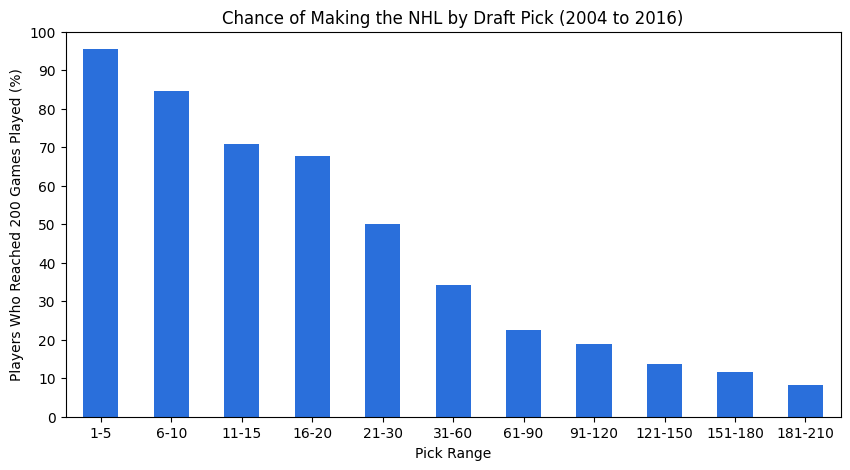

In [18]:
import matplotlib.pyplot as plt

all_drafts.to_csv("nhl_drafts_2004_2016.csv", index=False)

pool = all_drafts[all_drafts["pick"] <= 210].copy()
bins = [0, 5, 10, 15, 20, 30, 60, 90, 120, 150, 180, 210]
labels = ["1-5", "6-10", "11-15", "16-20", "21-30", "31-60",
          "61-90", "91-120", "121-150", "151-180", "181-210"]
pool["Pick Range"] = pd.cut(pool["pick"], bins=bins, labels=labels)

summary = pool.groupby("Pick Range", observed=True).agg(
    Players=("Player", "count"),
    Made=("made_nhl", "sum"),
    Rate=("made_nhl", "mean"),
    AvgGP=("GP", "mean"),
)
summary["Rate"] = (summary["Rate"] * 100).round(1)
summary["AvgGP"] = summary["AvgGP"].round(0).astype(int)
summary.columns = ["Players", "Made the NHL", "Hit Rate (%)", "Average GP"]
display(summary)

ax = summary["Hit Rate (%)"].plot(kind="bar", figsize=(10, 5), color="#2a6fdb")
ax.set_title("Chance of Making the NHL by Draft Pick (2004 to 2016)")
ax.set_xlabel("Pick Range")
ax.set_ylabel("Players Who Reached 200 Games Played (%)")
plt.xticks(rotation=0)
ax.set_ylim(0, 100)
ax.set_yticks(range(0, 101, 10))
plt.show()

,Players Drafted,Made the NHL,Chance of Making the NHL (%),Share of All NHL Players (%)
Round,,,,
Round 1,390,272,69.7,39.0
Round 2,390,133,34.1,19.1
Round 3,390,88,22.6,12.6
Round 4,389,73,18.8,10.5
Round 5,390,54,13.8,7.7
Round 6,390,45,11.5,6.5
Round 7,390,32,8.2,4.6


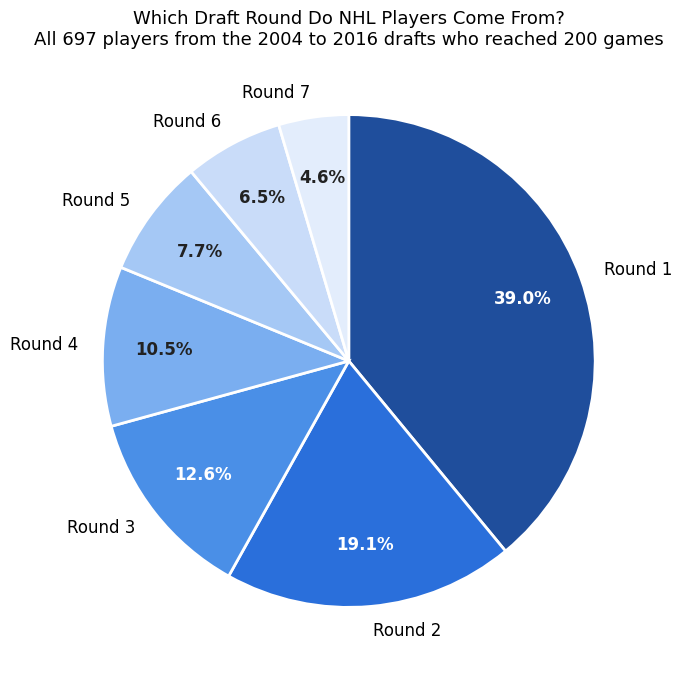

In [19]:
pool = all_drafts[all_drafts["pick"] <= 210].copy()
round_bins = [0, 30, 60, 90, 120, 150, 180, 210]
round_labels = ["Round 1", "Round 2", "Round 3", "Round 4", "Round 5", "Round 6", "Round 7"]
pool["Round"] = pd.cut(pool["pick"], bins=round_bins, labels=round_labels)

by_round = pool.groupby("Round", observed=True).agg(
    Players=("Player", "count"),
    Made=("made_nhl", "sum"),
    Rate=("made_nhl", "mean"),
)
by_round["Chance"] = (by_round["Rate"] * 100).round(1)
by_round["Share"] = (by_round["Made"] / by_round["Made"].sum() * 100).round(1)
by_round = by_round.drop(columns="Rate")
by_round.columns = ["Players Drafted", "Made the NHL", "Chance of Making the NHL (%)", "Share of All NHL Players (%)"]
display(by_round)

total = int(by_round["Made the NHL"].sum())
colors = ["#1f4e9c", "#2a6fdb", "#4a8fe7", "#7aaef0", "#a5c8f5", "#c9dcf9", "#e3edfc"]

fig, ax = plt.subplots(figsize=(8, 8))
wedges, texts, autotexts = ax.pie(
    by_round["Made the NHL"],
    labels=by_round.index,
    autopct="%1.1f%%",
    startangle=90,
    counterclock=False,
    pctdistance=0.75,
    colors=colors,
    wedgeprops={"edgecolor": "white", "linewidth": 2},
    textprops={"fontsize": 12},
)
for i, t in enumerate(autotexts):
    t.set_color("white" if i < 3 else "#222222")
    t.set_fontweight("bold")

ax.set_title(
    "Which Draft Round Do NHL Players Come From?\n"
    f"All {total} players from the 2004 to 2016 drafts who reached 200 games",
    fontsize=13,
)
plt.show()

In [20]:
skaters = all_drafts[all_drafts["Pos"] != "G"].copy()
for c in ["G", "A", "PTS"]:
    skaters[c] = skaters[c].fillna(0).astype(int)
skaters["Points Per Game"] = (skaters["PTS"] / skaters["GP"].where(skaters["GP"] > 0)).round(2)

names = {
    "draft_year": "Draft Year",
    "pick": "Pick",
    "Pos": "Position",
    "last season": "Previous Season / Present",
}
cols = ["Draft Year", "Pick", "Player", "Team", "Position", "GP", "G", "A", "PTS",
        "Points Per Game", "Previous Season / Present"]
fmt = {"Points Per Game": "{:.2f}"}

print("Biggest steals: round 2 to the end of the draft (pick 31+), most career points")
steals = skaters[skaters["pick"] >= 31].sort_values("PTS", ascending=False).head(15)
display(steals.rename(columns=names)[cols].style.hide(axis="index").format(fmt, na_rep="-"))

print("Biggest busts: top 10 picks with the fewest career points")
busts = skaters[skaters["pick"] <= 10].sort_values(["PTS", "GP"]).head(15)
display(busts.rename(columns=names)[cols].style.hide(axis="index").format(fmt, na_rep="-"))

Biggest steals: round 2 to the end of the draft (pick 31+), most career points


Draft Year,Pick,Player,Team,Position,GP,G,A,PTS,Points Per Game,Previous Season / Present
2011,58,Nikita Kucherov,Tampa Bay Lightning,LW,892,405,737,1142,1.28,Present
2006,71,Brad Marchand,Boston Bruins,LW,1154,452,583,1035,0.90,Present
2007,129,Jamie Benn,Dallas Stars,LW,1266,416,581,997,0.79,Present
2009,33,Ryan O'Reilly,Colorado Avalanche,C,1247,335,578,913,0.73,Present
2005,44,Paul Stastny,Colorado Avalanche,C,1145,293,529,822,0.72,2023
2005,62,Kris Letang,Pittsburgh Penguins,D,1249,178,634,812,0.65,Present
2008,38,Roman Josi,Nashville Predators,D,1044,204,590,794,0.76,Present
2004,63,David Krejci,Boston Bruins,C,1032,231,555,786,0.76,2023
2011,104,John Gaudreau,Calgary Flames,LW,763,243,500,743,0.97,2024
2015,35,Sebastian Aho,Carolina Hurricanes,RW,771,318,412,730,0.95,Present


Biggest busts: top 10 picks with the fewest career points


Draft Year,Pick,Player,Team,Position,GP,G,A,PTS,Points Per Game,Previous Season / Present
2009,8,Scott Glennie,Dallas Stars,RW,1,0,0,0,0.00,2012
2005,10,Luc Bourdon,Vancouver Canucks,D,36,2,0,2,0.06,2008
2012,4,Griffin Reinhart,New York Islanders,D,37,0,2,2,0.05,2016
2004,8,Alexandre Picard,Columbus Blue Jackets,LW,67,0,2,2,0.03,2010
2016,5,Olli Juolevi,Vancouver Canucks,D,41,2,1,3,0.07,2022
2007,8,Zach Hamill,Boston Bruins,C,20,0,4,4,0.20,2012
2004,10,Boris Valabik,Atlanta Thrashers,D,80,0,7,7,0.09,2010
2010,10,Dylan McIlrath,New York Rangers,D,109,3,6,9,0.08,Present
2008,6,Nikita Filatov,Columbus Blue Jackets,LW,53,6,8,14,0.26,2012
2014,5,Michael Dal Colle,New York Islanders,LW,112,8,13,21,0.19,2022


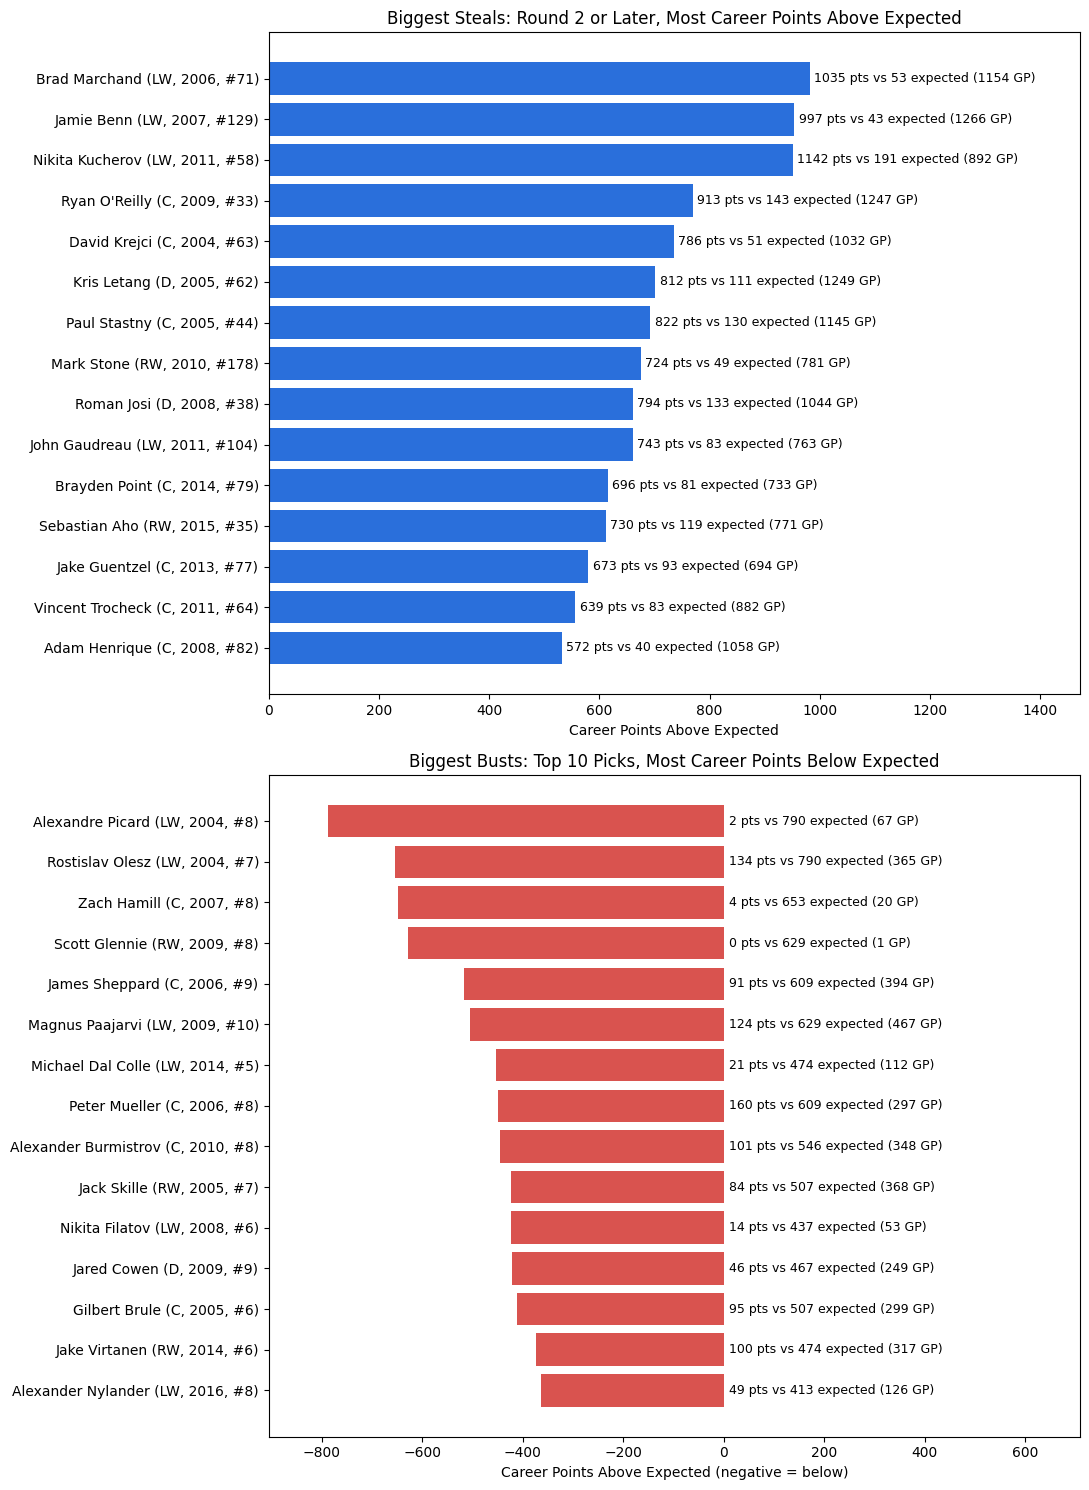

In [21]:
sk = all_drafts[all_drafts["Pos"] != "G"].copy()
for c in ["GP", "G", "A", "PTS"]:
    sk[c] = sk[c].fillna(0)

sk["Pos Group"] = sk["Pos"].apply(lambda p: "D" if p == "D" else "F")
sk["Pick Group"] = pd.cut(
    sk["pick"],
    bins=[0, 10, 30, 60, 120, 300],
    labels=["1-10", "11-30", "31-60", "61-120", "121+"],
)
sk["Expected PTS"] = sk.groupby(
    ["draft_year", "Pick Group", "Pos Group"], observed=True
)["PTS"].transform("mean")
sk["Over"] = sk["PTS"] - sk["Expected PTS"]

steals = sk[sk["pick"] >= 31].sort_values("Over", ascending=False).head(15).copy()
busts = sk[sk["pick"] <= 10].sort_values("Over").head(15).copy()

def make_label(r):
    return f"{r['Player']} ({r['Pos']}, {int(r['draft_year'])}, #{int(r['pick'])})"

steals["Label"] = steals.apply(make_label, axis=1)
busts["Label"] = busts.apply(make_label, axis=1)

fig, axes = plt.subplots(2, 1, figsize=(11, 15))

ax = axes[0]
ax.barh(steals["Label"], steals["Over"], color="#2a6fdb")
ax.invert_yaxis()
ax.set_title("Biggest Steals: Round 2 or Later, Most Career Points Above Expected")
ax.set_xlabel("Career Points Above Expected")
ax.set_xlim(0, steals["Over"].max() * 1.5)
for y, (o, p, e, gp) in enumerate(zip(steals["Over"], steals["PTS"], steals["Expected PTS"], steals["GP"])):
    ax.text(o + 8, y, f"{int(p)} pts vs {int(round(e))} expected ({int(gp)} GP)", va="center", fontsize=9)

ax = axes[1]
ax.barh(busts["Label"], busts["Over"], color="#d9534f")
ax.invert_yaxis()
ax.set_title("Biggest Busts: Top 10 Picks, Most Career Points Below Expected")
ax.set_xlabel("Career Points Above Expected (negative = below)")
low = busts["Over"].min()
ax.set_xlim(low * 1.15, abs(low) * 0.9)
for y, (o, p, e, gp) in enumerate(zip(busts["Over"], busts["PTS"], busts["Expected PTS"], busts["GP"])):
    ax.text(10, y, f"{int(p)} pts vs {int(round(e))} expected ({int(gp)} GP)", va="center", fontsize=9)

plt.tight_layout()
plt.show()

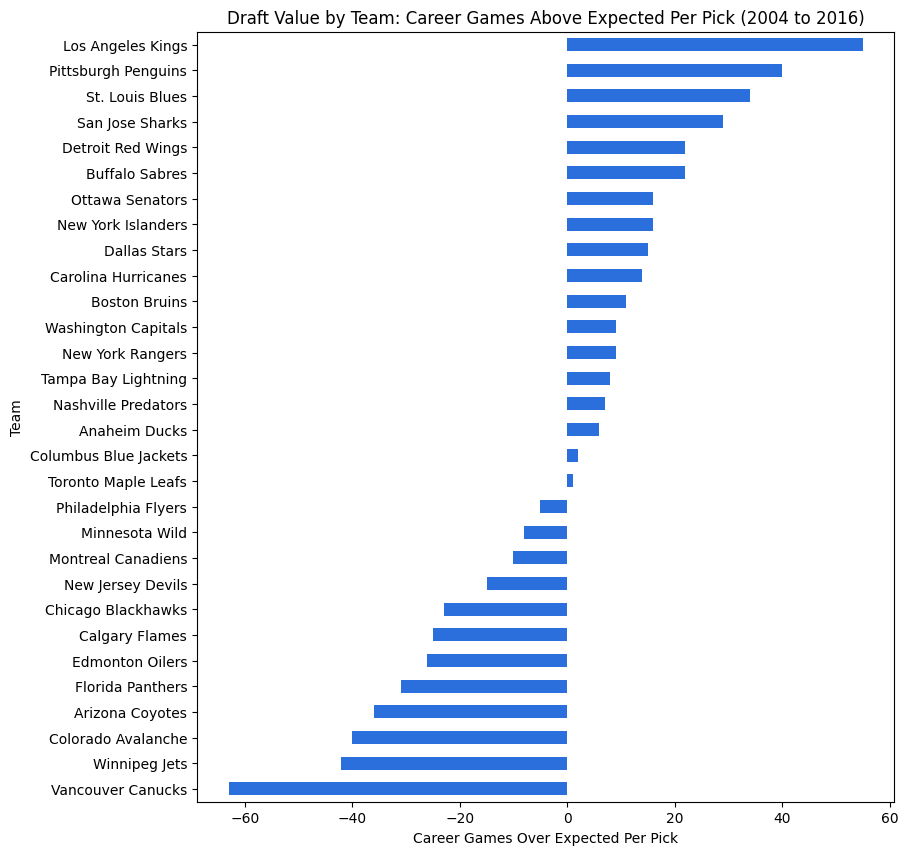

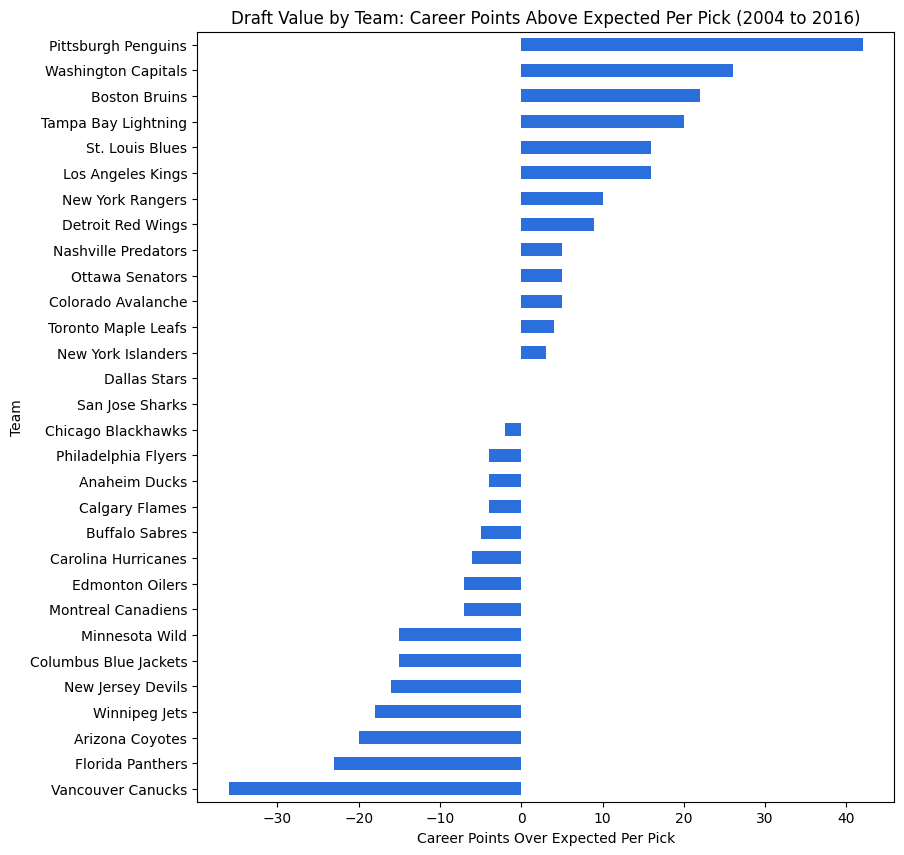

In [22]:
skaters = all_drafts[(all_drafts["pick"] <= 210) & (all_drafts["Pos"] != "G")].copy()
for c in ["GP", "PTS"]:
    skaters[c] = skaters[c].fillna(0)

cohort_bins = [0, 10, 30, 60, 120, 210]
cohort_labels = ["1-10", "11-30", "31-60", "61-120", "121-210"]
skaters["Pick Group"] = pd.cut(skaters["pick"], bins=cohort_bins, labels=cohort_labels)

skaters["Team"] = skaters["Team"].replace({
    "Atlanta Thrashers": "Winnipeg Jets",
    "Phoenix Coyotes": "Arizona Coyotes",
})

results = {}
for stat, name in [("GP", "Career Games"), ("PTS", "Career Points")]:
    expected = skaters.groupby(["draft_year", "Pick Group"], observed=True)[stat].transform("mean")
    skaters["Over"] = skaters[stat] - expected
    results[name] = skaters.groupby("Team")["Over"].mean().round(0).astype(int).sort_values(ascending=False)

for name, series in results.items():
    ax = series.plot(kind="barh", figsize=(9, 10), color="#2a6fdb")
    ax.invert_yaxis()
    ax.set_title(f"Draft Value by Team: {name} Above Expected Per Pick (2004 to 2016)")
    ax.set_xlabel(f"{name} Over Expected Per Pick")
    plt.show()

Draft Years,2004 to 2010,2011 to 2016
Pick Range,,
1-5,100.0,90.0
6-10,77.1,93.3
11-15,65.7,76.7
16-20,57.1,80.0
21-30,47.1,53.3
31-60,28.6,40.6
61-90,20.5,25.0
91-120,20.1,17.2
121-150,12.9,15.0


Draft Years
2004 to 2010    23.9
2011 to 2016    27.5
Name: made_nhl, dtype: float64


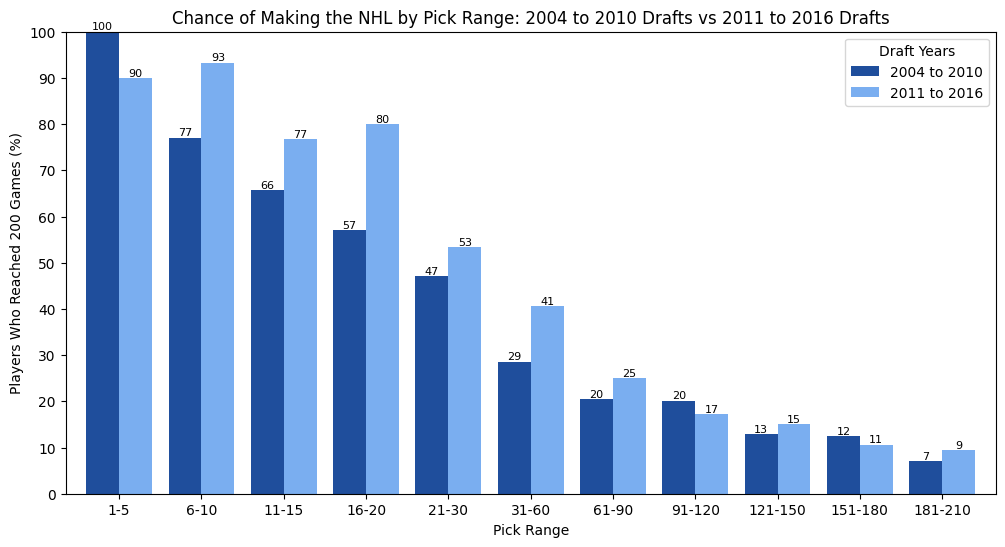

In [23]:
pool = all_drafts[all_drafts["pick"] <= 210].copy()
bins = [0, 5, 10, 15, 20, 30, 60, 90, 120, 150, 180, 210]
labels = ["1-5", "6-10", "11-15", "16-20", "21-30", "31-60",
          "61-90", "91-120", "121-150", "151-180", "181-210"]
pool["Pick Range"] = pd.cut(pool["pick"], bins=bins, labels=labels)
pool["Draft Years"] = pool["draft_year"].apply(
    lambda y: "2004 to 2010" if y <= 2010 else "2011 to 2016"
)

rates = (pool.groupby(["Pick Range", "Draft Years"], observed=True)["made_nhl"].mean().unstack() * 100).round(1)
display(rates)
print((pool.groupby("Draft Years")["made_nhl"].mean() * 100).round(1))

ax = rates.plot(kind="bar", figsize=(12, 6), color=["#1f4e9c", "#7aaef0"], width=0.8)
for c in ax.containers:
    ax.bar_label(c, fmt="%.0f", fontsize=8)
ax.set_title("Chance of Making the NHL by Pick Range: 2004 to 2010 Drafts vs 2011 to 2016 Drafts")
ax.set_xlabel("Pick Range")
ax.set_ylabel("Players Who Reached 200 Games (%)")
ax.set_ylim(0, 100)
ax.set_yticks(range(0, 101, 10))
plt.xticks(rotation=0)
plt.show()